# Wakely: detecção de sonolência ao volante

**Grupo:** Antônio Dias, Rafael Capozzielli e Luana Freitas · Insper AI, entrega final 2026.2

> O Wakely é um **protótipo acadêmico**. Não é um dispositivo de segurança e **nunca deve ser testado dirigindo**.

Uma webcam olha o rosto do motorista e o sistema avisa quando o olho fica fechado por tempo demais. Este notebook é a primeira versão, para a apresentação intermediária de 12/11. Ele tem a linha de base sem deep learning (MediaPipe + EAR + regras) e a CNN de olho com fine-tuning, testadas em vídeos reais de motoristas à noite, compara a MobileNetV3 com a YOLO26n classificadora, testa um agente de reinforcement learning para decidir o alerta e testa modelos temporais (GRU, TCN, transformer e MIL) que estimam a sonolência a partir dos sinais do rosto, com validação externa no DROZY.

### Sumário

| Seção | Conteúdo |
|---|---|
| 1 | Configuração e dados (MRL Eye e FL3D) |
| 2 | Linha de base: MediaPipe + EAR + regras do Euro NCAP |
| 3 | CNN de olho: MobileNetV3 com fine-tuning, separada por pessoa |
| 4 | CNN no vídeo: a CNN no lugar do EAR, na mesma regra |
| 5 | Comparação de classificadores: MobileNetV3 x YOLO26n-cls |
| 6 | Falsos alarmes: filtro de bocejo, piscadas e fusão do EAR com o YOLO |
| 7 | Agente de RL no alerta: quando e com que intensidade avisar |
| 8 | Modelo temporal no UTA-RLDD: PERCLOS, GRU e TCN (8.1 a 8.4), cabeça, expressões e transformer (8.5), análise de erros (8.6) e MIL com validação externa no DROZY (8.7) |
| 9 | Resumo e próximos passos |
| 10 | Feedback da entrega intermediária e plano de ação |

### Como rodar

1. `uv sync` na raiz do repositório (Python 3.12, PyTorch com CUDA, MediaPipe).
2. Rodar o notebook do início. A seção 1 baixa os dados para `data/`, que fica fora do git porque tem rostos de pessoas. A seção 8 baixa 1,2 GB do UTA-RLDD e extrai os sinais em cerca de 2,5 h na CPU. A seção 8.5 refaz a extração com pose da cabeça e blendshapes, em cerca de 2 h num processo só (com o cache em `data/cache/rldd_rico/`, não precisa). A seção 8.7 baixa o DROZY (2,5 GB, licença só para pesquisa) e extrai os sinais em cerca de 1 h.
3. Os resultados pesados (landmarks do vídeo e pesos da CNN) ficam em cache em `data/`. Na segunda execução eles são carregados em vez de recalculados.

### O pipeline

![Pipeline recomendado](docs/pipeline_recomendado.png)

A escolha vem da pesquisa do grupo (`docs/pesquisa_wakely.md`). O MediaPipe acha o rosto e os olhos, a CNN dá P(olho fechado) em cada frame e uma regra transforma a sequência em alerta. A regra de alerta é a de tempo de olho fechado do Euro NCAP. A GRU e a TCN são testadas à parte, na seção 8, para estimar a sonolência em janelas de 1 minuto, e não superam o PERCLOS.

## 1. Configuração e dados

In [1]:
import copy
import json
import os
import re
import time
import random
import urllib.request
import zipfile
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             precision_recall_fscore_support, confusion_matrix,
                             ConfusionMatrixDisplay)

import mediapipe as mp
from mediapipe.tasks.python import vision, BaseOptions

# reprodutibilidade
SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", DEVICE,
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("MediaPipe", mp.__version__)

DADOS = Path("data")
CACHE = DADOS / "cache"
PASTA_MODELOS = DADOS / "modelos"
for p in (DADOS, CACHE, PASTA_MODELOS):
    p.mkdir(parents=True, exist_ok=True)

FPS = 25      # NITYMED/FL3D: vídeos a 25 quadros por segundo
TAM = 64      # lado do recorte de olho que entra na CNN (pixels)

PyTorch 2.11.0+cu128 | dispositivo: cuda NVIDIA GeForce RTX 3050 6GB Laptop GPU
MediaPipe 1.2.2


### 1.1 Download dos dados

| Base | Para quê | Tamanho | Origem |
|---|---|---|---|
| [MRL Eye](https://mrl.cs.vsb.cz/eyedataset.html) | Treinar a CNN de olho (aberto/fechado) | 342 MB, 84.898 imagens, 37 pessoas | Site oficial |
| [FL3D](https://www.kaggle.com/datasets/matjazmuc/frame-level-driver-drowsiness-detection-fl3d) | Testar o sistema em vídeo, com rótulo por frame | 645 MB, 53.331 frames, 44 vídeos | Kaggle (público) |
| [NITYMED](https://www.kaggle.com/datasets/nikospetrellis/nitymed) | Vídeos originais do FL3D, para testar os frames que ele removeu (seção 6) | 697 MB, 44 dos vídeos usados | Kaggle (público) |
| [Face Landmarker](https://developers.google.com/edge/mediapipe/solutions/vision/face_landmarker) | Achar rosto e olhos | 3,8 MB | Google (MediaPipe) |

O download só acontece se a pasta ainda não existir.

In [2]:
URL_MRL = "http://mrl.cs.vsb.cz/data/eyedataset/mrlEyes_2018_01.zip"
URL_MEDIAPIPE = ("https://storage.googleapis.com/mediapipe-models/face_landmarker/"
                 "face_landmarker/float16/1/face_landmarker.task")

PASTA_MRL = DADOS / "mrl" / "mrlEyes_2018_01"
ARQ_MEDIAPIPE = PASTA_MODELOS / "face_landmarker.task"
os.environ["KAGGLEHUB_CACHE"] = str(DADOS / "kagglehub")   # antes de importar o kagglehub
PASTA_FL3D = (DADOS / "kagglehub/datasets/matjazmuc/frame-level-driver-drowsiness-detection-fl3d"
              / "versions/1/classification_frames")

if not ARQ_MEDIAPIPE.exists():
    urllib.request.urlretrieve(URL_MEDIAPIPE, ARQ_MEDIAPIPE)

if not PASTA_MRL.exists():
    zip_mrl = DADOS / "mrl" / "mrlEyes_2018_01.zip"
    zip_mrl.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL_MRL, zip_mrl)
    with zipfile.ZipFile(zip_mrl) as z:
        z.extractall(zip_mrl.parent)
    zip_mrl.unlink()

if not PASTA_FL3D.exists():
    import kagglehub
    kagglehub.dataset_download("matjazmuc/frame-level-driver-drowsiness-detection-fl3d")

print("MRL:", PASTA_MRL.exists(), "| FL3D:", PASTA_FL3D.exists(), "| MediaPipe:", ARQ_MEDIAPIPE.exists())

MRL: True | FL3D: True | MediaPipe: True


### 1.2 MRL Eye

Cada imagem é o recorte de um olho em infravermelho, e o nome do arquivo traz os rótulos: `s0001_00001_0_0_0_0_0_01.png` = pessoa, número da imagem, gênero, óculos, **estado do olho (0 fechado, 1 aberto)**, reflexo, luz e sensor.

84,898 imagens de 37 pessoas
olho fechado: 49.4% | com óculos: 28.3% | reflexo grande: 15.0% | luz ruim: 63.2%
imagens por pessoa: de 382 a 10257 (mediana 1114)


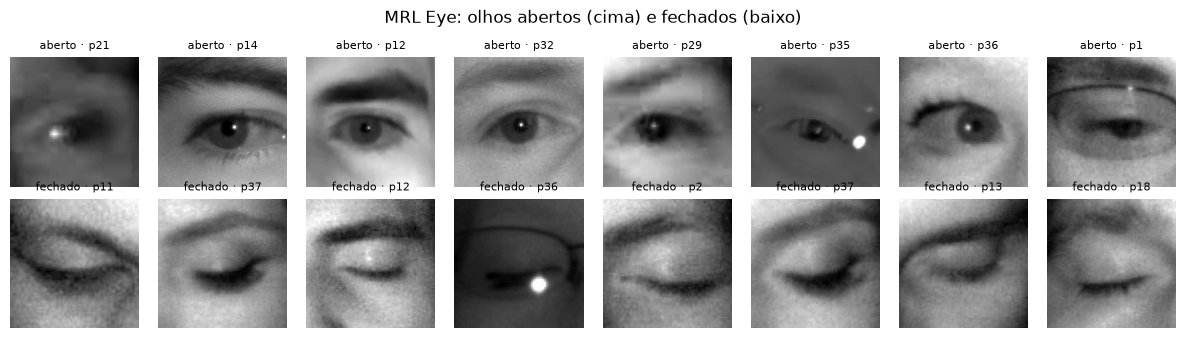

In [3]:
CAMPOS = ["pessoa", "imagem", "genero", "oculos", "aberto", "reflexo", "luz", "sensor"]

linhas = []
for arq in sorted(PASTA_MRL.glob("s*/*.png")):
    partes = arq.stem.split("_")
    linhas.append([arq] + [int(partes[0][1:])] + [int(x) for x in partes[1:]])
mrl = pd.DataFrame(linhas, columns=["arquivo"] + CAMPOS)
mrl["fechado"] = 1 - mrl["aberto"]

print(f"{len(mrl):,} imagens de {mrl.pessoa.nunique()} pessoas")
print(f"olho fechado: {mrl.fechado.mean():.1%} | com óculos: {mrl.oculos.mean():.1%} | "
      f"reflexo grande: {(mrl.reflexo == 2).mean():.1%} | luz ruim: {(mrl.luz == 0).mean():.1%}")

por_pessoa = mrl.groupby("pessoa").agg(imagens=("fechado", "size"), fechado=("fechado", "mean"))
print(f"imagens por pessoa: de {por_pessoa.imagens.min()} a {por_pessoa.imagens.max()} "
      f"(mediana {por_pessoa.imagens.median():.0f})")

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
amostra = pd.concat([mrl[mrl.fechado == c].sample(8, random_state=SEMENTE) for c in (0, 1)])
for ax, (_, r) in zip(axes.flat, amostra.iterrows()):
    ax.imshow(Image.open(r.arquivo), cmap="gray")
    ax.set_title(("fechado" if r.fechado else "aberto") + f" · p{r.pessoa}", fontsize=8)
    ax.axis("off")
plt.suptitle("MRL Eye: olhos abertos (cima) e fechados (baixo)")
plt.tight_layout(); plt.show()

### 1.3 FL3D

O FL3D é feito de 44 vídeos do NITYMED, gravados em carros reais à noite, com o rosto já recortado e um rótulo em cada frame: `alert`, `microsleep` ou `yawning`. Duas observações sobre o FL3D mudam a avaliação:

- **As piscadas foram removidas.** Os frames de piscada não estão na base, então os falsos alarmes medidos aqui são otimistas.
- **Separação por pessoa é só parcial:** usamos os 5 vídeos de validação/teste como **teste** e os outros 39 como **calibração** (onde os limiares são escolhidos). Segundo a página do FL3D, esses 5 têm 5 motoristas, dos quais 3 são inéditos e 2 também aparecem no treino dos autores, sem indicar quais. A CNN não é afetada, porque nada do FL3D a treina. O efeito fica nos limiares, que podem ter sido escolhidos com motoristas que reaparecem no teste.

In [4]:
def numero_frame(nome):
    return int(re.findall(r"\d+", nome)[0])

linhas = []
for pasta in sorted(p for p in PASTA_FL3D.iterdir() if p.is_dir()):
    anot = json.load(open(pasta / "annotations_final.json"))
    for nome, info in anot.items():
        if info["driver_state"] is not None:          # 2 frames sem rótulo
            linhas.append((pasta.name, numero_frame(nome), nome, info["driver_state"]))
fl3d = pd.DataFrame(linhas, columns=["video", "frame", "nome", "estado"]).sort_values(["video", "frame"])
fl3d = fl3d.reset_index(drop=True)

videos_teste = sorted({k.split("/")[2] for k in json.load(open(PASTA_FL3D / "annotations_holdout.json"))})
fl3d["grupo"] = np.where(fl3d.video.isin(videos_teste), "teste", "calibração")

resumo = fl3d.groupby(["grupo", "video"]).estado.value_counts().unstack(fill_value=0)
resumo["segundos"] = (fl3d.groupby(["grupo", "video"]).frame.agg(lambda f: f.max() - f.min() + 1) / FPS).round(0)
print(f"{len(fl3d):,} frames em {fl3d.video.nunique()} vídeos")
print(fl3d.groupby("grupo").estado.value_counts().unstack())
print("\nvídeos de teste:")
print(resumo.loc["teste"])
# o notebook não mostra os rostos do FL3D: o repositório não guarda imagens de pessoas

53,329 frames em 44 vídeos
estado      alert  microsleep  yawning
grupo                                 
calibração  35482        8074     4769
teste        3484         795      725

vídeos de teste:
estado        alert  microsleep  yawning  segundos
video                                             
P1042762_720   2052         632       42     124.0
P1042780_720    289           0      204      40.0
P1043081_720    293           0      298      24.0
P1043086_720    327           0      181      25.0
P1043106_720    523         163        0     105.0


## 2. Linha de base: MediaPipe + EAR + regras

Antes de treinar qualquer rede, a linha de base mede o olho com geometria. O MediaPipe devolve 478 pontos do rosto, e com 6 pontos de cada olho dá para calcular o **EAR (Eye Aspect Ratio)**:

$$\text{EAR} = \frac{\lVert p_2 - p_6 \rVert + \lVert p_3 - p_5 \rVert}{2\,\lVert p_1 - p_4 \rVert}$$

O EAR é a abertura vertical dividida pela largura do olho. Ele fica perto de 0,25–0,30 com o olho aberto e cai perto de zero quando o olho fecha.

Na mesma passada pelo vídeo, guardamos o recorte de cada olho (64×64, em cinza), que a CNN vai usar na seção 4. O cálculo leva de 10 a 30 minutos na CPU e fica em cache.

In [5]:
# pontos do MediaPipe Face Mesh: p1..p6 do EAR e o contorno de cada olho
EAR_E = [33, 160, 158, 133, 153, 144]
EAR_D = [362, 385, 387, 263, 373, 380]
CONTORNO_E = [33, 7, 163, 144, 145, 153, 154, 155, 133, 173, 157, 158, 159, 160, 161, 246]
CONTORNO_D = [362, 382, 381, 380, 374, 373, 390, 249, 263, 466, 388, 387, 386, 385, 384, 398]
# lábios internos: três pares verticais e os dois cantos da boca
BOCA_V = [(81, 178), (13, 14), (311, 402)]
BOCA_H = (78, 308)


def criar_detector():
    # o MediaPipe não abre caminhos com acento no Windows, então o modelo vai por memória
    opcoes = vision.FaceLandmarkerOptions(
        base_options=BaseOptions(model_asset_buffer=ARQ_MEDIAPIPE.read_bytes()),
        running_mode=vision.RunningMode.IMAGE, num_faces=1)
    return vision.FaceLandmarker.create_from_options(opcoes)


def pontos_do_rosto(detector, rgb):
    # devolve os 478 pontos em pixels, ou None se não achar rosto
    r = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb)))
    if not r.face_landmarks:
        return None
    h, w = rgb.shape[:2]
    return np.array([[q.x * w, q.y * h] for q in r.face_landmarks[0]])


def ear(p, idx):
    p1, p2, p3, p4, p5, p6 = (p[i] for i in idx)
    return (np.linalg.norm(p2 - p6) + np.linalg.norm(p3 - p5)) / (2 * np.linalg.norm(p1 - p4))


def recortar_olho(cinza, contorno, fator=1.4):
    # quadrado centrado no olho, com lado = 1,4 x a largura do olho (parecido com o MRL)
    cx, cy = contorno.mean(axis=0)
    lado = fator * (contorno[:, 0].max() - contorno[:, 0].min())
    caixa = (int(cx - lado / 2), int(cy - lado / 2), int(cx + lado / 2), int(cy + lado / 2))
    return np.asarray(Image.fromarray(cinza).crop(caixa).resize((TAM, TAM), Image.BILINEAR))


def abertura_boca(pontos):
    # abertura vertical dos lábios / largura da boca, para um ou vários frames
    v = sum(np.linalg.norm(pontos[..., a, :] - pontos[..., b, :], axis=-1) for a, b in BOCA_V) / len(BOCA_V)
    return v / np.linalg.norm(pontos[..., BOCA_H[0], :] - pontos[..., BOCA_H[1], :], axis=-1)


def extrair_fl3d():
    arq_csv, arq_olhos, arq_pontos = CACHE / "fl3d_ear.csv", CACHE / "fl3d_olhos.npy", CACHE / "fl3d_pontos.npy"
    if arq_csv.exists() and arq_olhos.exists() and arq_pontos.exists():
        return pd.read_csv(arq_csv), np.load(arq_olhos), np.load(arq_pontos)
    detector = criar_detector()
    ears, olhos = [], np.zeros((len(fl3d), 2, TAM, TAM), np.uint8)
    pontos = np.full((len(fl3d), 478, 2), np.nan, np.float32)
    inicio = time.time()
    for i, r in enumerate(fl3d.itertuples()):
        rgb = np.asarray(Image.open(PASTA_FL3D / r.video / r.nome).convert("RGB"))
        p = pontos_do_rosto(detector, rgb)
        if p is None:
            ears.append((np.nan, np.nan, False))
            continue
        pontos[i] = p[:478]
        cinza = np.asarray(Image.fromarray(rgb).convert("L"))
        olhos[i, 0] = recortar_olho(cinza, p[CONTORNO_E])
        olhos[i, 1] = recortar_olho(cinza, p[CONTORNO_D])
        ears.append((ear(p, EAR_E), ear(p, EAR_D), True))
    print(f"{(time.time() - inicio) / len(fl3d) * 1000:.1f} ms por frame")
    tab = pd.DataFrame(ears, columns=["ear_e", "ear_d", "rosto"])
    tab.to_csv(arq_csv, index=False)
    np.save(arq_olhos, olhos)
    np.save(arq_pontos, pontos)
    return tab, olhos, pontos


tab_ear, olhos_fl3d, pontos_fl3d = extrair_fl3d()
fl3d[["ear_e", "ear_d", "rosto"]] = tab_ear[["ear_e", "ear_d", "rosto"]].values
fl3d["ear"] = fl3d[["ear_e", "ear_d"]].astype(float).mean(axis=1)
fl3d["rosto"] = fl3d["rosto"].astype(bool)
fl3d["boca"] = abertura_boca(pontos_fl3d)
print(f"rosto encontrado em {fl3d.rosto.mean():.2%} dos frames")
print(fl3d.groupby("estado").ear.describe()[["count", "mean", "50%", "std"]].round(3))

rosto encontrado em 98.51% dos frames
              count   mean    50%    std
estado                                  
alert       38368.0  0.303  0.301  0.070
microsleep   8684.0  0.091  0.082  0.047
yawning      5481.0  0.189  0.191  0.073


### 2.1 Calibração por pessoa

O EAR de olho aberto muda de pessoa para pessoa, então um limiar fixo como 0,2 falha. Cada vídeo é calibrado pelo próprio começo: o **EAR de referência é o percentil 75 dos primeiros 30 s**, e o sinal usado é `1 − EAR / referência` (0 = olho como na calibração, 1 = olho fechado). Usamos o percentil 75, e não a mediana, porque alguns vídeos já começam com microssono.

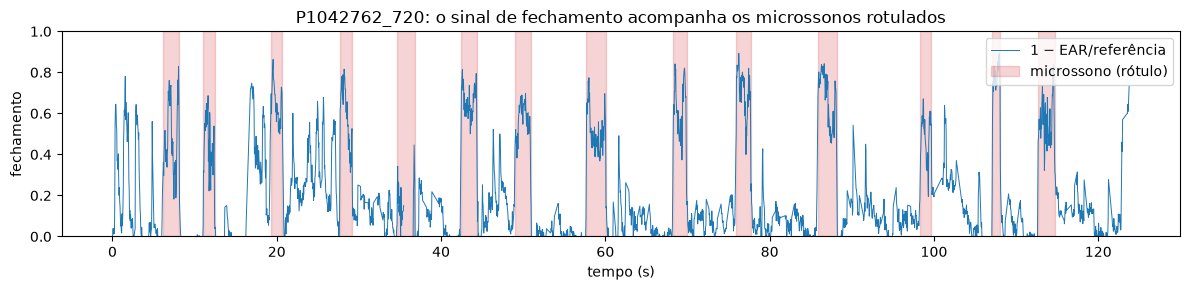

In [6]:
def referencia(d, segundos=30):
    inicio = d.frame.min()
    return d.loc[d.frame < inicio + segundos * FPS, "ear"].quantile(0.75)

ref = fl3d.groupby("video").apply(referencia, include_groups=False)
fl3d["fech_ear"] = (1 - fl3d.ear / fl3d.video.map(ref)).clip(0, 1)

v = "P1042762_720"   # vídeo de teste com microssonos
d = fl3d[fl3d.video == v]
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(d.frame / FPS, d.fech_ear, lw=0.7, color="tab:blue", label="1 − EAR/referência")
ms = d.estado.eq("microsleep").values
ax.fill_between(d.frame / FPS, 0, 1, where=ms, color="tab:red", alpha=0.2, step="mid", label="microssono (rótulo)")
ax.set_xlabel("tempo (s)"); ax.set_ylabel("fechamento"); ax.set_ylim(0, 1); ax.legend(loc="upper right")
ax.set_title(f"{v}: o sinal de fechamento acompanha os microssonos rotulados")
plt.tight_layout(); plt.show()

### 2.2 Olho fechado por frame

Primeiro, a pergunta mais simples: o sinal separa os frames de microssono dos outros? O limiar é escolhido nos vídeos de calibração (maior F1) e aplicado nos de teste. Como `microsleep` é a classe rara (cerca de 17% dos frames), a métrica principal é a **AUC-PR**.

In [7]:
def limiar_f1(y, s):
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p * r / np.maximum(p + r, 1e-9)
    return t[np.argmax(f1[:-1])]


def metricas_frame(d, col, limiar):
    y, s = d.estado.eq("microsleep").values, d[col].values
    p, r, f1, _ = precision_recall_fscore_support(y, s >= limiar, average="binary", zero_division=0)
    return {"AUC-PR": average_precision_score(y, s), "precisão": p, "recall": r, "F1": f1}


calib = fl3d[(fl3d.grupo == "calibração") & fl3d.rosto]
teste = fl3d[(fl3d.grupo == "teste") & fl3d.rosto]
LIMIAR_EAR = limiar_f1(calib.estado.eq("microsleep"), calib.fech_ear)
print(f"limiar escolhido na calibração: fechamento >= {LIMIAR_EAR:.3f} "
      f"(EAR abaixo de {1 - LIMIAR_EAR:.0%} da referência)")
pd.DataFrame({"calibração": metricas_frame(calib, "fech_ear", LIMIAR_EAR),
              "teste": metricas_frame(teste, "fech_ear", LIMIAR_EAR)}).T.round(3)

limiar escolhido na calibração: fechamento >= 0.525 (EAR abaixo de 47% da referência)


,AUC-PR,precisão,recall,F1
calibração,0.834,0.774,0.789,0.782
teste,0.658,0.637,0.694,0.664


### 2.3 Do frame ao alerta: regras do Euro NCAP

Um frame com o olho fechado pode ser só uma piscada. O alerta só dispara quando o olho fica fechado **por tempo seguido**. Os limiares vêm do protocolo do Euro NCAP (pesquisa, seção Indústria):

| Nível | Olho fechado por | Alerta |
|---|---|---|
| Microssono | 1 a 2 s | som forte |
| Sono | 3 s ou mais | som urgente + "pare em local seguro" |
| Sem resposta | 6 s ou mais | máximo |

Antes de fixar o tempo mínimo, vale olhar quanto duram os microssonos do FL3D. Um **episódio** é um trecho seguido de frames `microsleep`, juntando buracos de até 0,5 s (frames removidos da base).

254 episódios de microssono | duração mediana 1.4 s | 35% com menos de 1 s | 5% com 3 s ou mais

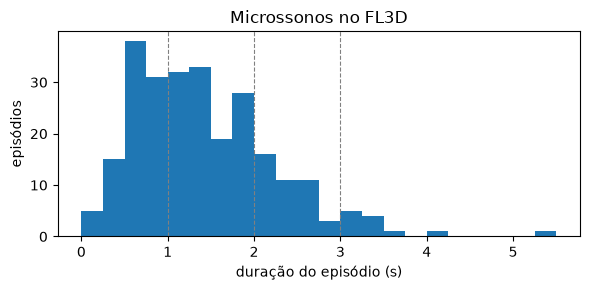

In [8]:
def trechos(mascara):
    # trechos seguidos de True -> lista de (início, fim), fim incluso
    m = np.r_[False, mascara, False].astype(int)
    d = np.diff(m)
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0] - 1))


def unir(lista, buraco):
    # junta trechos separados por até `buraco` frames
    saida = []
    for a, b in lista:
        if saida and a - saida[-1][1] - 1 <= buraco:
            saida[-1] = (saida[-1][0], b)
        else:
            saida.append((a, b))
    return saida


def linha_do_tempo(d):
    # um valor por frame do vídeo, incluindo os frames que a base removeu (NaN)
    tl = pd.DataFrame({"frame": np.arange(d.frame.min(), d.frame.max() + 1)})
    return tl.merge(d, on="frame", how="left")


BURACO_EP = int(0.5 * FPS)
tempo = {v: linha_do_tempo(d) for v, d in fl3d.groupby("video")}
episodios = {v: unir(trechos(tl.estado.eq("microsleep").values), BURACO_EP) for v, tl in tempo.items()}

dur = np.array([(b - a + 1) / FPS for eps in episodios.values() for a, b in eps])
print(f"{len(dur)} episódios de microssono | duração mediana {np.median(dur):.1f} s | "
      f"{(dur < 1).mean():.0%} com menos de 1 s | {(dur >= 3).mean():.0%} com 3 s ou mais")
plt.figure(figsize=(6, 3))
plt.hist(dur, bins=np.arange(0, dur.max() + 0.25, 0.25))
for x in (1, 2, 3):
    plt.axvline(x, color="gray", ls="--", lw=0.8)
plt.xlabel("duração do episódio (s)"); plt.ylabel("episódios"); plt.title("Microssonos no FL3D")
plt.tight_layout(); plt.show()

A regra de alerta:

1. o frame conta como **fechado** quando o sinal passa do limiar da seção 2.2;
2. trechos fechados separados por até 3 frames (0,12 s) viram um só, para um frame ruim não zerar a contagem;
3. o **alerta dispara** quando um trecho fechado chega a **T segundos**, uma vez por trecho.

Um alerta é **acerto** se cai dentro de um episódio (com tolerância de 0,5 s depois do fim) e **falso alarme** se não. As métricas são as da pesquisa: recall de evento, falsos alarmes por hora de direção alerta e atraso. Desde a entrega final, as tabelas trazem também a **precisão por alarme** (acertos / (acertos + falsos alarmes)), o **F1** e o **F2**, que juntam acerto e alarme falso num número só. O F2 dá mais peso ao recall, porque perder um microssono pesa mais que um alarme falso. A definição, o β = 2 e as comparações foram fixados antes de calcular (`docs/protocolo_metricas_f.md`), e o limiar de olho continua escolhido pelo F1. Duas ressalvas: o numerador conta episódios detectados, e não alarmes certos; e a precisão depende de quantos microssonos há. O FL3D tem muitos, então a precisão, o F1 e o F2 servem para comparar sinais nesta base, e não descrevem uma viagem. O T do sistema é fixo: **T = 1 s**, o limite inferior da faixa de microssono do Euro NCAP. Ele não é escolhido no FL3D, porque a base não tem piscadas: sem elas, quase nada pune um T curto, e o melhor F1 tende ao menor valor testado.

A **varredura de T** (0,4 s a 2 s) continua abaixo, só para mostrar a troca entre detectar mais e alarmar mais. Além do recall em todos os episódios, medimos o recall nos episódios de 1 s ou mais, porque T = 1 s não pretende detectar eventos mais curtos. Um alerta dentro de um episódio curto não conta como acerto nem como falso alarme nessa segunda conta.

In [9]:
BURACO_FECH = 3
TOL = int(0.5 * FPS)
T_ALERTA = 1.0   # limite inferior da faixa de microssono do Euro NCAP (1 a 2 s)


def bocejo_ativo(tl, lim, persistencia, margem):
    # só usa frames passados: boca aberta por `persistencia` frames seguidos, e mais `margem` frames depois
    alta = tl["boca"].ge(lim).astype(float)
    firme = alta.rolling(persistencia, min_periods=persistencia).sum().eq(persistencia).astype(float)
    return firme.rolling(margem + 1, min_periods=1).max().gt(0).values


def fechamento(tl, col, limiar, mediana=1, delta=0.0, manter=0, filtro=None):
    # True nos frames fechados. Os padrões reproduzem a regra simples; a seção 4.2 testa os ajustes
    # e a seção 6 testa o filtro de bocejo.
    s = tl[col]
    if manter:      # falha curta do rosto mantém o último valor
        s = s.where(~tl["rosto"].eq(False), s.ffill(limit=manter))
    if mediana > 1:  # só frames passados, para valer também ao vivo
        s = s.rolling(mediana, min_periods=1).median().where(s.notna())
    v = s.values
    if delta == 0:
        fechado = v >= limiar
    else:
        # histerese: fecha ao passar de limiar e continua fechado até cair abaixo de limiar - delta
        alto, baixo = v >= limiar, v >= limiar - delta
        fechado = np.zeros(len(v), bool)
        for a, b in trechos(baixo):
            acima = np.flatnonzero(alto[a:b + 1])
            if len(acima):
                fechado[a + acima[0]:b + 1] = True
    if filtro:      # olho fechado durante bocejo detectado não conta para o alerta
        fechado = fechado & ~bocejo_ativo(tl, **filtro)
    return fechado


def alertas(tl, col, limiar, T, **ajustes):
    fechado = fechamento(tl, col, limiar, **ajustes)
    n = int(round(T * FPS))
    # (frame do alerta, início do trecho, fim do trecho)
    return [(a + n - 1, a, b) for a, b in unir(trechos(fechado), BURACO_FECH) if b - a + 1 >= n]


def avaliar_eventos(videos, col, limiar, T, dur_min=0.0, ajustes=None):
    # dur_min: só episódios com pelo menos essa duração entram no recall. Um alerta
    # dentro de um episódio mais curto não conta como acerto nem como falso alarme.
    n_ep = acertos = falsos = falsos_bocejo = 0
    atrasos, horas_alerta, min_bocejo = [], 0.0, 0.0
    for v in videos:
        tl, eps = tempo[v], episodios[v]
        validos = {i for i, (a, b) in enumerate(eps) if (b - a + 1) / FPS >= dur_min}
        detectado = set()
        for al, ini, fim in alertas(tl, col, limiar, T, **(ajustes or {})):
            dentro = [i for i, (a, b) in enumerate(eps) if a - TOL <= al <= b + TOL]
            if not dentro:
                falsos += 1
                # ligado a bocejo: há frame rotulado como bocejo no trecho ou a até 2 s dele
                falsos_bocejo += tl.estado.iloc[max(ini - 2 * FPS, 0):fim + 2 * FPS + 1].eq("yawning").any()
            for i in dentro:
                if i in validos and i not in detectado:
                    detectado.add(i)
                    atrasos.append(max(al - eps[i][0], 0) / FPS)
        n_ep += len(validos)
        acertos += len(detectado)
        horas_alerta += tl.estado.eq("alert").sum() / FPS / 3600
        min_bocejo += tl.estado.eq("yawning").sum() / FPS / 60
    return {"T (s)": T, "episódios": n_ep, "acertos": acertos, "recall de evento": acertos / max(n_ep, 1),
            "falsos alarmes": falsos, "falsos em bocejo": falsos_bocejo, "falsos fora de bocejo": falsos - falsos_bocejo,
            "fora de bocejo/hora em alerta": (falsos - falsos_bocejo) / max(horas_alerta, 1e-9),
            "em bocejo/min de bocejo": falsos_bocejo / max(min_bocejo, 1e-9),
            "atraso mediano (s)": np.median(atrasos) if atrasos else np.nan,
            "horas alerta": horas_alerta, "min bocejo": min_bocejo}


def f_beta(acertos, n_ep, falsos, beta):
    # F_beta de evento: recall nos episódios e precisão por alarme = acertos / (acertos + falsos).
    # O numerador conta episódios detectados, não alarmes certos (docs/protocolo_metricas_f.md).
    # Aceita números ou vetores (bootstrap).
    acertos, n_ep, falsos = (np.asarray(x, dtype=float) for x in (acertos, n_ep, falsos))
    recall = acertos / np.maximum(n_ep, 1)
    precisao = acertos / np.maximum(acertos + falsos, 1)
    b2 = beta ** 2
    f = (1 + b2) * precisao * recall / np.maximum(b2 * precisao + recall, 1e-9)
    return f if f.ndim else float(f)


def metricas_f(acertos, n_ep, falsos):
    # precisão por alarme, F1 e F2 (beta = 2: perder um microssono pesa mais que um alarme falso)
    return {"precisão por alarme": acertos / max(acertos + falsos, 1),
            "F1": f_beta(acertos, n_ep, falsos, 1), "F2": f_beta(acertos, n_ep, falsos, 2)}


def varrer_T(videos, col, limiar, Ts=(0.4, 0.6, 0.8, 1.0, 1.2, 1.5, 2.0)):
    # só informa o efeito de cada T: o T do sistema é T_ALERTA, que não sai desta tabela
    tab = pd.DataFrame([avaliar_eventos(videos, col, limiar, T) for T in Ts])
    # F1 de evento: recall de evento x fração dos alertas que acertam
    precisao = tab["acertos"] / np.maximum(tab["acertos"] + tab["falsos alarmes"], 1)
    tab["F1 evento"] = np.where(tab["acertos"] > 0,
                                2 * tab["recall de evento"] * precisao
                                / np.maximum(tab["recall de evento"] + precisao, 1e-9), 0.0)
    tab["F2 evento"] = f_beta(tab["acertos"], tab["episódios"], tab["falsos alarmes"], 2)
    assert np.allclose(tab["F1 evento"], f_beta(tab["acertos"], tab["episódios"], tab["falsos alarmes"], 1))
    return tab


videos_calib = sorted(fl3d.loc[fl3d.grupo == "calibração", "video"].unique())
COLUNAS_T = ["T (s)", "acertos", "episódios", "recall de evento", "falsos alarmes", "F1 evento", "F2 evento"]
print("Varredura de T com o EAR, na calibração:")
display(varrer_T(videos_calib, "fech_ear", LIMIAR_EAR)[COLUNAS_T].round(3))
print("Varredura de T com o EAR, no teste:")
display(varrer_T(videos_teste, "fech_ear", LIMIAR_EAR)[COLUNAS_T].round(3))


Varredura de T com o EAR, na calibração:

,T (s),acertos,episódios,recall de evento,falsos alarmes,F1 evento,F2 evento
0,0.4,173,228,0.759,56,0.757,0.758
1,0.6,155,228,0.680,37,0.738,0.702
2,0.8,130,228,0.570,27,0.675,0.608
3,1.0,114,228,0.500,22,0.626,0.544
4,1.2,96,228,0.421,17,0.563,0.468
5,1.5,70,228,0.307,11,0.453,0.352
6,2.0,35,228,0.154,5,0.261,0.184


Varredura de T com o EAR, no teste:


,T (s),acertos,episódios,recall de evento,falsos alarmes,F1 evento,F2 evento
0,0.4,22,26,0.846,6,0.815,0.833
1,0.6,14,26,0.538,3,0.651,0.579
2,0.8,10,26,0.385,3,0.513,0.427
3,1.0,7,26,0.269,3,0.389,0.307
4,1.2,5,26,0.192,3,0.294,0.223
5,1.5,3,26,0.115,3,0.188,0.136
6,2.0,0,26,0.000,3,0.000,0.000


In [10]:
res_ear = avaliar_eventos(videos_teste, "fech_ear", LIMIAR_EAR, T_ALERTA)
res_ear_longos = avaliar_eventos(videos_teste, "fech_ear", LIMIAR_EAR, T_ALERTA, dur_min=T_ALERTA)
pd.DataFrame({nome: {**r, **metricas_f(r["acertos"], r["episódios"], r["falsos alarmes"])} for nome, r in
              [("EAR, T = 1 s, todos os episódios", res_ear),
               ("EAR, T = 1 s, episódios de 1 s ou mais", res_ear_longos)]}).T.round(3)


,T (s),episódios,acertos,recall de evento,falsos alarmes,falsos em bocejo,falsos fora de bocejo,fora de bocejo/hora em alerta,em bocejo/min de bocejo,atraso mediano (s),horas alerta,min bocejo,precisão por alarme,F1,F2
"EAR, T = 1 s, todos os episódios",1.0,26.0,7.0,0.269,3.0,3.0,0.0,0.0,6.207,1.0,0.039,0.483,0.7,0.389,0.307
"EAR, T = 1 s, episódios de 1 s ou mais",1.0,14.0,7.0,0.500,3.0,3.0,0.0,0.0,6.207,1.0,0.039,0.483,0.7,0.583,0.530


### Observações da linha de base

- **O MediaPipe funciona bem nesses vídeos:** acha o rosto em 98,5% dos frames, a 10 a 24 ms por frame na CPU, contando a leitura da imagem. O tempo maior é da primeira leitura dos arquivos.
- **O EAR separa bem os estados:** a mediana é 0,30 em alerta, 0,08 em microssono e 0,19 em bocejo. O bocejo aperta o olho, e por isso é a principal fonte de confusão.
- **Por frame, o teste cai em relação à calibração** (AUC-PR de 0,83 para 0,66). Parte dos motoristas do teste é nova, então o limiar pode servir menos neles, mas o teste é pequeno e não dá para separar as causas.
- **Com T = 1 s, o EAR acha 7 de 26 episódios no teste, com 3 falsos alarmes.** Só 14 dos 26 duram 1 s ou mais, e neles o recall é de 7 de 14. Na calibração, são 114 de 228 episódios, com 22 falsos alarmes.
- **T = 0,4 s acharia 22 de 26, mas esse número é otimista.** O FL3D tirou as piscadas, e uma piscada longa (0,3 a 0,4 s) dispararia o alerta. Além disso, 0,4 s fica abaixo do mínimo de 1 s das definições de microssono da pesquisa.
- **O rótulo do FL3D é mais amplo que a regra:** 35% dos episódios da base duram menos de 1 s, e só 5% chegam a 3 s. O recall em todos os episódios cobra eventos que T = 1 s não pretende detectar.
- **Os falsos alarmes por hora não são confiáveis aqui:** o teste tem só 2,3 minutos de direção em alerta. Os 3 falsos alarmes do EAR aqui estão ligados a bocejos, e a seção 6 os analisa.

### 2.4 Os três níveis do alerta

A mesma lógica dá os três níveis do Euro NCAP. Cada trecho fechado recebe o nível mais alto que alcança. No FL3D quase não há trechos de 3 s ou mais, então os níveis "sono" e "sem resposta" ficam implementados mas pouco testados aqui. Eles serão testados na demo com a webcam, com sono encenado.

In [11]:
NIVEIS = [(6.0, "sem resposta"), (3.0, "sono"), (1.0, "microssono")]


def nivel(duracao_s):
    for minimo, nome in NIVEIS:
        if duracao_s >= minimo:
            return nome
    return None


contagem = {}
for v in fl3d.video.unique():
    fechado = (tempo[v]["fech_ear"] >= LIMIAR_EAR).fillna(False).values
    for a, b in unir(trechos(fechado), BURACO_FECH):
        n = nivel((b - a + 1) / FPS)
        if n:
            contagem[n] = contagem.get(n, 0) + 1
print("trechos fechados por nível, nos 44 vídeos:", contagem)

trechos fechados por nível, nos 44 vídeos: {'microssono': 140, 'sono': 8}


## 3. CNN de olho: MobileNetV3 com fine-tuning

O EAR depende de 6 pontos e erra quando o MediaPipe erra a pálpebra (óculos, reflexo, cabeça de lado). A CNN olha o recorte inteiro do olho e devolve P(olho fechado).

- **Modelo:** MobileNetV3-Small pré-treinada no ImageNet, com a última camada trocada por 1 saída. É pequena (cerca de 1,5 M de parâmetros) e roda em tempo real na CPU.
- **Dados:** MRL Eye, em cinza, 64×64, repetido nos 3 canais.
- **Separação por pessoa:** as 37 pessoas são divididas em treino, validação e teste **antes** de qualquer coisa, então nenhum rosto do teste aparece no treino.

In [12]:
def carregar_mrl():
    arq = CACHE / f"mrl_{TAM}.npy"
    if arq.exists():
        return np.load(arq)
    x = np.stack([np.asarray(Image.open(a).convert("L").resize((TAM, TAM), Image.BILINEAR))
                  for a in mrl.arquivo])
    np.save(arq, x)
    return x


x_mrl = carregar_mrl()
y_mrl = mrl.fechado.values.astype(np.float32)

# 1º corte: teste (~20% das pessoas); 2º corte: validação (~15% do resto)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMENTE)
idx_resto, idx_te = next(gss.split(x_mrl, y_mrl, groups=mrl.pessoa))
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEMENTE)
i_tr, i_va = next(gss.split(idx_resto, groups=mrl.pessoa.values[idx_resto]))
idx_tr, idx_va = idx_resto[i_tr], idx_resto[i_va]

pessoas = {n: set(mrl.pessoa.values[i]) for n, i in [("treino", idx_tr), ("validação", idx_va), ("teste", idx_te)]}
assert not (pessoas["treino"] & pessoas["validação"]) and not (pessoas["treino"] & pessoas["teste"]) \
    and not (pessoas["validação"] & pessoas["teste"]), "uma pessoa caiu em duas partições"
for n, i in [("treino", idx_tr), ("validação", idx_va), ("teste", idx_te)]:
    print(f"{n:10s}: {len(i):6,} imagens, {len(pessoas[n]):2d} pessoas, {y_mrl[i].mean():.1%} fechados, "
          f"{mrl.oculos.values[i].mean():.0%} com óculos")
print("pessoas no teste:", sorted(int(p) for p in pessoas["teste"]))

treino    : 54,197 imagens, 24 pessoas, 49.2% fechados, 30% com óculos
validação :  6,559 imagens,  5 pessoas, 54.2% fechados, 19% com óculos
teste     : 24,142 imagens,  8 pessoas, 48.5% fechados, 27% com óculos
pessoas no teste: [5, 7, 14, 18, 26, 27, 30, 36]


### 3.1 Treino

O aumento de dados roda na GPU, por lote: espelhamento horizontal, brilho, contraste, gama, pequeno deslocamento e ruído. A ideia é aproximar o infravermelho do MRL da webcam RGB noturna do FL3D. O treino usa AdamW com taxa cosseno e guarda o modelo da época com menor perda na validação. O modelo fica em cache em `data/modelos/`.

In [13]:
MEDIA = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
DESVIO = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


def preparar(x_uint8):
    # uint8 [B, H, W] -> float normalizado [B, 3, H, W]
    x = x_uint8.to(DEVICE, non_blocking=True).float().div(255).unsqueeze(1)
    return x


def normalizar(x):
    return (x.repeat(1, 3, 1, 1) - MEDIA) / DESVIO


def aumentar(x):
    B = x.shape[0]
    def u(a, b):
        return torch.empty(B, 1, 1, 1, device=x.device).uniform_(a, b)
    x = torch.where(torch.rand(B, 1, 1, 1, device=x.device) < 0.5, x.flip(-1), x)
    x = x.clamp(1e-4, 1) ** u(0.7, 1.4)                                   # gama
    m = x.mean(dim=(2, 3), keepdim=True)
    x = (x - m) * u(0.7, 1.3) + m + u(-0.15, 0.15)                        # contraste e brilho
    dx, dy = np.random.randint(-4, 5, size=2)
    x = torch.roll(x, shifts=(int(dy), int(dx)), dims=(2, 3))             # deslocamento
    x = x + torch.randn_like(x) * u(0, 0.04)                               # ruído
    return x.clamp(0, 1)


def criar_modelo():
    m = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
    m.classifier[3] = nn.Linear(m.classifier[3].in_features, 1)
    return m.to(DEVICE)


@torch.no_grad()
def prever(modelo, x_uint8, lote=1024, norm=normalizar):
    modelo.eval()
    saidas = []
    for i in range(0, len(x_uint8), lote):
        xb = norm(preparar(torch.from_numpy(x_uint8[i:i + lote])))
        saidas.append(torch.sigmoid(modelo(xb)).squeeze(1).cpu())
    return torch.cat(saidas).numpy()


def treinar(nome, i_tr, i_va, epocas=10, lote=256, lr=1e-3,
            criar=criar_modelo, norm=normalizar, semente=SEMENTE, detalhar=True):
    arq = PASTA_MODELOS / f"{nome}.pt"
    modelo = criar()
    if arq.exists():
        salvo = torch.load(arq, map_location=DEVICE)
        modelo.load_state_dict(salvo["pesos"])
        print(f"{nome}: carregado do cache (melhor época {salvo['melhor']})")
        return modelo, salvo["historico"]

    torch.manual_seed(semente); np.random.seed(semente)
    # o MRL em 64x64 cabe inteiro na GPU (~250 MB), o que evita copiar lote a lote
    x_tr, y_tr = torch.from_numpy(x_mrl[i_tr]).to(DEVICE), torch.from_numpy(y_mrl[i_tr]).to(DEVICE)
    x_va, y_va = torch.from_numpy(x_mrl[i_va]).to(DEVICE), torch.from_numpy(y_mrl[i_va]).to(DEVICE)
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=1e-4)
    passos = epocas * int(np.ceil(len(x_tr) / lote))
    agenda = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=passos, pct_start=0.15)
    perda_fn = nn.BCEWithLogitsLoss()
    hist = {k: [] for k in ("perda_tr", "acc_tr", "perda_va", "acc_va")}
    melhor, melhor_perda, melhor_pesos = 0, np.inf, None

    for ep in range(1, epocas + 1):
        modelo.train()
        ordem = torch.randperm(len(x_tr), device=DEVICE)
        soma = acertos = 0
        t0 = time.time()
        for i in range(0, len(ordem), lote):
            j = ordem[i:i + lote]
            xb = norm(aumentar(preparar(x_tr[j])))
            yb = y_tr[j]
            logit = modelo(xb).squeeze(1)
            perda = perda_fn(logit, yb)
            opt.zero_grad(); perda.backward(); opt.step(); agenda.step()
            soma += perda.item() * len(j)
            acertos += ((logit > 0).float() == yb).sum().item()
        modelo.eval()
        with torch.no_grad():
            logit_va = torch.cat([modelo(norm(preparar(x_va[i:i + 1024]))).squeeze(1)
                                  for i in range(0, len(x_va), 1024)])
            perda_va = perda_fn(logit_va, y_va).item()
            acc_va = ((logit_va > 0).float() == y_va).float().mean().item()
        hist["perda_tr"].append(soma / len(x_tr)); hist["acc_tr"].append(acertos / len(x_tr))
        hist["perda_va"].append(perda_va); hist["acc_va"].append(acc_va)
        if perda_va < melhor_perda:
            melhor, melhor_perda = ep, perda_va
            melhor_pesos = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        if detalhar:
            print(f"época {ep:2d}: perda {hist['perda_tr'][-1]:.4f} / val {perda_va:.4f} | "
                  f"acc {hist['acc_tr'][-1]:.4f} / val {acc_va:.4f} | {time.time() - t0:.0f} s")

    modelo.load_state_dict(melhor_pesos)
    torch.save({"pesos": melhor_pesos, "historico": hist, "melhor": melhor}, arq)
    print(f"melhor época: {melhor}")
    return modelo, hist


cnn, hist = treinar("cnn_olho_por_pessoa", idx_tr, idx_va)

cnn_olho_por_pessoa: carregado do cache (melhor época 8)


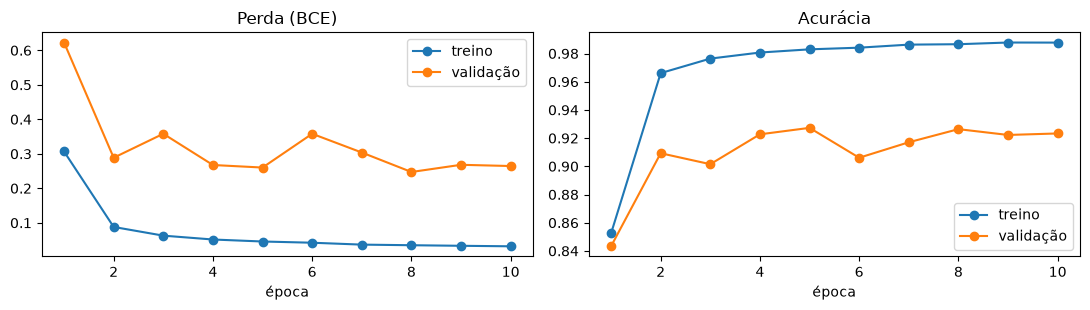

diferença treino − validação na última época: +0.0644 de acurácia


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
ep = np.arange(1, len(hist["perda_tr"]) + 1)
axes[0].plot(ep, hist["perda_tr"], "o-", label="treino"); axes[0].plot(ep, hist["perda_va"], "o-", label="validação")
axes[0].set_title("Perda (BCE)"); axes[0].set_xlabel("época"); axes[0].legend()
axes[1].plot(ep, hist["acc_tr"], "o-", label="treino"); axes[1].plot(ep, hist["acc_va"], "o-", label="validação")
axes[1].set_title("Acurácia"); axes[1].set_xlabel("época"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"diferença treino − validação na última época: "
      f"{hist['acc_tr'][-1] - hist['acc_va'][-1]:+.4f} de acurácia")

### 3.2 Teste em pessoas novas

O limiar de P(fechado) é escolhido na validação (maior F1) e aplicado no teste. Além do total, o resultado sai **por pessoa** e por condição (óculos, reflexo, luz), porque a média esconde quem o modelo erra.

limiar (validação): 0.502
teste: acurácia 0.9697 | precisão 0.9590 | recall 0.9793 | F1 0.9691 | AUC-PR 0.9943


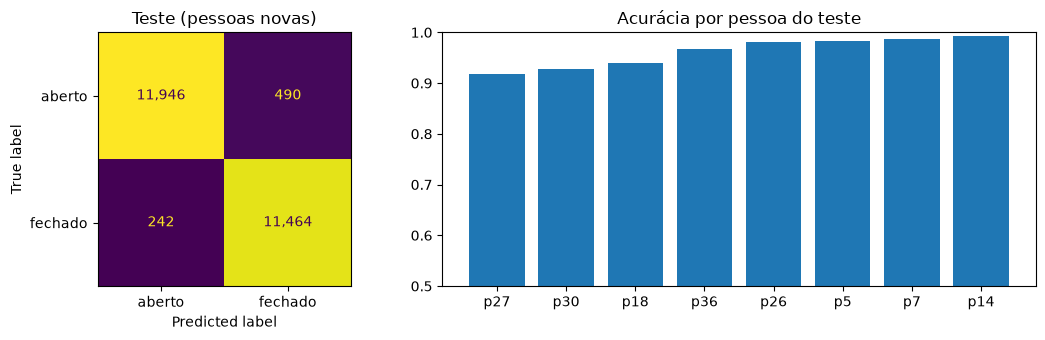

por pessoa: média 0.9622, desvio 0.0293, pior 0.9188


acurácia  imagens
óculos  com        0.9264     6614
        sem        0.9860    17528
reflexo grande     0.8915     3244
        nenhum     0.9822    19312
        pequeno    0.9773     1586
luz     boa        0.9811     8627
        ruim       0.9633    15515

In [15]:
p_va, p_te = prever(cnn, x_mrl[idx_va]), prever(cnn, x_mrl[idx_te])
LIMIAR_CNN_MRL = limiar_f1(y_mrl[idx_va], p_va)
y_te = y_mrl[idx_te]
prev_te = (p_te >= LIMIAR_CNN_MRL).astype(int)
pr, rc, f1, _ = precision_recall_fscore_support(y_te, prev_te, average="binary")
print(f"limiar (validação): {LIMIAR_CNN_MRL:.3f}")
print(f"teste: acurácia {(prev_te == y_te).mean():.4f} | precisão {pr:.4f} | recall {rc:.4f} | "
      f"F1 {f1:.4f} | AUC-PR {average_precision_score(y_te, p_te):.4f}")

te = mrl.iloc[idx_te].assign(acerto=(prev_te == y_te))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [1, 1.6]})
ConfusionMatrixDisplay(confusion_matrix(y_te, prev_te), display_labels=["aberto", "fechado"]).plot(
    ax=axes[0], colorbar=False, values_format=",")
axes[0].set_title("Teste (pessoas novas)")
acc_p = te.groupby("pessoa").acerto.mean().sort_values()
axes[1].bar([f"p{p}" for p in acc_p.index], acc_p.values)
axes[1].set_ylim(min(0.5, acc_p.min() - 0.05), 1); axes[1].set_title("Acurácia por pessoa do teste")
plt.tight_layout(); plt.show()
print(f"por pessoa: média {acc_p.mean():.4f}, desvio {acc_p.std():.4f}, pior {acc_p.min():.4f}")

cond = pd.concat({
    "óculos": te.groupby(te.oculos.map({0: "sem", 1: "com"})).acerto.agg(["mean", "size"]),
    "reflexo": te.groupby(te.reflexo.map({0: "nenhum", 1: "pequeno", 2: "grande"})).acerto.agg(["mean", "size"]),
    "luz": te.groupby(te.luz.map({0: "ruim", 1: "boa"})).acerto.agg(["mean", "size"]),
}).rename(columns={"mean": "acurácia", "size": "imagens"})
cond.round(4)

### Observações da CNN

- **Em 8 pessoas novas:** 97,0% de acurácia, F1 de 0,969 e AUC-PR de 0,994. A pior pessoa fica em 91,9%.
- **Os pontos fracos são óculos (92,6%) e reflexo grande (89,2%),** contra 98,6% sem óculos e 98,2% sem reflexo. É o mesmo problema que a pesquisa aponta para câmeras no carro.
- **Overfitting:** o treino chega a 98,8% e a validação para em cerca de 92%. A validação tem só 5 pessoas, e o teste, com outras 8, fica em 97,0%, então a diferença entre grupos de pessoas pesa bastante. O modelo guardado é o da época com menor perda na validação (época 8).

### 3.3 Quanto o vazamento inflaria o resultado

A pesquisa avisa que dividir imagens ao acaso põe o mesmo rosto no treino e no teste. Para medir isso, a mesma receita é treinada com divisão aleatória (mesmos tamanhos) e as duas notas de teste são comparadas.

In [16]:
ss = ShuffleSplit(n_splits=1, test_size=len(idx_te) / len(x_mrl), random_state=SEMENTE)
idx_resto_a, idx_te_a = next(ss.split(x_mrl))
ss = ShuffleSplit(n_splits=1, test_size=len(idx_va) / len(idx_resto_a), random_state=SEMENTE)
i_tr_a, i_va_a = next(ss.split(idx_resto_a))
cnn_aleat, _ = treinar("cnn_olho_aleatoria", idx_resto_a[i_tr_a], idx_resto_a[i_va_a])

lim_a = limiar_f1(y_mrl[idx_resto_a[i_va_a]], prever(cnn_aleat, x_mrl[idx_resto_a[i_va_a]]))
acc_aleat = ((prever(cnn_aleat, x_mrl[idx_te_a]) >= lim_a) == y_mrl[idx_te_a]).mean()
acc_pessoa = (prev_te == y_te).mean()
print(f"divisão aleatória: {acc_aleat:.4f} | divisão por pessoa: {acc_pessoa:.4f} | "
      f"diferença: {acc_aleat - acc_pessoa:+.4f}")

cnn_olho_aleatoria: carregado do cache (melhor época 10)


divisão aleatória: 0.9896 | divisão por pessoa: 0.9697 | diferença: +0.0199


Com divisão aleatória a nota seria 99,0%, ou 2,0 pontos acima da divisão por pessoa. A diferença é pequena porque o estado do olho é uma tarefa fácil. Em sonolência, onde o modelo pode decorar o jeito de cada pessoa, a pesquisa mostra quedas muito maiores. A divisão por pessoa continua sendo a regra em todo o projeto.

## 4. CNN no vídeo: trocando o EAR pela CNN

Agora a CNN treinada no MRL (infravermelho, só o olho) recebe os recortes de olho do FL3D (webcam RGB à noite, em carro real), que ela nunca viu. O sinal de fechamento passa a ser a média de P(fechado) dos dois olhos, e o resto do sistema é igual: limiar escolhido na calibração, T = 1 s e resultado no teste.

CNN: limiar 0.506 (escolhido na calibração), T = 1.0 s (Euro NCAP)


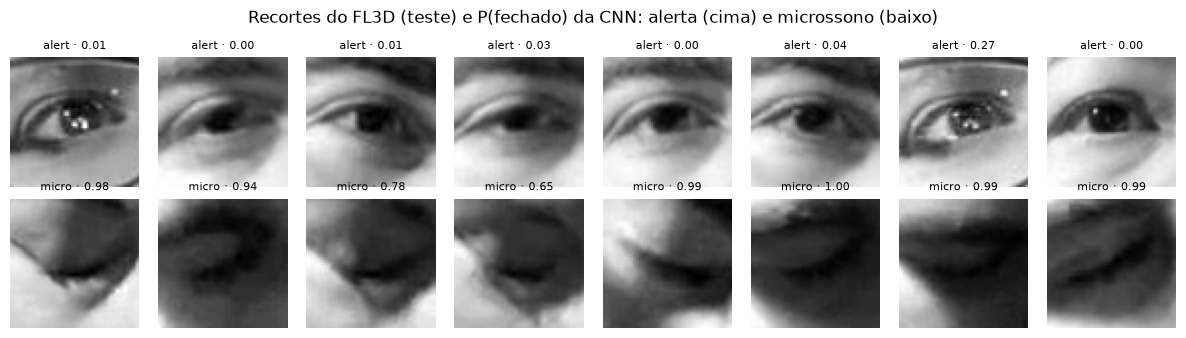

In [17]:
p_olhos = prever(cnn, olhos_fl3d.reshape(-1, TAM, TAM)).reshape(-1, 2)
fl3d["fech_cnn"] = np.where(fl3d.rosto, p_olhos.mean(axis=1), np.nan)
tempo = {v: linha_do_tempo(d) for v, d in fl3d.groupby("video")}

calib = fl3d[(fl3d.grupo == "calibração") & fl3d.rosto]
teste = fl3d[(fl3d.grupo == "teste") & fl3d.rosto]
LIMIAR_CNN = limiar_f1(calib.estado.eq("microsleep"), calib.fech_cnn)
print(f"CNN: limiar {LIMIAR_CNN:.3f} (escolhido na calibração), T = {T_ALERTA} s (Euro NCAP)")

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
amostra = pd.concat([teste[teste.estado == e].sample(8, random_state=SEMENTE) for e in ("alert", "microsleep")])
for ax, (i, r) in zip(axes.flat, amostra.iterrows()):
    ax.imshow(olhos_fl3d[i, 0], cmap="gray")
    ax.set_title(f"{r.estado[:5]} · {r.fech_cnn:.2f}", fontsize=8); ax.axis("off")
plt.suptitle("Recortes do FL3D (teste) e P(fechado) da CNN: alerta (cima) e microssono (baixo)")
plt.tight_layout(); plt.show()

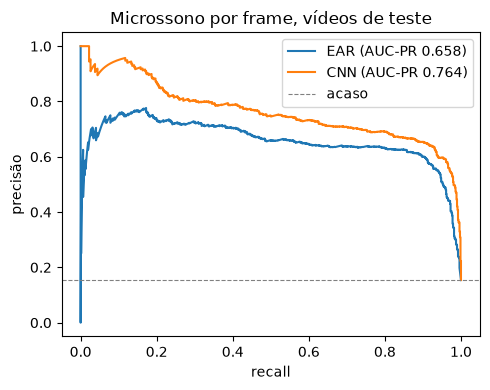

,AUC-PR,precisão,recall,F1
EAR (frame),0.658,0.637,0.694,0.664
CNN (frame),0.764,0.629,0.931,0.751


,T (s),episódios,acertos,recall de evento,falsos alarmes,falsos em bocejo,falsos fora de bocejo,fora de bocejo/hora em alerta,em bocejo/min de bocejo,atraso mediano (s),horas alerta,min bocejo
"EAR, todos os episódios",1.0,26.0,7.0,0.269,3.0,3.0,0.0,0.000,6.207,1.00,0.039,0.483
"CNN, todos os episódios",1.0,26.0,13.0,0.500,6.0,3.0,3.0,77.497,6.207,0.96,0.039,0.483
"EAR, episódios de 1 s ou mais",1.0,14.0,7.0,0.500,3.0,3.0,0.0,0.000,6.207,1.00,0.039,0.483
"CNN, episódios de 1 s ou mais",1.0,14.0,13.0,0.929,6.0,3.0,3.0,77.497,6.207,0.96,0.039,0.483


Varredura de T com a CNN, na calibração:


,T (s),acertos,episódios,recall de evento,falsos alarmes,F1 evento,F2 evento
0,0.4,188,228,0.825,147,0.668,0.754
1,0.6,160,228,0.702,96,0.661,0.685
2,0.8,138,228,0.605,74,0.627,0.614
3,1.0,111,228,0.487,55,0.563,0.515
4,1.2,95,228,0.417,41,0.522,0.453
5,1.5,64,228,0.281,26,0.403,0.319
6,2.0,32,228,0.140,14,0.234,0.167


Varredura de T com a CNN, no teste:


,T (s),acertos,episódios,recall de evento,falsos alarmes,F1 evento,F2 evento
0,0.4,22,26,0.846,16,0.688,0.775
1,0.6,19,26,0.731,8,0.717,0.725
2,0.8,16,26,0.615,7,0.653,0.630
3,1.0,13,26,0.500,6,0.578,0.528
4,1.2,12,26,0.462,3,0.585,0.504
5,1.5,9,26,0.346,2,0.486,0.391
6,2.0,2,26,0.077,1,0.138,0.093


Teste: T = 0,4 s é otimista, porque a base não tem piscadas; T = 1 s é o do sistema


acertos  episódios  recall de evento  falsos alarmes
EAR 0.4     22.0       26.0             0.846             6.0
    1.0      7.0       26.0             0.269             3.0
    2.0      0.0       26.0             0.000             3.0
CNN 0.4     22.0       26.0             0.846            16.0
    1.0     13.0       26.0             0.500             6.0
    2.0      2.0       26.0             0.077             1.0

In [18]:
quadro = pd.DataFrame({
    "EAR (frame)": metricas_frame(teste, "fech_ear", LIMIAR_EAR),
    "CNN (frame)": metricas_frame(teste, "fech_cnn", LIMIAR_CNN),
}).T
eventos = pd.DataFrame({
    "EAR, todos os episódios": avaliar_eventos(videos_teste, "fech_ear", LIMIAR_EAR, T_ALERTA),
    "CNN, todos os episódios": avaliar_eventos(videos_teste, "fech_cnn", LIMIAR_CNN, T_ALERTA),
    "EAR, episódios de 1 s ou mais": avaliar_eventos(videos_teste, "fech_ear", LIMIAR_EAR, T_ALERTA, dur_min=T_ALERTA),
    "CNN, episódios de 1 s ou mais": avaliar_eventos(videos_teste, "fech_cnn", LIMIAR_CNN, T_ALERTA, dur_min=T_ALERTA),
}).T

fig, ax = plt.subplots(figsize=(5, 4))
for col, nome in [("fech_ear", "EAR"), ("fech_cnn", "CNN")]:
    p, r, _ = precision_recall_curve(teste.estado.eq("microsleep"), teste[col])
    ax.plot(r, p, label=f"{nome} (AUC-PR {average_precision_score(teste.estado.eq('microsleep'), teste[col]):.3f})")
ax.axhline(teste.estado.eq("microsleep").mean(), color="gray", ls="--", lw=0.8, label="acaso")
ax.set_xlabel("recall"); ax.set_ylabel("precisão"); ax.set_title("Microssono por frame, vídeos de teste")
ax.legend(); plt.tight_layout(); plt.show()

display(quadro.round(3))
display(eventos.round(3))
print("Varredura de T com a CNN, na calibração:")
display(varrer_T(videos_calib, "fech_cnn", LIMIAR_CNN)[COLUNAS_T].round(3))
print("Varredura de T com a CNN, no teste:")
display(varrer_T(videos_teste, "fech_cnn", LIMIAR_CNN)[COLUNAS_T].round(3))

lado_a_lado = {(nome, T): avaliar_eventos(videos_teste, col, lim, T)
               for nome, col, lim in [("EAR", "fech_ear", LIMIAR_EAR), ("CNN", "fech_cnn", LIMIAR_CNN)]
               for T in (0.4, 1.0, 2.0)}
print("Teste: T = 0,4 s é otimista, porque a base não tem piscadas; T = 1 s é o do sistema")
display(pd.DataFrame(lado_a_lado).T[["acertos", "episódios", "recall de evento", "falsos alarmes"]].round(3))


### 4.1 Olho fechado ou microssono?

A CNN aprendeu **olho fechado**, e o rótulo do FL3D é **microssono**. Os dois não são a mesma coisa: um bocejo aperta o olho, e um olhar para baixo fecha a pálpebra. Para ver onde cada sinal erra, a tabela mostra o sinal médio por estado nos vídeos de teste.

In [19]:
teste.groupby("estado")[["fech_ear", "fech_cnn"]].agg(["mean", "median"]).round(3)

fech_ear        fech_cnn       
               mean median     mean median
estado                                    
alert         0.107  0.070    0.100  0.014
microsleep    0.598  0.611    0.851  0.942
yawning       0.342  0.289    0.334  0.123

### Observações da CNN no vídeo

- **A CNN funciona fora do domínio de treino, com ressalvas.** Treinada em infravermelho de laboratório, ela chega a F1 de 0,75 por frame na câmera noturna, contra 0,66 do EAR, com recall de 0,93 contra 0,69 e AUC-PR de 0,76 contra 0,66.
- **Com T = 1 s, no teste, a CNN acha mais e também alarma mais:** 13 de 26 episódios contra 7 de 26 do EAR, com 6 falsos alarmes contra 3. Nos episódios de 1 s ou mais, são 13 de 14 contra 7 de 14.
- **A vantagem não se repete na calibração.** Lá, com T = 1 s, os dois quase empatam (111 e 114 de 228 episódios), e a CNN dá mais que o dobro de falsos alarmes (55 contra 22). Como o teste tem só 2 vídeos com microssono, os dados não mostram que a CNN é melhor que o EAR.
- **O resultado varia entre treinos.** Com a mesma semente, em outra GPU, a mesma receita deu AUC-PR de 0,65 no vídeo, contra 0,76 aqui, e 11 falsos alarmes com T = 0,4 s, contra 16. Uma diferença desse tamanho não deve ser lida como efeito de outra mudança sem repetir o treino.
- **A CNN se confunde menos com o bocejo na maioria dos frames** (mediana 0,12, contra 0,29 do EAR), mas alguns bocejos dão P(fechado) alta.
- **O recorte piora justamente no microssono.** Quando a cabeça cai, o quadrado pega pálpebra e bochecha borradas (figura acima). Parte do acerto pode vir de "não estou vendo um olho aberto", e não de "olho fechado". Alinhar o recorte pela linha dos olhos é o próximo ajuste.

### 4.2 Dá para melhorar o sinal com T = 1 s?

Com T fixo em 1 s, um trecho fechado precisa durar 1 s sem quebrar. Se o sinal oscila em volta do limiar, a contagem recomeça. Testamos quatro ajustes, sem refazer o MediaPipe, aplicados igualmente ao EAR e à CNN:

- **Limiar de evento:** escolhido pelo F1 de evento com T = 1 s, em vez do F1 por frame.
- **Filtro de mediana:** de 5 ou 7 frames, usando só frames passados, para valer também ao vivo. O custo é um pequeno atraso.
- **Histerese:** um limiar para fechar e outro, mais baixo, para continuar fechado.
- **Manter o rosto:** falhas de até 0,5 s do MediaPipe mantêm o último valor, em vez de quebrar a contagem.

Para não contaminar o teste, a configuração é escolhida só nos 39 vídeos de calibração, com alvo nos episódios de 1 s ou mais. Entre configurações quase empatadas (F1 a até 0,005 da melhor), fica a mais simples. A tabela mostra o efeito de cada ajuste, reescolhendo o limiar em cada linha. O limite desse ajuste é o mesmo da escolha de T: a base não tem piscadas, então juntar trechos e baixar o limiar podem custar mais falsos alarmes do que aparece aqui.

In [20]:
GRADE_LIMIAR = np.round(np.arange(0.20, 0.91, 0.05), 2)
GRADE_AJUSTES = [dict(mediana=m, delta=d, manter=k)
                 for m in (1, 5, 7) for d in (0.0, 0.1, 0.2) for k in (0, int(0.5 * FPS))]
SINAIS = {"EAR": ("fech_ear", LIMIAR_EAR), "CNN": ("fech_cnn", LIMIAR_CNN)}
ORIGINAL = dict(mediana=1, delta=0.0, manter=0)


def f1_evento(acertos, n_ep, falsos):
    recall = acertos / max(n_ep, 1)
    precisao = acertos / max(acertos + falsos, 1)
    return 2 * recall * precisao / max(recall + precisao, 1e-9)


# conferência do protocolo da frente B: com beta = 1, f_beta é o f1_evento
assert all(np.isclose(f1_evento(a, n, f), f_beta(a, n, f, 1))
           for a, n, f in [(0, 10, 0), (0, 10, 5), (5, 10, 0), (7, 14, 3), (143.2, 165, 10.2)])


def varrer_ajustes(col):
    # só calibração, com T fixo; o alvo são os episódios de 1 s ou mais
    linhas = []
    for aj in GRADE_AJUSTES:
        for lim in GRADE_LIMIAR:
            r = avaliar_eventos(videos_calib, col, lim, T_ALERTA, dur_min=T_ALERTA, ajustes=aj)
            linhas.append({**aj, "limiar": lim, "acertos": r["acertos"], "episódios": r["episódios"],
                           "falsos": r["falsos alarmes"],
                           "F1": f1_evento(r["acertos"], r["episódios"], r["falsos alarmes"])})
    return pd.DataFrame(linhas)


def escolher_config(grade, folga=0.005):
    # entre configurações quase empatadas, fica a mais simples, para não sobreajustar
    perto = grade[grade.F1 >= grade.F1.max() - folga]
    return perto.sort_values(["mediana", "delta", "manter", "F1"], ascending=[True, True, True, False]).iloc[0]


def efeito_dos_ajustes(col, lim_original, grade):
    r = avaliar_eventos(videos_calib, col, lim_original, T_ALERTA, dur_min=T_ALERTA)
    linhas = [{"variante": "regra original", **ORIGINAL, "limiar": lim_original, "acertos": r["acertos"],
               "episódios": r["episódios"], "falsos": r["falsos alarmes"],
               "F1": f1_evento(r["acertos"], r["episódios"], r["falsos alarmes"])}]
    so = {"só limiar de evento": (grade.mediana == 1) & (grade.delta == 0) & (grade.manter == 0),
          "+ mediana": (grade.mediana > 1) & (grade.delta == 0) & (grade.manter == 0),
          "+ histerese": (grade.mediana == 1) & (grade.delta > 0) & (grade.manter == 0),
          "+ manter rosto": (grade.mediana == 1) & (grade.delta == 0) & (grade.manter > 0),
          "todas as combinações": grade.F1 > -1}
    for nome, m in so.items():
        melhor = grade[m].sort_values("F1", ascending=False).iloc[0]
        linhas.append({"variante": nome, **melhor.to_dict()})
    return pd.DataFrame(linhas)


# os padrões precisam reproduzir a regra original
for nome, (col, lim) in SINAIS.items():
    a = avaliar_eventos(videos_teste, col, lim, T_ALERTA)
    b = avaliar_eventos(videos_teste, col, lim, T_ALERTA, ajustes=ORIGINAL)
    assert (a["acertos"], a["falsos alarmes"]) == (b["acertos"], b["falsos alarmes"]), nome

CONFIG = {}
for nome, (col, lim) in SINAIS.items():
    grade = varrer_ajustes(col)
    CONFIG[nome] = escolher_config(grade)
    print(f"{nome}, calibração, T = 1 s, episódios de 1 s ou mais:")
    display(efeito_dos_ajustes(col, lim, grade).round(3))
    print("configuração congelada:", CONFIG[nome][["mediana", "delta", "manter", "limiar"]].to_dict())

EAR, calibração, T = 1 s, episódios de 1 s ou mais:


,variante,mediana,delta,manter,limiar,acertos,episódios,falsos,F1
0,regra original,1.0,0.0,0.0,0.525,113.0,151.0,22.0,0.790
1,só limiar de evento,1.0,0.0,0.0,0.450,122.0,151.0,32.0,0.800
2,+ mediana,5.0,0.0,0.0,0.450,122.0,151.0,27.0,0.813
3,+ histerese,1.0,0.2,0.0,0.500,122.0,151.0,33.0,0.797
4,+ manter rosto,1.0,0.0,12.0,0.450,123.0,151.0,32.0,0.804
5,todas as combinações,5.0,0.0,0.0,0.450,122.0,151.0,27.0,0.813


configuração congelada: {'mediana': 5.0, 'delta': 0.0, 'manter': 0.0, 'limiar': 0.45}


CNN, calibração, T = 1 s, episódios de 1 s ou mais:


,variante,mediana,delta,manter,limiar,acertos,episódios,falsos,F1
0,regra original,1.0,0.0,0.0,0.506,111.0,151.0,55.0,0.700
1,só limiar de evento,1.0,0.0,0.0,0.550,103.0,151.0,45.0,0.689
2,+ mediana,5.0,0.0,0.0,0.500,109.0,151.0,54.0,0.694
3,+ histerese,1.0,0.1,0.0,0.550,110.0,151.0,56.0,0.694
4,+ manter rosto,1.0,0.0,12.0,0.500,113.0,151.0,64.0,0.689
5,todas as combinações,7.0,0.2,12.0,0.600,115.0,151.0,56.0,0.714


configuração congelada: {'mediana': 7.0, 'delta': 0.1, 'manter': 12.0, 'limiar': 0.55}


Com a configuração congelada, ela é avaliada uma vez no teste (holdout).

In [21]:
def ajustes_de(c):
    return dict(mediana=int(c.mediana), delta=float(c.delta), manter=int(c.manter))


linhas = {}
for nome, (col, lim) in SINAIS.items():
    c = CONFIG[nome]
    for rotulo, l, aj in [("regra original", lim, ORIGINAL), ("com ajustes", float(c.limiar), ajustes_de(c))]:
        todos = avaliar_eventos(videos_teste, col, l, T_ALERTA, ajustes=aj)
        longos = avaliar_eventos(videos_teste, col, l, T_ALERTA, dur_min=T_ALERTA, ajustes=aj)
        linhas[(nome, rotulo)] = {"limiar": l, "acertos": todos["acertos"], "episódios": todos["episódios"],
                                  "acertos 1 s ou mais": longos["acertos"], "episódios 1 s ou mais": longos["episódios"],
                                  "falsos alarmes": todos["falsos alarmes"],
                                  "atraso mediano (s)": todos["atraso mediano (s)"]}
print("Holdout (5 vídeos), T = 1 s")
pd.DataFrame(linhas).T.round(3)

Holdout (5 vídeos), T = 1 s


limiar  acertos  episódios  acertos 1 s ou mais  \
EAR regra original   0.525      7.0       26.0                  7.0   
    com ajustes      0.450      8.0       26.0                  8.0   
CNN regra original   0.506     13.0       26.0                 13.0   
    com ajustes      0.550     14.0       26.0                 13.0   

                    episódios 1 s ou mais  falsos alarmes  atraso mediano (s)  
EAR regra original                   14.0             3.0                1.00  
    com ajustes                      14.0             3.0                1.04  
CNN regra original                   14.0             6.0                0.96  
    com ajustes                      14.0             5.0                1.08

O teste tem só 26 episódios em 2 vídeos. Como nem a CNN nem o EAR treinam no FL3D, dá para usar a base inteira na avaliação: o limiar de cada vídeo é escolhido nos outros 43 e aplicado só nele, e no fim somamos todos os vídeos. Os ajustes ficam congelados como acima, e **as duas linhas de cada sinal usam o limiar de evento**, então "sem ajustes" aqui não é igual à regra original do holdout.

**Limitação:** o FL3D não traz identificador de motorista, então a separação é por vídeo. O mesmo motorista pode ajudar a escolher o limiar do próprio vídeo, e os ajustes também foram escolhidos em 39 desses 44 vídeos. Os resultados são, portanto, um pouco otimistas. O intervalo de 95% vem de um bootstrap por vídeo e mede a incerteza do recall nos episódios de 1 s ou mais.

In [22]:
VIDEOS = sorted(fl3d.video.unique())


def contagens(col, aj):
    # uma tabela (vídeo x limiar) para cada contagem; assim cada rodada só escolhe o limiar
    linhas = []
    for v in VIDEOS:
        for lim in GRADE_LIMIAR:
            t = avaliar_eventos([v], col, lim, T_ALERTA, ajustes=aj)
            l = avaliar_eventos([v], col, lim, T_ALERTA, dur_min=T_ALERTA, ajustes=aj)
            linhas.append((v, lim, t["acertos"], t["episódios"], l["acertos"], l["episódios"], t["falsos alarmes"],
                           t["falsos em bocejo"]))
    return pd.DataFrame(linhas, columns=["video", "limiar", "ac", "ep", "ac_l", "ep_l", "falsos", "falsos_boc"])


def deixar_um_video_de_fora(tab):
    # o limiar de cada vídeo é escolhido nos outros 43 e aplicado só nele
    fora = []
    for v in VIDEOS:
        resto = tab[tab.video != v].groupby("limiar")[["ac_l", "ep_l", "falsos"]].sum()
        f1 = [f1_evento(r.ac_l, r.ep_l, r.falsos) for r in resto.itertuples()]
        lim = resto.index[int(np.argmax(f1))]
        fora.append(tab[(tab.video == v) & (tab.limiar == lim)].iloc[0])
    return pd.DataFrame(fora)


def intervalo(fora, num, den, n=2000):
    # bootstrap por vídeo: incerteza de um recall somado em todos os vídeos
    rng = np.random.default_rng(SEMENTE)
    a, b = fora[num].values, fora[den].values
    idx = rng.integers(0, len(a), (n, len(a)))
    amostras = a[idx].sum(axis=1) / np.maximum(b[idx].sum(axis=1), 1)
    return np.percentile(amostras, [2.5, 97.5])


linhas, horas = {}, sum(tl.estado.eq("alert").sum() for tl in tempo.values()) / FPS / 3600
for nome, (col, _) in SINAIS.items():
    for rotulo, aj in [("sem ajustes", ORIGINAL), ("com ajustes", ajustes_de(CONFIG[nome]))]:
        fora = deixar_um_video_de_fora(contagens(col, aj))
        ic = intervalo(fora, "ac_l", "ep_l")
        linhas[(nome, rotulo)] = {"acertos": fora.ac.sum(), "episódios": fora.ep.sum(),
                                  "recall": fora.ac.sum() / fora.ep.sum(),
                                  "acertos 1 s ou mais": fora.ac_l.sum(), "episódios 1 s ou mais": fora.ep_l.sum(),
                                  "recall 1 s ou mais": fora.ac_l.sum() / fora.ep_l.sum(),
                                  "IC95% inf.": ic[0], "IC95% sup.": ic[1], "falsos alarmes": fora.falsos.sum(),
                                  "falsos em bocejo": fora.falsos_boc.sum()}
print(f"Validação cruzada nos {len(VIDEOS)} vídeos, T = 1 s, {horas * 60:.0f} minutos em alerta")
cv_eventos = pd.DataFrame(linhas).T
cv_eventos.round(3)

Validação cruzada nos 44 vídeos, T = 1 s, 26 minutos em alerta


acertos  episódios  recall  acertos 1 s ou mais  \
EAR sem ajustes    135.0      254.0   0.531                131.0   
    com ajustes    131.0      254.0   0.516                130.0   
CNN sem ajustes    109.0      254.0   0.429                109.0   
    com ajustes    126.0      254.0   0.496                123.0   

                 episódios 1 s ou mais  recall 1 s ou mais  IC95% inf.  \
EAR sem ajustes                  165.0               0.794       0.617   
    com ajustes                  165.0               0.788       0.603   
CNN sem ajustes                  165.0               0.661       0.541   
    com ajustes                  165.0               0.745       0.626   

                 IC95% sup.  falsos alarmes  falsos em bocejo  
EAR sem ajustes       0.922            39.0              34.0  
    com ajustes       0.923            30.0              25.0  
CNN sem ajustes       0.785            56.0              31.0  
    com ajustes       0.856            69.0              39.0

### Observações dos ajustes

- **Os ajustes ajudam pouco.** No holdout, o EAR vai de 7 para 8 acertos, com os mesmos 3 falsos alarmes, e a CNN vai de 13 para 14, com 5 falsos alarmes em vez de 6. Na validação cruzada, os intervalos de confiança se sobrepõem bastante.
- **No EAR, o ajuste útil é simples:** limiar de 0,45 e mediana de 5 frames. Na validação cruzada, o recall quase não muda (131 e 130 de 165 episódios de 1 s ou mais), e os falsos alarmes caem de 39 para 30. O atraso mediano no holdout vai de 1,00 s para 1,04 s.
- **Na CNN, é uma troca:** o recall sobe de 109 para 123 de 165, mas os falsos alarmes sobem de 56 para 69. Para ela, não há ganho claro que justifique os três ajustes.
- **O holdout era pessimista para o EAR.** Na validação cruzada, ele acha 79% dos episódios de 1 s ou mais (IC95% de 62% a 92%), contra 50% no holdout. Os 2 vídeos do holdout parecem mais difíceis que o restante da base.
- **Com a base inteira, a CNN não supera o EAR.** Sem ajustes, ela acha 66% dos episódios de 1 s ou mais, com 56 falsos alarmes, contra 79% e 39 do EAR. A vantagem da CNN no holdout não se repete, e os intervalos ainda se sobrepõem.
- **Falsos alarmes continuam sem piscadas.** São de 30 a 69 alarmes na base inteira, que tem 26 minutos em alerta e também trechos de bocejo. Medir com piscadas reais continua sendo necessário.

## 5. Comparação de classificadores: MobileNetV3 x YOLO26n-cls

A YOLO26n classificadora entra no mesmo lugar do pipeline: recebe o recorte do olho e devolve P(fechado). Para a comparação valer, só o modelo muda:

- **Mesmas pessoas:** as mesmas partições do MRL da seção 3, conferidas por `assert`.
- **Mesma receita:** o mesmo laço `treinar`, com as mesmas épocas, lote, taxa de aprendizado, aumento de dados e critério de melhor época. Os dois são pré-treinados no ImageNet e têm a última camada trocada por 1 saída. A única diferença é a normalização, porque cada um usa a do seu pré-treino.
- **Mesma avaliação:** MRL em 8 pessoas novas, FL3D por frame e alerta com T = 1 s, sem ajustes de sinal. O limiar de evento é escolhido na calibração, e a validação cruzada usa os 44 vídeos, como na seção 4.2.
- **5 sementes para cada modelo:** a seção 4 mostrou que o resultado varia entre treinos, então uma única rodada não permitiria comparar.

**Licença:** a biblioteca `ultralytics` é AGPL-3.0. Na interpretação da empresa, o uso exige publicar o código completo e, quando aplicável, os pesos. Essa é a posição da empresa, não um parecer jurídico. Hoje o repositório é privado, então manter o YOLO no projeto exige planejar a publicação.

In [23]:
os.environ.setdefault("YOLO_VERBOSE", "False")
from ultralytics import YOLO
from ultralytics.utils import SETTINGS
from ultralytics.data.augment import DEFAULT_MEAN, DEFAULT_STD

SETTINGS.update({"sync": False})   # sem envio de dados de uso
assert tuple(DEFAULT_MEAN) == (0.0, 0.0, 0.0) and tuple(DEFAULT_STD) == (1.0, 1.0, 1.0)


def normalizar_yolo(x):
    # a classificadora do YOLO é pré-treinada com entrada em [0, 1], sem média e desvio
    return x.repeat(1, 3, 1, 1)


class YoloBinario(nn.Module):
    # treina com logits; em avaliação, o YOLO devolve (probabilidades, logits)
    def __init__(self):
        super().__init__()
        aqui = os.getcwd()
        os.chdir(PASTA_MODELOS)    # os pesos ficam em data/modelos, fora do git
        try:
            self.rede = YOLO("yolo26n-cls.pt").model
        finally:
            os.chdir(aqui)
        cabeca = self.rede.model[-1]
        cabeca.linear = nn.Linear(cabeca.linear.in_features, 1)
        for p in self.rede.parameters():
            p.requires_grad_(True)

    def forward(self, x):
        saida = self.rede(x)
        return saida if torch.is_tensor(saida) else saida[1]


def criar_yolo():
    return YoloBinario().to(DEVICE)


SEMENTES = (42, 1, 2, 3, 4)
CLASSIFICADORES = {
    "MobileNetV3-Small": dict(criar=criar_modelo, norm=normalizar,
                              nome=lambda s: "cnn_olho_por_pessoa" if s == SEMENTE else f"mobilenet_por_pessoa_s{s}"),
    "YOLO26n-cls": dict(criar=criar_yolo, norm=normalizar_yolo, nome=lambda s: f"yolo26n_por_pessoa_s{s}"),
}

# as mesmas pessoas em qualquer modelo: idx_tr, idx_va e idx_te vêm da seção 3
assert sorted(int(p) for p in pessoas["teste"]) == [5, 7, 14, 18, 26, 27, 30, 36]

modelos = {}
for nome_mod, c in CLASSIFICADORES.items():
    for s in SEMENTES:
        t0 = time.time()
        modelos[nome_mod, s], _ = treinar(c["nome"](s), idx_tr, idx_va, criar=c["criar"], norm=c["norm"],
                                          semente=s, detalhar=False)
        print(f"{nome_mod}, semente {s}: {time.time() - t0:.0f} s")

cnn_olho_por_pessoa: carregado do cache (melhor época 8)
MobileNetV3-Small, semente 42: 0 s


mobilenet_por_pessoa_s1: carregado do cache (melhor época 9)
MobileNetV3-Small, semente 1: 0 s


mobilenet_por_pessoa_s2: carregado do cache (melhor época 6)
MobileNetV3-Small, semente 2: 0 s


mobilenet_por_pessoa_s3: carregado do cache (melhor época 5)
MobileNetV3-Small, semente 3: 0 s


mobilenet_por_pessoa_s4: carregado do cache (melhor época 3)
MobileNetV3-Small, semente 4: 0 s
yolo26n_por_pessoa_s42: carregado do cache (melhor época 3)
YOLO26n-cls, semente 42: 0 s


yolo26n_por_pessoa_s1: carregado do cache (melhor época 6)
YOLO26n-cls, semente 1: 0 s
yolo26n_por_pessoa_s2: carregado do cache (melhor época 3)
YOLO26n-cls, semente 2: 0 s


yolo26n_por_pessoa_s3: carregado do cache (melhor época 6)
YOLO26n-cls, semente 3: 0 s
yolo26n_por_pessoa_s4: carregado do cache (melhor época 3)
YOLO26n-cls, semente 4: 0 s


In [24]:
def avaliar_classificador(modelo, norm):
    global tempo
    # MRL: limiar na validação, resultado nas 8 pessoas do teste
    p_v, p_t = prever(modelo, x_mrl[idx_va], norm=norm), prever(modelo, x_mrl[idx_te], norm=norm)
    lim = limiar_f1(y_mrl[idx_va], p_v)
    prev = (p_t >= lim).astype(int)
    _, _, f1, _ = precision_recall_fscore_support(y_mrl[idx_te], prev, average="binary")
    t = mrl.iloc[idx_te].assign(acerto=(prev == y_mrl[idx_te]))
    res = {"MRL acurácia": t.acerto.mean(), "MRL F1": f1,
           "MRL pior pessoa": t.groupby("pessoa").acerto.mean().min(),
           "MRL com óculos": t[t.oculos == 1].acerto.mean(),
           "MRL reflexo grande": t[t.reflexo == 2].acerto.mean()}

    # FL3D por frame: limiar na calibração, resultado no holdout
    col = "fech_comparacao"
    p_o = prever(modelo, olhos_fl3d.reshape(-1, TAM, TAM), norm=norm).reshape(-1, 2)
    fl3d[col] = np.where(fl3d.rosto, p_o.mean(axis=1), np.nan)
    tempo = {v: linha_do_tempo(d) for v, d in fl3d.groupby("video")}
    ca, te_ = fl3d[(fl3d.grupo == "calibração") & fl3d.rosto], fl3d[(fl3d.grupo == "teste") & fl3d.rosto]
    q = metricas_frame(te_, col, limiar_f1(ca.estado.eq("microsleep"), ca[col]))
    res |= {"FL3D AUC-PR": q["AUC-PR"], "FL3D F1 frame": q["F1"]}

    # alerta com T = 1 s, sem ajustes: limiar de evento na calibração, resultado no holdout
    linhas = [(l, avaliar_eventos(videos_calib, col, l, T_ALERTA, dur_min=T_ALERTA)) for l in GRADE_LIMIAR]
    lim_ev = max(linhas, key=lambda x: f1_evento(x[1]["acertos"], x[1]["episódios"], x[1]["falsos alarmes"]))[0]
    h = avaliar_eventos(videos_teste, col, lim_ev, T_ALERTA, dur_min=T_ALERTA)
    res |= {"holdout acertos 1 s+": h["acertos"], "holdout falsos": h["falsos alarmes"],
            "holdout F1": f_beta(h["acertos"], h["episódios"], h["falsos alarmes"], 1),
            "holdout F2": f_beta(h["acertos"], h["episódios"], h["falsos alarmes"], 2)}

    # validação cruzada nos 44 vídeos
    fora = deixar_um_video_de_fora(contagens(col, ORIGINAL)).set_index("video")
    res |= {"CV recall 1 s+": fora.ac_l.sum() / fora.ep_l.sum(), "CV falsos": fora.falsos.sum()}
    res |= {f"CV {k}": v for k, v in metricas_f(fora.ac_l.sum(), fora.ep_l.sum(), fora.falsos.sum()).items()}
    return res, fora


def tempos_cpu(rodadas=5, n=200, descarte=20):
    # um recorte por vez, como ao vivo. Os modelos se alternam para a ordem não favorecer nenhum.
    copias = {nome: copy.deepcopy(modelos[nome, SEMENTE]).cpu().eval() for nome in CLASSIFICADORES}
    x = torch.from_numpy(olhos_fl3d[fl3d.rosto.values][:n, 0]).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
    entradas = {"MobileNetV3-Small": (x - MEDIA.cpu()) / DESVIO.cpu(), "YOLO26n-cls": x}
    threads_antes = torch.get_num_threads()
    res = {}
    for threads in (1, threads_antes):
        torch.set_num_threads(threads)
        tempos = {nome: [] for nome in copias}
        with torch.no_grad():
            for r in range(rodadas):
                ordem = list(copias)[::1 if r % 2 == 0 else -1]
                for nome in ordem:
                    for i in range(n):
                        t0 = time.perf_counter()
                        copias[nome](entradas[nome][i:i + 1])
                        if i >= descarte:
                            tempos[nome].append(time.perf_counter() - t0)
        for nome, t in tempos.items():
            res.setdefault(nome, {})[f"ms por recorte, {threads} thread(s)"] = np.median(t) * 1000
    torch.set_num_threads(threads_antes)
    return res


linhas, foras, cols_modelo = {}, {}, {}
for (nome_mod, s), modelo in modelos.items():
    linhas[nome_mod, s], foras[nome_mod, s] = avaliar_classificador(modelo, CLASSIFICADORES[nome_mod]["norm"])
    cols_modelo[nome_mod, s] = f"fech_{'yolo' if nome_mod.startswith('YOLO') else 'mob'}_{s}"
    fl3d[cols_modelo[nome_mod, s]] = fl3d["fech_comparacao"]
tempo = {v: linha_do_tempo(d) for v, d in fl3d.groupby("video")}
por_semente = pd.DataFrame(linhas).T
por_semente.index.names = ["modelo", "semente"]
display(por_semente.round(3))

resumo_cmp = por_semente.groupby("modelo").agg(["mean", "std"]).T.unstack().round(3)
display(resumo_cmp)

cpu = tempos_cpu()
custo = {nome: {"parâmetros (M)": sum(p.numel() for p in modelos[nome, SEMENTE].parameters()) / 1e6, **cpu[nome]}
         for nome in CLASSIFICADORES}
display(pd.DataFrame(custo).T.round(2))


def media_por_video(nome):
    return sum(foras[nome, s][["ac_l", "ep_l", "falsos"]] for s in SEMENTES) / len(SEMENTES)


fora_ear = deixar_um_video_de_fora(contagens("fech_ear", ORIGINAL)).set_index("video")[["ac_l", "ep_l", "falsos"]]
tabelas = {"EAR": fora_ear, "MobileNetV3-Small": media_por_video("MobileNetV3-Small"),
           "YOLO26n-cls": media_por_video("YOLO26n-cls")}


def dif_f(A, B, idx):
    # diferença de F1 e F2 (a - b), com os mesmos sorteios de vídeo do recall e dos falsos alarmes
    soma = lambda t, c: t[c].values[idx].sum(axis=1)
    saida = {}
    for beta in (1, 2):
        ponto = (f_beta(A.ac_l.sum(), A.ep_l.sum(), A.falsos.sum(), beta)
                 - f_beta(B.ac_l.sum(), B.ep_l.sum(), B.falsos.sum(), beta))
        d = (f_beta(soma(A, "ac_l"), soma(A, "ep_l"), soma(A, "falsos"), beta)
             - f_beta(soma(B, "ac_l"), soma(B, "ep_l"), soma(B, "falsos"), beta))
        saida |= {f"dif. F{beta}": ponto, f"F{beta} IC95% inf.": np.percentile(d, 2.5),
                  f"F{beta} IC95% sup.": np.percentile(d, 97.5)}
    return saida


def diferenca(a, b, n=5000):
    # bootstrap por vídeo: os mesmos vídeos sorteados nos dois sinais
    A, B = tabelas[a].loc[VIDEOS], tabelas[b].loc[VIDEOS]
    idx = np.random.default_rng(SEMENTE).integers(0, len(VIDEOS), (n, len(VIDEOS)))
    rec = lambda t: t.ac_l.values[idx].sum(axis=1) / np.maximum(t.ep_l.values[idx].sum(axis=1), 1)
    d_rec, d_fal = rec(A) - rec(B), A.falsos.values[idx].sum(axis=1) - B.falsos.values[idx].sum(axis=1)
    return {"dif. recall 1 s+": rec_total(A) - rec_total(B),
            "recall IC95% inf.": np.percentile(d_rec, 2.5), "recall IC95% sup.": np.percentile(d_rec, 97.5),
            "dif. falsos": A.falsos.sum() - B.falsos.sum(),
            "falsos IC95% inf.": np.percentile(d_fal, 2.5), "falsos IC95% sup.": np.percentile(d_fal, 97.5),
            **dif_f(A, B, idx)}


def rec_total(t):
    return t.ac_l.sum() / t.ep_l.sum()


print("Validação cruzada, T = 1 s, sem ajustes; classificadores pela média das 5 sementes")
display(pd.DataFrame({f"{a} - {b}": diferenca(a, b) for a, b in [("YOLO26n-cls", "MobileNetV3-Small"),
                                                                  ("YOLO26n-cls", "EAR"),
                                                                  ("MobileNetV3-Small", "EAR")]}).T.round(3))


MRL acurácia  MRL F1  MRL pior pessoa  \
modelo            semente                                          
MobileNetV3-Small 42              0.970   0.969            0.919   
                  1               0.971   0.971            0.914   
                  2               0.969   0.968            0.912   
                  3               0.970   0.970            0.904   
                  4               0.958   0.956            0.907   
YOLO26n-cls       42              0.976   0.975            0.928   
                  1               0.975   0.975            0.913   
                  2               0.976   0.975            0.916   
                  3               0.978   0.977            0.931   
                  4               0.978   0.977            0.934   

                           MRL com óculos  MRL reflexo grande  FL3D AUC-PR  \
modelo            semente                                                    
MobileNetV3-Small 42                0.926               0.891        0.764   
                  1                 0.931               0.900        0.841   
                  2                 0.927               0.895        0.787   
                  3                 0.932               0.900        0.843   
                  4                 0.911               0.868        0.844   
YOLO26n-cls       42                0.950               0.926        0.874   
                  1                 0.949               0.926        0.896   
                  2                 0.947               0.926        0.908   
                  3                 0.953               0.934        0.926   
                  4                 0.953               0.932        0.938   

                           FL3D F1 frame  holdout acertos 1 s+  \
modelo            semente                                        
MobileNetV3-Small 42               0.751                  13.0   
                  1                0.790                  13.0   
                  2                0.770                  13.0   
                  3                0.819                  13.0   
                  4                0.810                  12.0   
YOLO26n-cls       42               0.795                  12.0   
                  1                0.819                  12.0   
                  2                0.825                  12.0   
                  3                0.814                  12.0   
                  4                0.833                  13.0   

                           holdout falsos  holdout F1  holdout F2  \
modelo            semente                                           
MobileNetV3-Small 42                  4.0       0.839       0.890   
                  1                   3.0       0.867       0.903   
                  2                   4.0       0.839       0.890   
                  3                   2.0       0.897       0.915   
                  4                   0.0       0.923       0.882   
YOLO26n-cls       42                  3.0       0.828       0.845   
                  1                   2.0       0.857       0.857   
                  2                   3.0       0.828       0.845   
                  3                   3.0       0.828       0.845   
                  4                   2.0       0.897       0.915   

                           CV recall 1 s+  CV falsos  CV precisão por alarme  \
modelo            semente                                                      
MobileNetV3-Small 42                0.661       56.0                   0.661   
                  1                 0.812       48.0                   0.736   
                  2                 0.715       45.0                   0.724   
                  3                 0.715       28.0                   0.808   
                  4                 0.770       28.0                   0.819   
YOLO26n-cls       42                0.848       31.0                   0.819   
           

modelo                 MobileNetV3-Small         YOLO26n-cls       
                                    mean     std        mean    std
MRL acurácia                       0.968   0.005       0.977  0.001
MRL F1                             0.967   0.006       0.976  0.001
MRL pior pessoa                    0.911   0.006       0.924  0.009
MRL com óculos                     0.925   0.008       0.950  0.003
MRL reflexo grande                 0.891   0.013       0.929  0.004
FL3D AUC-PR                        0.816   0.038       0.908  0.025
FL3D F1 frame                      0.788   0.028       0.817  0.014
holdout acertos 1 s+              12.800   0.447      12.200  0.447
holdout falsos                     2.600   1.673       2.600  0.548
holdout F1                         0.873   0.037       0.847  0.030
holdout F2                         0.896   0.013       0.862  0.031
CV recall 1 s+                     0.735   0.058       0.845  0.034
CV falsos                         41.000  12.530      32.800  3.834
CV precisão por alarme             0.750   0.065       0.809  0.023
CV F1                              0.741   0.052       0.827  0.027
CV F2                              0.737   0.054       0.837  0.031

,parâmetros (M),"ms por recorte, 1 thread(s)","ms por recorte, 10 thread(s)"
MobileNetV3-Small,1.52,6.59,8.91
YOLO26n-cls,1.53,5.80,6.73


Validação cruzada, T = 1 s, sem ajustes; classificadores pela média das 5 sementes


,dif. recall 1 s+,recall IC95% inf.,recall IC95% sup.,dif. falsos,falsos IC95% inf.,falsos IC95% sup.,dif. F1,F1 IC95% inf.,F1 IC95% sup.,dif. F2,F2 IC95% inf.,F2 IC95% sup.
YOLO26n-cls - MobileNetV3-Small,0.110,0.037,0.194,-8.2,-19.005,0.2,0.086,0.040,0.141,0.100,0.041,0.172
YOLO26n-cls - EAR,0.051,-0.068,0.205,-6.2,-16.605,3.4,0.045,-0.026,0.151,0.048,-0.048,0.182
MobileNetV3-Small - EAR,-0.059,-0.247,0.150,2.0,-11.800,17.0,-0.041,-0.152,0.098,-0.052,-0.206,0.129


### Observações da comparação

| Média ± desvio das 5 sementes | MobileNetV3-Small | YOLO26n-cls |
|---|---|---|
| MRL: acurácia | 96,8% ± 0,5 | 97,7% ± 0,1 |
| MRL: pior pessoa | 91,1% ± 0,6 | 92,4% ± 0,9 |
| MRL: com óculos | 92,5% ± 0,8 | 95,0% ± 0,3 |
| MRL: reflexo grande | 89,1% ± 1,3 | 92,9% ± 0,4 |
| FL3D: AUC-PR por frame | 0,82 ± 0,04 | 0,91 ± 0,03 |
| FL3D: F1 por frame | 0,79 ± 0,03 | 0,82 ± 0,01 |
| Validação cruzada: recall em episódios de 1 s ou mais | 73,5% ± 5,8 | 84,5% ± 3,4 |
| Validação cruzada: falsos alarmes | 41 ± 13 | 33 ± 4 |
| Validação cruzada: precisão por alarme | 75,0% ± 6,5 | 80,9% ± 2,3 |
| Validação cruzada: F1 | 0,74 ± 0,05 | 0,83 ± 0,03 |
| Validação cruzada: F2 | 0,74 ± 0,05 | 0,84 ± 0,03 |
| Holdout: acertos em 14 episódios de 1 s ou mais | 12,8 ± 0,4 | 12,2 ± 0,4 |
| Holdout: falsos alarmes | 2,6 ± 1,7 | 2,6 ± 0,5 |
| Holdout: F1 | 0,87 ± 0,04 | 0,85 ± 0,03 |
| Holdout: F2 | 0,90 ± 0,01 | 0,86 ± 0,03 |

- **O YOLO foi melhor que a MobileNet na maioria das medidas e mais estável entre sementes.** Na validação cruzada, ele acha 11 pontos a mais, com intervalo de 95% de +3,7 a +19,4 pontos, que não inclui zero. O ganho em falsos alarmes não é conclusivo (8 a menos, intervalo de -19 a +0,2).
- **F1 e F2 confirmam a leitura.** Pela média das 5 sementes, o YOLO tem F2 0,100 maior que a MobileNet (de +0,041 a +0,172) e F1 0,086 maior (de +0,040 a +0,141). Contra o EAR, a diferença não é conclusiva (F2 +0,048, de −0,048 a +0,182).
- **No holdout, os dois empatam na prática,** com diferença de menos de 1 episódio em 14. O teste é pequeno demais para separá-los.
- **Nenhum dos dois superou o EAR de forma conclusiva.** O YOLO acha 5 pontos a mais que o EAR sem ajustes (intervalo de -6,8 a +20,5) e 6 falsos alarmes a menos (intervalo de -17 a +3). A MobileNet fica 6 pontos abaixo (intervalo de -24,7 a +15,0).
- **A velocidade não decide.** Na CPU desta máquina, os dois ficam perto de 3 ms por recorte (YOLO 2,7 a 2,9 ms; MobileNet 3,1 a 3,7 ms), e cada frame tem dois recortes. O MediaPipe, com 10 a 24 ms por frame, é o que mais pesa. Isso daria de 16 a 30 ms por frame, ou de 33 a 60 FPS, mas é só uma soma: os FPS reais precisam ser medidos na demo, com a câmera.
- **O que os intervalos não cobrem:** eles medem a incerteza dos vídeos sorteados, não todas as fontes de erro. O FL3D não tem piscadas, a separação é por vídeo e não por motorista, e os recortes ficam borrados quando a cabeça cai.
- **A MobileNet da seção 4 é a pior das 5 sementes no vídeo.** Ela tem AUC-PR de 0,76, enquanto a média é 0,82. Os valores da seção 4 são de um único treino, e os desta tabela são a melhor referência para a MobileNet.

**Decisão do grupo:** pelos dados, o YOLO26n-cls é o classificador mais promissor dos dois. O repositório agora é público e a licença do projeto passa a ser AGPL-3.0, o que resolve a exigência da biblioteca.

## 6. Falsos alarmes: filtro de bocejo e piscadas

Os falsos alarmes eram o maior problema das seções anteriores. Esta seção responde a três perguntas: de onde eles vêm, se um filtro de bocejo resolve e o que acontece com as piscadas que o FL3D removeu.

A partir daqui, os falsos alarmes são contados em duas partes, cada uma com o próprio denominador. Um alarme é **ligado a bocejo** quando há frame rotulado como bocejo no trecho fechado ou a até 2 s dele. Antes, dividíamos tudo só pelo tempo em alerta, o que inflava a taxa, porque os vídeos de bocejo têm cerca de 3 bocejos em 20 s, ritmo que não representa uma viagem.

In [25]:
COL_DETALHE = {"EAR": "fech_ear", "MobileNetV3 (semente 42)": cols_modelo["MobileNetV3-Small", SEMENTE],
               "YOLO26n-cls (semente 42)": cols_modelo["YOLO26n-cls", SEMENTE]}


def limiar_na_calibracao(col, ajustes=None):
    res = [(f1_evento(r["acertos"], r["episódios"], r["falsos alarmes"]), l) for l, r in
           ((l, avaliar_eventos(videos_calib, col, l, T_ALERTA, dur_min=T_ALERTA, ajustes=ajustes)) for l in GRADE_LIMIAR)]
    return max(res)[1]


LIMIAR_DET = {n: limiar_na_calibracao(c) for n, c in COL_DETALHE.items()}
tab = {}
for nome, col in COL_DETALHE.items():
    r = avaliar_eventos(videos_calib, col, LIMIAR_DET[nome], T_ALERTA, dur_min=T_ALERTA)
    tab[nome] = {k: r[k] for k in ("falsos alarmes", "falsos em bocejo", "falsos fora de bocejo", "min bocejo",
                                   "em bocejo/min de bocejo", "fora de bocejo/hora em alerta")} | {"min alerta": r["horas alerta"] * 60}
print("Calibração, T = 1 s, sem filtro")
display(pd.DataFrame(tab).T.round(2))

ca = fl3d[(fl3d.grupo == "calibração") & fl3d.rosto]
print("Abertura da boca na calibração:")
display(ca.groupby("estado").boca.describe(percentiles=[.5, .95])[["count", "50%", "95%", "max"]].round(3))
y = ca.estado.eq("yawning")
detector = {l: {"recall de bocejo": (ca.boca >= l)[y].mean(), "precisão": y[ca.boca >= l].mean(),
                "% alerta acima": (ca.boca >= l)[ca.estado.eq("alert")].mean(),
                "% microssono acima": (ca.boca >= l)[ca.estado.eq("microsleep")].mean()} for l in (0.2, 0.25, 0.3, 0.35, 0.4)}
display(pd.DataFrame(detector).T.round(3))

Calibração, T = 1 s, sem filtro


,falsos alarmes,falsos em bocejo,falsos fora de bocejo,min bocejo,em bocejo/min de bocejo,fora de bocejo/hora em alerta,min alerta
EAR,32.0,27.0,5.0,3.18,8.49,12.68,23.65
MobileNetV3 (semente 42),45.0,28.0,17.0,3.18,8.81,43.12,23.65
YOLO26n-cls (semente 42),25.0,23.0,2.0,3.18,7.23,5.07,23.65


Abertura da boca na calibração:


,count,50%,95%,max
estado,,,,
alert,34884.0,0.010,0.180,0.515
microsleep,7917.0,0.007,0.022,0.228
yawning,4756.0,0.597,0.904,1.151


,recall de bocejo,precisão,% alerta acima,% microssono acima
0.20,0.957,0.762,0.041,0.001
0.25,0.951,0.860,0.021,0.000
0.30,0.936,0.933,0.009,0.000
0.35,0.906,0.969,0.004,0.000
0.40,0.859,0.984,0.002,0.000


### 6.1 Filtro de bocejo

Na calibração, quase todos os falsos alarmes estão ligados a bocejos. Olhando os recortes desses alarmes, o olho costuma estar fechado ou quase fechado: o sinal mede o olho corretamente, mas bocejo não é microssono. Por isso, o grupo decidiu **ignorar o olho fechado durante um bocejo detectado**.

O bocejo é detectado pela abertura da boca, calculada com os pontos do MediaPipe (abertura vertical dos lábios / largura da boca). Ela separa bem os estados, como mostra a tabela acima. O filtro só usa frames passados, para valer também ao vivo: a boca precisa ficar aberta por alguns frames seguidos, e o bocejo continua valendo por uma margem depois que ela fecha.

A configuração é escolhida na calibração, somando os três sinais. Entre as quase empatadas, fica a de menor margem. Depois ela é congelada, e cada sinal reescolhe o limiar de olho na calibração.

In [26]:
GRADE_FILTRO = [dict(lim=l, persistencia=p, margem=m)
                for l in (0.2, 0.25, 0.3, 0.35, 0.4) for p in (3, 8) for m in (0, 12, 25, 50)]


def nota_filtro(f):
    # soma os três sinais na calibração; o limiar de olho fica o da tabela acima
    ac = n = fa = 0
    for nome, col in COL_DETALHE.items():
        r = avaliar_eventos(videos_calib, col, LIMIAR_DET[nome], T_ALERTA, dur_min=T_ALERTA, ajustes={"filtro": f})
        ac, n, fa = ac + r["acertos"], n + r["episódios"], fa + r["falsos alarmes"]
    return {**f, "acertos": ac, "episódios": n, "falsos": fa, "F1": f1_evento(ac, n, fa)}


notas = pd.DataFrame([nota_filtro(f) for f in GRADE_FILTRO])
perto = notas[notas.F1 >= notas.F1.max() - 0.003].sort_values(["margem", "persistencia", "F1"], ascending=[True, True, False])
FILTRO = {k: (float(perto.iloc[0][k]) if k == "lim" else int(perto.iloc[0][k])) for k in ("lim", "persistencia", "margem")}
print("filtro congelado:", FILTRO)
display(notas.sort_values("F1", ascending=False).head(8).round(3))
AJ_FILTRO = {"filtro": FILTRO}

# custo direto: o mesmo limiar de olho, com e sem filtro
custo_filtro = {}
for nome, col in COL_DETALHE.items():
    a = avaliar_eventos(videos_calib, col, LIMIAR_DET[nome], T_ALERTA, dur_min=T_ALERTA)
    b = avaliar_eventos(videos_calib, col, LIMIAR_DET[nome], T_ALERTA, dur_min=T_ALERTA, ajustes=AJ_FILTRO)
    custo_filtro[nome] = {"limiar": LIMIAR_DET[nome], "acertos sem": a["acertos"], "acertos com": b["acertos"], "episódios": a["episódios"],
                          "falsos sem": a["falsos alarmes"], "falsos com": b["falsos alarmes"]}
print("Calibração, mesmo limiar de olho")
display(pd.DataFrame(custo_filtro).T)


filtro congelado: {'lim': 0.25, 'persistencia': 3, 'margem': 25}


,lim,persistencia,margem,acertos,episódios,falsos,F1
6,0.20,8,25,355,453,25,0.852
10,0.25,3,25,355,453,25,0.852
18,0.30,3,25,355,453,25,0.852
14,0.25,8,25,355,453,26,0.851
26,0.35,3,25,355,453,26,0.851
34,0.40,3,25,355,453,26,0.851
2,0.20,3,25,353,453,24,0.851
30,0.35,8,25,355,453,27,0.850


Calibração, mesmo limiar de olho


,limiar,acertos sem,acertos com,episódios,falsos sem,falsos com
EAR,0.45,122.0,122.0,151.0,32.0,5.0
MobileNetV3 (semente 42),0.55,103.0,104.0,151.0,45.0,17.0
YOLO26n-cls (semente 42),0.50,129.0,129.0,151.0,25.0,3.0


In [27]:
SINAIS_FINAIS = {"EAR": ["fech_ear"],
                 "MobileNetV3-Small": [cols_modelo["MobileNetV3-Small", s] for s in SEMENTES],
                 "YOLO26n-cls": [cols_modelo["YOLO26n-cls", s] for s in SEMENTES]}
COLS_CONTA = ["ac", "ep", "ac_l", "ep_l", "falsos", "falsos_boc"]

por_video, linhas_cv, linhas_h = {}, {}, {}
for nome, cols in SINAIS_FINAIS.items():
    for rotulo, aj in [("sem filtro", ORIGINAL), ("com filtro", {**ORIGINAL, **AJ_FILTRO})]:
        foras_v, holdouts = [], []
        for col in cols:
            foras_v.append(deixar_um_video_de_fora(contagens(col, aj)).set_index("video")[COLS_CONTA].astype(float))
            lim = limiar_na_calibracao(col, aj)
            t = avaliar_eventos(videos_teste, col, lim, T_ALERTA, ajustes=aj)
            l = avaliar_eventos(videos_teste, col, lim, T_ALERTA, dur_min=T_ALERTA, ajustes=aj)
            holdouts.append({"acertos 1 s+": l["acertos"], "episódios 1 s+": l["episódios"], "falsos": t["falsos alarmes"],
                             "falsos em bocejo": t["falsos em bocejo"], "falsos fora de bocejo": t["falsos fora de bocejo"],
                             **metricas_f(l["acertos"], l["episódios"], t["falsos alarmes"])})
        media = sum(foras_v) / len(foras_v)
        por_video[nome, rotulo] = media
        linhas_cv[nome, rotulo] = {"recall 1 s+": media.ac_l.sum() / media.ep_l.sum(), "acertos 1 s+": media.ac_l.sum(),
                                   "episódios 1 s+": media.ep_l.sum(), "falsos": media.falsos.sum(),
                                   "falsos em bocejo": media.falsos_boc.sum(),
                                   "falsos fora de bocejo": media.falsos.sum() - media.falsos_boc.sum(),
                                   **metricas_f(media.ac_l.sum(), media.ep_l.sum(), media.falsos.sum())}
        linhas_h[nome, rotulo] = pd.DataFrame(holdouts).mean().to_dict()

print("Validação cruzada nos 44 vídeos, T = 1 s (classificadores: média de 5 sementes)")
display(pd.DataFrame(linhas_cv).T.round(3))
print("Holdout, T = 1 s (classificadores: média de 5 sementes)")
display(pd.DataFrame(linhas_h).T.round(2))


def diferenca_pareada(chave_a, chave_b, n=5000):
    # bootstrap por vídeo: a - b, nos mesmos vídeos sorteados
    A, B = por_video[chave_a].loc[VIDEOS], por_video[chave_b].loc[VIDEOS]
    idx = np.random.default_rng(SEMENTE).integers(0, len(VIDEOS), (n, len(VIDEOS)))
    rec = lambda t: t.ac_l.values[idx].sum(axis=1) / np.maximum(t.ep_l.values[idx].sum(axis=1), 1)
    d, f = rec(A) - rec(B), A.falsos.values[idx].sum(axis=1) - B.falsos.values[idx].sum(axis=1)
    return {"dif. recall 1 s+": A.ac_l.sum() / A.ep_l.sum() - B.ac_l.sum() / B.ep_l.sum(),
            "recall IC95% inf.": np.percentile(d, 2.5), "recall IC95% sup.": np.percentile(d, 97.5),
            "dif. falsos": A.falsos.sum() - B.falsos.sum(),
            "falsos IC95% inf.": np.percentile(f, 2.5), "falsos IC95% sup.": np.percentile(f, 97.5),
            **dif_f(A, B, idx)}


print("Efeito do filtro (com - sem)")
display(pd.DataFrame({n: diferenca_pareada((n, "com filtro"), (n, "sem filtro")) for n in SINAIS_FINAIS}).T.round(3))
print("Entre sinais, com filtro")
display(pd.DataFrame({f"{a} - {b}": diferenca_pareada((a, "com filtro"), (b, "com filtro"))
                      for a, b in [("YOLO26n-cls", "EAR"), ("YOLO26n-cls", "MobileNetV3-Small"), ("MobileNetV3-Small", "EAR")]}).T.round(3))

Validação cruzada nos 44 vídeos, T = 1 s (classificadores: média de 5 sementes)


recall 1 s+  acertos 1 s+  episódios 1 s+  \
EAR               sem filtro        0.794         131.0           165.0   
                  com filtro        0.855         141.0           165.0   
MobileNetV3-Small sem filtro        0.735         121.2           165.0   
                  com filtro        0.760         125.4           165.0   
YOLO26n-cls       sem filtro        0.845         139.4           165.0   
                  com filtro        0.868         143.2           165.0   

                              falsos  falsos em bocejo  falsos fora de bocejo  \
EAR               sem filtro    39.0              34.0                    5.0   
                  com filtro    16.0               1.0                   15.0   
MobileNetV3-Small sem filtro    41.0              29.2                   11.8   
                  com filtro    17.8               1.0                   16.8   
YOLO26n-cls       sem filtro    32.8              27.0                    5.8   
                  com filtro    10.2               1.0                    9.2   

                              precisão por alarme     F1     F2  
EAR               sem filtro                0.771  0.782  0.789  
                  com filtro                0.898  0.876  0.863  
MobileNetV3-Small sem filtro                0.747  0.741  0.737  
                  com filtro                0.876  0.814  0.781  
YOLO26n-cls       sem filtro                0.810  0.827  0.838  
                  com filtro                0.934  0.899  0.880

Holdout, T = 1 s (classificadores: média de 5 sementes)


acertos 1 s+  episódios 1 s+  falsos  \
EAR               sem filtro           9.0            14.0     3.0   
                  com filtro          13.0            14.0     7.0   
MobileNetV3-Small sem filtro          12.8            14.0     2.6   
                  com filtro          12.8            14.0     1.8   
YOLO26n-cls       sem filtro          12.2            14.0     2.6   
                  com filtro          12.4            14.0     0.6   

                              falsos em bocejo  falsos fora de bocejo  \
EAR               sem filtro               3.0                    0.0   
                  com filtro               1.0                    6.0   
MobileNetV3-Small sem filtro               1.2                    1.4   
                  com filtro               0.0                    1.8   
YOLO26n-cls       sem filtro               2.4                    0.2   
                  com filtro               0.0                    0.6   

                              precisão por alarme    F1    F2  
EAR               sem filtro                 0.75  0.69  0.66  
                  com filtro                 0.65  0.76  0.86  
MobileNetV3-Small sem filtro                 0.84  0.87  0.90  
                  com filtro                 0.88  0.90  0.91  
YOLO26n-cls       sem filtro                 0.82  0.85  0.86  
                  com filtro                 0.96  0.92  0.90

Efeito do filtro (com - sem)


,dif. recall 1 s+,recall IC95% inf.,recall IC95% sup.,dif. falsos,falsos IC95% inf.,falsos IC95% sup.,dif. F1,F1 IC95% inf.,F1 IC95% sup.,dif. F2,F2 IC95% inf.,F2 IC95% sup.
EAR,0.061,0.014,0.121,-23.0,-41.000,-4.0,0.094,0.041,0.185,0.074,0.032,0.134
MobileNetV3-Small,0.025,0.010,0.044,-23.2,-39.800,-7.2,0.073,0.026,0.146,0.044,0.020,0.080
YOLO26n-cls,0.023,0.011,0.038,-22.6,-37.005,-9.6,0.073,0.034,0.141,0.043,0.024,0.076


Entre sinais, com filtro


,dif. recall 1 s+,recall IC95% inf.,recall IC95% sup.,dif. falsos,falsos IC95% inf.,falsos IC95% sup.,dif. F1,F1 IC95% inf.,F1 IC95% sup.,dif. F2,F2 IC95% inf.,F2 IC95% sup.
YOLO26n-cls - EAR,0.013,-0.075,0.137,-5.8,-19.6,5.6,0.024,-0.036,0.101,0.017,-0.057,0.122
YOLO26n-cls - MobileNetV3-Small,0.108,0.035,0.198,-7.6,-25.0,2.6,0.086,0.030,0.149,0.100,0.038,0.178
MobileNetV3-Small - EAR,-0.095,-0.248,0.077,1.8,-15.8,23.8,-0.062,-0.160,0.049,-0.082,-0.211,0.066


### 6.2 Piscadas: os frames que o FL3D removeu

O FL3D tirou as piscadas, então até aqui nada mediu o alarme causado por elas. Os frames removidos ainda existem nos vídeos originais do NITYMED. Em 264 amostras dos 44 vídeos, o recorte do FL3D coincide com o quadro de mesmo número do NITYMED (correlação de pelo menos 0,999), então dá para recolocá-los na linha do tempo.

Como só temos o quadro inteiro nesses frames, a célula abaixo compara o sinal do quadro inteiro com o do recorte em uma amostra de frames rotulados. Depois, o sistema roda de novo com a linha do tempo completa, usando o YOLO e a MobileNet da semente 42 e o EAR. Os frames removidos **não têm rótulo**, então separamos os alarmes pelo tamanho do buraco que o trecho fechado atravessa.

In [28]:
def extrair_buracos():
    # roda o MediaPipe no quadro inteiro, nos frames que o FL3D removeu e em uma amostra de comparação
    arq_csv, arq_olhos = CACHE / "nitymed_buracos.csv", CACHE / "nitymed_olhos.npy"
    if arq_csv.exists() and arq_olhos.exists():
        return pd.read_csv(arq_csv), np.load(arq_olhos)
    import kagglehub
    raiz = Path(kagglehub.dataset_download("nikospetrellis/nitymed"))
    arquivos = {p.stem: p for p in raiz.rglob("*.mp4")}
    detector, rng = criar_detector(), np.random.default_rng(SEMENTE)
    linhas, recortes = [], []
    for video, d in fl3d.groupby("video"):
        anotados = d.frame.values
        amostra = set(rng.choice(anotados, size=min(40, len(anotados)), replace=False).tolist())
        faltam = set(range(anotados.min(), anotados.max() + 1)) - set(anotados.tolist())
        cap = cv2.VideoCapture(str(arquivos[video]))
        n = 0
        while True:
            ok, quadro = cap.read()
            if not ok or n > anotados.max():
                break
            if n in amostra or n in faltam:
                rgb = cv2.cvtColor(quadro, cv2.COLOR_BGR2RGB)
                p = pontos_do_rosto(detector, rgb)
                tipo = 0 if n in amostra else 1    # 0 = comparação; 1 = removido pelo FL3D
                if p is None:
                    linhas.append((video, n, tipo, 0, np.nan, np.nan, np.nan))
                    recortes.append(np.zeros((2, TAM, TAM), np.uint8))
                else:
                    cinza = cv2.cvtColor(quadro, cv2.COLOR_BGR2GRAY)
                    linhas.append((video, n, tipo, 1, ear(p, EAR_E), ear(p, EAR_D), abertura_boca(p)))
                    recortes.append(np.stack([recortar_olho(cinza, p[CONTORNO_E]), recortar_olho(cinza, p[CONTORNO_D])]))
            n += 1
        cap.release()
    tab = pd.DataFrame(linhas, columns=["video", "frame", "tipo", "rosto", "ear_e", "ear_d", "boca"])
    olhos = np.stack(recortes)
    tab.to_csv(arq_csv, index=False)
    np.save(arq_olhos, olhos)
    return tab, olhos


buracos, olhos_buracos = extrair_buracos()
buracos["ear"] = buracos[["ear_e", "ear_d"]].mean(axis=1)
buracos["fech_ear"] = (1 - buracos.ear / buracos.video.map(ref)).clip(0, 1)
for (nome_mod, s), col in cols_modelo.items():
    p_b = prever(modelos[nome_mod, s], olhos_buracos.reshape(-1, TAM, TAM), norm=CLASSIFICADORES[nome_mod]["norm"]).reshape(-1, 2).mean(axis=1)
    buracos[col] = np.where(buracos.rosto == 1, p_b, np.nan)

# o quadro inteiro dá o mesmo sinal que o recorte do FL3D?
cmp = buracos[buracos.tipo == 0].merge(fl3d, on=["video", "frame"], suffixes=("_q", "_r"))
cmp = cmp[(cmp.rosto_q == 1) & cmp.rosto_r]
col_y = cols_modelo["YOLO26n-cls", SEMENTE]
print(f"amostra: {len(cmp)} frames | EAR: correlação {cmp.ear_q.corr(cmp.ear_r):.3f} | "
      f"YOLO: correlação {cmp[col_y + '_q'].corr(cmp[col_y + '_r']):.3f}, "
      f"mesma decisão em {((cmp[col_y + '_q'] >= .5) == (cmp[col_y + '_r'] >= .5)).mean():.1%} | "
      f"boca: correlação {cmp.boca_q.corr(cmp.boca_r):.3f}")

removidos = buracos[buracos.tipo == 1].sort_values(["video", "frame"]).copy()
removidos["grupo"] = (removidos.frame.diff().ne(1) | removidos.video.ne(removidos.video.shift())).cumsum()
removidos["tam"] = removidos.groupby("grupo").frame.transform("size") / FPS
resumo_b = removidos.groupby("grupo").agg(n=("frame", "size"), y=(col_y, "median"), pico=(col_y, "max"))
resumo_b["faixa"] = pd.cut(resumo_b.n / FPS, [0, .5, 1, 3, 100], labels=["até 0,5 s", "0,5 a 1 s", "1 a 3 s", "mais de 3 s"])
display(resumo_b.groupby("faixa", observed=True).agg(buracos=("n", "size"), frames=("n", "sum"),
                                                     mediana_P_fechado=("y", "median"), pico_P_fechado=("pico", "median")).round(3))
print(f"até 0,5 s: {(resumo_b.n / FPS <= .5).sum() / ((len(fl3d) + removidos.tam.le(.5).sum()) / FPS / 60):.1f} buracos por minuto")

amostra: 1726 frames | EAR: correlação 0.924 | YOLO: correlação 0.968, mesma decisão em 97.7% | boca: correlação 0.965


,buracos,frames,mediana_P_fechado,pico_P_fechado
faixa,,,,
"até 0,5 s",710,2992,0.417,0.639
"0,5 a 1 s",58,1009,0.596,0.961
1 a 3 s,40,1921,0.003,0.815
mais de 3 s,70,10190,0.001,0.926


até 0,5 s: 18.9 buracos por minuto


In [29]:
def tempo_com_removidos():
    novo = {}
    for v, tl in tempo.items():
        tl = tl.copy()
        r = removidos[removidos.video == v].set_index("frame")
        tl["buraco_s"] = tl.frame.map(r.tam)
        tl["removido"] = tl.frame.isin(r.index)
        for col in ["fech_ear", "boca"] + list(cols_modelo.values()):
            tl[col] = tl[col].astype(float)
            tl.loc[tl.removido, col] = tl.loc[tl.removido, "frame"].map(r[col])
        novo[v] = tl
    return novo


tempo_fl3d, tempo_c = tempo, tempo_com_removidos()


def falsos_com_removidos(videos, col, lim, aj):
    # falsos alarmes na linha do tempo completa, separados pelo buraco que o trecho atravessa
    c = {"sem frame removido": 0, "buraco de até 0,5 s": 0, "buraco maior": 0}
    for v in videos:
        tl, eps_v = tempo_c[v], episodios[v]
        for al, ini, fim in alertas(tl, col, lim, T_ALERTA, **aj):
            if any(a - TOL <= al <= b + TOL for a, b in eps_v):
                continue
            b = tl.buraco_s.iloc[ini:fim + 1].max()
            c["sem frame removido" if pd.isna(b) else "buraco de até 0,5 s" if b <= .5 else "buraco maior"] += 1
    return c


linhas = {}
for grupo, vids in [("calibração", videos_calib), ("holdout", videos_teste)]:
    for nome, col in COL_DETALHE.items():
        for rotulo, aj in [("sem filtro", ORIGINAL), ("com filtro", {**ORIGINAL, **AJ_FILTRO})]:
            tempo = tempo_fl3d
            lim = limiar_na_calibracao(col, aj)
            antes = avaliar_eventos(vids, col, lim, T_ALERTA, ajustes=aj)
            tempo = tempo_c
            depois = avaliar_eventos(vids, col, lim, T_ALERTA, ajustes=aj)
            minutos = sum(len(tempo_c[v]) for v in vids) / FPS / 60
            linhas[grupo, nome, rotulo] = {"falsos só FL3D": antes["falsos alarmes"], "falsos completo": depois["falsos alarmes"],
                                           **falsos_com_removidos(vids, col, lim, aj), "minutos de vídeo": minutos,
                                           "acertos só FL3D": antes["acertos"], "acertos completo": depois["acertos"]}
tempo = tempo_fl3d
print("Linha do tempo completa, T = 1 s")
display(pd.DataFrame(linhas).T.round(1))

Linha do tempo completa, T = 1 s


falsos só FL3D  \
calibração EAR                      sem filtro            32.0   
                                    com filtro            14.0   
           MobileNetV3 (semente 42) sem filtro            45.0   
                                    com filtro            28.0   
           YOLO26n-cls (semente 42) sem filtro            25.0   
                                    com filtro             7.0   
holdout    EAR                      sem filtro             3.0   
                                    com filtro             7.0   
           MobileNetV3 (semente 42) sem filtro             4.0   
                                    com filtro             3.0   
           YOLO26n-cls (semente 42) sem filtro             3.0   
                                    com filtro             2.0   

                                                falsos completo  \
calibração EAR                      sem filtro             42.0   
                                    com filtro             36.0   
           MobileNetV3 (semente 42) sem filtro             60.0   
                                    com filtro             44.0   
           YOLO26n-cls (semente 42) sem filtro             36.0   
                                    com filtro             23.0   
holdout    EAR                      sem filtro              6.0   
                                    com filtro             11.0   
           MobileNetV3 (semente 42) sem filtro              4.0   
                                    com filtro              4.0   
           YOLO26n-cls (semente 42) sem filtro              4.0   
                                    com filtro              4.0   

                                                sem frame removido  \
calibração EAR                      sem filtro                17.0   
                                    com filtro                 7.0   
           MobileNetV3 (semente 42) sem filtro                29.0   
                                    com filtro                15.0   
           YOLO26n-cls (semente 42) sem filtro                18.0   
                                    com filtro                 1.0   
holdout    EAR                      sem filtro                 0.0   
                                    com filtro                 2.0   
           MobileNetV3 (semente 42) sem filtro                 2.0   
                                    com filtro                 2.0   
           YOLO26n-cls (semente 42) sem filtro                 0.0   
                                    com filtro                 1.0   

                                                buraco de até 0,5 s  \
calibração EAR                      sem filtro                 12.0   
                                    com filtro                 11.0   
           MobileNetV3 (semente 42) sem filtro                 19.0   
                                    com filtro                 16.0   
           YOLO26n-cls (semente 42) sem filtro                  7.0   
                                    com filtro                  7.0   
holdout    EAR                      sem filtro                  2.0   
                                    com filtro                  1.0   
           MobileNetV3 (semente 42) sem filtro                  2.0   
                                    com filtro                  1.0   
           YOLO26n-cls (semente 42) sem filtro                  2.0   
                                    com filtro                  1.0   

                                                buraco maior  \
calibração EAR                      sem filtro          13.0   
                                    com filtro          18.0   
           MobileNetV3 (semente 42) sem filtro          12.0   
                                    com filtro          13.0   
           YOLO26n-cls (semente 42) sem filtro          11.0   
                                    com filtro          15.0   
holdout    EAR                    

### Observações dos falsos alarmes

**Filtro de bocejo (T = 1 s, classificadores com média de 5 sementes):**

| Validação cruzada, 44 vídeos | Recall em episódios de 1 s ou mais | Falsos alarmes | Em bocejo | Fora de bocejo | Precisão por alarme | F1 | F2 |
|---|---|---|---|---|---|---|---|
| EAR, sem filtro | 79,4% | 39 | 34 | 5 | 77,1% | 0,78 | 0,79 |
| EAR, com filtro | 85,5% | 16 | 1 | 15 | 89,8% | 0,88 | 0,86 |
| MobileNetV3, sem filtro | 73,5% | 41 | 29 | 12 | 74,7% | 0,74 | 0,74 |
| MobileNetV3, com filtro | 76,0% | 18 | 1 | 17 | 87,6% | 0,81 | 0,78 |
| YOLO26n-cls, sem filtro | 84,5% | 33 | 27 | 6 | 81,0% | 0,83 | 0,84 |
| YOLO26n-cls, com filtro | 86,8% | 10 | 1 | 9 | 93,4% | 0,90 | 0,88 |

- **O filtro quase zera os alarmes de bocejo e reduz o total em cerca de 23 alarmes nos três sinais.** Os intervalos de 95% da redução não incluem zero.
- **Em F1 e F2, o filtro melhora os três sinais, e nenhum intervalo inclui zero.** No YOLO, são +0,073 em F1 (de +0,034 a +0,141) e +0,043 em F2 (de +0,024 a +0,076); no EAR, +0,094 e +0,074; na MobileNet, +0,073 e +0,044. Com filtro, o F2 fica abaixo do F1, porque a precisão (88% a 93%) passa do recall, e o F2 cobra mais o recall que falta.
- **Com o mesmo limiar de olho, ele não perdeu microssonos na calibração:** os acertos ficam em 122 (EAR), de 103 para 104 (MobileNet) e em 129 (YOLO), de 151 episódios. Praticamente nenhum frame de microssono passa do limiar de boca de 0,25.
- **Os alarmes fora de bocejo sobem porque o limiar de olho muda.** Sem a punição dos bocejos, o limiar escolhido fica mais baixo (no YOLO, de 0,5 para 0,4). Isso também explica parte do ganho de recall. É uma troca, e não um efeito do filtro em si.
- **No holdout, o YOLO vai de 12,2 para 12,4 acertos em 14 episódios, e de 2,6 para 0,6 falsos alarmes.** No EAR, o limiar mais baixo muda mais o resultado: de 9 para 13 acertos, e de 3 para 7 falsos alarmes.
- **Com filtro, YOLO e EAR seguem sem diferença conclusiva** (+1,3 pontos de recall, intervalo de -7,5 a +13,7; 5,8 falsos alarmes a menos, intervalo de -19,6 a +5,6; F2 +0,017, de −0,057 a +0,122). O YOLO supera a MobileNet em recall (+10,8 pontos, intervalo de +3,5 a +19,8) e em F2 (+0,100, de +0,038 a +0,178).

**Piscadas (YOLO, semente 42, com filtro, 46 minutos de vídeo):**

| Alarmes na linha do tempo completa | Calibração | Holdout |
|---|---|---|
| Sem frame removido | 1 | 1 |
| Com buraco de até 0,5 s | 7 | 1 |
| Com buraco maior | 15 | 2 |
| Total (só com frames do FL3D: 7 e 2) | 23 | 4 |

- **T = 1 s parece segurar as piscadas.** Os 710 buracos de até 0,5 s dão cerca de 19 por minuto, ritmo plausível para piscadas, e só 8 alarmes, cerca de 1%, atravessam um deles. Esses 8 alarmes equivalem a cerca de 10 por hora, o que ainda incomodaria.
- **Os buracos longos são a maior parte dos alarmes novos, e não sabemos o que eles são.** Olhando um olho no meio de cada trecho, a pálpebra costuma estar fechada ou baixa, o que pode ser fechamento real ou olhar para baixo. Sem rótulo, eles não contam como erro nem como acerto.
- **A taxa real ainda não está medida.** Somando tudo, são 27 alarmes em 46 minutos, cerca de 35 por hora, dos quais 17 estão em trechos sem rótulo. Sem esses, são cerca de 13 por hora. A amostra é pequena, os vídeos parecem seguir roteiro e o resultado é de uma única semente.

**O que o filtro não mede:**

- **Microssono junto de bocejo:** cada frame tem um único rótulo, então a base não mostra esse caso. É o maior risco desta escolha: nele, o sistema não alerta.
- **Boca aberta por outro motivo:** falar ou rir pode ativar o filtro. Na calibração, 2,1% dos frames em alerta passam do limiar. A cabeça que cai com a boca aberta também pode acontecer em sono real, e quase não aparece nesta base.

### 6.3 Fusão do EAR com o YOLO

O EAR mede a pálpebra pelos pontos do MediaPipe, e o YOLO olha a imagem do olho. Nenhum dos dois supera o outro de forma conclusiva (seção 5), e eles erram em situações diferentes: o EAR depende dos pontos certos, e o YOLO depende do recorte. Esta seção testa se juntar os dois melhora o alerta.

**Protocolo, fixado antes de rodar (08/11/2026):**

- **Sinais:** o fechamento do EAR (`fech_ear`, seção 2.1) e o P(fechado) do YOLO26n-cls de cada uma das 5 sementes (seção 5). Os dois já vão de 0 a 1.
- **Fusão principal:** a média dos dois.
- **Fusão secundária:** o mínimo dos dois, ou seja, o olho só conta como fechado quando os dois concordam. É a candidata natural para cortar falsos alarmes.
- **Avaliação igual à da seção 6.1:** T = 1 s, filtro de bocejo congelado, limiar de olho de cada vídeo escolhido nos outros 43, episódios de 1 s ou mais, média das 5 sementes, diferença pareada por vídeo com bootstrap.
- **Critério:** só conta como ganho se o intervalo de 95% não incluir zero. Nada é ajustado depois de ver o resultado.
- **Holdout:** o limiar de cada sinal é escolhido só nos 39 vídeos de calibração e aplicado nos 5 do holdout, como na seção 6.1. Esse é o limiar que a demo usaria.

In [30]:
# as duas fusões, com cada semente do YOLO
for s in SEMENTES:
    y, e = fl3d[cols_modelo["YOLO26n-cls", s]].astype(float), fl3d["fech_ear"].astype(float)
    fl3d[f"fus_media_{s}"] = (e + y) / 2
    fl3d[f"fus_min_{s}"] = np.minimum(e, y)
tempo = {v: linha_do_tempo(d) for v, d in fl3d.groupby("video")}

SINAIS_FUSAO = {"Fusão: média": [f"fus_media_{s}" for s in SEMENTES],
                "Fusão: mínimo": [f"fus_min_{s}" for s in SEMENTES]}
AJ_COM = {**ORIGINAL, **AJ_FILTRO}
for nome, cols in SINAIS_FUSAO.items():
    foras_v = [deixar_um_video_de_fora(contagens(c, AJ_COM)).set_index("video")[COLS_CONTA].astype(float) for c in cols]
    por_video[nome, "com filtro"] = sum(foras_v) / len(foras_v)

linhas_fus = {}
for nome in ["EAR", "YOLO26n-cls", "Fusão: média", "Fusão: mínimo"]:
    m = por_video[nome, "com filtro"]
    linhas_fus[nome] = {"recall 1 s+": m.ac_l.sum() / m.ep_l.sum(), "acertos 1 s+": m.ac_l.sum(),
                        "episódios 1 s+": m.ep_l.sum(), "falsos": m.falsos.sum(),
                        "falsos em bocejo": m.falsos_boc.sum(), "falsos fora de bocejo": m.falsos.sum() - m.falsos_boc.sum(),
                        **metricas_f(m.ac_l.sum(), m.ep_l.sum(), m.falsos.sum())}
print("Validação cruzada nos 44 vídeos, T = 1 s, com filtro de bocejo (YOLO e fusões: média de 5 sementes)")
display(pd.DataFrame(linhas_fus).T.round(3))
print("Diferenças pareadas por vídeo (a - b), com filtro")
display(pd.DataFrame({f"{a} - {b}": diferenca_pareada((a, "com filtro"), (b, "com filtro"))
                      for a, b in [("Fusão: média", "EAR"), ("Fusão: média", "YOLO26n-cls"),
                                   ("Fusão: mínimo", "EAR"), ("Fusão: mínimo", "YOLO26n-cls"),
                                   ("Fusão: média", "Fusão: mínimo")]}).T.round(3))

Validação cruzada nos 44 vídeos, T = 1 s, com filtro de bocejo (YOLO e fusões: média de 5 sementes)


,recall 1 s+,acertos 1 s+,episódios 1 s+,falsos,falsos em bocejo,falsos fora de bocejo,precisão por alarme,F1,F2
EAR,0.855,141.0,165.0,16.0,1.0,15.0,0.898,0.876,0.863
YOLO26n-cls,0.868,143.2,165.0,10.2,1.0,9.2,0.934,0.899,0.880
Fusão: média,0.907,149.6,165.0,6.0,0.8,5.2,0.961,0.933,0.917
Fusão: mínimo,0.870,143.6,165.0,5.6,1.0,4.6,0.962,0.914,0.887


Diferenças pareadas por vídeo (a - b), com filtro


,dif. recall 1 s+,recall IC95% inf.,recall IC95% sup.,dif. falsos,falsos IC95% inf.,falsos IC95% sup.,dif. F1,F1 IC95% inf.,F1 IC95% sup.,dif. F2,F2 IC95% inf.,F2 IC95% sup.
Fusão: média - EAR,0.052,-0.020,0.165,-10.0,-21.005,-1.2,0.057,0.014,0.124,0.054,-0.004,0.150
Fusão: média - YOLO26n-cls,0.039,0.008,0.077,-4.2,-10.005,1.2,0.034,0.009,0.064,0.037,0.010,0.071
Fusão: mínimo - EAR,0.016,-0.022,0.061,-10.4,-20.205,-2.2,0.038,0.012,0.070,0.024,-0.005,0.063
Fusão: mínimo - YOLO26n-cls,0.002,-0.085,0.070,-4.6,-11.400,1.6,0.015,-0.040,0.062,0.007,-0.068,0.066
Fusão: média - Fusão: mínimo,0.036,-0.017,0.113,0.4,-3.000,3.6,0.019,-0.012,0.066,0.030,-0.015,0.096


In [31]:
# holdout: limiar escolhido só nos 39 vídeos de calibração (o que a demo usaria)
sinais_h = {"EAR": ["fech_ear"], "YOLO26n-cls": [cols_modelo["YOLO26n-cls", s] for s in SEMENTES], **SINAIS_FUSAO}
linhas_h_fus, limiares_fus = {}, {}
for nome, cols in sinais_h.items():
    res = []
    for col in cols:
        lim = limiar_na_calibracao(col, AJ_COM)
        t = avaliar_eventos(videos_teste, col, lim, T_ALERTA, ajustes=AJ_COM)
        l = avaliar_eventos(videos_teste, col, lim, T_ALERTA, dur_min=T_ALERTA, ajustes=AJ_COM)
        res.append({"limiar (calibração)": lim, "acertos 1 s+": l["acertos"], "episódios 1 s+": l["episódios"],
                    "falsos": t["falsos alarmes"], "falsos fora de bocejo": t["falsos fora de bocejo"],
                    **metricas_f(l["acertos"], l["episódios"], t["falsos alarmes"])})
    limiares_fus[nome] = [r["limiar (calibração)"] for r in res]
    linhas_h_fus[nome] = pd.DataFrame(res).mean().to_dict()
print("Holdout, T = 1 s, com filtro (YOLO e fusões: média de 5 sementes)")
display(pd.DataFrame(linhas_h_fus).T.round(2))
print("limiar da fusão por média escolhido na calibração, por semente:", dict(zip(SEMENTES, limiares_fus["Fusão: média"])))

Holdout, T = 1 s, com filtro (YOLO e fusões: média de 5 sementes)


,limiar (calibração),acertos 1 s+,episódios 1 s+,falsos,falsos fora de bocejo,precisão por alarme,F1,F2
EAR,0.20,13.0,14.0,7.0,6.0,0.65,0.76,0.86
YOLO26n-cls,0.46,12.4,14.0,0.6,0.6,0.96,0.92,0.90
Fusão: média,0.34,12.4,14.0,0.6,0.6,0.95,0.92,0.90
Fusão: mínimo,0.20,12.2,14.0,1.8,1.8,0.87,0.87,0.87


limiar da fusão por média escolhido na calibração, por semente: {42: np.float64(0.35), 1: np.float64(0.3), 2: np.float64(0.4), 3: np.float64(0.35), 4: np.float64(0.3)}


### Observações da fusão

- **A média funciona.** Ela acha 90,7% dos episódios de 1 s ou mais (149,6 de 165), com 6,0 falsos alarmes, contra 86,8% e 10,2 do YOLO e 85,5% e 16 do EAR.
- **É o primeiro sinal que ganha dos dois componentes de forma conclusiva, cada um num critério.** Contra o YOLO, acha 3,9 pontos a mais (IC95% de +0,8 a +7,7). Contra o EAR, dá 10 falsos alarmes a menos (de −21 a −1,2). Nos outros dois cruzamentos, a diferença vai na mesma direção, mas não é conclusiva: −4,2 falsos alarmes contra o YOLO (de −10 a +1,2) e +5,2 pontos contra o EAR (de −2,0 a +16,5).
- **Em F1 e F2, a média é o melhor sinal** (F2 0,917, contra 0,880 do YOLO e 0,863 do EAR) **e ganha do YOLO de forma conclusiva nas duas métricas:** +0,034 em F1 (de +0,009 a +0,064) e +0,037 em F2 (de +0,010 a +0,071). Contra o EAR, ganha em F1 (+0,057, de +0,014 a +0,124), mas o F2 fica no limite (+0,054, de −0,004 a +0,150). O mínimo tem F2 de 0,887 e não se distingue do YOLO. No holdout, média e YOLO empatam também em F2 (0,90).
- **O mínimo corta falsos alarmes (5,6), mas não acha mais microssonos,** e empata com a média nos dois critérios. Fica a média, como o protocolo dizia.
- **No holdout, com o limiar escolhido só na calibração,** a média empata com o YOLO (12,4 de 14 episódios de 1 s ou mais e 0,6 falso alarme) e dá muito menos falsos alarmes que o EAR (7). O holdout tem só 2 vídeos com microssono, então é uma confirmação fraca, mas não contradiz a validação cruzada.
- **Para a demo:** o limiar da média escolhido na calibração é 0,35 na semente 42 (de 0,30 a 0,40 nas 5 sementes). Ao vivo, o EAR precisa de uma referência do começo do uso (percentil 75 dos primeiros 30 s, como na seção 2.1), que a calibração do 1º minuto já oferece.
- **Limites:** a separação é por vídeo, porque o FL3D não identifica o motorista. A ideia de juntar os dois veio de olhar as seções 5 e 6, que usam os mesmos 44 vídeos, então o ganho pode ser um pouco otimista, como os ajustes da seção 4.2. Falta confirmar em outra base com microssonos marcados.

## 7. Agente de RL no alerta

A regra da seção 6 trata todo mundo igual: olho fechado por 1 s, sem bocejo, gera o aviso. Esta seção testa se um **agente de reinforcement learning** decide melhor **quando** e **com que intensidade** avisar, com foco em evitar falsos alarmes. O classificador de olho não muda. O agente entra entre o sinal de olho e o alerta:

Webcam → MediaPipe → P(olho fechado) ou EAR → **agente** → alerta

| Peça | Como é |
|---|---|
| Quando decide | Durante cada trecho de olho fechado, a cada 0,2 s, de 0,4 s até 2,8 s |
| Estado (72 combinações) | Duração do fechamento (6 faixas), fechamentos de 0,8 s ou mais no último minuto (0, 1–2, 3+), boca aberta (bocejo detectado pelo filtro da seção 6) e aviso nos últimos 30 s |
| Ações | Esperar, aviso leve, aviso forte |
| Recompensa | +4 / +5 por aviso leve / forte dentro de um microssono de 1 s ou mais; −2λ / −5λ por aviso leve / forte falso; −0,3 por passo de espera dentro de um microssono; −10 por microssono que termina sem aviso |
| Aprendizado | Q-learning com tabela (72 × 3), ε-guloso |
| Piso de segurança | Olho fechado por 3 s ou mais **sempre** dispara o aviso forte, mesmo com boca aberta. O agente nunca decide acima disso |

O **λ** é o peso da punição por falso alarme. Ele é a escolha de quanto o grupo prefere perder um microssono a dar um alarme à toa, e por isso é mostrado como uma curva, não como um número escolhido.

**Tecla "foi alarme falso".** Na demo, a pessoa avisa quando o alarme foi à toa. Aqui a tecla é simulada: quando o agente dá um falso alarme conhecido no vídeo de teste, a tabela é punida na hora e o resto do vídeo já usa a tabela corrigida. Só falsos alarmes geram esse retorno, como na vida real, em que ninguém avisa um microssono perdido.

**Dados e avaliação.** O agente usa a linha do tempo completa da seção 6.2, com as piscadas recolocadas, então piscadas viram falsos alarmes. Trechos que atravessam buracos longos sem rótulo não dão recompensa e são contados à parte. O treino e o teste são separados por vídeo, em 11 dobras de 4 vídeos, com 5 sementes do agente. A referência é a regra da seção 6 (T = 1 s com filtro de bocejo), calculada com as mesmas funções, o mesmo limiar de olho e o mesmo piso de 3 s.

O sinal principal é o **EAR**, que não depende de GPU e dá os mesmos números em qualquer máquina. O YOLO (semente 42) entra como complemento. As saídas desta seção foram geradas numa RTX 4060: os números do YOLO aqui podem não bater com os das seções anteriores, que foram rodadas em outra GPU.

In [32]:
ACOES = ["esperar", "leve", "forte"]
PASSO = 5                                  # 0,2 s entre decisões
INICIO = int(0.4 * FPS)                    # primeira decisão com 0,4 s de olho fechado
PISO = int(3.0 * FPS)                      # 3 s: aviso forte obrigatório, mesmo com boca aberta
LIMITES_DUR = [0.6, 0.8, 1.0, 1.4, 2.0]    # 6 faixas de duração até 3 s
JANELA_HIST = 60 * FPS                     # fechamentos longos no último minuto
JANELA_AVISO = 30 * FPS                    # houve aviso nos últimos 30 s?
N_ESTADOS = 6 * 3 * 2 * 2


def estado(dur_s, n_longos, boca, aviso_recente):
    d = int(np.searchsorted(LIMITES_DUR, dur_s, side="right"))
    h = 0 if n_longos == 0 else 1 if n_longos <= 2 else 2
    return ((d * 3 + h) * 2 + int(boca)) * 2 + int(aviso_recente)


def preparar_video(v, col, lim):
    # tudo que não depende da política: trechos fechados (sem filtro), bocejo, episódios e buracos
    tl = tempo_c[v]
    todos = unir(trechos((tl[col] >= lim).fillna(False).values), BURACO_FECH)
    eps = episodios[v]
    return {"tl": tl, "trechos": [(a, b) for a, b in todos if b - a + 1 >= INICIO],
            "fim_longos": np.array([b for a, b in todos if b - a + 1 >= int(0.8 * FPS)]),
            "boca": bocejo_ativo(tl, **FILTRO), "eps": eps,
            "validos": {i for i, (a, b) in enumerate(eps) if (b - a + 1) / FPS >= T_ALERTA},
            "buraco": tl.buraco_s.fillna(0).values}


def classificar(dados, t, a, b):
    # resultado de um aviso no frame t, dado no trecho fechado (a, b)
    dentro = [i for i, (ea, eb) in enumerate(dados["eps"]) if ea - TOL <= t <= eb + TOL]
    validos = [i for i in dentro if i in dados["validos"]]
    if validos:
        return "acerto", validos
    if dentro:
        return "neutro", []            # episódio de menos de 1 s: T = 1 s não pretende pegá-lo
    if dados["buraco"][a:b + 1].max() > 0.5:
        return "sem rótulo", []        # o trecho atravessa frames removidos e sem rótulo
    return "falso", []


def em_microssono(dados, a, t):
    return any(dados["eps"][i][0] <= t and dados["eps"][i][1] >= a for i in dados["validos"])


def perdidos_no_trecho(dados, a, b, detectados):
    return [i for i in dados["validos"] if dados["eps"][i][0] <= b and dados["eps"][i][1] >= a and i not in detectados]

In [33]:
def recompensas(lam):
    return {"acerto": {"leve": 4.0, "forte": 5.0}, "falso": {"leve": -2.0 * lam, "forte": -5.0 * lam},
            "neutro": {"leve": 0.0, "forte": 0.0}, "sem rótulo": {"leve": 0.0, "forte": 0.0}}


CUSTO_ESPERA, PERDA = -0.3, -10.0


def rodar_agente(dados, Q, rec, rng=None, eps_guloso=0.0, alfa=0.0, alfa_tecla=0.0):
    # percorre um vídeo; alfa > 0 treina o Q; alfa_tecla > 0 simula a tecla "foi alarme falso"
    detectados, avisos, ultimo = set(), [], -10 ** 9
    for a, b in dados["trechos"]:
        L = b - a + 1
        n_longos = int(((dados["fim_longos"] < a) & (dados["fim_longos"] >= a - JANELA_HIST)).sum())
        passos, avisou = [], False
        for n in range(INICIO, min(L, PISO - 1) + 1, PASSO):
            t = a + n - 1
            s = estado(n / FPS, n_longos, dados["boca"][t], t - ultimo <= JANELA_AVISO)
            if rng is not None and rng.random() < eps_guloso:
                acao = int(rng.integers(3))
            else:
                acao = int(np.argmax(Q[s]))          # empate: esperar
            if acao == 0:
                passos.append([s, 0, CUSTO_ESPERA if em_microssono(dados, a, t) else 0.0])
                continue
            res, ids = classificar(dados, t, a, b)
            passos.append([s, acao, rec[res][ACOES[acao]]])
            avisos.append((t, ACOES[acao], res))
            detectados.update(ids)
            ultimo, avisou = t, True
            if res == "falso" and alfa_tecla > 0:    # a pessoa aperta "foi alarme falso"
                Q[s, acao] += alfa_tecla * (rec["falso"][ACOES[acao]] - Q[s, acao])
            break
        if not avisou and L >= PISO:                 # piso: 3 s sempre dispara o forte
            t = a + PISO - 1
            res, ids = classificar(dados, t, a, b)
            avisos.append((t, "piso", res))
            detectados.update(ids)
            ultimo = t
        elif not avisou and passos and perdidos_no_trecho(dados, a, b, detectados):
            passos[-1][2] += PERDA
        if alfa > 0:                                 # Q-learning, de trás para a frente no trecho
            for k in range(len(passos) - 1, -1, -1):
                s, ac, r = passos[k]
                alvo = r if k == len(passos) - 1 else r + Q[passos[k + 1][0]].max()
                Q[s, ac] += alfa * (alvo - Q[s, ac])
    return {"avisos": avisos, "detectados": len(detectados), "episódios": len(dados["validos"])}


def rodar_regra(dados, col, lim):
    # a regra da seção 6, com as mesmas funções (alertas com filtro), mais o piso de 3 s
    detectados, avisos, cobertos = set(), [], []
    for al, ini, fim in alertas(dados["tl"], col, lim, T_ALERTA, **{**ORIGINAL, **AJ_FILTRO}):
        res, ids = classificar(dados, al, ini, fim)
        avisos.append((al, "forte", res)); detectados.update(ids); cobertos.append((ini, fim))
    for a, b in dados["trechos"]:                    # piso: 3 s sem nenhum aviso no trecho
        if b - a + 1 >= PISO and not any(ini <= b and fim >= a for ini, fim in cobertos):
            res, ids = classificar(dados, a + PISO - 1, a, b)
            avisos.append((a + PISO - 1, "piso", res)); detectados.update(ids)
    return {"avisos": avisos, "detectados": len(detectados), "episódios": len(dados["validos"])}


def treinar_agente(dados_treino, rec, semente, epocas=40, alfa=0.1):
    rng = np.random.default_rng(semente)
    Q = np.zeros((N_ESTADOS, 3))
    for ep in range(epocas):
        eps_guloso = max(0.02, 0.3 * (1 - ep / (0.7 * epocas)))
        for v in rng.permutation(list(dados_treino)):
            rodar_agente(dados_treino[v], Q, rec, rng, eps_guloso, alfa)
    return Q


def somar(saidas):
    av = [x for s in saidas for x in s["avisos"]]
    det, n = sum(s["detectados"] for s in saidas), sum(s["episódios"] for s in saidas)
    conta = lambda res, nivel=None: sum(1 for _, nv, r in av if r == res and (nivel is None or nv == nivel))
    return {"acertos 1 s+": det, "episódios 1 s+": n, "recall 1 s+": det / max(n, 1), "falsos": conta("falso"),
            "falsos leves": conta("falso", "leve"), "falsos fortes": conta("falso", "forte") + conta("falso", "piso"),
            "sem rótulo": conta("sem rótulo"), "avisos do piso": sum(1 for _, nv, _ in av if nv == "piso")}

### 7.1 Agente × regra

Para cada λ, o agente é treinado em 40 vídeos e testado nos 4 que ficaram de fora, nas 11 dobras e com 5 sementes. A regra não treina nada, então tem um único resultado. Cada ponto do gráfico é a média das 5 sementes, e a barra vai do menor ao maior valor entre elas.

In [34]:
SINAIS_RL = {"EAR": "fech_ear", "YOLO26n-cls (semente 42)": cols_modelo["YOLO26n-cls", SEMENTE]}
LAMBDAS = (1, 3, 6, 10, 20)
SEMENTES_RL = (42, 1, 2, 3, 4)
DOBRAS = [VIDEOS[i::11] for i in range(11)]

res_rl, res_regra, dados_rl = [], {}, {}
for nome, col in SINAIS_RL.items():
    lim = limiar_na_calibracao(col, AJ_FILTRO)          # o mesmo limiar de olho da regra com filtro
    dados_rl[nome] = {v: preparar_video(v, col, lim) for v in VIDEOS}
    res_regra[nome] = somar([rodar_regra(dados_rl[nome][v], col, lim) for v in VIDEOS]) | {"limiar": lim}
    for lam in LAMBDAS:
        rec = recompensas(lam)
        for s in SEMENTES_RL:
            ag, tec = [], []
            for fora in DOBRAS:
                Q = treinar_agente({v: d for v, d in dados_rl[nome].items() if v not in fora}, rec, s)
                for v in fora:
                    ag.append(rodar_agente(dados_rl[nome][v], Q.copy(), rec))
                    tec.append(rodar_agente(dados_rl[nome][v], Q.copy(), rec, alfa_tecla=0.5))
            res_rl.append({"sinal": nome, "λ": lam, "semente": s, "versão": "agente", **somar(ag)})
            res_rl.append({"sinal": nome, "λ": lam, "semente": s, "versão": "agente + tecla", **somar(tec)})
res_rl = pd.DataFrame(res_rl)

print("Regra da seção 6 (T = 1 s, filtro de bocejo, piso de 3 s), linha do tempo completa, 44 vídeos:")
display(pd.DataFrame(res_regra).T[["limiar", "acertos 1 s+", "episódios 1 s+", "recall 1 s+", "falsos",
                                   "sem rótulo", "avisos do piso"]].round(3))
media_rl = res_rl.groupby(["sinal", "versão", "λ"])[["acertos 1 s+", "recall 1 s+", "falsos", "falsos leves",
                                                     "falsos fortes", "sem rótulo"]].mean()
print("Agente, média das 5 sementes:")
display(media_rl.round(2))

Regra da seção 6 (T = 1 s, filtro de bocejo, piso de 3 s), linha do tempo completa, 44 vídeos:


,limiar,acertos 1 s+,episódios 1 s+,recall 1 s+,falsos,sem rótulo,avisos do piso
EAR,0.2,145.0,165.0,0.879,35.0,33.0,22.0
YOLO26n-cls (semente 42),0.4,149.0,165.0,0.903,10.0,18.0,2.0


Agente, média das 5 sementes:


acertos 1 s+  recall 1 s+  falsos  \
sinal                    versão         λ                                       
EAR                      agente         1          148.0         0.90    76.0   
                                        3          146.8         0.89    54.6   
                                        6          142.6         0.86    44.6   
                                        10         126.2         0.76    33.6   
                                        20         104.0         0.63    30.6   
                         agente + tecla 1          146.0         0.88    59.6   
                                        3          144.6         0.88    44.8   
                                        6          138.8         0.84    38.2   
                                        10         117.0         0.71    28.6   
                                        20          89.2         0.54    27.6   
YOLO26n-cls (semente 42) agente         1          162.0         0.98    56.0   
                                        3          158.0         0.96    41.2   
                                        6          148.6         0.90    22.2   
                                        10         148.6         0.90    13.4   
                                        20         129.0         0.78    11.8   
                         agente + tecla 1          160.8         0.97    43.2   
                                        3          154.0         0.93    31.6   
                                        6          145.2         0.88    20.0   
                                        10         144.0         0.87    13.4   
                                        20         123.4         0.75    10.6   

                                            falsos leves  falsos fortes  \
sinal                    versão         λ                                 
EAR                      agente         1           57.2           18.8   
                                        3           36.0           18.6   
                                        6           25.4           19.2   
                                        10          16.8           16.8   
                                        20          14.4           16.2   
                         agente + tecla 1           37.2           22.4   
                                        3           24.6           20.2   
                                        6           19.6           18.6   
                                        10          11.4           17.2   
                                        20          10.6           17.0   
YOLO26n-cls (semente 42) agente         1           51.0            5.0   
                                        3           35.2            6.0   
                                        6           18.8            3.4   
                                        10          11.2            2.2   
                                        20          10.6            1.2   
                         agente + tecla 1           31.2           12.0   
                                        3           25.0            6.6   
                                        6           15.2            4.8   
                                        10          10.2            3.2   
                                        20           8.2            2.4   

                                            sem rótulo  
sinal                    versão         λ               
EAR                      agente         1         65.8  
                                        3         48.4  
                                        6         36.6  
                                        10        27.6  
                                        20        25.4  
                         agente + tecla 1         56.4  
                                        3         41.8  
                                        6         33.0  
                                        

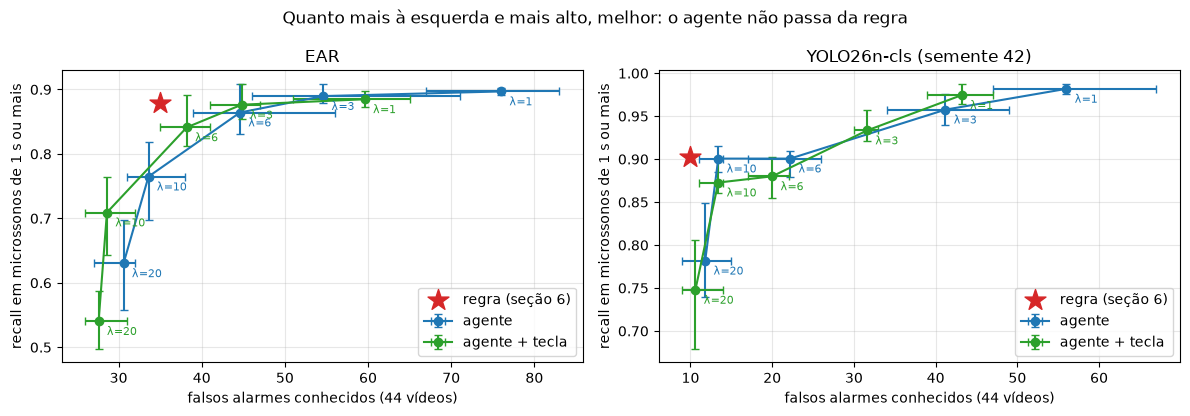

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
cores = {"agente": "tab:blue", "agente + tecla": "tab:green"}
for ax, nome in zip(axes, SINAIS_RL):
    for versao, cor in cores.items():
        g = res_rl[(res_rl.sinal == nome) & (res_rl["versão"] == versao)].groupby("λ")
        m, lo, hi = g.mean(numeric_only=True), g.min(numeric_only=True), g.max(numeric_only=True)
        ax.errorbar(m.falsos, m["recall 1 s+"],
                    xerr=[m.falsos - lo.falsos, hi.falsos - m.falsos],
                    yerr=[m["recall 1 s+"] - lo["recall 1 s+"], hi["recall 1 s+"] - m["recall 1 s+"]],
                    fmt="o-", color=cor, capsize=3, label=versao)
        for lam, r in m.iterrows():
            ax.annotate(f"λ={lam}", (r.falsos, r["recall 1 s+"]), textcoords="offset points", xytext=(6, -10),
                        fontsize=8, color=cor)
    r = res_regra[nome]
    ax.scatter(r["falsos"], r["recall 1 s+"], marker="*", s=250, color="tab:red", zorder=5, label="regra (seção 6)")
    ax.set_xlabel("falsos alarmes conhecidos (44 vídeos)"); ax.set_ylabel("recall em microssonos de 1 s ou mais")
    ax.set_title(nome); ax.grid(alpha=0.3); ax.legend(loc="lower right")
plt.suptitle("Quanto mais à esquerda e mais alto, melhor: o agente não passa da regra")
plt.tight_layout(); plt.show()

### 7.2 O que o agente aprendeu

A tabela de um agente treinado nos 44 vídeos (EAR, λ = 6, semente 42) vira um mapa: cada célula é uma situação, e a cor é a ação escolhida. O mapa mostra só as situações sem aviso nos últimos 30 s, que são a grande maioria. Situações que o agente nunca viu ficam em "esperar", porque é o empate da tabela, e o piso de 3 s cobre esses casos.

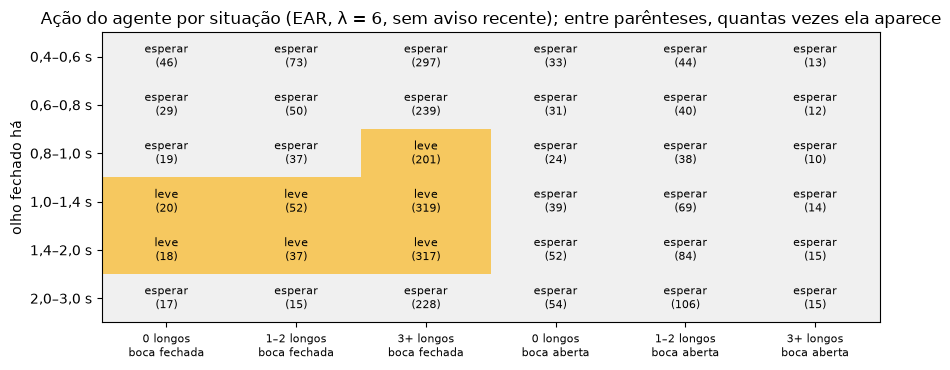

decisões nos 44 vídeos (sem aviso recente): 2,707 | situações que aparecem: 36 de 36 | trechos fechados de 0,4 s ou mais: 506


In [36]:
Q_mapa = treinar_agente(dados_rl["EAR"], recompensas(6), SEMENTE)

# quantas vezes cada situação aparece nos 44 vídeos (sem aviso recente)
visitas = np.zeros(N_ESTADOS, int)
for d in dados_rl["EAR"].values():
    for a, b in d["trechos"]:
        n_longos = int(((d["fim_longos"] < a) & (d["fim_longos"] >= a - JANELA_HIST)).sum())
        for n in range(INICIO, min(b - a + 1, PISO - 1) + 1, PASSO):
            visitas[estado(n / FPS, n_longos, d["boca"][a + n - 1], False)] += 1

faixas = ["0,4–0,6 s", "0,6–0,8 s", "0,8–1,0 s", "1,0–1,4 s", "1,4–2,0 s", "2,0–3,0 s"]
colunas = [(h, b) for b in (0, 1) for h in range(3)]
nomes_col = [f"{['0', '1–2', '3+'][h]} longos\n{'boca aberta' if b else 'boca fechada'}" for h, b in colunas]
idx_mapa = [[((d * 3 + h) * 2 + b) * 2 for h, b in colunas] for d in range(6)]
acao = np.array([[int(np.argmax(Q_mapa[s])) if visitas[s] else -1 for s in linha] for linha in idx_mapa])
n_vis = np.array([[visitas[s] for s in linha] for linha in idx_mapa])

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.imshow(acao, cmap=ListedColormap(["#dddddd", "#f0f0f0", "#f6c85f", "#d1495b"]), vmin=-1, vmax=2, aspect="auto")
rotulos = {-1: "não visto", 0: "esperar", 1: "leve", 2: "forte"}
for i in range(acao.shape[0]):
    for j in range(acao.shape[1]):
        ax.text(j, i, f"{rotulos[acao[i, j]]}\n({n_vis[i, j]})", ha="center", va="center", fontsize=8)
ax.set_yticks(range(6), faixas); ax.set_xticks(range(len(colunas)), nomes_col, fontsize=8)
ax.set_ylabel("olho fechado há")
ax.set_title("Ação do agente por situação (EAR, λ = 6, sem aviso recente); entre parênteses, quantas vezes ela aparece")
plt.tight_layout(); plt.show()
print(f"decisões nos 44 vídeos (sem aviso recente): {visitas.sum():,} | situações que aparecem: {(visitas > 0).sum()} de "
      f"{N_ESTADOS // 2} | trechos fechados de 0,4 s ou mais: {sum(len(d['trechos']) for d in dados_rl['EAR'].values())}")

### Observações do agente

- **O agente não superou a regra.** Em nenhum λ ele fica ao mesmo tempo à esquerda e acima da estrela. Com o YOLO, no nível de falsos alarmes mais próximo do da regra (cerca de 12, λ = 20), ele acha 129 de 165 microssonos, contra 149 da regra. Com o EAR, no mesmo nível (cerca de 34, λ = 10), acha 126 contra 145.
- **O que ele aprendeu faz sentido** (mapa acima). Ele nunca avisa com a boca aberta, ou seja, redescobriu sozinho o filtro de bocejo. Avisa a partir de 1 s, como o Euro NCAP. E avisa mais cedo, com 0,8 s, quando a pessoa já teve 3 ou mais fechamentos longos no último minuto, o único uso do histórico que a regra não tem. Entre 2 e 3 s, com a boca fechada, ele volta a esperar, provavelmente porque só chega ali sem aviso o trecho que passou a maior parte do tempo de boca aberta. O piso de 3 s cobre esses casos.
- **Menos avisos fortes à toa, em troca de mais avisos leves.** A regra só dá aviso forte. Com o YOLO e λ = 10, o agente acha quase o mesmo que a regra (148,6 microssonos, contra 149) e dá só 2,2 falsos alarmes fortes, contra 10 da regra. Em troca, dá mais falsos alarmes no total (13,4), quase todos leves.
- **A tecla "foi alarme falso" vai na direção certa, mas o efeito varia:** no mesmo λ, ela tira até 23% dos falsos alarmes, e com o YOLO e λ = 10 não tira nenhum. O custo fica entre 1 e 6 acertos, mas chega a 9 e 15 com o EAR e λ = 10 e 20. Os vídeos duram de 20 s a 2 min, então cada pessoa dá poucos retornos. O efeito real só apareceria com uso longo da mesma pessoa.
- **Por que a regra ganha:** ela já usa as duas informações que mais importam (tempo de olho fechado e boca), e o agente aprende com cerca de 500 trechos fechados de 0,4 s ou mais. Os resultados também variam bastante entre sementes (barras do gráfico).
- **Os números do YOLO dependem da máquina.** Com o mesmo código e as mesmas sementes, uma execução numa RTX 4060 deu, com λ = 10, 143 microssonos e 15,4 falsos alarmes (4,2 fortes). A execução gravada aqui, numa RTX 3050, deu 148,6 e 13,4 (2,2 fortes). Os números do EAR e da regra não mudaram. A explicação provável é que a GPU arredonda as contas do YOLO de forma um pouco diferente, alguns frames perto do limiar trocam de lado, e o treino do agente amplifica essa diferença. Por isso, diferenças de poucos microssonos entre o agente e a regra não devem ser lidas como reais.
- **O piso de 3 s é barato com o YOLO e caro com o EAR.** Por construção, ele só dispara em trechos de 3 s ou mais em que o filtro de bocejo segurou o aviso. Com o YOLO, isso acontece 2 vezes nos 44 vídeos. Com o EAR, que usa um limiar de olho mais baixo, acontece 22 vezes, e por isso a regra do EAR aqui tem 21 alarmes (falsos ou sem rótulo) a mais do que na seção 6.2. Para manter o piso, que protege quem dorme de boca aberta, o YOLO é o sinal certo.
- **Limites:** os mesmos das seções anteriores (base sem identificador de motorista, buracos longos sem rótulo, vídeos que parecem seguir roteiro). Além disso, o vídeo gravado não reage ao aviso, então o agente aprende quando avisar, mas não o efeito do aviso.

**Decisão sugerida:** para a demo, manter a regra (YOLO, T = 1 s, filtro de bocejo e piso de 3 s ignorando o filtro). O agente fica como experimento, que mostra que RL redescobre as regras sensatas e usa o histórico da pessoa, mas que precisa de mais dados por pessoa para ganhar da regra.

## 8. Modelo temporal: sonolência em 1 minuto

A regra das seções 2 a 6 avisa quando o olho **já está fechado**. A sonolência aparece antes, num padrão de minutos: piscadas mais lentas e mais frequentes, olho meio fechado por mais tempo e mais bocejos. Esta seção testa se um modelo que olha **1 minuto inteiro** de sinais do olho e da boca separa uma pessoa alerta de uma sonolenta, em pessoas que ele nunca viu.

O modelo não vê a imagem. Ele recebe a série de números que o pipeline já produz (P(olho fechado) do YOLO, EAR e abertura da boca) e devolve P(sonolento). Assim ele não consegue decorar rosto, roupa ou fundo, e a parte de imagem continua sendo a das seções 3 a 5.

Comparamos quatro modelos, do mais simples ao mais complexo, com as mesmas dobras por pessoa:

| Modelo | Aprende? | Entrada |
|---|---|---|
| PERCLOS com limiar | Só o limiar | Fração do minuto com olho fechado |
| Regressão logística | Sim | Atributos por minuto: PERCLOS, piscadas, duração dos fechamentos, bocejos |
| GRU, do zero | Sim | Série de 600 frames |
| TCN, do zero | Sim | Série de 600 frames |

A GRU e a TCN só valem a pena se superarem a regressão logística.

**Dados: UTA-RLDD recortado** ([Kaggle](https://www.kaggle.com/datasets/mathiasviborg/uta-rldd-videos-cropped-by-faces), CC BY-NC-SA 4.0). São vídeos de 60 pessoas, gravados pelos próprios participantes, com o rosto recortado em 224×224 e a 10 fps, em duas classes: **alerta** e **sonolento**. O rótulo é autorrelatado e vale para o vídeo inteiro, e cada classe foi gravada em outro dia. Falta a classe sonolenta da pessoa 42.

- A base corta a mesma filmagem em clipes de 5, 10, 20, 30 e 60 s. Usamos só a pasta `len60`: 1.136 clipes de 1 min (1,2 GB, em vez de 6,7 GB).
- Os clipes `_0`, `_1`, `_2`… de um vídeo são minutos seguidos: o último frame de um clipe difere do primeiro do seguinte em 2,4 níveis de cinza (mediana), contra 25,2 entre clipes não seguidos.
- 10 clipes têm de 516 a 597 frames. Todos são o último clipe do vídeo.

### 8.1 Extração dos sinais

Cada clipe passa pelo mesmo MediaPipe e pelo mesmo recorte de olho da seção 2, e o recorte vai para o YOLO da semente 42, o mesmo da seção 6.2. O resultado é uma série de 600 × 6 por clipe: P(fechado) e EAR de cada olho, abertura da boca e rosto encontrado. Os frames sem rosto, e os que faltam nos clipes curtos, ficam como NaN.

A extração leva cerca de 2,5 h na CPU de um Apple M5 (8 s por clipe) e fica em cache por pessoa em `data/cache/rldd/`. Se for interrompida, continua de onde parou. Como cada pessoa é independente, rodamos `extrair_pessoa` em 4 processos, cada um com um quarto das pessoas, e esta célula só junta o cache. Os recortes de olho não são guardados (seriam cerca de 5,5 GB), então trocar o classificador exige extrair de novo.

In [37]:
RLDD = "mathiasviborg/uta-rldd-videos-cropped-by-faces"
PASTA_RLDD = DADOS / "kagglehub/datasets" / RLDD / "versions/1/UTA-RLDD Face Cropped Video/len60"
FPS_RLDD = 10
N_RLDD = 60 * FPS_RLDD          # 600 frames por clipe de 1 min
CANAIS = ["p_fech_e", "p_fech_d", "ear_e", "ear_d", "boca", "rosto"]
CACHE_RLDD = CACHE / "rldd"
CACHE_RLDD.mkdir(exist_ok=True)


def ler_json(url, tentativas=6):
    # a API do Kaggle às vezes devolve 404 ou fecha a conexão no meio da paginação: tenta de novo com espera crescente
    import http.client
    import urllib.error
    for k in range(tentativas):
        try:
            return json.load(urllib.request.urlopen(url, timeout=60))
        except (urllib.error.URLError, http.client.HTTPException, ConnectionError, TimeoutError) as erro:
            temporario = not isinstance(erro, urllib.error.HTTPError) or erro.code in (404, 429, 500, 502, 503, 504)
            if not temporario or k == tentativas - 1:
                raise
            time.sleep(2 ** k)


def arquivos_len60():
    # a base inteira tem 6,7 GB, mas os cortes de 5 a 60 s são a mesma filmagem: basta a pasta len60
    # o token da próxima página tem caracteres como + / =, então vai codificado na URL
    import urllib.parse
    nomes, token = [], ""
    while True:
        url = f"https://www.kaggle.com/api/v1/datasets/list/{RLDD}?pageSize=200" + (f"&pageToken={urllib.parse.quote(token, safe='')}" if token else "")
        pagina = ler_json(url)
        nomes += [f["nameNullable"] for f in pagina["datasetFiles"] if "/len60/" in f["nameNullable"]]
        token = pagina.get("nextPageTokenNullable")
        if not token:
            return nomes


def baixar_rldd(nome, tentativas=5):
    import kagglehub
    for k in range(tentativas):
        try:
            return kagglehub.dataset_download(RLDD, path=nome)
        except Exception:
            if k == tentativas - 1:
                raise
            time.sleep(2 ** k)


# a lista fica em cache; se o download parar no meio, a próxima execução baixa só o que falta
ARQ_LISTA_RLDD = CACHE_RLDD / "arquivos_len60.json"
if ARQ_LISTA_RLDD.exists() or not PASTA_RLDD.exists():
    if not ARQ_LISTA_RLDD.exists():
        ARQ_LISTA_RLDD.write_text(json.dumps(arquivos_len60()))
    raiz_rldd = PASTA_RLDD.parent.parent
    faltam_rldd = [n for n in json.loads(ARQ_LISTA_RLDD.read_text()) if not (raiz_rldd / n).exists()]
    if faltam_rldd:
        from concurrent.futures import ThreadPoolExecutor
        with ThreadPoolExecutor(8) as ex:
            list(ex.map(baixar_rldd, faltam_rldd))


def extrair_clipe(detector, arq):
    # um valor por frame em cada canal; NaN sem rosto e depois do fim de clipes curtos
    serie = np.full((N_RLDD, len(CANAIS)), np.nan, np.float32)
    olhos = np.zeros((N_RLDD, 2, TAM, TAM), np.uint8)
    cap = cv2.VideoCapture(str(arq))
    n = 0
    while n < N_RLDD:
        ok, bgr = cap.read()
        if not ok:
            break
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        p = pontos_do_rosto(detector, rgb)
        serie[n, 5] = p is not None
        if p is not None:
            cinza = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
            olhos[n, 0] = recortar_olho(cinza, p[CONTORNO_E])
            olhos[n, 1] = recortar_olho(cinza, p[CONTORNO_D])
            serie[n, 2:5] = ear(p, EAR_E), ear(p, EAR_D), abertura_boca(p[:478])
        n += 1
    rosto = serie[:n, 5] == 1
    if rosto.any():
        p_olhos = prever(yolo_rldd, olhos[:n][rosto].reshape(-1, TAM, TAM), norm=normalizar_yolo).reshape(-1, 2)
        serie[np.flatnonzero(rosto), :2] = p_olhos
    return serie, n


def extrair_pessoa(detector, pessoa):
    # um arquivo por pessoa no cache, para retomar de onde parou se a extração for interrompida
    arq_cache = CACHE_RLDD / f"pessoa_{pessoa}.npz"
    if arq_cache.exists():
        return
    t0 = time.time()
    clipes = sorted(PASTA_RLDD.glob(f"{pessoa}/*/*.mp4"))
    series, meta = [], []
    for arq in clipes:
        serie, n = extrair_clipe(detector, arq)
        _, classe, clipe = arq.stem.split("_")
        series.append(serie)
        meta.append((pessoa, int(classe), int(clipe), n))
    np.savez(arq_cache, series=np.stack(series), meta=np.array(meta, dtype=object))
    print(f"pessoa {pessoa}: {len(clipes)} clipes em {time.time() - t0:.0f} s")


def extrair_rldd():
    pessoas_rldd = sorted(p.name for p in PASTA_RLDD.iterdir() if p.is_dir())
    if not all((CACHE_RLDD / f"pessoa_{p}.npz").exists() for p in pessoas_rldd):
        detector = criar_detector()
        for pessoa in pessoas_rldd:
            extrair_pessoa(detector, pessoa)

    partes = [np.load(a, allow_pickle=True) for a in sorted(CACHE_RLDD.glob("pessoa_*.npz"))]
    series = np.concatenate([p["series"] for p in partes])
    meta = pd.DataFrame(np.concatenate([p["meta"] for p in partes]), columns=["pessoa", "classe", "clipe", "frames"])
    meta = meta.astype({"classe": int, "clipe": int, "frames": int})
    meta["sonolento"] = (meta.classe == 10).astype(int)
    return series, meta


# P(fechado) vem do YOLO da semente 42, o mesmo da seção 6.2
yolo_rldd = modelos["YOLO26n-cls", SEMENTE]
series_rldd, meta_rldd = extrair_rldd()
print(f"{len(meta_rldd)} clipes de {meta_rldd.pessoa.nunique()} pessoas | "
      f"rosto em {np.nanmean(series_rldd[:, :, 5]):.1%} dos frames | "
      f"{(meta_rldd.frames < N_RLDD).sum()} clipes com menos de {N_RLDD} frames")

1136 clipes de 60 pessoas | rosto em 99.9% dos frames | 10 clipes com menos de 600 frames


### 8.2 Análise inicial: o sinal muda com o sono?

Antes de treinar qualquer modelo, esta parte responde a três perguntas: a extração funcionou, os atributos simples separam alerta de sonolento, e quantos falsos alarmes a regra das seções 6 e 7 dá em pessoas acordadas.

Os atributos foram **definidos antes de olhar as classes**, para que a escolha não favoreça a avaliação da seção 8.3. Cada clipe tem 1 minuto, então as contagens já são por minuto.

| Atributo | Definição | Esperado no sonolento |
|---|---|---|
| PERCLOS | fração dos frames com rosto em que P(fechado) ≥ 0,5 | sobe |
| Piscadas | trechos fechados de até 0,5 s | sobe |
| Duração mediana | mediana dos trechos fechados, em segundos | sobe |
| Fechamentos de 1 s ou mais | trechos que dispararam a regra de T = 1 s | sobe |
| Bocejos | bocejos detectados pelo filtro da seção 6 | sobe |
| EAR médio | média do minuto | cai |

A 10 fps, cada frame vale 0,1 s. Os parâmetros da seção 6, contados em frames a 25 fps, são convertidos pelo tempo: juntar trechos fechados separados por 0,12 s vira 1 frame, e a margem do bocejo, de 1 s, vira 10 frames. O PERCLOS clássico conta o olho mais de 80% fechado. Aqui usamos P(fechado) ≥ 0,5 como aproximação.

Os 10 clipes curtos ficam fora dos atributos, para que todos tenham 600 frames.

In [38]:
from sklearn.metrics import roc_auc_score
from scipy.stats import wilcoxon

LIM_FECH = 0.5     # P(fechado) a partir do qual o frame conta como fechado nos atributos


def em_rldd(frames):
    # parâmetro em frames a 25 fps (seções 2 a 7) -> frames a 10 fps, pelo mesmo tempo
    return max(1, int(round(frames * FPS_RLDD / FPS)))


BURACO_RLDD = em_rldd(BURACO_FECH)
FILTRO_RLDD = {"lim": FILTRO["lim"], "persistencia": em_rldd(FILTRO["persistencia"]), "margem": em_rldd(FILTRO["margem"])}


def tabela_rldd(s):
    # a série de um clipe no formato das linhas do tempo da seção 2
    return pd.DataFrame({"p_fech": s[:, :2].mean(axis=1), "ear": s[:, 2:4].mean(axis=1),
                         "boca": s[:, 4], "rosto": s[:, 5] == 1})


def atributos(s):
    tl = tabela_rldd(s)
    rosto = tl.rosto.values
    fechado = (tl.p_fech >= LIM_FECH).values
    dur = np.array([(b - a + 1) / FPS_RLDD for a, b in unir(trechos(fechado), BURACO_RLDD)])
    return {"PERCLOS": fechado[rosto].mean() if rosto.any() else np.nan,
            "piscadas": int((dur <= 0.5).sum()),
            "duração mediana (s)": np.median(dur) if len(dur) else 0.0,
            "fechamentos de 1 s+": int((dur >= T_ALERTA).sum()),
            "bocejos": len(trechos(bocejo_ativo(tl, **FILTRO_RLDD))),
            "EAR médio": tl.ear.mean(),
            "rosto": rosto.mean(),
            "EAR de olho aberto": tl.ear[rosto & ~fechado].median()}


completos = (meta_rldd.frames == N_RLDD).values
attr = pd.concat([meta_rldd[completos].reset_index(drop=True),
                  pd.DataFrame([atributos(s) for s in series_rldd[completos]])], axis=1)
attr["classe_nome"] = attr.sonolento.map({0: "alerta", 1: "sonolento"})
print(f"{len(attr)} clipes completos ({completos.sum()} de {len(meta_rldd)}) | "
      f"{attr.pessoa.nunique()} pessoas | {attr.sonolento.sum()} sonolentos")
print(f"clipes com rosto em menos de 80% dos frames: {(attr.rosto < 0.8).sum()}")
attr.groupby("classe_nome")[["rosto", "PERCLOS", "piscadas", "EAR médio"]].describe().T.round(3)

1126 clipes completos (1126 de 1136) | 60 pessoas | 559 sonolentos
clipes com rosto em menos de 80% dos frames: 2


classe_nome       alerta  sonolento
rosto     count  567.000    559.000
          mean     1.000      0.998
          std      0.002      0.019
          min      0.970      0.695
          25%      1.000      1.000
          50%      1.000      1.000
          75%      1.000      1.000
          max      1.000      1.000
PERCLOS   count  567.000    559.000
          mean     0.021      0.117
          std      0.034      0.197
          min      0.000      0.000
          25%      0.002      0.015
          50%      0.007      0.047
          75%      0.026      0.133
          max      0.223      1.000
piscadas  count  567.000    559.000
          mean     7.496     12.233
          std      9.465      9.652
          min      0.000      0.000
          25%      1.000      5.000
          50%      4.000     10.000
          75%     11.000     18.000
          max     64.000     45.000
EAR médio count  567.000    559.000
          mean     0.247      0.214
          std      0.034      0.051
          min      0.166      0.015
          25%      0.225      0.187
          50%      0.246      0.215
          75%      0.267      0.249
          max      0.340      0.364

**Quanto cada atributo separa as classes.** Duas medidas, nenhuma treinada:

- **AUC** junta os clipes de todas as pessoas. Vale 0,5 quando o atributo não ajuda e 1 quando separa tudo. Abaixo de 0,5, o atributo é menor no sonolento.
- **Dentro da pessoa** compara a mediana de cada pessoa nas duas classes, só com quem tem as duas. É a fração de pessoas em que o sonolento ficou acima do alerta, com o teste de Wilcoxon pareado. Ela não depende das diferenças entre pessoas.

As duas últimas linhas são o **controle do dia de gravação**: o EAR de olho aberto mede o tamanho do olho na imagem, e a fração de rosto encontrado depende de luz e enquadramento. Nenhum dos dois deveria mudar com o sono.

In [39]:
ATRIBUTOS = ["PERCLOS", "piscadas", "duração mediana (s)", "fechamentos de 1 s+", "bocejos", "EAR médio"]
CONTROLES = ["EAR de olho aberto", "rosto"]

por_pessoa = attr.groupby(["pessoa", "sonolento"])[ATRIBUTOS + CONTROLES].median().unstack("sonolento").dropna()
linhas = {}
for a in ATRIBUTOS + CONTROLES:
    ok = attr[a].notna()
    dif = por_pessoa[a][1] - por_pessoa[a][0]
    linhas[a] = {"mediana alerta": attr.loc[attr.sonolento == 0, a].median(),
                 "mediana sonolento": attr.loc[attr.sonolento == 1, a].median(),
                 "AUC": roc_auc_score(attr.sonolento[ok], attr[a][ok]),
                 "pessoas com sonolento maior": (dif > 0).mean(),
                 "pessoas empatadas": (dif == 0).mean(),
                 "p (Wilcoxon)": wilcoxon(dif[dif != 0]).pvalue if (dif != 0).sum() > 0 else np.nan}
print(f"{len(por_pessoa)} pessoas com as duas classes")
pd.DataFrame(linhas).T.round(3)

59 pessoas com as duas classes


,mediana alerta,mediana sonolento,AUC,pessoas com sonolento maior,pessoas empatadas,p (Wilcoxon)
PERCLOS,0.007,0.047,0.774,0.915,0.017,0.000
piscadas,4.000,10.000,0.680,0.746,0.068,0.000
duração mediana (s),0.100,0.150,0.722,0.525,0.475,0.000
fechamentos de 1 s+,0.000,0.000,0.644,0.271,0.729,0.000
bocejos,0.000,0.000,0.560,0.102,0.898,0.031
EAR médio,0.246,0.215,0.295,0.169,0.000,0.000
EAR de olho aberto,0.251,0.229,0.352,0.271,0.000,0.000
rosto,1.000,1.000,0.485,0.000,1.000,NaN


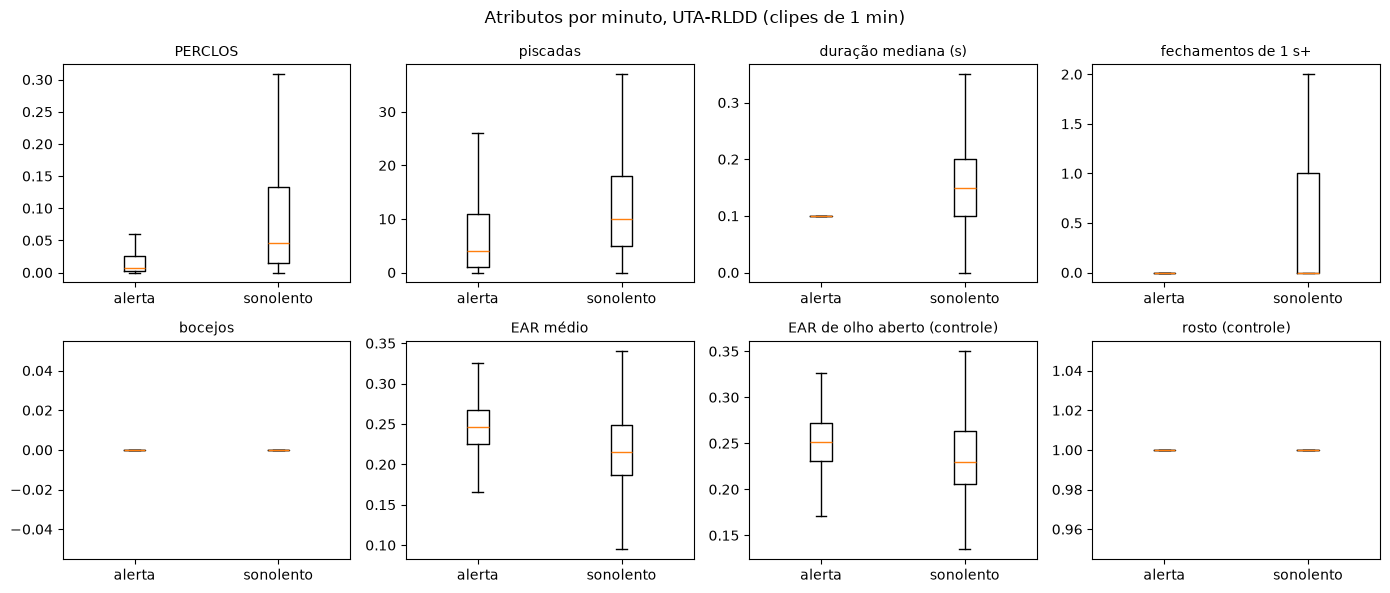

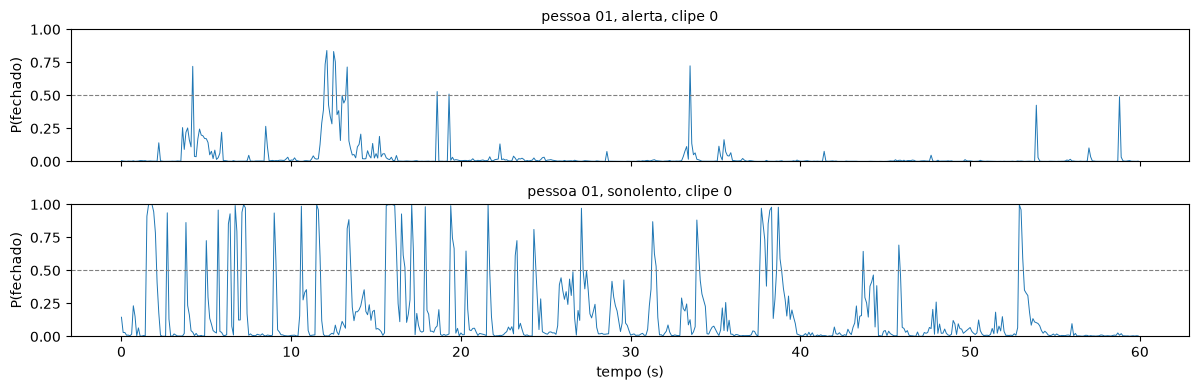

In [40]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, a in zip(axes.flat, ATRIBUTOS + CONTROLES):
    dados = [attr.loc[attr.sonolento == c, a].dropna() for c in (0, 1)]
    ax.boxplot(dados, tick_labels=["alerta", "sonolento"], showfliers=False)
    ax.set_title(a + (" (controle)" if a in CONTROLES else ""), fontsize=10)
plt.suptitle("Atributos por minuto, UTA-RLDD (clipes de 1 min)")
plt.tight_layout(); plt.show()

# um minuto da mesma pessoa nas duas classes
pessoa_ex = por_pessoa.index[0]
fig, axes = plt.subplots(2, 1, figsize=(12, 4), sharex=True)
for ax, c in zip(axes, (0, 1)):
    i = np.flatnonzero(completos & (meta_rldd.pessoa == pessoa_ex).values & (meta_rldd.sonolento == c).values)[0]
    tl = tabela_rldd(series_rldd[i])
    ax.plot(np.arange(N_RLDD) / FPS_RLDD, tl.p_fech, lw=0.7)
    ax.axhline(LIM_FECH, color="gray", ls="--", lw=0.8)
    ax.set_ylim(0, 1); ax.set_ylabel("P(fechado)")
    ax.set_title(f"pessoa {pessoa_ex}, {'sonolento' if c else 'alerta'}, clipe {meta_rldd.clipe[i]}", fontsize=10)
axes[-1].set_xlabel("tempo (s)")
plt.tight_layout(); plt.show()

**Falsos alarmes em pessoas acordadas.** A classe alerta do UTA-RLDD tem cerca de 9,5 horas de pessoas acordadas, com piscadas reais, o que o FL3D não tem. Aqui rodamos a regra da demo: YOLO da semente 42, T = 1 s, filtro de bocejo e piso de 3 s, com o limiar de olho escolhido na calibração do FL3D (seção 7). Os clipes de cada vídeo são minutos seguidos, então são emendados numa linha do tempo de cerca de 10 min por pessoa e classe, e um fechamento na virada do minuto não se perde.

Na classe sonolenta, os alarmes não são necessariamente falsos, porque a base não marca microssonos. Eles aparecem só para comparação. Os intervalos de 95% vêm de um bootstrap por pessoa.

In [41]:
LIM_REGRA = limiar_na_calibracao(COL_DETALHE["YOLO26n-cls (semente 42)"], AJ_FILTRO)
PISO_RLDD = int(3.0 * FPS_RLDD)


def avisos_regra(tl, lim):
    # a regra de rodar_regra (seção 7), em frames a 10 fps: alerta com filtro e piso de 3 s
    fechado = fechamento(tl, "p_fech", lim, filtro=FILTRO_RLDD)
    n = int(round(T_ALERTA * FPS_RLDD))
    avisos = [(a, b) for a, b in unir(trechos(fechado), BURACO_RLDD) if b - a + 1 >= n]
    todos = unir(trechos((tl.p_fech >= lim).fillna(False).values), BURACO_RLDD)
    piso = [(a, b) for a, b in todos
            if b - a + 1 >= PISO_RLDD and not any(ini <= b and fim >= a for ini, fim in avisos)]
    return len(avisos), len(piso)


alarmes = []
for (pessoa, sono), m in meta_rldd.sort_values("clipe").groupby(["pessoa", "sonolento"]):
    serie = np.concatenate([series_rldd[i, :n] for i, n in zip(m.index, m.frames)])
    regra, piso = avisos_regra(tabela_rldd(serie), LIM_REGRA)
    alarmes.append({"pessoa": pessoa, "sonolento": sono, "horas": len(serie) / FPS_RLDD / 3600,
                    "alarmes": regra + piso, "do piso": piso})
alarmes = pd.DataFrame(alarmes)


def taxa_com_intervalo(tab, n=2000):
    rng = np.random.default_rng(SEMENTE)
    a, h = tab.alarmes.values, tab.horas.values
    idx = rng.integers(0, len(a), (n, len(a)))
    return a.sum() / h.sum(), *np.percentile(a[idx].sum(axis=1) / h[idx].sum(axis=1), [2.5, 97.5])


resumo_alarmes = {}
for sono, tab in alarmes.groupby("sonolento"):
    taxa, inf, sup = taxa_com_intervalo(tab)
    resumo_alarmes["sonolento" if sono else "alerta"] = {
        "pessoas": len(tab), "horas": tab.horas.sum(), "alarmes": tab.alarmes.sum(), "do piso": tab["do piso"].sum(),
        "alarmes por hora": taxa, "IC95% inf.": inf, "IC95% sup.": sup,
        "pessoas sem alarme": (tab.alarmes == 0).mean(),
        "alarmes das 5 pessoas com mais": tab.alarmes.nlargest(5).sum() / max(tab.alarmes.sum(), 1)}
print(f"limiar de olho: {LIM_REGRA} | filtro a 10 fps: {FILTRO_RLDD} | piso: {PISO_RLDD} frames")
display(pd.DataFrame(resumo_alarmes).T.round(3))

# de quem são os alarmes na classe alerta
olho_aberto = attr[attr.sonolento == 0].groupby("pessoa")["EAR de olho aberto"].median()
print(f"EAR de olho aberto na classe alerta: mediana {olho_aberto.median():.3f} entre as pessoas")
(alarmes[alarmes.sonolento == 0].set_index("pessoa")[["alarmes", "horas"]]
 .join(olho_aberto).sort_values("alarmes", ascending=False).head(6).round(3))

limiar de olho: 0.4 | filtro a 10 fps: {'lim': 0.25, 'persistencia': 1, 'margem': 10} | piso: 30 frames


,pessoas,horas,alarmes,do piso,alarmes por hora,IC95% inf.,IC95% sup.,pessoas sem alarme,alarmes das 5 pessoas com mais
alerta,60.0,9.527,64.0,0.0,6.718,0.737,16.001,0.900,0.969
sonolento,59.0,9.395,594.0,3.0,63.224,40.786,87.580,0.339,0.411


EAR de olho aberto na classe alerta: mediana 0.252 entre as pessoas


,alarmes,horas,EAR de olho aberto
pessoa,,,
29,40,0.166,0.201
44,11,0.183,0.195
28,5,0.150,0.191
24,4,0.283,0.235
01,2,0.150,0.274
15,2,0.167,0.216


### Observações da análise inicial

- **A extração funcionou.** O MediaPipe achou o rosto em 99,9% dos frames, e só 2 dos 1.126 clipes completos ficam abaixo de 80%. Isso era esperado, porque a base já vem recortada no rosto.
- **O PERCLOS separa bem as classes.** A mediana vai de 0,7% do minuto com olho fechado no alerta para 4,7% no sonolento, com AUC de 0,77. Em 54 das 59 pessoas (92%), o sonolento fica acima do alerta. É um sinal forte para uma medida sem treino, e por isso uma linha de base difícil de superar.
- **As piscadas também ajudam.** São 4 por minuto no alerta e 10 no sonolento (AUC 0,68), com o sonolento acima em 75% das pessoas. O EAR médio cai no sonolento (AUC 0,30, ou 0,70 no sentido inverso).
- **A duração dos fechamentos esbarra nos 10 fps.** No alerta, o fechamento típico dura um único frame (0,1 s), o menor valor medível. Por isso 47% das pessoas empatam nesse atributo, embora a AUC seja de 0,72.
- **Fechamentos de 1 s ou mais e bocejos são raros nos dois casos,** com mediana zero por minuto. O bocejo quase não aparece nesta base (90% das pessoas empatam), então o filtro de bocejo quase não atua aqui.
- **O controle do dia de gravação é inconclusivo.** O rosto é encontrado em quase todos os frames nas duas classes, então essa medida não informa nada. O EAR de olho aberto é menor no sonolento em 73% das pessoas (AUC 0,35). Isso pode ser a pálpebra caída, que é um sinal de sono, ou uma diferença de câmera entre os dias, e os dados não separam as duas causas. Parte do sinal das seções seguintes pode vir do dia de gravação.

**Falsos alarmes em pessoas acordadas:**

- **A regra da demo dá 64 alarmes em 9,5 horas de pessoas alertas, ou 6,7 por hora** (IC95% de 0,7 a 16). É a primeira medida do projeto com piscadas reais, e confirma que T = 1 s segura a maioria delas: 54 das 60 pessoas (90%) não têm nenhum alarme.
- **Os alarmes se concentram em poucas pessoas.** Uma pessoa sozinha dá 40 dos 64 alarmes, e as 5 com mais alarmes somam 97%. As 3 primeiras têm EAR de olho aberto de 0,19 a 0,20, contra a mediana de 0,25. Na imagem, as duas primeiras parecem estar olhando para baixo ou com o olho mais fechado para a câmera. Um limiar único pune quem tem o olho aberto menor na imagem, seja pela anatomia, seja pelo ângulo da câmera ou pelo olhar. É o tipo de viés que a pesquisa aponta, e um argumento para a calibração por pessoa.
- **Na classe sonolenta, são 63 alarmes por hora, 9 vezes mais.** Esses alarmes não podem ser checados, porque a base não marca microssonos, mas mostram que a regra reage ao estado da pessoa, e não só às piscadas.
- **Limites:** são gravações feitas pelos próprios participantes, sem dirigir, a 10 fps e com o limiar escolhido no FL3D, à noite. A taxa não vale para uma viagem real e depende muito de quem está na câmera.

### 8.3 Linhas de base: PERCLOS e regressão logística

A partir daqui, todos os modelos usam **as mesmas 5 dobras por pessoa** (`GroupKFold`): cada pessoa fica inteira numa dobra, então nenhum modelo é testado em alguém que viu no treino. Em cada rodada, o modelo aprende em 4 dobras e prevê a quinta. No fim, cada clipe tem uma previsão feita sem ter visto aquela pessoa.

- **PERCLOS com limiar:** o único parâmetro é o limiar, escolhido nas dobras de treino (maior acurácia) e aplicado na dobra de teste. A AUC usa o PERCLOS direto, sem limiar.
- **Regressão logística:** os 6 atributos da seção 8.2, padronizados com a média e o desvio do treino. Os hiperparâmetros ficam nos padrões do scikit-learn, sem ajuste.

As métricas são:

- **AUC por clipe:** a métrica principal, que não depende de limiar.
- **Acurácia por clipe:** com o limiar de 0,5 na logística e o limiar do treino no PERCLOS.
- **Acurácia por vídeo:** a média das previsões dos clipes de cada gravação de cerca de 10 min. É a medida do artigo da base (65,2%), mas lá são 3 classes e outro protocolo, então serve só como referência.

O intervalo de 95% vem de um bootstrap por pessoa.

In [42]:
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

N_DOBRAS = 5
attr["dobra"] = -1
for k, (_, i_te) in enumerate(GroupKFold(N_DOBRAS).split(attr, attr.sonolento, attr.pessoa)):
    attr.loc[i_te, "dobra"] = k
y8 = attr.sonolento.values


def acuracia_por_video(p, limiar=0.5):
    # média das previsões dos clipes de cada vídeo (pessoa e classe)
    v = attr.assign(p=p).groupby(["pessoa", "sonolento"]).p.mean().reset_index()
    return ((v.p >= limiar) == v.sonolento).mean()


def metricas_8(p, limiar=0.5, n=2000):
    # p: previsões fora da dobra (uma por clipe); IC da AUC por bootstrap de pessoas
    rng = np.random.default_rng(SEMENTE)
    pessoas8 = attr.pessoa.unique()
    por_pessoa_idx = {q: np.flatnonzero(attr.pessoa.values == q) for q in pessoas8}
    aucs = []
    for _ in range(n):
        idx = np.concatenate([por_pessoa_idx[q] for q in rng.choice(pessoas8, len(pessoas8))])
        if len(np.unique(y8[idx])) == 2:
            aucs.append(roc_auc_score(y8[idx], p[idx]))
    return {"AUC": roc_auc_score(y8, p), "AUC IC95% inf.": np.percentile(aucs, 2.5),
            "AUC IC95% sup.": np.percentile(aucs, 97.5),
            "AUC média das dobras": np.mean([roc_auc_score(y8[attr.dobra == k], p[attr.dobra == k])
                                             for k in range(N_DOBRAS)]),
            "acurácia por clipe": ((p >= limiar) == y8).mean(), "acurácia por vídeo": acuracia_por_video(p, limiar)}


def limiar_acuracia(x, y):
    candidatos = np.unique(x)
    return candidatos[int(np.argmax([((x >= c) == y).mean() for c in candidatos]))]


# PERCLOS: o limiar sai do treino de cada dobra; a previsão vira 0 ou 1 para a acurácia
perclos = attr.PERCLOS.fillna(attr.PERCLOS.median()).values
pred_perclos = np.zeros(len(attr))
for k in range(N_DOBRAS):
    tr, te = attr.dobra != k, attr.dobra == k
    pred_perclos[te] = perclos[te] >= limiar_acuracia(perclos[tr], y8[tr])

# logística sobre os 6 atributos
prev_logistica = np.zeros(len(attr))
for k in range(N_DOBRAS):
    tr, te = attr.dobra != k, attr.dobra == k
    modelo_log = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression())
    modelo_log.fit(attr.loc[tr, ATRIBUTOS], y8[tr])
    prev_logistica[te] = modelo_log.predict_proba(attr.loc[te, ATRIBUTOS])[:, 1]

# previsões fora da dobra de cada modelo, para comparar com a GRU e a TCN na seção 8.4
previsoes_8 = {"PERCLOS com limiar": perclos, "Regressão logística": prev_logistica}
res_perclos = metricas_8(perclos)
res_perclos.update({"acurácia por clipe": (pred_perclos == y8).mean(), "acurácia por vídeo": acuracia_por_video(pred_perclos)})
tab_8 = pd.DataFrame({"PERCLOS com limiar": res_perclos, "Regressão logística": metricas_8(prev_logistica)}).T
print(f"{len(attr)} clipes, {attr.pessoa.nunique()} pessoas, {N_DOBRAS} dobras por pessoa | "
      f"clipes por dobra: {attr.dobra.value_counts().sort_index().tolist()}")
tab_8.round(3)

1126 clipes, 60 pessoas, 5 dobras por pessoa | clipes por dobra: [219, 225, 228, 228, 226]


,AUC,AUC IC95% inf.,AUC IC95% sup.,AUC média das dobras,acurácia por clipe,acurácia por vídeo
PERCLOS com limiar,0.774,0.729,0.826,0.783,0.673,0.655
Regressão logística,0.746,0.700,0.800,0.763,0.690,0.739


In [43]:
# pesos da logística treinada em todos os clipes, só para ler o que ela usa (atributos padronizados)
modelo_log = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression()).fit(attr[ATRIBUTOS], y8)
pd.Series(modelo_log[-1].coef_[0], index=ATRIBUTOS, name="peso").sort_values().round(3)

EAR médio             -0.404
piscadas              -0.061
bocejos                0.606
fechamentos de 1 s+    0.618
duração mediana (s)    1.214
PERCLOS                1.632
Name: peso, dtype: float64

### Observações das linhas de base

- **O PERCLOS sozinho chega a AUC de 0,77** (IC95% de 0,73 a 0,83), com 67% de acurácia por clipe e 66% por vídeo. É um número alto para uma medida que só aprende um limiar.
- **A logística não melhora a AUC:** fica em 0,75 (0,70 a 0,80), um pouco abaixo do PERCLOS, com intervalos sobrepostos. Ela acerta mais clipes (69%) e mais vídeos (74%, contra 66%), mas a diferença é pequena para 119 vídeos.
- **Os outros atributos repetem o PERCLOS.** Na logística treinada com tudo, os maiores pesos são do PERCLOS e da duração mediana. As piscadas ficam com peso quase zero, porque o PERCLOS já conta o tempo de olho fechado. O peso dos bocejos é alto, mas eles aparecem em poucos clipes, então esse peso é instável.
- **O artigo da base fez 65,2% por vídeo,** mas com 3 classes e outro protocolo, então não dá para comparar diretamente.
- **A meta da seção 8.4:** a GRU e a TCN precisam superar a AUC de cerca de 0,77 do PERCLOS, nas mesmas dobras e com comparação pareada por pessoa. Se não superarem, a conclusão é que o padrão de 1 minuto já está resumido no PERCLOS.

### 8.4 GRU e TCN

As duas redes recebem a série inteira do minuto, com 4 canais por frame: P(fechado) e EAR (média dos dois olhos), abertura da boca e rosto encontrado. Cada canal é padronizado com a média e o desvio do treino da dobra. Os frames sem rosto viram zero depois da padronização, e o canal de rosto avisa a rede.

| | GRU | TCN |
|---|---|---|
| Como lê | Frame a frame, com uma memória de 32 números | A janela inteira, com convoluções causais de tamanho 3 |
| Alcance | A sequência toda | Dilatações de 1 a 256 (9 camadas): 1.023 frames, mais que os 600 do clipe |
| Saída | Memória do último frame → camada linear | Média no tempo dos 16 canais → camada linear |
| Parâmetros | cerca de 3,7 mil | cerca de 6,6 mil |

As duas são treinadas **do zero**, porque não há rede pré-treinada para essa série. O tamanho, a taxa de aprendizado e o número de épocas foram fixados antes de olhar os resultados.

**Treino em cada dobra:** 20% das pessoas do treino viram validação, e o modelo guardado é o da época com menor perda na validação, como nas seções 3 e 5. O aumento de dados corta uma janela aleatória de 54 s e soma um ruído pequeno aos canais. O teste usa o minuto inteiro. São **5 sementes** por modelo, como na seção 5, e as previsões ficam em cache em `data/cache/rldd_temporal/`.

In [44]:
from sklearn.model_selection import GroupShuffleSplit

CANAIS_8 = ["P(fechado)", "EAR", "boca", "rosto"]
x8 = np.stack([series_rldd[completos, :, :2].mean(axis=2), series_rldd[completos, :, 2:4].mean(axis=2),
               series_rldd[completos, :, 4], series_rldd[completos, :, 5]], axis=2).astype(np.float32)
CACHE_TEMPORAL = CACHE / "rldd_temporal"
CACHE_TEMPORAL.mkdir(exist_ok=True)
JANELA_TREINO = 540          # 54 s no aumento de dados


class GRUSono(nn.Module):
    def __init__(self, canais=4, oculto=32):
        super().__init__()
        self.gru = nn.GRU(canais, oculto, batch_first=True)
        self.saida = nn.Linear(oculto, 1)

    def forward(self, x):                      # x: [lote, tempo, canais]
        _, h = self.gru(x)
        return self.saida(h[-1]).squeeze(1)


class BlocoCausal(nn.Module):
    # convolução que só olha o passado: o preenchimento fica todo à esquerda
    def __init__(self, ent, sai, dilatacao, k=3, dropout=0.1):
        super().__init__()
        self.pad = (k - 1) * dilatacao
        self.conv = nn.Conv1d(ent, sai, k, dilation=dilatacao)
        self.drop = nn.Dropout(dropout)
        self.atalho = nn.Conv1d(ent, sai, 1) if ent != sai else nn.Identity()

    def forward(self, x):
        y = self.drop(torch.relu(self.conv(nn.functional.pad(x, (self.pad, 0)))))
        return torch.relu(y + self.atalho(x))


class TCNSono(nn.Module):
    def __init__(self, canais=4, largura=16, niveis=9):
        super().__init__()
        self.blocos = nn.Sequential(*[BlocoCausal(canais if i == 0 else largura, largura, 2 ** i) for i in range(niveis)])
        self.saida = nn.Linear(largura, 1)

    def forward(self, x):                      # x: [lote, tempo, canais]
        y = self.blocos(x.transpose(1, 2))
        return self.saida(y.mean(dim=2)).squeeze(1)


MODELOS_8 = {"GRU": GRUSono, "TCN": TCNSono}
for nome, classe in MODELOS_8.items():
    print(f"{nome}: {sum(p.numel() for p in classe().parameters()):,} parâmetros".replace(",", "."))


def padronizar(x, ref):
    # média e desvio de cada canal nos frames com rosto do treino; o canal de rosto fica como está
    rosto = ref[:, :, 3] == 1
    media = np.array([np.nanmean(ref[:, :, c][rosto]) for c in range(3)], np.float32)
    desvio = np.array([np.nanstd(ref[:, :, c][rosto]) for c in range(3)], np.float32)
    z = x.copy()
    z[:, :, :3] = (z[:, :, :3] - media) / desvio
    return np.nan_to_num(z, nan=0.0)


def treinar_temporal(nome, semente, k, epocas=40, paciencia=8, lote=64, lr=3e-3):
    torch.manual_seed(semente); np.random.seed(semente)
    tr_idx = np.flatnonzero(attr.dobra.values != k)
    te_idx = np.flatnonzero(attr.dobra.values == k)
    sub_tr, sub_va = next(GroupShuffleSplit(1, test_size=0.2, random_state=semente)
                          .split(tr_idx, groups=attr.pessoa.values[tr_idx]))
    i_tr, i_va = tr_idx[sub_tr], tr_idx[sub_va]
    z = padronizar(x8, x8[i_tr])
    x_tr, y_tr = torch.from_numpy(z[i_tr]), torch.from_numpy(y8[i_tr]).float()
    x_va, y_va = torch.from_numpy(z[i_va]), torch.from_numpy(y8[i_va]).float()

    modelo = MODELOS_8[nome]()
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=1e-4)
    perda_fn = nn.BCEWithLogitsLoss()
    melhor, melhor_perda, melhor_pesos, sem_melhora = 0, np.inf, None, 0
    for ep in range(1, epocas + 1):
        modelo.train()
        for j in torch.randperm(len(x_tr)).split(lote):
            ini = np.random.randint(0, N_RLDD - JANELA_TREINO + 1)
            xb = x_tr[j, ini:ini + JANELA_TREINO].clone()
            xb[:, :, :3] += 0.05 * torch.randn_like(xb[:, :, :3])
            perda = perda_fn(modelo(xb), y_tr[j])
            opt.zero_grad(); perda.backward(); opt.step()
        modelo.eval()
        with torch.no_grad():
            perda_va = perda_fn(modelo(x_va), y_va).item()
        if perda_va < melhor_perda:
            melhor, melhor_perda, sem_melhora = ep, perda_va, 0
            melhor_pesos = {n: v.clone() for n, v in modelo.state_dict().items()}
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                break
    modelo.load_state_dict(melhor_pesos)
    modelo.eval()
    with torch.no_grad():
        p = torch.sigmoid(modelo(torch.from_numpy(z[te_idx]))).numpy()
    return te_idx, p, melhor


def prever_temporal(nome, semente):
    # previsão fora da dobra para todos os clipes, com cache por modelo e semente
    arq = CACHE_TEMPORAL / f"{nome.lower()}_s{semente}.npz"
    if arq.exists():
        salvo = np.load(arq)
        return salvo["p"], salvo["epocas"]
    p, epocas_k = np.zeros(len(attr)), []
    for k in range(N_DOBRAS):
        te_idx, p_k, ep = treinar_temporal(nome, semente, k)
        p[te_idx] = p_k
        epocas_k.append(ep)
    np.savez(arq, p=p, epocas=np.array(epocas_k))
    return p, np.array(epocas_k)

GRU: 3.681 parâmetros
TCN: 6.577 parâmetros


In [45]:
prev_temporal, epocas_temporal = {}, {}
for nome in MODELOS_8:
    for s in SEMENTES:
        t0 = time.time()
        prev_temporal[nome, s], epocas_temporal[nome, s] = prever_temporal(nome, s)
        print(f"{nome}, semente {s}: melhor época por dobra {epocas_temporal[nome, s].tolist()} | {time.time() - t0:.0f} s")

GRU, semente 42: melhor época por dobra [20, 38, 20, 3, 40] | 0 s
GRU, semente 1: melhor época por dobra [13, 16, 10, 36, 11] | 0 s
GRU, semente 2: melhor época por dobra [17, 38, 31, 8, 1] | 0 s
GRU, semente 3: melhor época por dobra [18, 17, 40, 15, 7] | 0 s
GRU, semente 4: melhor época por dobra [35, 3, 34, 30, 2] | 0 s
TCN, semente 42: melhor época por dobra [7, 22, 9, 6, 12] | 0 s
TCN, semente 1: melhor época por dobra [1, 10, 25, 35, 1] | 0 s
TCN, semente 2: melhor época por dobra [1, 21, 40, 1, 16] | 0 s
TCN, semente 3: melhor época por dobra [3, 3, 35, 4, 3] | 0 s
TCN, semente 4: melhor época por dobra [7, 1, 3, 20, 35] | 0 s


**Comparação.** Para cada modelo, as métricas são a média e o desvio das 5 sementes, como na seção 5. A comparação com as linhas de base é pareada: o bootstrap sorteia pessoas, recalcula a AUC de cada semente e do PERCLOS ou da logística nas mesmas pessoas e guarda a diferença média. Se o intervalo de 95% não inclui zero, a diferença é conclusiva.

In [46]:
def dif_auc(p_modelo, p_base, n=2000):
    # listas de previsões, uma por semente (a linha de base sem semente é uma lista de um item);
    # compara a AUC média de cada lado nas mesmas pessoas sorteadas
    rng = np.random.default_rng(SEMENTE)
    pessoas8 = attr.pessoa.unique()
    idx_p = {q: np.flatnonzero(attr.pessoa.values == q) for q in pessoas8}
    difs = []
    for _ in range(n):
        idx = np.concatenate([idx_p[q] for q in rng.choice(pessoas8, len(pessoas8))])
        if len(np.unique(y8[idx])) < 2:
            continue
        difs.append(np.mean([roc_auc_score(y8[idx], p[idx]) for p in p_modelo])
                    - np.mean([roc_auc_score(y8[idx], p[idx]) for p in p_base]))
    centro = np.mean([roc_auc_score(y8, p) for p in p_modelo]) - np.mean([roc_auc_score(y8, p) for p in p_base])
    return centro, *np.percentile(difs, [2.5, 97.5])


linhas = {}
for nome in MODELOS_8:
    por_semente = pd.DataFrame([metricas_8(prev_temporal[nome, s]) for s in SEMENTES])
    linhas[nome] = {f"{m} (média)": por_semente[m].mean() for m in ["AUC", "acurácia por clipe", "acurácia por vídeo"]}
    linhas[nome] |= {"AUC (desvio entre sementes)": por_semente.AUC.std()}
for nome, p in previsoes_8.items():
    r = tab_8.loc[nome]
    linhas[nome] = {"AUC (média)": r.AUC, "acurácia por clipe (média)": r["acurácia por clipe"],
                    "acurácia por vídeo (média)": r["acurácia por vídeo"], "AUC (desvio entre sementes)": 0.0}
print("5 dobras por pessoa; GRU e TCN com média de 5 sementes")
display(pd.DataFrame(linhas).T.round(3))

comparacoes = {}
for nome in MODELOS_8:
    ps = [prev_temporal[nome, s] for s in SEMENTES]
    for base, p_base in previsoes_8.items():
        d, inf, sup = dif_auc(ps, [p_base])
        comparacoes[f"{nome} - {base}"] = {"dif. AUC": d, "IC95% inf.": inf, "IC95% sup.": sup}
d, inf, sup = dif_auc([prev_temporal["TCN", s] for s in SEMENTES], [prev_temporal["GRU", s] for s in SEMENTES])
comparacoes["TCN - GRU"] = {"dif. AUC": d, "IC95% inf.": inf, "IC95% sup.": sup}
pd.DataFrame(comparacoes).T.round(3)

5 dobras por pessoa; GRU e TCN com média de 5 sementes


,AUC (média),acurácia por clipe (média),acurácia por vídeo (média),AUC (desvio entre sementes)
GRU,0.750,0.702,0.746,0.009
TCN,0.754,0.696,0.719,0.014
PERCLOS com limiar,0.774,0.673,0.655,0.000
Regressão logística,0.746,0.690,0.739,0.000


,dif. AUC,IC95% inf.,IC95% sup.
GRU - PERCLOS com limiar,-0.024,-0.059,0.012
GRU - Regressão logística,0.005,-0.024,0.033
TCN - PERCLOS com limiar,-0.020,-0.073,0.029
TCN - Regressão logística,0.008,-0.031,0.044
TCN - GRU,0.004,-0.028,0.034


### Observações da GRU e da TCN

| 5 dobras por pessoa | AUC | Acurácia por clipe | Acurácia por vídeo |
|---|---|---|---|
| PERCLOS com limiar | 0,774 | 67,3% | 65,5% |
| Regressão logística | 0,746 | 69,0% | 73,9% |
| GRU (5 sementes) | 0,750 ± 0,009 | 70,2% | 74,6% |
| TCN (5 sementes) | 0,754 ± 0,014 | 69,6% | 71,9% |

- **Nem a GRU nem a TCN superaram o PERCLOS.** Na AUC, ficam 0,024 e 0,020 abaixo, com intervalos de -0,059 a +0,012 e de -0,073 a +0,029. As diferenças não são conclusivas, mas também não há sinal de ganho.
- **Contra a logística, empatam na prática** (+0,005 e +0,008, com intervalos que incluem zero), e a TCN empata com a GRU (+0,004).
- **Na acurácia, a ordem muda.** A GRU acerta mais clipes e vídeos que o PERCLOS, que perde acurácia porque um único limiar serve mal a pessoas diferentes. Nenhum modelo vence nas três medidas, e as diferenças são de poucos clipes.
- **As redes aprendem pouco além do começo.** A melhor época varia de 1 a 40 entre dobras e sementes, e em várias dobras a melhor perda de validação veio nas primeiras épocas. Com cerca de 9 pessoas na validação de cada dobra, essa escolha é ruidosa. Não ajustamos tamanho, taxa ou épocas olhando estes resultados, para não tornar a comparação otimista.
- **Conclusão:** com estes sinais e esta base, o padrão de 1 minuto que distingue alerta de sonolento já está resumido no PERCLOS. A GRU e a TCN não acrescentam informação, o que repete o que [Ajayi et al.](https://pmc.ncbi.nlm.nih.gov/articles/PMC13667639/) encontraram com EAR, como a pesquisa já indicava. Para o produto, o aviso de sonolência mais simples e defensável é o PERCLOS do último minuto.
- **Limites:** o rótulo é autorrelatado e vale para o vídeo inteiro, cada classe foi gravada num dia diferente (seção 8.2), a 10 fps a duração das piscadas perde resolução, e a janela é de 1 minuto. Janelas mais longas ou a linha de base por pessoa, deixada para a próxima etapa, podem mudar esse resultado.

### 8.5 Mais sinais do rosto: cabeça, expressões e transformer

A seção 8.4 mostrou que, com 4 sinais do olho e da boca, a GRU e a TCN não passam do PERCLOS. Uma explicação possível é a entrada pobre: o PERCLOS já resume quase tudo o que P(fechado), EAR e boca dizem. Esta seção dá às redes sinais que o PERCLOS não tem, o movimento da cabeça e as expressões do rosto, e testa também um transformer, como a organização recomendou.

O protocolo foi fixado antes de qualquer treino, em [`docs/protocolo_8_5.md`](docs/protocolo_8_5.md), aprovado em 07/11/2026: canais, modelos, hiperparâmetros, métrica e critério. São duas perguntas:

1. **Os sinais novos ajudam?** Logística-16 contra Logística-6, e GRU-14 contra GRU-4.
2. **A rede ajuda?** Cada rede de 14 canais contra a Logística-16, que recebe os mesmos sinais resumidos por minuto. O deep learning se justifica se o intervalo de 95% da diferença de AUC ficar acima de zero.

**Extração nova.** Na mesma passada, o MediaPipe também entrega a pose da cabeça e 52 blendshapes, que são medidas de 0 a 1 de expressões como olho semicerrado ou sobrancelha erguida. Os 478 pontos não mudam. A extração refaz também os 6 canais da seção 8.1, numa máquina só (RTX 3050, Windows), porque o MediaPipe dá resultados um pouco diferentes em Mac e em Windows. Ela fica em `data/cache/rldd_rico/` e levou cerca de 45 min em 4 processos (a célula abaixo roda um processo só, se o cache faltar). Por isso, as linhas de base da seção 8.3 são recalculadas aqui, nos mesmos dados.

| Grupo | Canais por frame | Por quê |
|---|---|---|
| Seção 8.4 (4) | P(fechado), EAR, boca, rosto | Os mesmos de antes |
| Cabeça (3) | pitch, yaw e roll menos a mediana do clipe | Cabeceio. A posição absoluta depende da câmera, então só o movimento entra |
| Olhos (3) | eyeBlink, eyeSquint, eyeLookDown | Olho semicerrado e olhar caindo |
| Sobrancelhas (3) | browDown, browOuterUp, browInnerUp | Hipótese: quem luta contra o sono ergue as sobrancelhas |
| Boca (1) | jawOpen | Bocejo |

- **Blendshapes:** os lados esquerdo e direito viram a média.
- **Atributos por minuto (16):** os 6 da seção 8.3, mais o desvio de pitch, yaw e roll e a média de cada blendshape.
- **Entrada híbrida:** esses atributos são concatenados à saída da rede antes da camada final.
- **Transformer:** divide o minuto em 60 pedaços de 1 s, como o PatchTST, com 2 camadas, 4 cabeças e dimensão 32.
- **Treino:** o da seção 8.4, agora na GPU, com 5 sementes.
- **Controle de atalho:** uma logística só com a pose média absoluta. Se ela separar as classes, a câmera de cada dia estaria enganando os modelos.

In [47]:
import math
from mediapipe.tasks.python import BaseOptions, vision

CACHE_RICO = CACHE / "rldd_rico"
CACHE_RICO.mkdir(exist_ok=True)
BASE_85 = ["p_fech_e", "p_fech_d", "ear_e", "ear_d", "boca", "rosto"]   # os 6 canais da seção 8.1
POSE = ["pitch", "yaw", "roll"]


def criar_detector_rico():
    # o mesmo detector da seção 2, agora também com blendshapes e matriz de pose (os 478 pontos não mudam)
    opcoes = vision.FaceLandmarkerOptions(
        base_options=BaseOptions(model_asset_buffer=ARQ_MEDIAPIPE.read_bytes()),
        running_mode=vision.RunningMode.IMAGE, num_faces=1,
        output_face_blendshapes=True, output_facial_transformation_matrixes=True)
    return vision.FaceLandmarker.create_from_options(opcoes)


def angulos(matriz):
    # pitch, yaw e roll em graus, a partir da rotação da matriz de pose do MediaPipe
    R = np.asarray(matriz)[:3, :3]
    return (math.degrees(math.atan2(R[2, 1], R[2, 2])), math.degrees(math.asin(max(-1, min(1, -R[2, 0])))),
            math.degrees(math.atan2(R[1, 0], R[0, 0])))


def extrair_clipe_rico(detector, arq):
    # 6 canais da seção 8.1 + 3 de pose + 52 blendshapes por frame; NaN sem rosto
    serie = np.full((N_RLDD, len(BASE_85) + len(POSE) + 52), np.nan, np.float32)
    olhos = np.zeros((N_RLDD, 2, TAM, TAM), np.uint8)
    nomes_bs = None
    cap = cv2.VideoCapture(str(arq))
    n = 0
    while n < N_RLDD:
        ok, bgr = cap.read()
        if not ok:
            break
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        r = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb)))
        serie[n, 5] = bool(r.face_landmarks)
        if r.face_landmarks:
            h, w = rgb.shape[:2]
            p = np.array([[q.x * w, q.y * h] for q in r.face_landmarks[0]])      # igual a pontos_do_rosto
            cinza = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
            olhos[n, 0] = recortar_olho(cinza, p[CONTORNO_E])
            olhos[n, 1] = recortar_olho(cinza, p[CONTORNO_D])
            serie[n, 2:5] = ear(p, EAR_E), ear(p, EAR_D), abertura_boca(p[:478])
            if r.facial_transformation_matrixes:
                serie[n, 6:9] = angulos(r.facial_transformation_matrixes[0])
            if r.face_blendshapes:
                nomes_bs = nomes_bs or [c.category_name for c in r.face_blendshapes[0]]
                serie[n, 9:] = [c.score for c in r.face_blendshapes[0]]
        n += 1
    rosto = serie[:n, 5] == 1
    if rosto.any():
        # lote menor que o padrão para caber 4 processos na GPU de 6 GB
        p_olhos = prever(yolo_rldd, olhos[:n][rosto].reshape(-1, TAM, TAM), norm=normalizar_yolo, lote=256).reshape(-1, 2)
        serie[np.flatnonzero(rosto), :2] = p_olhos
    return serie, n, nomes_bs


def extrair_pessoa_rico(detector, pessoa):
    # um arquivo por pessoa, gravado só no fim, para retomar de onde parou
    arq_cache = CACHE_RICO / f"pessoa_{pessoa}.npz"
    if arq_cache.exists():
        return
    series, meta, nomes = [], [], None
    for arq in sorted(PASTA_RLDD.glob(f"{pessoa}/*/*.mp4")):
        serie, n, nomes_bs = extrair_clipe_rico(detector, arq)
        nomes = nomes or nomes_bs
        _, classe, clipe = arq.stem.split("_")
        series.append(serie)
        meta.append((int(classe), int(clipe), n))
    tmp = CACHE_RICO / f"pessoa_{pessoa}.tmp.npz"
    np.savez(tmp, series=np.stack(series), meta=np.array(meta, np.int32), pessoa=np.array(pessoa),
             canais=np.array(BASE_85 + POSE + nomes))
    tmp.replace(arq_cache)


def carregar_rico():
    pessoas_rldd = sorted(p.name for p in PASTA_RLDD.iterdir() if p.is_dir())
    faltam = [p for p in pessoas_rldd if not (CACHE_RICO / f"pessoa_{p}.npz").exists()]
    if faltam:
        detector = criar_detector_rico()
        for pessoa in faltam:
            extrair_pessoa_rico(detector, pessoa)
    partes = [np.load(CACHE_RICO / f"pessoa_{p}.npz") for p in pessoas_rldd]
    meta = pd.DataFrame(np.concatenate([q["meta"] for q in partes]), columns=["classe", "clipe", "frames"])
    meta.insert(0, "pessoa", np.concatenate([[str(q["pessoa"])] * len(q["meta"]) for q in partes]))
    return np.concatenate([q["series"] for q in partes]), meta, [str(c) for c in partes[0]["canais"]]


series_rico, meta_rico, CANAIS_RICO = carregar_rico()

# mesma ordem de clipes de attr (e, portanto, as mesmas dobras da seção 8.3)
pos_rico = {chave: i for i, chave in enumerate(zip(meta_rico.pessoa, meta_rico.classe, meta_rico.clipe))}
ordem = np.array([pos_rico[chave] for chave in zip(attr.pessoa, attr.classe, attr.clipe)])
assert (meta_rico.frames.values[ordem] == N_RLDD).all()
s_rico = series_rico[ordem]

# 14 canais por frame, escolhidos antes de olhar as classes (docs/protocolo_8_5.md)
ic = {nome: i for i, nome in enumerate(CANAIS_RICO)}
BLENDSHAPES_85 = ["eyeBlink", "eyeSquint", "eyeLookDown", "browDown", "browOuterUp", "browInnerUp", "jawOpen"]


def blendshape(nome):
    # média dos lados esquerdo e direito, quando o blendshape tem os dois
    lados = [n for n in (nome + "Left", nome + "Right") if n in ic] or [nome]
    return s_rico[:, :, [ic[n] for n in lados]].mean(axis=2)


pose_abs = s_rico[:, :, 6:9]
pose_rel = pose_abs - np.nanmedian(pose_abs, axis=1, keepdims=True)    # só o movimento dentro do clipe
CANAIS_14 = ["P(fechado)", "EAR", "boca", "rosto"] + [f"{a} relativo" for a in POSE] + BLENDSHAPES_85
x14 = np.concatenate([s_rico[:, :, :2].mean(axis=2, keepdims=True), s_rico[:, :, 2:4].mean(axis=2, keepdims=True),
                      s_rico[:, :, 4:6], pose_rel, np.stack([blendshape(b) for b in BLENDSHAPES_85], axis=2)],
                     axis=2).astype(np.float32)
x4_rico = x14[:, :, :4].copy()

# atributos por minuto: os 6 da seção 8.3 + 10 novos, e o controle de atalho (pose absoluta média)
attr_r = pd.DataFrame([atributos(s[:, :6]) for s in s_rico])
for j, a in enumerate(POSE):
    attr_r[f"desvio do {a}"] = np.nanstd(pose_abs[:, :, j], axis=1)
for k, b in enumerate(BLENDSHAPES_85):
    attr_r[f"{b} médio"] = np.nanmean(x14[:, :, 7 + k], axis=1)
for j, a in enumerate(POSE):
    attr_r[f"{a} médio"] = np.nanmean(pose_abs[:, :, j], axis=1)
ATRIB_16 = ATRIBUTOS + [f"desvio do {a}" for a in POSE] + [f"{b} médio" for b in BLENDSHAPES_85]
CONTROLE_85 = [f"{a} médio" for a in POSE]

print(f"{len(s_rico)} clipes alinhados com a seção 8 | {x14.shape[2]} canais por frame | {len(ATRIB_16)} atributos")
print(f"frames sem pose: {np.isnan(pose_abs[:, :, 0]).mean():.2%} | sem blendshapes: {np.isnan(x14[:, :, 7]).mean():.2%}")
# a extração nova reproduz a da seção 8.1? (mesmo YOLO, mesmo MediaPipe, outra máquina)
print("correlação com a seção 8.1:", {c: round(float(pd.Series(s_rico[:, :, i].ravel()).corr(
    pd.Series(series_rldd[completos][:, :, i].ravel()))), 4) for i, c in enumerate(BASE_85[:5])})

1126 clipes alinhados com a seção 8 | 14 canais por frame | 16 atributos
frames sem pose: 0.12% | sem blendshapes: 0.12%
correlação com a seção 8.1: {'p_fech_e': 0.9939, 'p_fech_d': 0.9936, 'ear_e': 0.999, 'ear_d': 0.9989, 'boca': 0.9976}


In [48]:
def prever_logistica(colunas):
    # previsões fora da dobra, com as mesmas dobras e o mesmo modelo da seção 8.3
    p = np.zeros(len(attr_r))
    for k in range(N_DOBRAS):
        tr, te = (attr.dobra != k).values, (attr.dobra == k).values
        modelo = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression())
        modelo.fit(attr_r.loc[tr, colunas], y8[tr])
        p[te] = modelo.predict_proba(attr_r.loc[te, colunas])[:, 1]
    return p


# PERCLOS: o limiar sai do treino de cada dobra, como na seção 8.3
perclos_r = attr_r.PERCLOS.fillna(attr_r.PERCLOS.median()).values
pred_perclos_r = np.zeros(len(attr_r))
for k in range(N_DOBRAS):
    tr, te = (attr.dobra != k).values, (attr.dobra == k).values
    pred_perclos_r[te] = perclos_r[te] >= limiar_acuracia(perclos_r[tr], y8[tr])

bases_85 = {"PERCLOS com limiar": perclos_r, "Logística-6": prever_logistica(ATRIBUTOS),
            "Logística-16": prever_logistica(ATRIB_16), "Controle: pose média": prever_logistica(CONTROLE_85)}
tab_85 = {nome: metricas_8(p) for nome, p in bases_85.items()}
tab_85["PERCLOS com limiar"].update({"acurácia por clipe": (pred_perclos_r == y8).mean(),
                                     "acurácia por vídeo": acuracia_por_video(pred_perclos_r)})
print("Linhas de base na extração nova (5 dobras por pessoa)")
pd.DataFrame(tab_85).T.round(3)

Linhas de base na extração nova (5 dobras por pessoa)


,AUC,AUC IC95% inf.,AUC IC95% sup.,AUC média das dobras,acurácia por clipe,acurácia por vídeo
PERCLOS com limiar,0.775,0.729,0.827,0.785,0.672,0.655
Logística-6,0.744,0.698,0.797,0.762,0.694,0.739
Logística-16,0.772,0.716,0.833,0.768,0.706,0.697
Controle: pose média,0.506,0.412,0.592,0.521,0.520,0.538


In [49]:
class GRUHibrida(nn.Module):
    # GRU da seção 8.4 com 14 canais; a memória final é concatenada aos atributos do minuto
    def __init__(self, canais=14, n_attr=16, oculto=32):
        super().__init__()
        self.gru = nn.GRU(canais, oculto, batch_first=True)
        self.saida = nn.Linear(oculto + n_attr, 1)

    def forward(self, x, a):
        _, h = self.gru(x)
        return self.saida(torch.cat([h[-1], a], dim=1)).squeeze(1)


class TCNHibrida(nn.Module):
    # TCN da seção 8.4 com 14 canais; a média no tempo é concatenada aos atributos
    def __init__(self, canais=14, n_attr=16, largura=16, niveis=9):
        super().__init__()
        self.blocos = nn.Sequential(*[BlocoCausal(canais if i == 0 else largura, largura, 2 ** i) for i in range(niveis)])
        self.saida = nn.Linear(largura + n_attr, 1)

    def forward(self, x, a):
        y = self.blocos(x.transpose(1, 2)).mean(dim=2)
        return self.saida(torch.cat([y, a], dim=1)).squeeze(1)


class TransformerHibrido(nn.Module):
    # o minuto vira pedaços de 1 s (10 frames), como no PatchTST; posição aprendida e média sobre os pedaços
    def __init__(self, canais=14, n_attr=16, pedaco=10, d=32, camadas=2, cabecas=4, interno=64, dropout=0.1):
        super().__init__()
        self.pedaco = pedaco
        self.proj = nn.Linear(canais * pedaco, d)
        self.pos = nn.Parameter(0.02 * torch.randn(1, N_RLDD // pedaco, d))
        camada = nn.TransformerEncoderLayer(d, cabecas, interno, dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(camada, camadas, enable_nested_tensor=False)
        self.saida = nn.Linear(d + n_attr, 1)

    def forward(self, x, a):
        b, t, c = x.shape
        n = t // self.pedaco
        z = self.proj(x[:, :n * self.pedaco].reshape(b, n, self.pedaco * c)) + self.pos[:, :n]
        return self.saida(torch.cat([self.encoder(z).mean(dim=1), a], dim=1)).squeeze(1)


class GRU4(nn.Module):
    # a GRU da seção 8.4 sem mudança, com a mesma interface das outras (ignora os atributos)
    def __init__(self):
        super().__init__()
        self.m = GRUSono(canais=4)

    def forward(self, x, a):
        return self.m(x)


# nome: (classe, entrada, taxa de aprendizado, nome do arquivo de cache)
MODELOS_85 = {"GRU-4": (GRU4, x4_rico, 3e-3, "gru4"),
              "GRU-14 híbrida": (GRUHibrida, x14, 3e-3, "gru14"),
              "TCN-14 híbrida": (TCNHibrida, x14, 3e-3, "tcn14"),
              "Transformer-14 híbrido": (TransformerHibrido, x14, 1e-3, "transformer14")}
for nome, (classe, *_) in MODELOS_85.items():
    print(f"{nome}: {sum(p.numel() for p in classe().parameters()):,} parâmetros".replace(",", "."))

CACHE_TEMPORAL_85 = CACHE / "rldd_rico_temporal"
CACHE_TEMPORAL_85.mkdir(exist_ok=True)


def padronizar_canais(x, ref, i_rosto=3):
    # como padronizar() da seção 8.4, para qualquer número de canais; o canal de rosto fica como está
    rosto = ref[:, :, i_rosto] == 1
    outros = [c for c in range(x.shape[2]) if c != i_rosto]
    z = x.copy()
    for c in outros:
        v = ref[:, :, c][rosto]
        z[:, :, c] = (z[:, :, c] - np.nanmean(v)) / np.nanstd(v)
    return np.nan_to_num(z, nan=0.0)


def treinar_85(nome, semente, k, epocas=40, paciencia=8, lote=64):
    # o mesmo treino da seção 8.4 (validação por pessoa, janela de 54 s, ruído), agora na GPU e com atributos
    classe, x, lr, _ = MODELOS_85[nome]
    torch.manual_seed(semente); np.random.seed(semente)
    tr_idx = np.flatnonzero(attr.dobra.values != k)
    te_idx = np.flatnonzero(attr.dobra.values == k)
    sub_tr, sub_va = next(GroupShuffleSplit(1, test_size=0.2, random_state=semente)
                          .split(tr_idx, groups=attr.pessoa.values[tr_idx]))
    i_tr, i_va = tr_idx[sub_tr], tr_idx[sub_va]
    z = torch.from_numpy(padronizar_canais(x, x[i_tr])).to(DEVICE)
    prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(attr_r.loc[i_tr, ATRIB_16])
    a = torch.from_numpy(prep.transform(attr_r[ATRIB_16]).astype(np.float32)).to(DEVICE)
    y = torch.tensor(y8, dtype=torch.float32, device=DEVICE)
    ruido = torch.ones(x.shape[2], device=DEVICE); ruido[3] = 0          # sem ruído no canal de rosto

    modelo = classe().to(DEVICE)
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=1e-4)
    perda_fn = nn.BCEWithLogitsLoss()
    melhor, melhor_perda, melhor_pesos, sem_melhora = 0, np.inf, None, 0
    i_tr_t, i_va_t = torch.from_numpy(i_tr).to(DEVICE), torch.from_numpy(i_va).to(DEVICE)
    for ep in range(1, epocas + 1):
        modelo.train()
        for j in torch.randperm(len(i_tr), device=DEVICE).split(lote):
            idx = i_tr_t[j]
            ini = np.random.randint(0, N_RLDD - JANELA_TREINO + 1)
            xb = z[idx, ini:ini + JANELA_TREINO] + 0.05 * torch.randn(len(idx), JANELA_TREINO, x.shape[2], device=DEVICE) * ruido
            perda = perda_fn(modelo(xb, a[idx]), y[idx])
            opt.zero_grad(); perda.backward(); opt.step()
        modelo.eval()
        with torch.no_grad():
            perda_va = perda_fn(modelo(z[i_va_t], a[i_va_t]), y[i_va_t]).item()
        if perda_va < melhor_perda:
            melhor, melhor_perda, sem_melhora = ep, perda_va, 0
            melhor_pesos = {n: v.clone() for n, v in modelo.state_dict().items()}
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                break
    modelo.load_state_dict(melhor_pesos)
    modelo.eval()
    with torch.no_grad():
        te_t = torch.from_numpy(te_idx).to(DEVICE)
        p = torch.sigmoid(modelo(z[te_t], a[te_t])).cpu().numpy()
    return te_idx, p, melhor


def prever_85(nome, semente):
    # previsão fora da dobra para todos os clipes, com cache por modelo e semente
    arq = CACHE_TEMPORAL_85 / f"{MODELOS_85[nome][3]}_s{semente}.npz"
    if arq.exists():
        salvo = np.load(arq)
        return salvo["p"], salvo["epocas"]
    p, epocas_k = np.zeros(len(attr)), []
    for k in range(N_DOBRAS):
        te_idx, p_k, ep = treinar_85(nome, semente, k)
        p[te_idx] = p_k
        epocas_k.append(ep)
    np.savez(arq, p=p, epocas=np.array(epocas_k))
    return p, np.array(epocas_k)

GRU-4: 3.681 parâmetros
GRU-14 híbrida: 4.657 parâmetros
TCN-14 híbrida: 7.233 parâmetros
Transformer-14 híbrido: 23.569 parâmetros


In [50]:
prev_85, epocas_85 = {}, {}
for nome in MODELOS_85:
    for s in SEMENTES:
        t0 = time.time()
        prev_85[nome, s], epocas_85[nome, s] = prever_85(nome, s)
        print(f"{nome}, semente {s}: melhor época por dobra {epocas_85[nome, s].tolist()} | {time.time() - t0:.0f} s")

GRU-4, semente 42: melhor época por dobra [21, 30, 27, 3, 19] | 0 s
GRU-4, semente 1: melhor época por dobra [7, 26, 34, 34, 13] | 0 s
GRU-4, semente 2: melhor época por dobra [15, 15, 40, 11, 1] | 0 s
GRU-4, semente 3: melhor época por dobra [12, 16, 15, 14, 8] | 0 s
GRU-4, semente 4: melhor época por dobra [16, 11, 17, 31, 14] | 0 s
GRU-14 híbrida, semente 42: melhor época por dobra [13, 18, 3, 3, 15] | 0 s
GRU-14 híbrida, semente 1: melhor época por dobra [11, 13, 13, 27, 20] | 0 s
GRU-14 híbrida, semente 2: melhor época por dobra [2, 9, 19, 4, 1] | 0 s
GRU-14 híbrida, semente 3: melhor época por dobra [4, 2, 1, 1, 2] | 0 s
GRU-14 híbrida, semente 4: melhor época por dobra [9, 7, 14, 15, 13] | 0 s
TCN-14 híbrida, semente 42: melhor época por dobra [4, 4, 2, 2, 6] | 0 s
TCN-14 híbrida, semente 1: melhor época por dobra [4, 6, 8, 6, 2] | 0 s
TCN-14 híbrida, semente 2: melhor época por dobra [1, 2, 2, 2, 1] | 0 s
TCN-14 híbrida, semente 3: melhor época por dobra [2, 1, 1, 1, 1] | 0 s
T

In [51]:
linhas_85 = {}
for nome, r in tab_85.items():
    linhas_85[nome] = {"AUC (média)": r["AUC"], "AUC IC95% inf.": r["AUC IC95% inf."], "AUC IC95% sup.": r["AUC IC95% sup."],
                       "acurácia por clipe (média)": r["acurácia por clipe"],
                       "acurácia por vídeo (média)": r["acurácia por vídeo"], "AUC (desvio entre sementes)": 0.0}
for nome in MODELOS_85:
    por_semente = pd.DataFrame([metricas_8(prev_85[nome, s]) for s in SEMENTES])
    linhas_85[nome] = {"AUC (média)": por_semente.AUC.mean(), "AUC IC95% inf.": por_semente["AUC IC95% inf."].mean(),
                       "AUC IC95% sup.": por_semente["AUC IC95% sup."].mean(),
                       "acurácia por clipe (média)": por_semente["acurácia por clipe"].mean(),
                       "acurácia por vídeo (média)": por_semente["acurácia por vídeo"].mean(),
                       "AUC (desvio entre sementes)": por_semente.AUC.std()}
print("Extração nova, 5 dobras por pessoa; redes com média de 5 sementes (IC das redes: média dos IC por semente)")
display(pd.DataFrame(linhas_85).T.round(3))

ps_85 = {nome: [prev_85[nome, s] for s in SEMENTES] for nome in MODELOS_85}
ps_85 |= {nome: [p] for nome, p in bases_85.items()}
pares = [("Logística-16", "Logística-6"), ("GRU-14 híbrida", "GRU-4"),                      # pergunta 1: os sinais ajudam?
         ("GRU-14 híbrida", "Logística-16"), ("TCN-14 híbrida", "Logística-16"),            # pergunta 2: a rede ajuda?
         ("Transformer-14 híbrido", "Logística-16"),
         ("Logística-16", "PERCLOS com limiar"), ("GRU-14 híbrida", "PERCLOS com limiar"),  # contra a referência da seção 8
         ("TCN-14 híbrida", "PERCLOS com limiar"), ("Transformer-14 híbrido", "PERCLOS com limiar")]
comparacoes_85 = {}
for a, b in pares:
    d, inf, sup = dif_auc(ps_85[a], ps_85[b])
    comparacoes_85[f"{a} - {b}"] = {"dif. AUC": d, "IC95% inf.": inf, "IC95% sup.": sup}
pd.DataFrame(comparacoes_85).T.round(3)

Extração nova, 5 dobras por pessoa; redes com média de 5 sementes (IC das redes: média dos IC por semente)


,AUC (média),AUC IC95% inf.,AUC IC95% sup.,acurácia por clipe (média),acurácia por vídeo (média),AUC (desvio entre sementes)
PERCLOS com limiar,0.775,0.729,0.827,0.672,0.655,0.000
Logística-6,0.744,0.698,0.797,0.694,0.739,0.000
Logística-16,0.772,0.716,0.833,0.706,0.697,0.000
Controle: pose média,0.506,0.412,0.592,0.520,0.538,0.000
GRU-4,0.752,0.704,0.802,0.708,0.739,0.019
GRU-14 híbrida,0.729,0.675,0.782,0.677,0.703,0.022
TCN-14 híbrida,0.736,0.679,0.795,0.681,0.716,0.030
Transformer-14 híbrido,0.754,0.699,0.811,0.691,0.709,0.040


,dif. AUC,IC95% inf.,IC95% sup.
Logística-16 - Logística-6,0.028,-0.010,0.064
GRU-14 híbrida - GRU-4,-0.024,-0.059,0.011
GRU-14 híbrida - Logística-16,-0.044,-0.072,-0.017
TCN-14 híbrida - Logística-16,-0.036,-0.067,-0.004
Transformer-14 híbrido - Logística-16,-0.018,-0.046,0.009
Logística-16 - PERCLOS com limiar,-0.003,-0.052,0.047
GRU-14 híbrida - PERCLOS com limiar,-0.046,-0.093,-0.002
TCN-14 híbrida - PERCLOS com limiar,-0.039,-0.090,0.013
Transformer-14 híbrido - PERCLOS com limiar,-0.021,-0.071,0.027


### Observações da entrada rica

| 5 dobras por pessoa, extração nova | AUC | Acurácia por clipe | Acurácia por vídeo |
|---|---|---|---|
| PERCLOS com limiar | 0,775 (0,729 a 0,827) | 67,2% | 65,5% |
| Logística-6 | 0,744 (0,698 a 0,797) | 69,4% | 73,9% |
| Logística-16 | 0,772 (0,716 a 0,833) | 70,6% | 69,7% |
| GRU-4 (5 sementes) | 0,752 ± 0,019 | 70,8% | 73,9% |
| GRU-14 híbrida (5 sementes) | 0,729 ± 0,022 | 67,7% | 70,3% |
| TCN-14 híbrida (5 sementes) | 0,736 ± 0,030 | 68,1% | 71,6% |
| Transformer-14 híbrido (5 sementes) | 0,754 ± 0,040 | 69,1% | 70,9% |
| Controle: pose média | 0,506 (0,412 a 0,592) | 52,0% | 53,8% |

- **A extração nova reproduz a seção 8.** O PERCLOS dá 0,775 (antes, 0,774), e a GRU-4, 0,752 (antes, 0,750). Os canais antigos têm correlação de 0,994 a 0,999 com os da seção 8.1.
- **Pergunta 1, os sinais ajudam? Só no modelo linear, e sem certeza.** A logística ganha 0,028 com os sinais novos (de -0,010 a +0,064). Na GRU, eles pioram o resultado (-0,024, de -0,059 a +0,011).
- **Pergunta 2, a rede ajuda? Não.** Contra a Logística-16, a GRU-14 fica 0,044 abaixo (de -0,072 a -0,017) e a TCN-14, 0,036 abaixo (de -0,067 a -0,004). As duas são piores de forma conclusiva. O transformer fica 0,018 abaixo (de -0,046 a +0,009), um empate, e é o mais instável entre as sementes. Pelo critério do protocolo, o deep learning não se justifica nesta etapa com estes dados.
- **As redes de 14 canais sobreajustam cedo.** A melhor época mediana foi 2 na TCN, 5 no transformer e 9 na GRU-14, contra 15 na GRU-4. Com 60 pessoas, os canais a mais dão mais formas de decorar ruído do que informação nova. O transformer tem cerca de 23,6 mil parâmetros, contra 3,7 a 7,2 mil das outras redes.
- **O atalho da câmera não aparece entre pessoas.** O controle de pose fica em 0,506, porque cada pessoa mudou a câmera numa direção diferente. Dentro de cada pessoa, a história é outra (seção 8.6).
- **Conclusão:** nem a entrada rica, nem a entrada híbrida, nem o transformer passam do PERCLOS. A seção 8.6 investiga por quê.

### 8.6 Análise de erros dos modelos de sonolência

Os 9 modelos das seções 8.3 a 8.5 erram de jeitos diferentes ou nos mesmos lugares? Eles são o PERCLOS, as duas logísticas, a GRU e a TCN da seção 8.4 e as quatro redes da seção 8.5.

Esta análise é **exploratória**: ela usa as previsões de teste, então serve para entender os erros e planejar a próxima etapa, nunca para ajustar os modelos acima. As redes entram com a média das 5 sementes, o que dá a elas uma AUC um pouco maior que a das tabelas anteriores. A **AUC dentro da pessoa** usa só os clipes de uma mesma pessoa e mede se o modelo dá nota maior aos minutos sonolentos dela do que aos alertas.

In [52]:
# análise exploratória: usa previsões de teste, então nada aqui ajusta os modelos das seções 8.3 a 8.5
media_sementes = lambda lista: np.mean(lista, axis=0)
M86 = {"PERCLOS": bases_85["PERCLOS com limiar"], "Logística-6": bases_85["Logística-6"],
       "Logística-16": bases_85["Logística-16"], "GRU-4": media_sementes(ps_85["GRU-4"]),
       "GRU-14 h.": media_sementes(ps_85["GRU-14 híbrida"]), "TCN-14 h.": media_sementes(ps_85["TCN-14 híbrida"]),
       "Transf.-14 h.": media_sementes(ps_85["Transformer-14 híbrido"]),
       "GRU (8.4)": media_sementes([prev_temporal["GRU", s] for s in SEMENTES]),
       "TCN (8.4)": media_sementes([prev_temporal["TCN", s] for s in SEMENTES])}
# decisões: limiar do treino no PERCLOS, 0,5 nos demais
D86 = {n: (pred_perclos_r if n == "PERCLOS" else (p >= 0.5).astype(float)) for n, p in M86.items()}

df86 = attr[["pessoa", "sonolento", "clipe"]].copy()
df86["EAR aberto"] = attr_r["EAR de olho aberto"].values
df86["PERCLOS"] = attr_r["PERCLOS"].values
ambos86 = df86.groupby("pessoa").sonolento.nunique().pipe(lambda s: s[s == 2].index)


def auc_dentro_da_pessoa(x, sem_direcao=False):
    # média da AUC calculada só com os clipes de cada pessoa (pessoas com as duas classes)
    a = df86.assign(x=x)[df86.pessoa.isin(ambos86)].dropna(subset=["x"])
    v = np.array([roc_auc_score(g.sonolento, g.x) for _, g in a.groupby("pessoa")])
    return np.maximum(v, 1 - v) if sem_direcao else v


linhas86 = {}
for n, p in M86.items():
    d, a = D86[n], df86.assign(p=M86[n])
    v = a[a.pessoa.isin(ambos86)].groupby(["pessoa", "sonolento"]).p.mean().unstack()
    auc_p = auc_dentro_da_pessoa(p)
    linhas86[n] = {"AUC geral": roc_auc_score(a.sonolento, a.p), "AUC dentro da pessoa": auc_p.mean(),
                   "pessoas com vídeo sonolento > alerta": (v[1] > v[0]).mean(),
                   "falso sonolento (nos alertas)": d[df86.sonolento == 0].mean(),
                   "sonolento perdido": 1 - d[df86.sonolento == 1].mean()}
print(f"{len(ambos86)} pessoas com as duas classes; redes com a média das 5 sementes")
display(pd.DataFrame(linhas86).T.round(3))

pp = df86[df86.pessoa.isin(ambos86)].groupby(["pessoa", "sonolento"]).PERCLOS.median().unstack()
print(f"PERCLOS: sonolento - alerta na mesma pessoa, mediana {np.median(pp[1] - pp[0]):.3f} | "
      f"desvio do PERCLOS alerta entre pessoas {pp[0].std():.3f}")

# acerto médio dos 9 modelos por minuto do vídeo e por terço do EAR de olho aberto
df86["acerto médio"] = pd.DataFrame({n: D86[n] == df86.sonolento.values for n in M86}).mean(axis=1).values
df86["minuto do vídeo"] = df86.clipe.map(lambda c: str(c + 1) if c < 7 else "8+")
df86["terço do EAR aberto"] = pd.qcut(df86["EAR aberto"], 3, labels=["menor", "médio", "maior"])
classe86 = {0: "alerta", 1: "sonolento"}
display(df86.pivot_table(index="minuto do vídeo", columns="sonolento", values="acerto médio").rename(columns=classe86).round(3))
display(df86.pivot_table(index="terço do EAR aberto", columns="sonolento", values="acerto médio",
                         observed=True).rename(columns=classe86).round(3))

59 pessoas com as duas classes; redes com a média das 5 sementes


,AUC geral,AUC dentro da pessoa,pessoas com vídeo sonolento > alerta,falso sonolento (nos alertas),sonolento perdido
PERCLOS,0.775,0.849,0.915,0.358,0.297
Logística-6,0.744,0.841,0.898,0.180,0.435
Logística-16,0.772,0.841,0.898,0.228,0.361
GRU-4,0.770,0.852,0.949,0.245,0.302
GRU-14 h.,0.757,0.821,0.898,0.222,0.372
TCN-14 h.,0.752,0.832,0.881,0.228,0.379
Transf.-14 h.,0.778,0.835,0.915,0.238,0.340
GRU (8.4),0.771,0.853,0.966,0.245,0.283
TCN (8.4),0.779,0.850,0.932,0.238,0.372


PERCLOS: sonolento - alerta na mesma pessoa, mediana 0.032 | desvio do PERCLOS alerta entre pessoas 0.027


sonolento,alerta,sonolento
minuto do vídeo,,
1,0.791,0.539
2,0.772,0.612
3,0.766,0.616
4,0.761,0.620
5,0.765,0.623
6,0.782,0.665
7,0.761,0.657
8+,0.721,0.740


sonolento,alerta,sonolento
terço do EAR aberto,,
menor,0.381,0.845
médio,0.785,0.574
maior,0.927,0.385


In [53]:
# os modelos erram nos mesmos lugares?
cp86 = pd.DataFrame(M86).corr(method="spearman").values
print(f"correlação (Spearman) média entre as previsões dos 9 modelos: {cp86[np.triu_indices(len(M86), 1)].mean():.2f}")

# vídeos difíceis: decisão por vídeo pela média das decisões dos clipes, como em acuracia_por_video
vid86 = pd.DataFrame({n: df86.assign(d=D86[n]).groupby(["pessoa", "sonolento"]).d.mean() >= 0.5 for n in M86})
erros_vid86 = (vid86.values != vid86.index.get_level_values("sonolento").values[:, None]).sum(axis=1)
info86 = df86.groupby(["pessoa", "sonolento"]).agg(clipes=("clipe", "size"), PERCLOS=("PERCLOS", "median"),
                                                   EAR_aberto=("EAR aberto", "median"))
info86["modelos que erram"] = erros_vid86
print(f"{len(vid86)} vídeos | errados pelos 9 modelos: {(erros_vid86 == 9).sum()} | por nenhum: {(erros_vid86 == 0).sum()}")
print("medianas por classe, em todos os vídeos e nos errados pelos 9 modelos:")
display(pd.concat({"todos": info86.groupby(level="sonolento")[["PERCLOS", "EAR_aberto"]].median(),
                   "errados pelos 9": info86[erros_vid86 == 9].groupby(level="sonolento")[["PERCLOS", "EAR_aberto"]].median()},
                  axis=1).rename(index=classe86).round(3))

# dentro da pessoa, sinais que só refletem a sessão de gravação também separam as classes?
_rng86 = np.random.default_rng(SEMENTE)
sessao86 = {"ordem embaralhada (acaso)": _rng86.permutation(len(df86)).astype(float),
            "rosto encontrado": attr_r["rosto"].values, "pitch médio": attr_r["pitch médio"].values,
            "yaw médio": attr_r["yaw médio"].values, "roll médio": attr_r["roll médio"].values,
            "EAR de olho aberto": attr_r["EAR de olho aberto"].values, "PERCLOS": attr_r["PERCLOS"].values}
tab_sessao86 = {}
for n, x in sessao86.items():
    v = auc_dentro_da_pessoa(x, sem_direcao=True)
    tab_sessao86[n] = {"separação dentro da pessoa (média)": v.mean(), "pessoas com separação > 0,75": (v > 0.75).mean()}
print("separação sem direção: max(AUC, 1 - AUC) em cada pessoa")
pd.DataFrame(tab_sessao86).T.round(3)

correlação (Spearman) média entre as previsões dos 9 modelos: 0.82
119 vídeos | errados pelos 9 modelos: 17 | por nenhum: 57
medianas por classe, em todos os vídeos e nos errados pelos 9 modelos:


todos            errados pelos 9           
          PERCLOS EAR_aberto         PERCLOS EAR_aberto
sonolento                                              
alerta      0.005      0.252           0.072      0.210
sonolento   0.045      0.229           0.007      0.261

separação sem direção: max(AUC, 1 - AUC) em cada pessoa


,separação dentro da pessoa (média),"pessoas com separação > 0,75"
ordem embaralhada (acaso),0.614,0.085
rosto encontrado,0.531,0.000
pitch médio,0.833,0.661
yaw médio,0.855,0.678
roll médio,0.858,0.797
EAR de olho aberto,0.868,0.797
PERCLOS,0.887,0.814


### Observações da análise de erros

- **Dentro da pessoa, os modelos acertam bem; entre pessoas, não.** A AUC dentro da pessoa fica de 0,82 a 0,85 em todos os modelos, e em 88% a 97% das pessoas o vídeo sonolento recebe nota média maior que o alerta. Entre pessoas, a AUC cai para 0,74 a 0,78. O motivo aparece no PERCLOS: de alerta para sonolento, ele sobe em média 0,032 na mesma pessoa, mas, só entre pessoas alertas, varia 0,027. A diferença natural entre pessoas é do tamanho do efeito do sono.
- **O tamanho do olho na imagem decide boa parte dos erros.** No terço com olho aberto menor na imagem, só 38% dos minutos alertas são acertados, porque o olho pequeno parece meio fechado. No terço com olho maior, só 39% dos minutos sonolentos são acertados. Os modelos medem "quão aberto o olho parece", e isso depende da anatomia e da câmera. É o mesmo viés dos falsos alarmes da seção 8.2.
- **O rótulo erra no começo dos vídeos sonolentos.** O acerto nos minutos sonolentos sobe de 54% no 1º minuto para 74% do 8º em diante. O rótulo vale para o vídeo inteiro, mas a pessoa provavelmente ainda está quase alerta no começo. Nos alertas, o acerto cai de 79% para 72% no fim, o que combina com quem começa a cansar.
- **Os erros são os mesmos em todos os modelos.** A correlação média entre as previsões é de 0,82. Dos 119 vídeos, 17 são errados pelos 9 modelos e 57 por nenhum. Os sonolentos errados por todos têm o olho quase sempre aberto (PERCLOS mediano de 0,007, contra 0,045 dos sonolentos em geral). Os alertas errados por todos têm o olho pequeno na imagem (EAR de olho aberto de 0,21, contra 0,25) e PERCLOS de 0,072. Nenhuma arquitetura corrige isso, porque o problema está no sinal e no rótulo.
- **Dentro da pessoa, a sessão de gravação também separa as classes.** Cada classe foi gravada num dia diferente. Dentro de cada pessoa, a posição média da cabeça, que só reflete onde estava a câmera, separa as classes quase tão bem quanto o PERCLOS (0,83 a 0,86, contra 0,89). Isso é medido sem direção, com acaso em 0,61. Por isso, o UTA-RLDD não permite avaliar uma normalização por pessoa: ela poderia aprender "outro dia, outra câmera" em vez de sono. Parte dos 0,85 dentro da pessoa também pode vir da luz e do enquadramento de cada dia.
- **O que isso muda:** arquiteturas mais complexas não atacam o gargalo. O próximo passo de deep learning precisa de dados em que alerta e sonolento estejam na mesma sessão, com rótulo mais fino que o vídeo inteiro, ou de uma calibração por pessoa no começo do uso, avaliada fora do UTA-RLDD.

### 8.7 MIL com atenção e normalização pelo próprio vídeo, com validação externa no DROZY

A seção 8.6 mostrou três problemas do UTA-RLDD que nenhuma arquitetura resolveu:
- o PERCLOS varia entre pessoas alertas tanto quanto do alerta ao sonolento;
- o rótulo vale para o vídeo inteiro, mas erra nos primeiros minutos dos vídeos sonolentos;
- cada classe foi gravada num dia diferente.

Esta seção testa duas mudanças que atacam esses problemas:

- **Normalização pelo próprio vídeo.** O 1º minuto de cada vídeo vira um minuto de calibração e sai da avaliação. Cada sinal passa a ser medido em relação a ele: a mediana de cada canal nesse minuto é subtraída, e os 16 atributos viram "atributo do minuto menos o do 1º minuto" (o Δ das tabelas). Isso tira o nível de cada pessoa e de cada sessão (olho pequeno, câmera do dia) e deixa só a mudança ao longo da gravação. No produto, isso equivale a calibrar no começo da viagem.
- **MIL com atenção** (*multiple instance learning*; Ilse, Tomczak e Welling, 2018). O vídeo vira um "saco" de minutos com um único rótulo. Uma rede lê cada minuto e gera um vetor. Uma camada de atenção dá um peso a cada minuto, com soma 1, e o vídeo é decidido pela média ponderada. Assim, os minutos do começo, que ainda parecem alertas, podem pesar menos.

O protocolo foi fixado antes de qualquer treino e antes de extrair os sinais do DROZY, em [`docs/protocolo_8_7.md`](docs/protocolo_8_7.md), aprovado em 07/11/2026. São duas partes:

| Parte | Base | Papel |
|---|---|---|
| A | UTA-RLDD, 118 vídeos de 59 pessoas (sem a pessoa 42, que não tem o vídeo sonolento) | Desenvolvimento, com as mesmas 5 dobras por pessoa |
| B | DROZY, 36 vídeos de 14 pessoas novas | Confirmação: os modelos treinados no UTA inteiro, aplicados sem nenhum ajuste |

- **Rede principal:** MIL-GRU-4 híbrida. Uma GRU de 32 unidades lê os 4 canais da seção 8.4 em cada minuto, e a saída é concatenada aos 16 atributos Δ.
- **Linha de base principal:** Logística-Δ16, a logística da seção 8.3 sobre a média dos mesmos 16 atributos Δ.
- **Redes secundárias:** o MIL-Transformer-14, com o transformer da seção 8.5 como codificador de minuto, e a GRU-4 com média simples no lugar da atenção, que mostra se a atenção faz diferença.
- **Treino:** lotes de 8 vídeos e AdamW com taxa de 1e-3 e weight decay de 1e-3, até 60 épocas e paciência de 10. No aumento de dados, cada vídeo usa de 60% a 100% dos seus minutos, com a janela de 54 s e o ruído da seção 8.4. São 5 sementes.
- **Critério:** o deep learning se justifica se a rede principal superar a Logística-Δ16 na parte A, com IC95% acima de zero, **e** a diferença for positiva na parte B.

A ideia saiu da seção 8.6, que olhou as previsões de teste, e a parte A é a terceira rodada nas mesmas 60 pessoas. Por isso a parte B existe.

In [54]:
# Parte A: o vídeo vira um "saco" de minutos, normalizado pelo próprio 1º minuto (docs/protocolo_8_7.md)
CONTINUOS_14 = [c for c in range(14) if c != 3]          # todos menos "rosto encontrado"


def canais_14(s):
    # s: [clipes, 600, 61] da extração rica -> 14 canais por frame, com a pose ABSOLUTA (relativa só depois)
    def bs(nome):
        lados = [n for n in (nome + "Left", nome + "Right") if n in ic] or [nome]
        return s[:, :, [ic[n] for n in lados]].mean(axis=2)
    return np.concatenate([s[:, :, :2].mean(axis=2, keepdims=True), s[:, :, 2:4].mean(axis=2, keepdims=True),
                           s[:, :, 4:6], s[:, :, 6:9], np.stack([bs(b) for b in BLENDSHAPES_85], axis=2)],
                          axis=2).astype(np.float32)


def atributos_16(s, x):
    # os 16 atributos da seção 8.5 por minuto, mais a pose média (controle)
    a = pd.DataFrame([atributos(c[:, :6]) for c in s])
    for j, eixo in enumerate(POSE):
        a[f"desvio do {eixo}"] = np.nanstd(s[:, :, 6 + j], axis=1)
    for k, b in enumerate(BLENDSHAPES_85):
        a[f"{b} médio"] = np.nanmean(x[:, :, 7 + k], axis=1)
    for j, eixo in enumerate(POSE):
        a[f"{eixo} médio"] = np.nanmean(s[:, :, 6 + j], axis=1)
    return a.astype(np.float64)


def normalizar_videos(x, a, videos):
    # cada canal contínuo menos a mediana do minuto de calibração (frames com rosto); atributos menos os do 1º minuto
    xd, ad = x.copy(), a.copy()
    for v in videos:
        cal = v["calibracao"]
        rosto = x[cal, :, 3] == 1
        med = np.array([np.nanmedian(x[cal, :, c][rosto]) if rosto.any() else np.nan for c in range(14)], np.float32)
        med[3] = 0.0
        xd[v["minutos"]] = x[v["minutos"]] - np.nan_to_num(med)
        ad.iloc[v["minutos"]] = a.iloc[v["minutos"]].values - a.iloc[[cal]].values
    return xd, ad


def montar_videos(df, chave="pessoa"):
    # df com colunas chave, sonolento e clipe (um minuto por linha); vídeo = chave e classe; calibração = clipe 0
    videos = []
    for (nome, son), g in df.groupby([chave, "sonolento"], sort=False):
        g = g.sort_values("clipe")
        if 0 not in g.clipe.values or len(g) < 2:
            continue
        videos.append({"nome": nome, "y": int(son), "calibracao": int(g.index[g.clipe == 0][0]),
                       "minutos": g.index[g.clipe > 0].to_numpy()})
    return videos


x14_abs = canais_14(s_rico)                                  # alinhado com attr (mesma ordem de clipes)
a_rico = atributos_16(s_rico, x14_abs)
videos_a = sorted([v for v in montar_videos(attr[["pessoa", "sonolento", "clipe"]]) if v["nome"] != "42"],
                  key=lambda v: (v["nome"], v["y"]))
x14_d, a_d = normalizar_videos(x14_abs, a_rico, videos_a)
y_a = np.array([v["y"] for v in videos_a])
pessoa_a = np.array([v["nome"] for v in videos_a])
dobra_a = np.array([attr.dobra.values[v["minutos"][0]] for v in videos_a])
assert all(len(set(attr.dobra.values[v["minutos"]])) == 1 for v in videos_a)


def resumo_video(a, videos, colunas):
    # média dos atributos sobre os minutos usados (do 2º em diante)
    return pd.DataFrame([a.iloc[v["minutos"]][colunas].mean() for v in videos])


CONTROLE_87 = [f"{e} médio" for e in POSE]
v16_a = resumo_video(a_d, videos_a, ATRIB_16)                # Δ16 por vídeo
vpose_a = resumo_video(a_d, videos_a, CONTROLE_87)           # Δ pose média por vídeo
perclos_abs_a = resumo_video(a_rico, videos_a, ["PERCLOS"]).PERCLOS.values
dperclos_a = v16_a.PERCLOS.values
n_min = np.array([len(v["minutos"]) for v in videos_a])
print(f"parte A: {len(videos_a)} vídeos de {len(set(pessoa_a))} pessoas | {y_a.sum()} sonolentos | "
      f"minutos usados por vídeo: {n_min.min()} a {n_min.max()} (mediana {np.median(n_min):.0f})")
print(f"vídeos por dobra: {np.bincount(dobra_a).tolist()}")

parte A: 118 vídeos de 59 pessoas | 59 sonolentos | minutos usados por vídeo: 3 a 17 (mediana 8)
vídeos por dobra: [22, 24, 24, 24, 24]


In [55]:
from sklearn.metrics import balanced_accuracy_score


def auc_ic(y, lista, grupos, n=2000):
    # AUC por vídeo (média das sementes, se houver várias) com IC95% por bootstrap de pessoas
    rng = np.random.default_rng(SEMENTE)
    ps = np.unique(grupos); idx_p = {q: np.flatnonzero(grupos == q) for q in ps}
    auc_m = lambda idx: np.mean([roc_auc_score(y[idx], p[idx]) for p in lista])
    aucs = []
    for _ in range(n):
        idx = np.concatenate([idx_p[q] for q in rng.choice(ps, len(ps))])
        if len(np.unique(y[idx])) == 2:
            aucs.append(auc_m(idx))
    return auc_m(np.arange(len(y))), *np.percentile(aucs, [2.5, 97.5])


def dif_auc_v(y, grupos, p_modelo, p_base, n=2000):
    # como dif_auc da seção 8.4, por vídeo: listas de previsões (uma por semente), mesmas pessoas sorteadas
    rng = np.random.default_rng(SEMENTE)
    ps = np.unique(grupos); idx_p = {q: np.flatnonzero(grupos == q) for q in ps}
    auc_m = lambda idx, lista: np.mean([roc_auc_score(y[idx], p[idx]) for p in lista])
    difs = []
    for _ in range(n):
        idx = np.concatenate([idx_p[q] for q in rng.choice(ps, len(ps))])
        if len(np.unique(y[idx])) == 2:
            difs.append(auc_m(idx, p_modelo) - auc_m(idx, p_base))
    todos = np.arange(len(y))
    return auc_m(todos, p_modelo) - auc_m(todos, p_base), *np.percentile(difs, [2.5, 97.5])


def logistica_videos(X, y, dobras):
    # a logística da seção 8.3, treinada por vídeo, com previsões fora da dobra
    p = np.zeros(len(y))
    for k in range(N_DOBRAS):
        tr, te = dobras != k, dobras == k
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression()).fit(X[tr], y[tr])
        p[te] = m.predict_proba(X[te])[:, 1]
    return p


def decisao_limiar(x, y, dobras):
    # sinal direto (PERCLOS): o limiar de maior acurácia sai do treino de cada dobra
    d = np.zeros(len(y))
    for k in range(N_DOBRAS):
        tr, te = dobras != k, dobras == k
        d[te] = x[te] >= limiar_acuracia(x[tr], y[tr])
    return d


x_pa = np.nan_to_num(perclos_abs_a, nan=np.nanmedian(perclos_abs_a))
x_dp = np.nan_to_num(dperclos_a, nan=np.nanmedian(dperclos_a))
bases_87 = {"PERCLOS absoluto": x_pa, "ΔPERCLOS": x_dp,
            "Logística-Δ16": logistica_videos(v16_a.values, y_a, dobra_a),
            "Controle: Δ pose média": logistica_videos(vpose_a.values, y_a, dobra_a)}
decisoes_87 = {"PERCLOS absoluto": decisao_limiar(x_pa, y_a, dobra_a), "ΔPERCLOS": decisao_limiar(x_dp, y_a, dobra_a),
               "Logística-Δ16": bases_87["Logística-Δ16"] >= 0.5,
               "Controle: Δ pose média": bases_87["Controle: Δ pose média"] >= 0.5}
tab_87a = {}
for nome, p in bases_87.items():
    auc, inf, sup = auc_ic(y_a, [p], pessoa_a)
    tab_87a[nome] = {"AUC": auc, "IC95% inf.": inf, "IC95% sup.": sup,
                     "acurácia balanceada": balanced_accuracy_score(y_a, decisoes_87[nome])}
print("Parte A, linhas de base (118 vídeos, 5 dobras por pessoa)")
pd.DataFrame(tab_87a).T.round(3)

Parte A, linhas de base (118 vídeos, 5 dobras por pessoa)


,AUC,IC95% inf.,IC95% sup.,acurácia balanceada
PERCLOS absoluto,0.814,0.760,0.870,0.661
ΔPERCLOS,0.607,0.492,0.711,0.636
Logística-Δ16,0.654,0.548,0.752,0.644
Controle: Δ pose média,0.510,0.386,0.639,0.508


In [56]:
from sklearn.metrics import log_loss


class CodificadorGRU(nn.Module):
    # a GRU da seção 8.4 sem a camada de saída: um vetor de 32 por minuto
    def __init__(self, canais, d=32):
        super().__init__()
        self.gru = nn.GRU(canais, d, batch_first=True)

    def forward(self, x):
        return self.gru(x)[1][-1]


class CodificadorTransformer(nn.Module):
    # o transformer da seção 8.5 sem a camada de saída: pedaços de 1 s, posição aprendida, média dos pedaços
    def __init__(self, canais, d=32, pedaco=10, camadas=2, cabecas=4, interno=64, dropout=0.1):
        super().__init__()
        self.pedaco = pedaco
        self.proj = nn.Linear(canais * pedaco, d)
        self.pos = nn.Parameter(0.02 * torch.randn(1, N_RLDD // pedaco, d))
        camada = nn.TransformerEncoderLayer(d, cabecas, interno, dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(camada, camadas, enable_nested_tensor=False)

    def forward(self, x):
        b, t, c = x.shape
        n = t // self.pedaco
        z = self.proj(x[:, :n * self.pedaco].reshape(b, n, self.pedaco * c)) + self.pos[:, :n]
        return self.encoder(z).mean(dim=1)


class MILSono(nn.Module):
    # minuto -> vetor (codificador + 16 atributos Δ) -> atenção com porta (Ilse et al., 2018) ou média -> logit do vídeo
    def __init__(self, codificador, canais, n_attr=16, d=32, interno=16, dropout=0.2, atencao=True):
        super().__init__()
        self.cod = CodificadorGRU(canais, d) if codificador == "gru" else CodificadorTransformer(canais, d)
        self.minuto = nn.Linear(d + n_attr, d)
        self.atencao = atencao
        self.V, self.U, self.w = nn.Linear(d, interno), nn.Linear(d, interno), nn.Linear(interno, 1)
        self.drop = nn.Dropout(dropout)
        self.saida = nn.Linear(d, 1)

    def forward(self, x, a, contagens):
        # x: [minutos de todos os vídeos do lote, tempo, canais]; contagens: minutos por vídeo
        h = self.minuto(torch.cat([self.cod(x), a], dim=1))
        b, m = len(contagens), int(max(contagens))
        vid = torch.repeat_interleave(torch.arange(b, device=x.device), torch.as_tensor(contagens, device=x.device))
        pos = torch.cat([torch.arange(c, device=x.device) for c in contagens])
        H = torch.zeros(b, m, h.shape[1], device=x.device)
        H[vid, pos] = h
        mascara = torch.zeros(b, m, dtype=torch.bool, device=x.device)
        mascara[vid, pos] = True
        if self.atencao:
            e = self.w(self.drop(torch.tanh(self.V(H)) * torch.sigmoid(self.U(H)))).squeeze(2)
        else:
            e = torch.zeros(b, m, device=x.device)
        peso = torch.softmax(e.masked_fill(~mascara, -1e9), dim=1)
        return self.saida((peso.unsqueeze(2) * H).sum(dim=1)).squeeze(1), peso


# nome: (codificador, canais usados, atenção, nome do arquivo de cache); a rede principal vem primeiro
MODELOS_87 = {"MIL-GRU-4 híbrida": ("gru", 4, True, "mil_gru4"),
              "MIL-Transformer-14 híbrido": ("transformer", 14, True, "mil_transformer14"),
              "GRU-4 híbrida com média": ("gru", 4, False, "media_gru4")}
for nome, (cod, c, at, _) in MODELOS_87.items():
    print(f"{nome}: {sum(p.numel() for p in MILSono(cod, c, atencao=at).parameters()):,} parâmetros".replace(",", "."))


def estatisticas_canais(ref, i_rosto=3):
    # média e desvio de cada canal nos frames com rosto da referência (como padronizar_canais da seção 8.5)
    rosto = ref[:, :, i_rosto] == 1
    media = np.array([np.nanmean(ref[:, :, c][rosto]) for c in range(ref.shape[2])], np.float32)
    desvio = np.array([np.nanstd(ref[:, :, c][rosto]) for c in range(ref.shape[2])], np.float32)
    media[i_rosto], desvio[i_rosto] = 0.0, 1.0
    return media, desvio


def aplicar_canais(x, media, desvio):
    return np.nan_to_num((x - media) / desvio, nan=0.0).astype(np.float32)


def preparar_87(nome, X, A, ref_minutos):
    # padronização com os minutos de referência (treino da dobra, ou o UTA inteiro na parte B)
    c = MODELOS_87[nome][1]
    media, desvio = estatisticas_canais(X[ref_minutos][:, :, :c])
    prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(A.iloc[ref_minutos][ATRIB_16])
    return lambda Xn, An: (torch.from_numpy(aplicar_canais(Xn[:, :, :c], media, desvio)).to(DEVICE),
                           torch.from_numpy(prep.transform(An[ATRIB_16]).astype(np.float32)).to(DEVICE))


def lote_87(vids, Z, Ab, rng=None):
    # junta os minutos dos vídeos; no treino, sub-saco de 60% a 100% dos minutos, janela de 54 s e ruído
    mins = []
    for v in vids:
        m = v["minutos"]
        if rng is not None:
            k = max(1, int(round(rng.uniform(0.6, 1.0) * len(m))))
            m = np.sort(rng.choice(m, k, replace=False))
        mins.append(m)
    ci = torch.from_numpy(np.concatenate(mins)).to(DEVICE)
    if rng is None:
        xb = Z[ci]
    else:
        ini = torch.from_numpy(rng.integers(0, N_RLDD - JANELA_TREINO + 1, len(ci))).to(DEVICE)
        xb = Z[ci.unsqueeze(1), ini.unsqueeze(1) + torch.arange(JANELA_TREINO, device=DEVICE)]
        ruido = torch.ones(Z.shape[2], device=DEVICE); ruido[3] = 0
        xb = xb + 0.05 * torch.randn_like(xb) * ruido
    return xb, Ab[ci], [len(m) for m in mins]


def prever_videos_87(modelo, vids, Z, Ab, lote=16):
    modelo.eval(); ps, pesos = [], []
    with torch.no_grad():
        for i in range(0, len(vids), lote):
            logit, peso = modelo(*lote_87(vids[i:i + lote], Z, Ab))
            ps.append(torch.sigmoid(logit).cpu().numpy())
            pesos += [peso[j, :len(v["minutos"])].cpu().numpy() for j, v in enumerate(vids[i:i + lote])]
    return np.concatenate(ps), pesos


def treinar_87(nome, semente, vids_tr, Z, Ab, vids_va=None, epocas=60, paciencia=10, lote=8):
    # com vids_va: guarda a época de menor perda na validação; sem: treina exatamente `epocas` épocas
    cod, c, at, _ = MODELOS_87[nome]
    torch.manual_seed(semente); rng = np.random.default_rng(semente)
    modelo = MILSono(cod, c, atencao=at).to(DEVICE)
    opt = torch.optim.AdamW(modelo.parameters(), lr=1e-3, weight_decay=1e-3)
    perda_fn = nn.BCEWithLogitsLoss()
    y_tr = torch.tensor([v["y"] for v in vids_tr], dtype=torch.float32, device=DEVICE)
    melhor, melhor_perda, melhor_pesos, sem_melhora = epocas, np.inf, None, 0
    for ep in range(1, epocas + 1):
        modelo.train()
        for j in np.array_split(rng.permutation(len(vids_tr)), int(np.ceil(len(vids_tr) / lote))):
            logit, _ = modelo(*lote_87([vids_tr[i] for i in j], Z, Ab, rng))
            perda = perda_fn(logit, y_tr[torch.from_numpy(j).to(DEVICE)])
            opt.zero_grad(); perda.backward(); opt.step()
        if vids_va is None:
            continue
        p_va, _ = prever_videos_87(modelo, vids_va, Z, Ab)
        perda_va = log_loss([v["y"] for v in vids_va], p_va, labels=[0, 1])
        if perda_va < melhor_perda:
            melhor, melhor_perda, sem_melhora = ep, perda_va, 0
            melhor_pesos = {n: v.clone() for n, v in modelo.state_dict().items()}
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                break
    if melhor_pesos is not None:
        modelo.load_state_dict(melhor_pesos)
    return modelo, melhor


CACHE_MIL = CACHE / "rldd_mil"
CACHE_MIL.mkdir(exist_ok=True)


def prever_87(nome, semente):
    # parte A: previsões fora da dobra por vídeo, melhor época por dobra e pesos da atenção, com cache
    arq = CACHE_MIL / f"{MODELOS_87[nome][3]}_s{semente}.npz"
    if arq.exists():
        s = np.load(arq)
        return s["p"], s["epocas"], s["pesos"]
    p, epocas_k = np.zeros(len(videos_a)), []
    pesos = np.full((len(videos_a), n_min.max()), np.nan)
    for k in range(N_DOBRAS):
        tr = np.flatnonzero(dobra_a != k); te = np.flatnonzero(dobra_a == k)
        sub_tr, sub_va = next(GroupShuffleSplit(1, test_size=0.2, random_state=semente).split(tr, groups=pessoa_a[tr]))
        i_tr, i_va = tr[sub_tr], tr[sub_va]
        ref = np.concatenate([videos_a[i]["minutos"] for i in i_tr])
        Z, Ab = preparar_87(nome, x14_d, a_d, ref)(x14_d, a_d)
        modelo, ep = treinar_87(nome, semente, [videos_a[i] for i in i_tr], Z, Ab, [videos_a[i] for i in i_va])
        p_te, w_te = prever_videos_87(modelo, [videos_a[i] for i in te], Z, Ab)
        p[te] = p_te
        for i, w in zip(te, w_te):
            pesos[i, :len(w)] = w
        epocas_k.append(ep)
    np.savez(arq, p=p, epocas=np.array(epocas_k), pesos=pesos)
    return p, np.array(epocas_k), pesos

MIL-GRU-4 híbrida: 6.322 parâmetros
MIL-Transformer-14 híbrido: 26.194 parâmetros
GRU-4 híbrida com média: 6.322 parâmetros


In [57]:
prev_87, epocas_87, pesos_87 = {}, {}, {}
for nome in MODELOS_87:
    for s in SEMENTES:
        t0 = time.time()
        prev_87[nome, s], epocas_87[nome, s], pesos_87[nome, s] = prever_87(nome, s)
        print(f"{nome}, semente {s}: melhor época por dobra {epocas_87[nome, s].tolist()} | {time.time() - t0:.0f} s")

MIL-GRU-4 híbrida, semente 42: melhor época por dobra [35, 17, 26, 11, 11] | 0 s
MIL-GRU-4 híbrida, semente 1: melhor época por dobra [15, 11, 10, 24, 23] | 0 s
MIL-GRU-4 híbrida, semente 2: melhor época por dobra [18, 3, 10, 1, 1] | 0 s
MIL-GRU-4 híbrida, semente 3: melhor época por dobra [27, 8, 9, 14, 8] | 0 s
MIL-GRU-4 híbrida, semente 4: melhor época por dobra [12, 54, 7, 12, 19] | 0 s
MIL-Transformer-14 híbrido, semente 42: melhor época por dobra [12, 13, 11, 4, 18] | 0 s
MIL-Transformer-14 híbrido, semente 1: melhor época por dobra [3, 6, 7, 4, 4] | 0 s
MIL-Transformer-14 híbrido, semente 2: melhor época por dobra [10, 9, 15, 22, 12] | 0 s
MIL-Transformer-14 híbrido, semente 3: melhor época por dobra [17, 5, 6, 15, 9] | 0 s
MIL-Transformer-14 híbrido, semente 4: melhor época por dobra [24, 8, 10, 9, 15] | 0 s
GRU-4 híbrida com média, semente 42: melhor época por dobra [14, 26, 21, 10, 38] | 0 s
GRU-4 híbrida com média, semente 1: melhor época por dobra [11, 12, 13, 31, 21] | 0 s

In [58]:
ps_87 = {nome: [prev_87[nome, s] for s in SEMENTES] for nome in MODELOS_87}
linhas_87 = {}
for nome, lista in ps_87.items():
    aucs = [roc_auc_score(y_a, p) for p in lista]
    auc, inf, sup = auc_ic(y_a, lista, pessoa_a)
    linhas_87[nome] = {"AUC": auc, "IC95% inf.": inf, "IC95% sup.": sup,
                       "acurácia balanceada": np.mean([balanced_accuracy_score(y_a, p >= 0.5) for p in lista]),
                       "desvio entre sementes": np.std(aucs, ddof=1)}
for nome, r in tab_87a.items():
    linhas_87[nome] = r | {"desvio entre sementes": 0.0}
print("Parte A: AUC por vídeo (118 vídeos, sem o minuto de calibração); redes com média de 5 sementes")
display(pd.DataFrame(linhas_87).T.round(3))

PRINCIPAL_87 = "MIL-GRU-4 híbrida"
pares_87a = [(PRINCIPAL_87, "Logística-Δ16"),
             ("MIL-Transformer-14 híbrido", "Logística-Δ16"), ("GRU-4 híbrida com média", "Logística-Δ16"),
             (PRINCIPAL_87, "GRU-4 híbrida com média"),
             (PRINCIPAL_87, "ΔPERCLOS"), (PRINCIPAL_87, "PERCLOS absoluto"), ("ΔPERCLOS", "PERCLOS absoluto")]
lista_87a = lambda n: ps_87[n] if n in ps_87 else [bases_87[n]]
comp_87a = {}
for m, b in pares_87a:
    d, inf, sup = dif_auc_v(y_a, pessoa_a, lista_87a(m), lista_87a(b))
    comp_87a[f"{m} - {b}"] = {"dif. AUC": d, "IC95% inf.": inf, "IC95% sup.": sup}
print("Comparações (bootstrap pareado por pessoa); a primeira linha é o critério da parte A")
display(pd.DataFrame(comp_87a).T.round(3))
print("melhor época mediana por rede:", {n: float(np.median([epocas_87[n, s] for s in SEMENTES])) for n in MODELOS_87})

# atenção (descritivo): peso médio por posição do minuto, separado por classe, na rede principal
w = np.nanmean([pesos_87[PRINCIPAL_87, s] for s in SEMENTES], axis=0)       # [vídeo, minuto]
rel = pd.DataFrame([{"classe": ("sonolento" if y_a[i] else "alerta"), "posição": pos,
                     "peso x minutos": w[i, j] * n_min[i]}
                    for i in range(len(videos_a)) for j, pos in enumerate(
                        np.minimum(np.arange(n_min[i]) * 3 // n_min[i], 2))])
rel["posição"] = rel["posição"].map({0: "1º terço", 1: "2º terço", 2: "3º terço"})
print("Peso da atenção vezes o número de minutos (1 = peso igual para todos os minutos), por terço do vídeo")
rel.pivot_table(index="classe", columns="posição", values="peso x minutos").round(3)

Parte A: AUC por vídeo (118 vídeos, sem o minuto de calibração); redes com média de 5 sementes


,AUC,IC95% inf.,IC95% sup.,acurácia balanceada,desvio entre sementes
MIL-GRU-4 híbrida,0.742,0.676,0.812,0.705,0.022
MIL-Transformer-14 híbrido,0.875,0.821,0.923,0.805,0.033
GRU-4 híbrida com média,0.737,0.673,0.802,0.675,0.014
PERCLOS absoluto,0.814,0.760,0.870,0.661,0.000
ΔPERCLOS,0.607,0.492,0.711,0.636,0.000
Logística-Δ16,0.654,0.548,0.752,0.644,0.000
Controle: Δ pose média,0.510,0.386,0.639,0.508,0.000


Comparações (bootstrap pareado por pessoa); a primeira linha é o critério da parte A


,dif. AUC,IC95% inf.,IC95% sup.
MIL-GRU-4 híbrida - Logística-Δ16,0.089,0.007,0.181
MIL-Transformer-14 híbrido - Logística-Δ16,0.221,0.126,0.327
GRU-4 híbrida com média - Logística-Δ16,0.083,0.006,0.168
MIL-GRU-4 híbrida - GRU-4 híbrida com média,0.006,-0.026,0.037
MIL-GRU-4 híbrida - ΔPERCLOS,0.135,0.041,0.243
MIL-GRU-4 híbrida - PERCLOS absoluto,-0.071,-0.144,-0.004
ΔPERCLOS - PERCLOS absoluto,-0.207,-0.325,-0.107


melhor época mediana por rede: {'MIL-GRU-4 híbrida': 12.0, 'MIL-Transformer-14 híbrido': 10.0, 'GRU-4 híbrida com média': 15.0}
Peso da atenção vezes o número de minutos (1 = peso igual para todos os minutos), por terço do vídeo


C:\Users\capoz\AppData\Local\Temp\ipykernel_24744\2599116568.py:29: RuntimeWarning: Mean of empty slice
  w = np.nanmean([pesos_87[PRINCIPAL_87, s] for s in SEMENTES], axis=0)       # [vídeo, minuto]


posição,1º terço,2º terço,3º terço
classe,,,
alerta,0.988,1.011,1.002
sonolento,0.904,0.995,1.139


### Observações da parte A (UTA-RLDD)

| 118 vídeos, 5 dobras por pessoa | AUC por vídeo | Acurácia balanceada |
|---|---|---|
| **MIL-GRU-4 híbrida** (principal, 5 sementes) | 0,742 (0,676 a 0,812) | 70,5% |
| MIL-Transformer-14 híbrido (5 sementes) | 0,875 (0,821 a 0,923) | 80,5% |
| GRU-4 híbrida com média (5 sementes) | 0,737 (0,673 a 0,802) | 67,5% |
| PERCLOS absoluto, sem normalizar | 0,814 (0,760 a 0,870) | 66,1% |
| ΔPERCLOS | 0,607 (0,492 a 0,711) | 63,6% |
| **Logística-Δ16** (linha de base principal) | 0,654 (0,548 a 0,752) | 64,4% |
| Controle: Δ pose média | 0,510 (0,386 a 0,639) | 50,8% |

- **Critério da parte A: cumprido.** A rede principal supera a Logística-Δ16 por 0,089 (de +0,007 a +0,181). Pela primeira vez no projeto, uma rede ganha de forma conclusiva de um modelo linear com os mesmos sinais.
- **Mas a normalização custa caro no UTA.** O ΔPERCLOS fica 0,207 abaixo do PERCLOS absoluto (de -0,325 a -0,107). Por isso, a rede principal ainda perde do PERCLOS absoluto por vídeo (-0,071, de -0,144 a -0,004). Subtrair o 1º minuto tira a diferença entre pessoas, mas também tira o sono de quem já começa a gravação sonolento.
- **A atenção não faz diferença na nota.** A MIL-GRU-4 fica a 0,006 da mesma rede com média simples (de -0,026 a +0,037). Na descrição, porém, ela faz o que a hipótese previa: nos vídeos sonolentos, o peso relativo sobe de 0,90 no 1º terço para 1,14 no último, e nos alertas fica perto de 1.
- **O transformer foi o melhor modelo** (0,875, e 0,221 acima da Logística-Δ16, de +0,126 a +0,327). Ele é uma rede secundária no protocolo, então isso é uma observação, e não a conclusão.
- **O controle de pose fica no acaso (0,510).** Depois da normalização, a câmera não separa as classes entre pessoas.
- **Checagem de vazamento** (feita fora do notebook): com os rótulos trocados ao acaso dentro de cada pessoa, a MIL-GRU-4 e o MIL-Transformer dão AUC de 0,49 a 0,61, perto do acaso.

#### Parte B: validação externa no DROZY

O DROZY (Massoz, Langohr, François e Verly, WACV 2016) foi gravado na Universidade de Liège.
- **Pessoas e testes:** 14 pessoas, cada uma com 3 testes de reação de 10 minutos. O teste 1 foi feito descansado, às 10h; o teste 2, às 3h30, com cerca de 18 h sem dormir; e o teste 3, ao meio-dia seguinte, com 28 a 30 h sem dormir. Sobraram 36 vídeos.
- **Câmera:** infravermelha (Kinect v2), a 0,7 m, sempre na mesma sala. A luz da sala foi apagada nos testes 2 e 3.
- **Rótulo:** sonolento quando o KSS (escala de sonolência de Karolinska, de 1 a 9, anotada antes de cada teste) é 7 ou mais. É o nível em que a regulação europeia de aviso de sonolência (UE 2021/1341) permite avisar. Ficam 15 vídeos sonolentos e 21 alertas, e todos os vídeos do teste 1 são alertas.
- **Licença:** permite pesquisa, sem uso comercial. Ela proíbe redistribuir e mostrar as imagens, então nenhum frame do DROZY aparece aqui.

**Extração.** No DROZY, o rosto é pequeno: o olho tem cerca de 10 px, e o MediaPipe achava o rosto em só 2% a 37% dos frames de alguns vídeos. Por isso, o rosto é achado em duas etapas:
1. O MediaPipe em modo de vídeo rastreia o rosto no quadro inteiro.
2. O rosto é recortado e ampliado para 224×224, com 59 px entre os olhos, como no UTA. A extração da seção 8.5 roda nesse recorte, a 10 fps.

Os ajustes foram escolhidos sem olhar o rótulo. Numa checagem com 5 vídeos, o centro do olho ficou a 3% a 7% da distância entre os olhos das anotações do próprio DROZY.

**Treino.** As redes são retreinadas no UTA inteiro, com o número de épocas fixado na mediana das melhores épocas da parte A. Depois, são aplicadas ao DROZY sem nenhum ajuste. A padronização e os limiares também vêm do UTA. O cache dos sinais fica em `data/cache/drozy_rico/`, e o das previsões, em `data/cache/drozy_mil/`.

In [59]:
# Parte B: DROZY (Massoz, Langohr, François e Verly, WACV 2016), https://orbi.uliege.be/handle/2268/191620.
# Ao baixar, você aceita a licença (DROZY/DROZY-LicenseAgreement-20180718.pdf): só pesquisa e avaliação, sem uso
# comercial, sem redistribuir e sem mostrar as imagens; resultados publicados precisam citar o artigo do WACV 2016.
PASTA_DROZY = DADOS / "drozy" / "DROZY"
if not PASTA_DROZY.exists():
    zip_drozy = DADOS / "drozy" / "DROZY.zip"            # 2,5 GB
    zip_drozy.parent.mkdir(exist_ok=True)
    if not zip_drozy.exists():
        # baixa num arquivo temporário: um download interrompido não vira um zip quebrado na próxima execução
        parcial = zip_drozy.with_name("DROZY.zip.parcial")
        urllib.request.urlretrieve("https://orbi.uliege.be/bitstream/2268/191620/4/DROZY.zip", parcial)
        parcial.replace(zip_drozy)
    with zipfile.ZipFile(zip_drozy) as z:
        z.extractall(zip_drozy.parent)
CACHE_DROZY = CACHE / "drozy_rico"
CACHE_DROZY.mkdir(exist_ok=True)
IO_UTA = 59.0           # distância entre os olhos no UTA recortado (mediana, px), medida na checagem de viabilidade
OLHO_A, OLHO_B = [33, 133, 159, 145], [362, 263, 386, 374]


def extrair_drozy(nome):
    # 10 fps pelos timestamps; rosto em duas etapas: rastreio no quadro inteiro (modo VIDEO, confiança 0,2),
    # recorte ampliado para 224x224 com ~59 px entre os olhos, e a extração da seção 8.5 no recorte
    arq = CACHE_DROZY / f"{nome}.npz"
    if arq.exists():
        return
    rast = vision.FaceLandmarker.create_from_options(vision.FaceLandmarkerOptions(
        base_options=BaseOptions(model_asset_buffer=ARQ_MEDIAPIPE.read_bytes()), running_mode=vision.RunningMode.VIDEO,
        num_faces=1, min_face_detection_confidence=0.2, min_face_presence_confidence=0.2, min_tracking_confidence=0.2))
    rico = criar_detector_rico()
    t = np.loadtxt(PASTA_DROZY / "timestamps" / f"{nome}.txt")[:, -1]
    alvo = np.arange(10 * N_RLDD) * 100.0
    j = np.clip(np.searchsorted(t, alvo), 1, len(t) - 1)
    escolha = np.where(np.abs(t[j - 1] - alvo) <= np.abs(t[j] - alvo), j - 1, j)
    serie = np.full((len(alvo), len(BASE_85) + len(POSE) + 52), np.nan, np.float32)
    olhos = np.zeros((len(alvo), 2, TAM, TAM), np.uint8)
    io_rec, nomes_bs = [], None
    cap = cv2.VideoCapture(str(PASTA_DROZY / "videos_i8" / f"{nome}.mp4"))
    atual, bgr = -1, None
    for k, fi in enumerate(escolha):
        while atual < fi:
            ok, quadro = cap.read()
            if not ok:
                break
            atual, bgr = atual + 1, quadro
        if atual < fi:
            break
        h, w = bgr.shape[:2]
        r1 = rast.detect_for_video(mp.Image(image_format=mp.ImageFormat.SRGB,
                                            data=np.ascontiguousarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))), k * 100)
        serie[k, 5] = 0
        if not r1.face_landmarks:
            continue
        p1 = np.array([[q.x * w, q.y * h] for q in r1.face_landmarks[0]])
        lado = np.linalg.norm(p1[OLHO_A].mean(0) - p1[OLHO_B].mean(0)) * 224 / IO_UTA
        x0, y0 = (p1.min(0) + p1.max(0)) / 2 - lado / 2
        M = np.array([[224 / lado, 0, -x0 * 224 / lado], [0, 224 / lado, -y0 * 224 / lado]], np.float32)
        rec = cv2.warpAffine(bgr, M, (224, 224), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)
        r = rico.detect(mp.Image(image_format=mp.ImageFormat.SRGB,
                                 data=np.ascontiguousarray(cv2.cvtColor(rec, cv2.COLOR_BGR2RGB))))
        serie[k, 5] = bool(r.face_landmarks)
        if not r.face_landmarks:
            continue
        p = np.array([[q.x * 224, q.y * 224] for q in r.face_landmarks[0]])
        io_rec.append(np.linalg.norm(p[OLHO_A].mean(0) - p[OLHO_B].mean(0)))
        cinza = cv2.cvtColor(rec, cv2.COLOR_BGR2GRAY)
        olhos[k, 0] = recortar_olho(cinza, p[CONTORNO_E])
        olhos[k, 1] = recortar_olho(cinza, p[CONTORNO_D])
        serie[k, 2:5] = ear(p, EAR_E), ear(p, EAR_D), abertura_boca(p[:478])
        if r.facial_transformation_matrixes:
            serie[k, 6:9] = angulos(r.facial_transformation_matrixes[0])
        if r.face_blendshapes:
            nomes_bs = nomes_bs or [c.category_name for c in r.face_blendshapes[0]]
            serie[k, 9:] = [c.score for c in r.face_blendshapes[0]]
    cap.release(); rast.close(); rico.close()
    rosto = serie[:, 5] == 1
    if rosto.any():
        serie[np.flatnonzero(rosto), :2] = prever(yolo_rldd, olhos[rosto].reshape(-1, TAM, TAM),
                                                  norm=normalizar_yolo, lote=256).reshape(-1, 2)
    tmp = CACHE_DROZY / f"{nome}.tmp.npz"
    np.savez(tmp, series=serie.reshape(10, N_RLDD, -1), video=np.array(nome),
             canais=np.array(BASE_85 + POSE + nomes_bs), io_recorte=np.median(io_rec))
    tmp.replace(arq)


nomes_drozy = sorted((p.stem for p in (PASTA_DROZY / "videos_i8").glob("*.mp4")),
                     key=lambda s: [int(x) for x in s.split("-")])
for nome in nomes_drozy:              # levou 20 min em 4 processos (RTX 3050); num processo só, cerca de 1 h
    extrair_drozy(nome)
partes_d = [np.load(CACHE_DROZY / f"{n}.npz") for n in nomes_drozy]
assert all(list(q["canais"]) == CANAIS_RICO for q in partes_d)
s_drozy = np.concatenate([q["series"] for q in partes_d])                     # [36 x 10 minutos, 600, 61]
kss = np.loadtxt(PASTA_DROZY / "KSS.txt")
meta_d = pd.DataFrame([{"video": n, "pessoa": n.split("-")[0], "teste": int(n.split("-")[1]), "clipe": c,
                        "KSS": kss[int(n.split("-")[0]) - 1, int(n.split("-")[1]) - 1]}
                       for n in nomes_drozy for c in range(10)])
meta_d["sonolento"] = (meta_d.KSS >= 7).astype(int)                            # corte fixado no protocolo
x14_abs_d = canais_14(s_drozy)
a_drozy = atributos_16(s_drozy, x14_abs_d)
videos_b = montar_videos(meta_d, chave="video")
x14_d_b, a_d_b = normalizar_videos(x14_abs_d, a_drozy, videos_b)
y_b = np.array([v["y"] for v in videos_b])
pessoa_b = np.array([v["nome"].split("-")[0] for v in videos_b])
teste_b = np.array([int(v["nome"].split("-")[1]) for v in videos_b])
print(f"DROZY: {len(videos_b)} vídeos de {len(set(pessoa_b))} pessoas | {y_b.sum()} sonolentos (KSS >= 7) | "
      f"9 minutos usados por vídeo")
print(f"rosto encontrado: {np.mean(s_drozy[:, :, 5] == 1):.1%} dos frames (pior vídeo: "
      f"{min(np.mean(q['series'][:, :, 5] == 1) for q in partes_d):.1%}) | distância entre os olhos no recorte: "
      f"mediana {np.median([float(q['io_recorte']) for q in partes_d]):.0f} px (UTA: {IO_UTA:.0f})")

DROZY: 36 vídeos de 14 pessoas | 15 sonolentos (KSS >= 7) | 9 minutos usados por vídeo
rosto encontrado: 99.8% dos frames (pior vídeo: 96.4%) | distância entre os olhos no recorte: mediana 59 px (UTA: 59)


In [60]:
# Parte B: tudo treinado no UTA inteiro (118 vídeos) e aplicado ao DROZY sem nenhum ajuste
CACHE_MIL_B = CACHE / "drozy_mil"
CACHE_MIL_B.mkdir(exist_ok=True)
ref_uta = np.concatenate([v["minutos"] for v in videos_a])
EPOCAS_B = {n: int(round(np.median([epocas_87[n, s] for s in SEMENTES]))) for n in MODELOS_87}
print("épocas fixas na parte B (mediana das melhores épocas da parte A):", EPOCAS_B)


def prever_b(nome, semente):
    arq = CACHE_MIL_B / f"{MODELOS_87[nome][3]}_s{semente}.npz"
    if arq.exists():
        return np.load(arq)["p"]
    prep = preparar_87(nome, x14_d, a_d, ref_uta)
    Z, Ab = prep(x14_d, a_d)
    modelo, _ = treinar_87(nome, semente, videos_a, Z, Ab, epocas=EPOCAS_B[nome])
    Zb, Abb = prep(x14_d_b, a_d_b)
    p, _ = prever_videos_87(modelo, videos_b, Zb, Abb)
    np.savez(arq, p=p)
    return p


ps_b = {nome: [prever_b(nome, s) for s in SEMENTES] for nome in MODELOS_87}

# linhas de base: ajustadas no UTA, aplicadas ao DROZY; o limiar da acurácia também vem do UTA
v16_b = resumo_video(a_d_b, videos_b, ATRIB_16)
vpose_b = resumo_video(a_d_b, videos_b, CONTROLE_87)
perclos_abs_b = resumo_video(a_drozy, videos_b, ["PERCLOS"]).PERCLOS.values
logist = lambda X_tr, X_te: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression()) \
    .fit(X_tr, y_a).predict_proba(X_te)[:, 1]
bases_b = {"PERCLOS absoluto": np.nan_to_num(perclos_abs_b, nan=np.nanmedian(x_pa)),
           "ΔPERCLOS": np.nan_to_num(v16_b.PERCLOS.values, nan=np.nanmedian(x_dp)),
           "Logística-Δ16": logist(v16_a.values, v16_b.values),
           "Controle: Δ pose média": logist(vpose_a.values, vpose_b.values)}
dec_b = {"PERCLOS absoluto": bases_b["PERCLOS absoluto"] >= limiar_acuracia(x_pa, y_a),
         "ΔPERCLOS": bases_b["ΔPERCLOS"] >= limiar_acuracia(x_dp, y_a)}
lista_b = lambda n: ps_b[n] if n in ps_b else [bases_b[n]]

for titulo, sel in [("todos os 36 vídeos", np.ones(len(y_b), bool)),
                    ("só testes 2 e 3, com a mesma iluminação (24 vídeos)", teste_b >= 2)]:
    yb, gb = y_b[sel], pessoa_b[sel]
    tab = {}
    for nome in list(ps_b) + list(bases_b):
        lista = [p[sel] for p in lista_b(nome)]
        auc, inf, sup = auc_ic(yb, lista, gb)
        dec = [dec_b[nome][sel]] if nome in dec_b else [p >= 0.5 for p in lista]
        tab[nome] = {"AUC": auc, "IC95% inf.": inf, "IC95% sup.": sup,
                     "acurácia balanceada": np.mean([balanced_accuracy_score(yb, d) for d in dec])}
    print(f"Parte B, DROZY, {titulo}: {yb.sum()} sonolentos de {len(yb)} | {len(set(gb))} pessoas")
    display(pd.DataFrame(tab).T.round(3))
    comp = {}
    for m, b in pares_87a:
        d, inf, sup = dif_auc_v(yb, gb, [p[sel] for p in lista_b(m)], [p[sel] for p in lista_b(b)])
        comp[f"{m} - {b}"] = {"dif. AUC": d, "IC95% inf.": inf, "IC95% sup.": sup}
    display(pd.DataFrame(comp).T.round(3))

épocas fixas na parte B (mediana das melhores épocas da parte A): {'MIL-GRU-4 híbrida': 12, 'MIL-Transformer-14 híbrido': 10, 'GRU-4 híbrida com média': 15}


Parte B, DROZY, todos os 36 vídeos: 15 sonolentos de 36 | 14 pessoas


,AUC,IC95% inf.,IC95% sup.,acurácia balanceada
MIL-GRU-4 híbrida,0.708,0.500,0.881,0.606
MIL-Transformer-14 híbrido,0.743,0.549,0.901,0.634
GRU-4 híbrida com média,0.693,0.503,0.855,0.621
PERCLOS absoluto,0.619,0.415,0.840,0.571
ΔPERCLOS,0.670,0.463,0.874,0.586
Logística-Δ16,0.575,0.317,0.828,0.605
Controle: Δ pose média,0.641,0.512,0.791,0.638


,dif. AUC,IC95% inf.,IC95% sup.
MIL-GRU-4 híbrida - Logística-Δ16,0.133,-0.034,0.278
MIL-Transformer-14 híbrido - Logística-Δ16,0.169,-0.040,0.356
GRU-4 híbrida com média - Logística-Δ16,0.119,-0.047,0.242
MIL-GRU-4 híbrida - GRU-4 híbrida com média,0.015,-0.049,0.073
MIL-GRU-4 híbrida - ΔPERCLOS,0.038,-0.180,0.245
MIL-GRU-4 híbrida - PERCLOS absoluto,0.089,-0.159,0.293
ΔPERCLOS - PERCLOS absoluto,0.051,-0.083,0.165


Parte B, DROZY, só testes 2 e 3, com a mesma iluminação (24 vídeos): 15 sonolentos de 24 | 13 pessoas


,AUC,IC95% inf.,IC95% sup.,acurácia balanceada
MIL-GRU-4 híbrida,0.745,0.547,0.903,0.620
MIL-Transformer-14 híbrido,0.816,0.635,0.964,0.620
GRU-4 híbrida com média,0.702,0.517,0.870,0.618
PERCLOS absoluto,0.511,0.246,0.769,0.444
ΔPERCLOS,0.541,0.274,0.807,0.411
Logística-Δ16,0.593,0.293,0.904,0.644
Controle: Δ pose média,0.593,0.336,0.833,0.567


,dif. AUC,IC95% inf.,IC95% sup.
MIL-GRU-4 híbrida - Logística-Δ16,0.153,-0.066,0.332
MIL-Transformer-14 híbrido - Logística-Δ16,0.224,-0.104,0.529
GRU-4 híbrida com média - Logística-Δ16,0.110,-0.107,0.290
MIL-GRU-4 híbrida - GRU-4 híbrida com média,0.043,-0.042,0.124
MIL-GRU-4 híbrida - ΔPERCLOS,0.204,-0.010,0.465
MIL-GRU-4 híbrida - PERCLOS absoluto,0.234,0.000,0.456
ΔPERCLOS - PERCLOS absoluto,0.030,-0.171,0.239


### Observações da parte B e conclusão da seção 8.7

| DROZY, modelos treinados no UTA | AUC, 36 vídeos | AUC, testes 2 e 3 (mesma iluminação, 24 vídeos) |
|---|---|---|
| **MIL-GRU-4 híbrida** (principal) | 0,708 (0,500 a 0,881) | 0,745 |
| MIL-Transformer-14 híbrido | 0,743 (0,549 a 0,901) | 0,816 |
| GRU-4 híbrida com média | 0,693 (0,503 a 0,855) | 0,702 |
| PERCLOS absoluto | 0,619 (0,415 a 0,840) | 0,511 |
| ΔPERCLOS | 0,670 (0,463 a 0,874) | 0,541 |
| **Logística-Δ16** | 0,575 (0,317 a 0,828) | 0,593 |
| Controle: Δ pose média | 0,641 (0,512 a 0,791) | 0,593 |

- **Critério da parte B: cumprido.** A rede principal supera a Logística-Δ16 por 0,133 no DROZY (de -0,034 a +0,278). Como o protocolo previa, o intervalo cruza o zero com só 14 pessoas, e o critério pedia só a direção. Com a mesma iluminação, a diferença é de 0,153.
- **O PERCLOS absoluto não se transfere.** Ele cai de 0,814 no UTA para 0,619 no DROZY e 0,511 com a mesma iluminação. O nível de olho fechado depende da câmera e da pessoa. As redes normalizadas pelo 1º minuto perdem menos na troca de base.
- **O controle de pose passa de 0,5 no DROZY (0,641).** A pose mudar ao longo do teste separa as classes, o que pode ser a cabeça caindo de sono ou a troca de iluminação. Com a mesma iluminação, ele cai para 0,593, com intervalo cruzando 0,5. Pelo protocolo, os resultados do DROZY devem ser lidos com cautela.
- **Conclusão:** pelo critério fixado antes, o deep learning se justifica na etapa de sonolência, com confirmação externa. A rede MIL supera um modelo linear com os mesmos sinais normalizados no UTA e repete a vantagem em 14 pessoas novas, com outra câmera. Há três limites:
  - no UTA, o PERCLOS absoluto ainda é melhor que a rede principal;
  - a atenção não acrescenta nada à média simples dos minutos;
  - o DROZY é pequeno, e a sessão de gravação também muda junto com o sono.

  O MIL-Transformer foi o melhor modelo nas duas bases, mas, como rede secundária, só pode ser confirmado num teste novo.

### Pesos da MIL para a demo

A célula abaixo treina a rede principal (MIL-GRU-4 híbrida) no UTA inteiro, como na parte B, e salva em `data/modelos/mil_gru4_uta.pt` os pesos das 5 sementes, a padronização dos canais e dos atributos e os parâmetros da extração. O módulo `demo/sonolencia.py` usa esse arquivo para estimar a sonolência ao vivo. O DROZY serve só para conferir que os pesos salvos reproduzem as previsões da parte B.

In [61]:
# Pesos para a demo (demo/sonolencia.py): a rede principal treinada no UTA inteiro, como na parte B, nas 5 sementes.
# Nada é treinado no DROZY: ele entra só para conferir que os pesos salvos dão as previsões da parte B.
NOME_DEMO = "MIL-GRU-4 híbrida"
ARQ_MIL_DEMO = PASTA_MODELOS / "mil_gru4_uta.pt"
cod_d, c_d, at_d, _ = MODELOS_87[NOME_DEMO]
media_d, desvio_d = estatisticas_canais(x14_d[ref_uta][:, :, :c_d])                # as mesmas contas de preparar_87
prep_d = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(a_d.iloc[ref_uta][ATRIB_16])
prep_87 = preparar_87(NOME_DEMO, x14_d, a_d, ref_uta)
Z, Ab = prep_87(x14_d, a_d)
Zb, Abb = prep_87(x14_d_b, a_d_b)
estados, p_conf = [], []
for s in SEMENTES:
    modelo, _ = treinar_87(NOME_DEMO, s, videos_a, Z, Ab, epocas=EPOCAS_B[NOME_DEMO])
    estados.append({k: v.detach().cpu() for k, v in modelo.state_dict().items()})
    p_conf.append(prever_videos_87(modelo, videos_b, Zb, Abb)[0])
t32 = lambda v: torch.tensor(np.asarray(v, np.float32))
torch.save({"arquitetura": {"codificador": cod_d, "canais": c_d, "n_attr": len(ATRIB_16), "d": 32, "interno": 16,
                            "atencao": at_d},
            "estados": estados, "sementes": list(SEMENTES), "epocas": EPOCAS_B[NOME_DEMO],
            "media_canais": t32(media_d), "desvio_canais": t32(desvio_d),
            "mediana_atrib": t32(prep_d[0].statistics_), "media_atrib": t32(prep_d[1].mean_),
            "escala_atrib": t32(prep_d[1].scale_),
            "canais_rico": list(CANAIS_RICO), "blendshapes": list(BLENDSHAPES_85), "atributos": list(ATRIB_16),
            "fps": FPS_RLDD, "amostras_minuto": N_RLDD, "lim_fech": LIM_FECH, "buraco": BURACO_RLDD,
            "t_alerta": T_ALERTA, "filtro_bocejo": dict(FILTRO_RLDD),
            "limiar_mil": 0.5, "limiar_perclos": float(limiar_acuracia(x_pa, y_a))}, ARQ_MIL_DEMO)
dif_conf = max(np.abs(p - q).max() for p, q in zip(p_conf, ps_b[NOME_DEMO]))
print(f"{ARQ_MIL_DEMO.name}: {len(estados)} sementes, {EPOCAS_B[NOME_DEMO]} épocas, "
      f"{ARQ_MIL_DEMO.stat().st_size / 1024:.0f} KB | limiar do PERCLOS (UTA): {limiar_acuracia(x_pa, y_a):.3f}")
print(f"DROZY com os pesos salvos: AUC {np.mean([roc_auc_score(y_b, p) for p in p_conf]):.3f} | "
      f"maior diferença para as previsões da parte B: {dif_conf:.4f}")

mil_gru4_uta.pt: 5 sementes, 12 épocas, 148 KB | limiar do PERCLOS (UTA): 0.024
DROZY com os pesos salvos: AUC 0.708 | maior diferença para as previsões da parte B: 0.0000


## 9. Resumo e próximos passos

| Etapa | Resultado no teste |
|---|---|
| MediaPipe no FL3D | Rosto em 98,5% dos frames, de 10 a 24 ms por frame na CPU |
| EAR por frame (microssono) | AUC-PR 0,66 · F1 0,66 |
| CNN no MRL (8 pessoas novas) | Acurácia 97,0% · F1 0,969 · pior pessoa 91,9% |
| CNN no FL3D por frame | AUC-PR 0,76 · F1 0,75 |
| Alerta com T = 1 s, EAR | 7 de 26 episódios (7 de 14 com 1 s ou mais); 3 falsos alarmes |
| Alerta com T = 1 s, CNN | 13 de 26 episódios (13 de 14 com 1 s ou mais); 6 falsos alarmes |
| Validação cruzada nos 44 vídeos, EAR com mediana | 130 de 165 episódios de 1 s ou mais (79%); 30 falsos alarmes |
| Validação cruzada nos 44 vídeos, MobileNetV3 (5 sementes) | 73,5% dos episódios de 1 s ou mais; 41 falsos alarmes; F1 0,74 · F2 0,74 |
| Validação cruzada nos 44 vídeos, YOLO26n-cls (5 sementes) | 84,5% dos episódios de 1 s ou mais; 33 falsos alarmes; F1 0,83 · F2 0,84 |
| Validação cruzada, EAR com filtro de bocejo | 85,5% dos episódios de 1 s ou mais; 16 falsos alarmes; F1 0,88 · F2 0,86 |
| Validação cruzada, YOLO26n-cls com filtro de bocejo (5 sementes) | 86,8% dos episódios de 1 s ou mais; 10 falsos alarmes; F1 0,90 · F2 0,88 |
| Validação cruzada, fusão EAR + YOLO pela média, com filtro (6.3, 5 sementes) | 90,7% dos episódios de 1 s ou mais; 6 falsos alarmes; F1 0,93 · F2 0,92; ganha do YOLO em acertos (+3,9 pontos, de +0,8 a +7,7) e em F2 (+0,037, de +0,010 a +0,071), e do EAR em falsos alarmes (−10, de −21 a −1,2) |
| Linha do tempo completa, YOLO com filtro (46 min, 1 semente) | 27 alarmes: 10 fora de buracos longos, 17 em buracos longos sem rótulo |
| Agente de RL, YOLO, λ = 10 (5 sementes; linha do tempo completa) | 148,6 de 165 episódios de 1 s ou mais (90%); 13,4 falsos alarmes (2,2 fortes), contra 149 e 10 da regra com piso |
| Agente de RL, EAR, λ = 6 (5 sementes; linha do tempo completa) | 142,6 de 165 (86%); 44,6 falsos alarmes, contra 145 e 35 da regra com piso |
| Regra da demo em pessoas acordadas (UTA-RLDD, 9,5 h) | 6,7 falsos alarmes por hora (IC95% 0,7 a 16); 90% das pessoas sem nenhum, uma pessoa com 40 dos 64 |
| Sonolência em 1 min, PERCLOS com limiar (UTA-RLDD, 5 dobras por pessoa) | AUC 0,774 · acurácia 67,3% por clipe e 65,5% por vídeo |
| Sonolência em 1 min, regressão logística | AUC 0,746 · 69,0% por clipe · 73,9% por vídeo |
| Sonolência em 1 min, GRU (5 sementes) | AUC 0,750 · 70,2% por clipe · 74,6% por vídeo |
| Sonolência em 1 min, TCN (5 sementes) | AUC 0,754 · 69,6% por clipe · 71,9% por vídeo |
| Sonolência em 1 min, logística com cabeça e expressões (8.5) | AUC 0,772 · 70,6% por clipe · 69,7% por vídeo |
| Sonolência em 1 min, redes com cabeça e expressões (8.5, 5 sementes) | AUC 0,729 (GRU), 0,736 (TCN) e 0,754 (transformer); nenhuma supera a logística |
| Sonolência por vídeo, MIL-GRU-4 normalizada pelo 1º minuto (8.7, UTA, 5 sementes) | AUC 0,742; supera a logística com os mesmos sinais (+0,089, de +0,007 a +0,181), mas não o PERCLOS absoluto por vídeo (0,814) |
| A mesma rede no DROZY, sem ajuste (8.7, 14 pessoas novas) | AUC 0,708, contra 0,575 da logística e 0,619 do PERCLOS absoluto |
| MIL-Transformer-14 (8.7, rede secundária) | AUC 0,875 no UTA e 0,743 no DROZY |
| Modelo final de sonolência (seção 12; UTA, DROZY, SUST-DDD e UL-DD) | PERCLOS combinado com a MIL-GRU-4: AUC média 0,742, contra 0,706 do PERCLOS absoluto e 0,695 do MIL-Transformer; não supera o PERCLOS de forma confirmada nas bases novas (+0,031, de −0,134 a +0,153) |
| Fine-tuning das MILs com a SUST-DDD, teste na UL-DD (12.2, exploratório) | Não ajuda: GRU-4 −0,064, Transformer −0,002 e combinado −0,040, todos com IC passando por zero |
| PERCLOS dentro e entre pessoas (12.1 e 12.2) | Dentro da pessoa, AUC 0,929 na SUST-DDD (7 motoristas) e 11 de 11 pessoas na UL-DD; entre pessoas, 0,627 e 0,763 |

**Conclusão:** o caminho completo, do vídeo ao alerta, funciona com T = 1 s. Na validação cruzada, o sistema acha cerca de 86% dos episódios de 1 s ou mais com o filtro de bocejo, com EAR ou YOLO, e os falsos alarmes caem de 33 para 10 no YOLO. Juntando o EAR e o YOLO pela média (seção 6.3), o sistema chega a 90,7% com 6 falsos alarmes e, pela primeira vez, ganha de forma conclusiva dos dois componentes: do YOLO em acertos e do EAR em falsos alarmes. Medindo acerto e alarme falso juntos, a fusão tem o maior F2 (0,92, contra 0,88 do YOLO com filtro) e também ganha do YOLO nessa métrica, de forma conclusiva. A precisão do FL3D é alta porque a base tem muitos microssonos, então esses números comparam sinais e não descrevem uma viagem. O YOLO supera a MobileNet, mas ainda não supera o EAR de forma conclusiva. T = 1 s parece segurar a maioria das piscadas, mas a taxa real de falso alarme ainda não está medida: sobram alarmes em trechos que a base removeu e não rotulou. O holdout é pequeno (2 vídeos com microssono), 2 dos 5 motoristas também aparecem no treino dos autores do FL3D, e a base não mostra microssono junto de bocejo, que é o maior risco do filtro. O agente de RL (seção 7) aprende sozinho a ignorar o bocejo e a usar o histórico da pessoa, mas não supera a regra com estes dados. No UTA-RLDD (seção 8), a regra dá 6,7 falsos alarmes por hora em pessoas acordadas, concentrados em quem tem o olho aberto menor na imagem, e o PERCLOS do último minuto separa alerta de sonolento (AUC 0,77) tão bem quanto a GRU e a TCN, que não o superam. Com o movimento da cabeça e as expressões do rosto (seção 8.5), a logística chega a 0,772, mas nenhuma rede, nem o transformer, a supera. A análise de erros (seção 8.6) mostra que os modelos ordenam bem os minutos dentro de cada pessoa (AUC de cerca de 0,85), mas o tamanho do olho na imagem varia entre pessoas tanto quanto o efeito do sono, o rótulo por vídeo erra nos primeiros minutos e, como cada classe foi gravada num dia, a base não permite separar o sono da sessão de gravação. Normalizando cada vídeo pelo seu 1º minuto e tratando o vídeo como um saco de minutos (MIL, seção 8.7), a rede supera pela primeira vez o modelo linear com os mesmos sinais, no UTA e no DROZY, uma base independente. Pelo critério fixado antes, isso justifica o deep learning na etapa de sonolência. Mesmo assim, no UTA o PERCLOS absoluto ainda é melhor, e a atenção não acrescenta nada à média dos minutos.

**Modelo final de sonolência (seção 12):** com o critério em dois níveis e 4 bases (UTA, DROZY e as bases novas SUST-DDD e UL-DD), o modelo final é o PERCLOS combinado com a MIL-GRU-4. Ele tem a maior AUC média (0,742) e não perde de forma conclusiva em nenhuma base, mas não supera o PERCLOS absoluto de forma confirmada nas bases novas. O MIL-Transformer, melhor no UTA e no DROZY, cai na SUST-DDD, e o fine-tuning com a SUST-DDD não ajudou. As análises de erros das duas bases novas apontam a mesma causa: dentro da mesma pessoa, o PERCLOS separa o sono quase sem erro, e o que derruba o acerto é a diferença entre pessoas (tamanho do olho, câmera e luz). O combinado precisa de cerca de 10 minutos de uso, e antes disso o PERCLOS sozinho é mais confiável.

**Próximos passos até 17/11:**

1. **Demo com webcam:** feita (`demo/app.py`), com os três níveis do Euro NCAP com T = 1 s, o estado "sem rosto visível" e, para a sonolência, o PERCLOS do último minuto e a rede MIL da seção 8.7 lado a lado. Falta medir os FPS na máquina da apresentação. O modelo final de sonolência é o PERCLOS combinado (seção 12), que a demo ainda não mostra: ela exibe as duas partes separadas.
2. **Fusão na demo:** trocar o P(fechado) do YOLO pela média com o EAR, com o limiar de 0,35 escolhido na calibração e a referência do EAR tirada do começo do uso, e confirmar a fusão numa base com microssonos marcados além do FL3D.
2. **Recorte do olho:** alinhar pela linha dos olhos e medir de novo quando a cabeça cai.
3. **Domínio RGB:** juntar ao treino uma base RGB de olhos (por exemplo, CEW) e comparar com o MRL sozinho.
4. **Linha de base por pessoa (próxima etapa):** usar o começo do uso como referência, para atacar o viés do olho pequeno (seções 8.2 e 8.6). O UTA-RLDD não serve para avaliar isso, porque cada classe foi gravada num dia. É preciso uma base com os dois estados na mesma sessão, ou as gravações do grupo, só como teste. As bases novas da seção 12 reforçam esse caminho: na UL-DD, o PERCLOS acerta 11 de 11 pessoas dentro da pessoa, contra AUC 0,763 entre pessoas. Ela também grava as duas sessões de cada pessoa separadamente, então ainda mistura sono e sessão.
5. **Piso de 3 s:** aplicar o piso ignorando o filtro de bocejo, como na seção 7, para não deixar sem alarme quem dorme de boca aberta. Com o YOLO, custa 2 alarmes nos 44 vídeos.
6. **Falsos alarmes em situações difíceis:** a seção 8 mediu pessoas acordadas paradas. Faltam gravações curtas do grupo, encenadas, na mesa ou em carro **desligado e parado**, com piscadas, conversa, olhares para baixo e bocejos com olho fechado. Essas gravações servem só para teste, e a pesquisa pede consultar o orientador sobre LGPD e ética antes de gravar.
7. **Agente de RL:** treinar e testar de novo com as gravações do grupo, que têm muitos minutos da mesma pessoa, e começar a tabela a partir da regra em vez de zero.

## 10. Entrega intermediária: feedback e plano de ação

Na apresentação intermediária de 12/11, a banca gostou do projeto e fez os pontos abaixo. Esta seção registra cada ponto, o que o projeto já tinha encaminhado sobre ele e o que foi feito até a entrega final de 17/11. Ela é atualizada ao longo da semana, e o que não couber no prazo fica marcado como trabalho futuro, com o motivo.

Os testes que comparam métodos seguem a mesma regra das seções 8.5 e 8.7: o protocolo é escrito antes de rodar e não muda olhando o resultado. Números finais vêm só de dados reais. Dados artificiais e pseudo-rótulos servem para testar a lógica e para explorar.

### 10.1 Pontos da banca

| Ponto da banca | O que já tínhamos | Frente do plano | Situação |
|---|---|---|---|
| **Storytelling** (ponto crítico): slides densos, explicação corrida, contar a história do projeto | Resultados em ordem de seção, sem fio narrativo | **H.** Arco problema → solução simples → onde quebra → correções → "dá para ver antes?" → resultado → demo → limites | Planejado |
| Explicar os mecanismos usados | Só no texto das seções | **G.** O que é, como funciona e por que usamos: MediaPipe, EAR, PERCLOS, MobileNetV3, YOLO26n-cls, fine-tuning, GRU, TCN, Transformer, MIL com atenção, logística e Q-learning | Planejado |
| Limiar adaptativo | Linha de base por pessoa já era o próximo passo (seções 8.2 e 8.6): 5 pessoas somam 97% dos falsos alarmes em acordados, e as 3 primeiras têm o olho aberto menor na imagem | **C.** Limiar relativo ao olho aberto no começo do uso, avaliado na classe alerta do UTA-RLDD e no FL3D, com protocolo | Planejado |
| Pessoa olhando para baixo, para o celular; regras para situações específicas | Gravações encenadas do grupo previstas, ainda não feitas | **E.** Estado "distração" pela pose da cabeça (extraída desde a 8.5), em vez de microssono. **K1.** Cenários simulados de sinais | Planejado |
| F1 e F2 para medir acerto e alarme falso | Recall por episódio e contagem de falsos alarmes | **B.** Precisão por alarme, F1 e F2 (β = 2, porque perder um microssono pesa mais) nas tabelas das seções 2, 5, 6 e 6.3, com protocolo | **Feita** (`docs/protocolo_metricas_f.md`; a fusão pela média tem o maior F2, 0,92, e ganha do YOLO com filtro, 0,88, com intervalo sem zero) |
| Rede para ajudar a criar rótulos (V-JEPA) | Nada | **F.** Atributos do V-JEPA no FL3D com uma camada linear, contra o YOLO. Se funcionar, marcar candidatos em vídeo sem rótulo para conferência humana. Exploratório | Planejado |
| Base de dados de microssono; procurar mais bases, inclusive de outros países | DMD como candidata | **A.** Busca em 5 frentes (4 regiões e 1 por tipo de base), resultado em `docs/bases_candidatas.md` | **Feita** (ver 10.2 e 10.3) |
| Data augmentation com as bases que temos | Já há aumento no classificador (espelhamento, gama, brilho, contraste, deslocamento e ruído) e no temporal (corte de 54 s e ruído) | **J.** Aumento direcionado às fraquezas medidas: rotação (recorte torto quando a cabeça cai), baixa resolução e desfoque (olho pequeno), JPEG. YOLO com e sem, 5 sementes, com protocolo | Planejado |
| Ajustar o que já temos | Fusão EAR + YOLO venceu na 6.3, mas não está na demo; piso de 3 s só na seção 7; MIL-Transformer foi o melhor na 8.7, mas era secundário no protocolo | **D.** Fusão na demo, piso de 3 s na seção 6, MIL-Transformer testado numa base nova (se houver) e custo da normalização pelo 1º minuto | Planejado |
| Base artificial (ideia do grupo, depois da banca) | Nada | **K.** K1: cenários simulados (piscadas, 0,9 × 1,1 s, microssono durante bocejo, boca aberta, cabeça caindo, rosto perdido). K2: emendar fechamentos do FL3D nas pessoas alertas do UTA (exploratório). K3: imagens geradas ficam para o futuro | Planejado |

### 10.2 Busca de bases (frente A)

A busca cobriu o Leste da Ásia, o Sul e o Sudeste da Ásia e o Oriente Médio, a Europa (incluindo a Rússia), as Américas, a África e a Oceania, além de uma busca por tipo de base a partir de artigos de revisão, com termos nos idiomas locais. A lista completa, com acesso e licença de cada base, está em `docs/bases_candidatas.md`.

- **Microssono:** fora do FL3D, do NITYMED e do DMD, nenhuma base pública tem microssono marcado no tempo em vídeo. O DMD não entra: segundo o guia da base, os estados de sono foram encenados com o carro parado, e o FL3D e a BINUS já cobrem esse papel. Os trabalhos de vários países usam NTHU-DDD, UTA-RLDD ou DROZY, ou gravam dados que não publicam. É uma lacuna da área, e é por isso que o plano inclui os cenários simulados (K) e os pseudo-rótulos (F).
- **Sonolência:** entram o WACHsens (Áustria, contrato aceito) e a SUST-DDD (Turquia, direção real). A UL-DD (EUA e Finlândia, KSS a cada 4 min) teve o acesso pedido em 13/11; se não chegar até 15/11, fica como trabalho futuro. A MFD (China) ficou de fora por dois motivos: exige assinatura paga e o rótulo de fadiga é o próprio PERCLOS, o que impede responder se uma rede supera o PERCLOS. A FatigueFace-1156 também ficou de fora, porque as 1.156 imagens vêm de uma única foto de uma pessoa.
- **Bases novas baixadas:** ver a seção 10.3, com o papel de cada uma.

### 10.3 Bases novas: o que têm e onde vamos usar

Os papéis foram definidos **antes** das análises. A base que serve para desenhar ou ajustar algo não pode ser a mesma que confirma esse algo, senão o resultado sai otimista, como já vimos com a fusão da seção 6.3. Nenhuma base nova é usada para treinar ou escolher limiar sem um protocolo escrito antes.

| Base | O que tem | Papel | Onde entra |
|---|---|---|---|
| Gravações do Antônio | Situações encenadas: olhar para baixo, celular, conversa e outras | **Explorar:** achar onde o modelo falha e propor filtros, como fizemos com o bocejo. Nunca dão o número final | Olhar para baixo e novos filtros |
| FL3D, 39 vídeos | Microssonos marcados por frame | Calibrar: escolher limiares | Como até aqui |
| FL3D, 5 vídeos de holdout | Idem | Confirmação fraca | Como até aqui |
| UTA-RLDD, classe alerta | 9,5 h de pessoas acordadas | Mostrou o viés do olho pequeno (seção 8.2), então o teste do limiar adaptativo nela tende a sair otimista | Limiar adaptativo (primeiro teste) |
| **Eyeblink8** (Eslováquia) | 8 vídeos de 4 pessoas no computador, 408 piscadas marcadas por frame, 640×480 | **Testar:** quantas piscadas viram alarme | Regra de 1 s, fusão, limiar adaptativo |
| **BINUS Raspberry Pi 5** (Indonésia) | 32 pessoas, olho aberto ou fechado e bocejo marcados em imagens e em 47 vídeos (46,8 min, anotação a cada 5 frames). Nos vídeos há 93 fechamentos de 1 s ou mais, 25 deles durante um bocejo, e 3 de 3 s ou mais. Pessoas com óculos, boné e hijab, em 5 condições de luz | **Testar:** microssono fora do FL3D, incluindo **microssono durante bocejo**, o ponto cego do filtro | Fusão, filtro de bocejo, piso de 3 s, limiar adaptativo |
| **Drive&Act** (Alemanha) | 12 h em simulador, câmera de infravermelho próximo no motorista, 83 atividades (celular, comer, pegar objetos) | **Testar:** confirma em outras pessoas os filtros desenhados com as gravações do Antônio | Olhar para baixo, celular |
| **RT-BENE** (Reino Unido) | Recortes de olho em RGB, abertos ou piscando; baixamos só as 4 pessoas da validação dos autores | **Testar:** classificador de olho em RGB (o treino é no MRL, infravermelho) | Aumento de dados |
| **WACHsens** (Áustria) | Simulador, mesma pessoa descansada e cansada, nota de especialista ao longo do tempo até microssono. Sem vídeo do rosto: abertura da pálpebra por rastreador ocular a 100 Hz, cabeça, olhar e EEG | **Treinar e testar,** com validação cruzada por motorista | Sonolência, MIL-Transformer |
| **SUST-DDD** (Turquia) | 19 motoristas em **direção real**, gravando com o próprio celular; 2.074 clipes de 10 s, 975 sonolentos e 1.099 não sonolentos, com rótulo dado por observadores. Os clipes não dizem quem é o motorista. Cerca de 70% das junções entre clipes de número seguido são contínuas, o que permite remontar 87 sequências de 1 a 10 min. Os clipes seguem a ordem dos motoristas nas duas classes, e a mesma pessoa aparece com a mesma roupa nos dois estados, o que sugere que foram gravados no mesmo dia. Agrupamos os motoristas à mão, olhando um quadro de cada sequência, e chegamos a 20 grupos (o README fala em 19). Um motorista só tem clipes sonolentos, e dois têm menos de 12 não sonolentos | **Treinar e testar,** com validação cruzada pelos 20 motoristas agrupados à mão | Sonolência em direção real, regra de microssono |

A figura abaixo mostra recortes de olho e de boca das bases com licença aberta (Eyeblink8 sob GPL3, RT-BENE sob CC BY-NC-SA 4.0 e BINUS sob CC BY 4.0). Seguimos a mesma regra das figuras do MRL: só recortes, com a fonte citada. O Drive&Act não aparece, porque a licença ("copyright Fraunhofer IOSB, só pesquisa") não deixa claro se podemos reproduzir imagens. O WACHsens não tem imagens. A SUST-DDD não aparece porque a licença dos vídeos não está informada. O DROZY nunca aparece.

**Fontes:** Eyeblink8, Drutarovsky e Fogelton, ECCV Workshops 2014. RT-BENE, Cortacero, Fischer e Demiris, ICCVW 2019. BINUS, Liawatimena e Isworo, Data in Brief 63, 2025. Drive&Act, Martin et al., ICCV 2019. WACHsens, TU Graz, repositório da universidade (2021–2022). SUST-DDD, Kavalcı Yılmaz e Akcayol, FRUCT 2022.

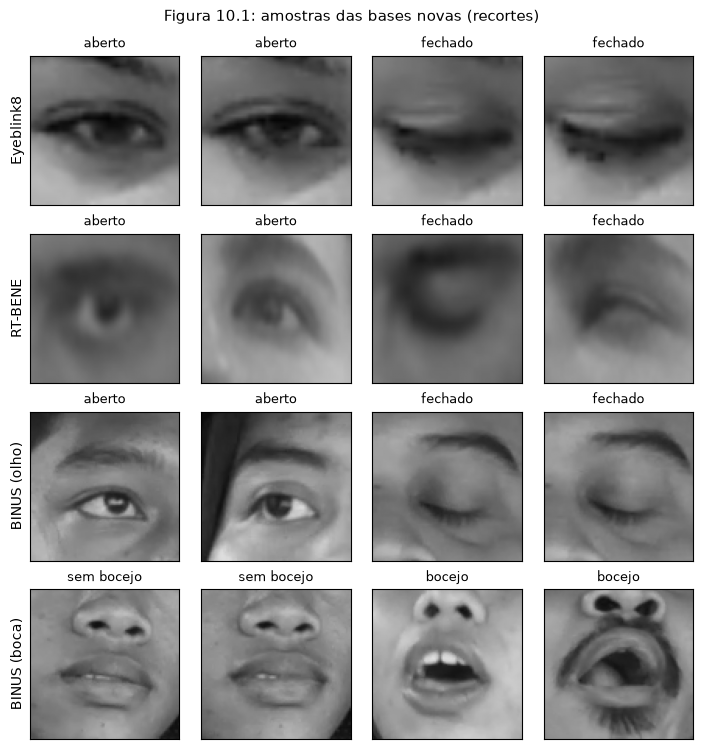

In [62]:
# Figura 10.1: amostras das bases novas. Só recortes de olho e de boca, como nas figuras do MRL.
# A célula pula a base que não estiver baixada em data/bases_novas/.
import io
import json
import tarfile
import tempfile
import zipfile
import csv as csv_mod
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

BASES_NOVAS = DADOS / "bases_novas"
rng_fig = np.random.default_rng(42)


def recorte(img, x0, y0, x1, y1, margem=0.35, lado=96):
    """Recorta a caixa com margem e devolve um quadrado em tons de cinza."""
    w, h = x1 - x0, y1 - y0
    cx, cy, r = (x0 + x1) / 2, (y0 + y1) / 2, max(w, h) * (1 + margem) / 2
    a, b = int(max(cy - r, 0)), int(min(cy + r, img.shape[0]))
    c, d = int(max(cx - r, 0)), int(min(cx + r, img.shape[1]))
    g = img[a:b, c:d]
    if g.ndim == 3:
        g = cv2.cvtColor(g, cv2.COLOR_BGR2GRAY)
    return cv2.resize(g, (lado, lado))


def amostras_eyeblink8():
    """Olho esquerdo aberto (fora de piscada) e fechado (frame marcado como C) num vídeo do Eyeblink8."""
    z = zipfile.ZipFile(BASES_NOVAS / "eyeblink8" / "eyeblink8.zip")
    nome = "eyeblink8/9/27122013_152435_cam"
    linhas = z.read(nome + ".tag").decode("latin1").splitlines()
    rotulos = [l.split(":") for l in linhas[linhas.index("#start") + 1:] if l and not l.startswith("#")]
    # campos: frame, piscada, NF, LE_FC, LE_NV, RE_FC, RE_NV, F_X, F_Y, F_W, F_H, cantos dos olhos
    abertos = [r for r in rotulos if r[1] == "-1" and "X" not in r[11:15]]
    fechados = [r for r in rotulos if r[3] == "C" and "X" not in r[11:15]]
    escolha = {"aberto": [abertos[i] for i in rng_fig.choice(len(abertos), 2, replace=False)],
               "fechado": [fechados[i] for i in rng_fig.choice(len(fechados), 2, replace=False)]}
    with tempfile.TemporaryDirectory() as tmp:
        video = Path(tmp) / "v.avi"
        video.write_bytes(z.read(nome + ".avi"))
        cap = cv2.VideoCapture(str(video))
        saida = {}
        for classe, rs in escolha.items():
            saida[classe] = []
            for r in rs:
                cap.set(cv2.CAP_PROP_POS_FRAMES, int(r[0]))
                ok, frame = cap.read()
                lx, ly, rx, ry = map(int, r[11:15])
                larg = abs(rx - lx)
                saida[classe].append(recorte(frame, min(lx, rx), min(ly, ry) - larg // 2,
                                             max(lx, rx), max(ly, ry) + larg // 2, margem=0.3))
        cap.release()
    return saida


def amostras_rt_bene():
    """Recortes RGB das pessoas de validação: aberto (rótulo 0) e piscando (rótulo 1)."""
    saida = {"aberto": [], "fechado": []}
    for pessoa in ["s000", "s011"]:
        rot = dict(csv_mod.reader(open(BASES_NOVAS / "rt_bene" / f"{pessoa}_blink_labels.csv")))
        tar = tarfile.open(BASES_NOVAS / "rt_bene" / f"{pessoa}_noglasses_eyes.tar")
        nomes = {Path(m.name).name: m for m in tar.getmembers() if m.isfile()}
        for classe, valor in [("aberto", "0.0"), ("fechado", "1.0")]:
            opcoes = [n for n, v in rot.items() if v == valor and n in nomes]
            n = opcoes[rng_fig.integers(len(opcoes))]
            img = cv2.imdecode(np.frombuffer(tar.extractfile(nomes[n]).read(), np.uint8), cv2.IMREAD_GRAYSCALE)
            saida[classe].append(cv2.resize(img, (96, 96)))
    return saida


def amostras_binus():
    """Recortes das caixas anotadas na BINUS: olho aberto, olho fechado, bocejo e boca sem bocejo."""
    raiz = "Annotated Drowsiness Detection Dataset Captured Us/modelling/"
    z = zipfile.ZipFile(BASES_NOVAS / "binus_rpi5" / "binus_rpi5.zip")
    rotulos = json.loads(z.read(raiz + "info.labels"))["files"]
    imagens = {}
    for parte in ["training", "testing"]:
        interno = zipfile.ZipFile(io.BytesIO(z.read(raiz + parte + ".zip")))
        imagens.update({n: interno for n in interno.namelist()
                        if n.endswith(".jpg") and not n.startswith("__MACOSX")})
    # rótulos em indonésio: mata_terbuka = olho aberto, mata_terpejam = olho fechado,
    # menguap = bocejo, tidak_menguap = sem bocejo
    classes = {"aberto": "mata_terbuka", "fechado": "mata_terpejam",
               "bocejo": "menguap", "sem bocejo": "tidak_menguap"}
    saida = {}
    for classe, rotulo in classes.items():
        caixas = [(f["path"], b) for f in rotulos if f["path"] in imagens
                  for b in f["boundingBoxes"] if b["label"] == rotulo]
        saida[classe] = []
        for i in rng_fig.choice(len(caixas), 2, replace=False):
            caminho, b = caixas[i]
            img = cv2.imdecode(np.frombuffer(imagens[caminho].read(caminho), np.uint8), cv2.IMREAD_COLOR)
            saida[classe].append(recorte(img, b["x"], b["y"], b["x"] + b["width"], b["y"] + b["height"],
                                         margem=0.1))
    return saida


fontes = [("Eyeblink8", amostras_eyeblink8, ["aberto", "fechado"]),
          ("RT-BENE", amostras_rt_bene, ["aberto", "fechado"]),
          ("BINUS (olho)", amostras_binus, ["aberto", "fechado"]),
          ("BINUS (boca)", None, ["sem bocejo", "bocejo"])]
linhas_fig, cache_binus = [], None
for nome, func, classes in fontes:
    try:
        if nome.startswith("BINUS"):
            cache_binus = cache_binus or amostras_binus()
            dados = cache_binus
        else:
            dados = func()
        linhas_fig.append((nome, [(c, img) for c in classes for img in dados[c]]))
    except (FileNotFoundError, KeyError, ValueError) as erro:
        print(f"{nome}: base não encontrada em {BASES_NOVAS} ({type(erro).__name__}), pulando")

if linhas_fig:
    fig, eixos = plt.subplots(len(linhas_fig), 4, figsize=(7.2, 1.9 * len(linhas_fig)), squeeze=False)
    for (nome, imgs), linha in zip(linhas_fig, eixos):
        for ax, (classe, img) in zip(linha, imgs):
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(classe, fontsize=9)
        linha[0].set_ylabel(nome, fontsize=10)
    fig.suptitle("Figura 10.1: amostras das bases novas (recortes)", fontsize=11)
    fig.tight_layout()
    plt.show()

**O que a figura mostra:** as três bases cobrem casos que o MRL e o FL3D não cobrem. O Eyeblink8 é uma webcam comum em ambiente interno, com piscadas rápidas, que são o principal candidato a alarme falso. A RT-BENE tem recortes em RGB de baixa resolução, mais parecidos com uma webcam distante do que o MRL. A BINUS traz olhos e bocas de pessoas com outros traços e acessórios, e bocejos marcados, o que permite testar o filtro de bocejo fora do FL3D.

### 10.4 Qual é o modelo final?

O paper precisa dizer com clareza qual é o sistema final. Hoje há duas decisões em aberto, uma para o microssono e outra para a sonolência que vem antes dele. A proposta é fixar o critério **antes** dos testes desta semana, no protocolo de cada frente, para que a escolha não dependa de olhar o resultado.

**Microssono (olho fechado por 1 s ou mais)**

| Candidato | Situação hoje |
|---|---|
| YOLO com filtro de bocejo e T = 1 s | É o que a demo usa: 86,8% dos episódios de 1 s ou mais, 10 falsos alarmes, F2 0,88 |
| Fusão EAR + YOLO pela média, com filtro (6.3) | 90,7% dos episódios, 6,0 falsos alarmes, F2 0,92 (+0,037 sobre o YOLO, de +0,010 a +0,071), mas a ideia veio de olhar os mesmos 44 vídeos |
| Qualquer um dos dois com limiar adaptativo, piso de 3 s e filtro de olhar para baixo | A testar nesta semana |

**Critério aprovado pelo grupo em 13/11/2026, antes de medir os alarmes nas bases de teste:** fica o candidato com maior F2 na validação cruzada do FL3D (frente B), se as duas condições abaixo valerem.

1. **Vantagem conclusiva:** a diferença de F2 contra o sistema atual (YOLO com filtro) tem IC95% sem zero.
2. **Sem mais alarmes falsos:** a taxa de alarmes falsos somando todas as bases de teste (classe alerta do UTA-RLDD, Eyeblink8 e Drive&Act; total de alarmes ÷ total de horas) não é maior que a do sistema atual. A soma pesa cada base pelo tempo de vídeo, e a média simples não é usada porque as bases têm durações muito diferentes.

Cada base é reportada separada, e uma piora numa base isolada entra como limitação no paper. Se alguma base não ficar pronta até 15/11, o critério vale com as que ficarem, e isso é registrado. O mesmo critério vale para os candidatos seguintes (limiar adaptativo, piso de 3 s, filtro de olhar para baixo), sempre contra o vencedor do momento. Com os números da frente B, a fusão pela média passa na condição 1 (+0,037, de +0,010 a +0,071); a condição 2 ainda não foi medida.

**Sonolência antes do microssono**

| Candidato | UTA, AUC por vídeo | DROZY, AUC por vídeo | Situação |
|---|---|---|---|
| PERCLOS absoluto | 0,814 | 0,619 | Linha de base simples |
| MIL-GRU-4 normalizada (rede principal da 8.7) | 0,742 | 0,708 | Está na demo. Perde do PERCLOS no UTA e ganha no DROZY |
| MIL-Transformer-14 | 0,875 | 0,743 | Melhor nas duas bases, mas era a rede secundária: foi destacada depois de ver o resultado e precisa de um teste novo |
| PERCLOS absoluto combinado com a MIL normalizada | — | — | A testar: ataca o custo da normalização |

Critério proposto: uma rede só vira o modelo final se superar o PERCLOS absoluto com intervalo de confiança acima de zero numa base que não foi usada para escolhê-la (WACHsens e SUST-DDD, e UL-DD se chegar a tempo), sem perder no UTA nem no DROZY. Se nenhuma rede passar, o modelo final de sonolência é o PERCLOS absoluto, e as redes ficam como resultado de pesquisa, ao lado dele na demo.

Um cuidado: o WACHsens não tem os mesmos sinais da webcam. Lá, a rede usa a abertura da pálpebra do rastreador ocular, a posição da cabeça e o olhar, então o teste confirma a **arquitetura** e a normalização, não os pesos treinados no UTA.

**Atualização em 13 e 14/11/2026 (sonolência):** o critério mudou antes do teste nas bases novas. O protocolo está em `docs/protocolo_sonolencia_final.md`, e os resultados, na seção 12.
- **Critério em dois níveis:**
  1. **Escolha:** fica o candidato com a maior AUC média nas bases, desde que não perca do PERCLOS absoluto de forma conclusiva (IC95% todo abaixo de zero) em nenhuma delas.
  2. **Afirmação:** o paper só diz que o escolhido "supera o PERCLOS absoluto" se a diferença média nas bases novas tiver IC95% acima de zero.
- **Quando mudou:** em 13/11, depois de ver o UTA e o DROZY e antes de extrair a SUST-DDD. Por isso, a escolha favorece quem já ia bem nessas duas bases.
- **Candidatos:** PERCLOS absoluto, MIL-Transformer-14, PERCLOS combinado com a MIL-GRU-4 e PERCLOS adaptativo. A MIL-GRU-4 sozinha ficou só como descrição, porque já perde do PERCLOS absoluto no UTA de forma conclusiva.
- **Bases novas:** a SUST-DDD e, por uma emenda aprovada antes de ver qualquer número dela, a UL-DD. O WACHsens não entrou, porque o download não foi concluído, então o teste da arquitetura nele ficou de fora.
- **Resultado:** o modelo final de sonolência é o **PERCLOS combinado**, com AUC média de 0,742 nas 4 bases, contra 0,706 do PERCLOS absoluto. O nível 2 não foi confirmado (+0,031, de −0,134 a +0,153), então o paper não diz que ele supera o PERCLOS.


### 10.5 Cronograma até a entrega

| Dia | Tarefas |
|---|---|
| Qui 12/11 | Busca de bases (A); esta seção (I); protocolos de B, C e J |
| Sex 13/11 | F1 e F2 (B); limiar adaptativo (C); retreino do YOLO com aumento (J); fusão na demo (D); cenários simulados (K1) |
| Sáb 14/11 | Regra de olhar para baixo (E); piso de 3 s na seção 6 (D); avaliação do aumento (J) |
| Dom 15/11 | Base nova, se houver (D); V-JEPA (F); emenda FL3D → UTA (K2); execução completa do notebook |
| Seg 16/11 | Paper e slides com a narrativa (H) e os mecanismos (G); conferência dos números |
| Ter 17/11 | Entrega final |
| Qua 18/11 | Apresentação final: FPS na máquina da apresentação e ensaio da demo |

## 12. Modelo final de sonolência

Esta seção escolhe o modelo final de sonolência, a que vem antes do microssono, seguindo o protocolo `docs/protocolo_sonolencia_final.md`, aprovado em 13/11/2026 antes de extrair a base nova. A seção 11 fica reservada para o modelo final de microssono.

**Candidatos:**
- PERCLOS absoluto, que é a referência;
- MIL-Transformer-14 da seção 8.7;
- PERCLOS combinado com a MIL, que é a média do PERCLOS absoluto e do logit da MIL-GRU-4, cada um padronizado com a média e o desvio do UTA;
- PERCLOS adaptativo: o quadro conta como fechado quando P(fechado) ≥ b + 0,5·(1 − b), em que b é o percentil 25 do P(fechado) nos primeiros 30 s do minuto de calibração.

A MIL-GRU-4 entra só como descrição, porque já perde do PERCLOS absoluto no UTA de forma conclusiva (seção 8.7).

**Critério, em dois níveis:**
1. **Escolha:** fica o candidato com a maior AUC média nas 3 bases (UTA, DROZY e SUST-DDD, com o mesmo peso), desde que não perca do PERCLOS absoluto de forma conclusiva (IC95% todo abaixo de zero) em nenhuma delas.
2. **Afirmação:** o paper só diz que o escolhido "supera o PERCLOS absoluto" se a diferença na SUST-DDD tiver IC95% acima de zero.

**Origem do critério:** a seção 10.4 propunha exigir IC acima de zero na base nova para escolher. O grupo trocou para o critério acima em 13/11, antes de extrair a SUST-DDD, mas depois de ver o UTA e o DROZY. Por isso, a escolha favorece quem já ia bem nessas duas bases: o PERCLOS absoluto só ganharia do MIL-Transformer na média se ele perdesse por mais de 0,185 na SUST-DDD.

**A base nova, SUST-DDD** (Kavalcı Yılmaz e Akcayol, FRUCT 2022):
- **Gravação:** 19 motoristas em direção real, gravando com o próprio celular.
- **Rótulo:** clipes de 10 s marcados por observadores como sonolentos ou não.
- **Sequências:** juntamos os clipes contínuos em sequências e agrupamos os motoristas à mão (20 grupos, seção 10.3).
- **Minutos:** cada 6 clipes contínuos viram um minuto de 600 quadros a 10 fps. O 1º minuto de cada sequência é o de calibração, como na seção 8.7.
- **O que entra no critério:** só as sequências de 2 min ou mais.
- **Treino e ajuste:** nada é treinado, calibrado ou escolhido nela. As redes são treinadas no UTA inteiro, como na parte B da seção 8.7.
- **Imagens:** nenhuma imagem da SUST-DDD aparece aqui, porque a licença dos vídeos não está informada.

In [63]:
# Seção 12: SUST-DDD. Extração a 10 fps com o ExtratorRosto da demo (modo IMAGE no quadro inteiro, como no UTA,
# YOLO da semente 42), um arquivo por clipe. Rodada fora do notebook em 4 processos, com este mesmo código
# (cerca de 1 h numa RTX 3050); aqui ela só roda para os clipes que faltarem no cache.
import sys
sys.path.insert(0, str(Path("demo").resolve()))
from sonolencia import ExtratorRosto

PASTA_SUST = DADOS / "bases_novas" / "SUST-DDD" / "SUST Driver Drowsiness Dataset"
CACHE_SUST = CACHE / "sust_rico"
CACHE_SUST.mkdir(exist_ok=True)
meta_sust = pd.read_csv(CACHE / "sust" / "motoristas.csv")      # classe, num, seq, fps, motorista (agrupado à mão)


def extrair_clipe_sust(classe, num, ex):
    # 100 amostras: o quadro mais próximo de cada múltiplo de 100 ms, pelo fps do arquivo
    arq = CACHE_SUST / f"{classe}_{num}.npz"
    if arq.exists():
        return
    sub = PASTA_SUST / ("drowsiness" if classe == "d" else "not drowsiness")
    video = next(p for p in (sub / f"{classe}_{num}.mp4", sub / f"{classe}_{num}mp4.mp4") if p.exists())  # n_790mp4.mp4
    cap = cv2.VideoCapture(str(video))
    fps, total = cap.get(cv2.CAP_PROP_FPS), int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    escolha = np.round(np.arange(100) * 0.1 * fps).astype(int)
    s = np.full((100, len(ex.canais)), np.nan, np.float32)
    atual, j = -1, 0
    while j < 100:
        ok, quadro = cap.read()
        if not ok:
            break
        atual += 1
        while j < 100 and escolha[j] == atual:
            s[j] = ex.linha(quadro)
            j += 1
    cap.release()
    tmp = arq.with_name(arq.stem + ".parcial.npz")
    np.savez(tmp, s=s, fps=fps, quadros=total, amostras=j)
    tmp.replace(arq)


faltam = [(c, n) for c, n in zip(meta_sust.classe, meta_sust.num) if not (CACHE_SUST / f"{c}_{n}.npz").exists()]
if faltam:
    ex_sust = ExtratorRosto()
    for c, n in faltam:
        extrair_clipe_sust(c, n, ex_sust)
    ex_sust.fechar()
# o ExtratorRosto usa a ordem de sinais gravada com os pesos da demo: a mesma do UTA e do DROZY
assert list(torch.load(ARQ_MIL_DEMO, map_location="cpu")["canais_rico"]) == list(CANAIS_RICO)

# minutos: 6 clipes contínuos de 10 s por minuto, em ordem dentro de cada sequência; o que sobra no fim fica de fora
partes, linhas_c = [], []
for (seq, classe, mot), g in meta_sust.sort_values(["seq", "num"]).groupby(["seq", "classe", "motorista"], sort=False):
    nums = g.num.tolist()
    for m in range(len(nums) // 6):
        partes.append(np.concatenate([np.load(CACHE_SUST / f"{classe}_{n}.npz")["s"] for n in nums[6 * m:6 * m + 6]]))
        linhas_c.append({"seq": seq, "motorista": mot, "sonolento": int(classe == "d"), "clipe": m})
s_sust = np.stack(partes)                                          # [minutos, 600, 61]
meta_c = pd.DataFrame(linhas_c)
x14_abs_c = canais_14(s_sust)
a_sust = atributos_16(s_sust, x14_abs_c)
videos_c = montar_videos(meta_c, chave="seq")                      # só sequências com 2 min ou mais
x14_d_c, a_d_c = normalizar_videos(x14_abs_c, a_sust, videos_c)
y_c = np.array([v["y"] for v in videos_c])
motorista_c = meta_c.motorista.values[[v["calibracao"] for v in videos_c]]
mins_crit = np.concatenate([[v["calibracao"], *v["minutos"]] for v in videos_c])
TAXA_ROSTO_SUST = np.mean(s_sust[mins_crit][:, :, 5] == 1)
SUST_OK = TAXA_ROSTO_SUST >= 0.90                                 # checagem de qualidade fixada no protocolo
n_seq1 = meta_c.groupby("seq").size()
print(f"SUST-DDD: {meta_sust.shape[0]} clipes | {len(n_seq1)} sequências de 1 min ou mais | "
      f"{len(videos_c)} de 2 min ou mais ({y_c.sum()} sonolentas), de {len(set(motorista_c))} motoristas, "
      f"{sum(pd.Series(y_c).groupby(motorista_c).nunique() == 2)} com as duas classes")
print(f"minutos avaliados por sequência: {min(len(v['minutos']) for v in videos_c)} a "
      f"{max(len(v['minutos']) for v in videos_c)} (mediana {np.median([len(v['minutos']) for v in videos_c]):.0f})")
print(f"rosto encontrado nas sequências do critério: {TAXA_ROSTO_SUST:.1%} (mínimo do protocolo: 90%) | "
      f"em toda a base: {np.mean(s_sust[:, :, 5] == 1):.1%} | SUST entra no critério: {SUST_OK}")

SUST-DDD: 2074 clipes | 87 sequências de 1 min ou mais | 34 de 2 min ou mais (14 sonolentas), de 15 motoristas, 7 com as duas classes
minutos avaliados por sequência: 1 a 9 (mediana 2)
rosto encontrado nas sequências do critério: 98.8% (mínimo do protocolo: 90%) | em toda a base: 98.6% | SUST entra no critério: True


In [64]:
# Redes treinadas no UTA inteiro (como prever_b da parte B) e aplicadas ao DROZY e à SUST-DDD sem ajuste.
# O DROZY é refeito para conferir que o retreino repete as previsões da seção 8.7.
CACHE_MIL_C = CACHE / "sust_mil"
CACHE_MIL_C.mkdir(exist_ok=True)
REDES_12 = ["MIL-GRU-4 híbrida", "MIL-Transformer-14 híbrido"]


def prever_c(nome, semente):
    arq = CACHE_MIL_C / f"{MODELOS_87[nome][3]}_s{semente}.npz"
    if arq.exists():
        q = np.load(arq)
        return q["p_drozy"], q["p_sust"]
    prep = preparar_87(nome, x14_d, a_d, ref_uta)
    modelo, _ = treinar_87(nome, semente, videos_a, *prep(x14_d, a_d), epocas=EPOCAS_B[nome])
    p_b, _ = prever_videos_87(modelo, videos_b, *prep(x14_d_b, a_d_b))
    p_c, _ = prever_videos_87(modelo, videos_c, *prep(x14_d_c, a_d_c))
    np.savez(arq, p_drozy=p_b, p_sust=p_c)
    return p_b, p_c


prev_c = {(n, s): prever_c(n, s) for n in REDES_12 for s in SEMENTES}
ps_c = {n: [prev_c[n, s][1] for s in SEMENTES] for n in REDES_12}
for n in REDES_12:
    dif = max(np.abs(prev_c[n, s][0] - p).max() for s, p in zip(SEMENTES, ps_b[n]))
    print(f"{n}: maior diferença no DROZY entre o retreino e a seção 8.7: {dif:.1e}")

MIL-GRU-4 híbrida: maior diferença no DROZY entre o retreino e a seção 8.7: 0.0e+00
MIL-Transformer-14 híbrido: maior diferença no DROZY entre o retreino e a seção 8.7: 0.0e+00


In [65]:
# Os quatro candidatos e a MIL-GRU-4 (descrição) nas três bases


def perclos_adaptativo(s, videos, adaptar=True):
    # b = percentil 25 do P(fechado) nos primeiros 30 s do minuto de calibração (quadros com rosto); recusa com
    # menos de 5 s de rosto ou b > 0,5 (volta b = 0). Quadro fechado: P >= b + 0,5 (1 - b). Média dos minutos usados.
    perclos, bs, recusas = [], [], []
    for v in videos:
        cal = s[v["calibracao"], :30 * FPS_RLDD]
        p_cal, r_cal = cal[:, :2].mean(axis=1), cal[:, 5] == 1
        b = np.percentile(p_cal[r_cal], 25) if r_cal.sum() >= 5 * FPS_RLDD else np.nan
        recusa = bool(np.isnan(b) or b > 0.5)
        b = 0.0 if (recusa or not adaptar) else float(b)
        mins = s[v["minutos"]]
        p, r = mins[:, :, :2].mean(axis=2), mins[:, :, 5] == 1
        fech = p >= b + 0.5 * (1 - b)
        por_min = np.array([f[q].mean() if q.any() else np.nan for f, q in zip(fech, r)])
        perclos.append(np.nanmean(por_min) if np.isfinite(por_min).any() else np.nan)
        bs.append(b); recusas.append(recusa)
    return np.array(perclos), np.array(bs), np.array(recusas)


BASES_12 = {"UTA": dict(s=s_rico, a=a_rico, videos=videos_a, y=y_a, g=pessoa_a),
            "DROZY": dict(s=s_drozy, a=a_drozy, videos=videos_b, y=y_b, g=pessoa_b),
            "SUST": dict(s=s_sust, a=a_sust, videos=videos_c, y=y_c, g=motorista_c)}
p_gru_12 = {"UTA": np.mean(ps_87["MIL-GRU-4 híbrida"], axis=0), "DROZY": np.mean(ps_b["MIL-GRU-4 híbrida"], axis=0),
            "SUST": np.mean(ps_c["MIL-GRU-4 híbrida"], axis=0)}
p_tr_12 = {"UTA": ps_87["MIL-Transformer-14 híbrido"], "DROZY": ps_b["MIL-Transformer-14 híbrido"],
           "SUST": ps_c["MIL-Transformer-14 híbrido"]}
logit_12 = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))

adapt_12, b_12, recusa_12, pa_12 = {}, {}, {}, {}
for nome, B in BASES_12.items():
    pa = resumo_video(B["a"], B["videos"], ["PERCLOS"]).PERCLOS.values
    sem_adaptar, _, _ = perclos_adaptativo(B["s"], B["videos"], adaptar=False)
    assert np.allclose(sem_adaptar, pa, equal_nan=True)                 # conferência: com b = 0, é o PERCLOS absoluto
    adapt_12[nome], b_12[nome], recusa_12[nome] = perclos_adaptativo(B["s"], B["videos"])
    pa_12[nome] = pa
# valores faltantes viram a mediana do UTA, como na parte B
med_pa, med_ad = np.nanmedian(pa_12["UTA"]), np.nanmedian(adapt_12["UTA"])
mu_l, dp_l = logit_12(p_gru_12["UTA"]).mean(), logit_12(p_gru_12["UTA"]).std()
cand_12 = {}
for nome in BASES_12:
    pa = np.nan_to_num(pa_12[nome], nan=med_pa)
    if nome == "UTA":
        assert np.allclose(pa, x_pa)
    mu_p, dp_p = np.nan_to_num(pa_12["UTA"], nan=med_pa).mean(), np.nan_to_num(pa_12["UTA"], nan=med_pa).std()
    cand_12[nome] = {"PERCLOS absoluto": [pa],
                     "MIL-Transformer-14 híbrido": p_tr_12[nome],
                     "PERCLOS combinado": [((pa - mu_p) / dp_p + (logit_12(p_gru_12[nome]) - mu_l) / dp_l) / 2],
                     "PERCLOS adaptativo": [np.nan_to_num(adapt_12[nome], nan=med_ad)],
                     "MIL-GRU-4 híbrida": {"UTA": ps_87, "DROZY": ps_b, "SUST": ps_c}[nome]["MIL-GRU-4 híbrida"]}

# conferência dos números da seção 8.7
for nome in ["UTA", "DROZY"]:
    B = BASES_12[nome]
    print(nome, {k: round(np.mean([roc_auc_score(B["y"], p) for p in cand_12[nome][k]]), 3)
                 for k in ["PERCLOS absoluto", "MIL-GRU-4 híbrida", "MIL-Transformer-14 híbrido"]})
print("MIL-GRU-4 - PERCLOS absoluto no UTA:",
      np.round(dif_auc_v(y_a, pessoa_a, cand_12["UTA"]["MIL-GRU-4 híbrida"], cand_12["UTA"]["PERCLOS absoluto"]), 3))

UTA {'PERCLOS absoluto': np.float64(0.814), 'MIL-GRU-4 híbrida': np.float64(0.742), 'MIL-Transformer-14 híbrido': np.float64(0.875)}
DROZY {'PERCLOS absoluto': np.float64(0.619), 'MIL-GRU-4 híbrida': np.float64(0.708), 'MIL-Transformer-14 híbrido': np.float64(0.743)}


MIL-GRU-4 - PERCLOS absoluto no UTA: [     -0.071      -0.144      -0.004]


In [66]:
# Critério (docs/protocolo_sonolencia_final.md): nível 1, escolha pela AUC média com a trava; nível 2, IC na SUST
REF_12 = "PERCLOS absoluto"
DESAFIANTES_12 = ["MIL-Transformer-14 híbrido", "PERCLOS combinado", "PERCLOS adaptativo"]
BASES_CRIT = ["UTA", "DROZY"] + (["SUST"] if SUST_OK else [])
auc_lista = lambda y, idx, lista: np.mean([roc_auc_score(y[idx], p[idx]) for p in lista])


def dif_media_estratificada(nome, n=2000):
    # IC95% da diferença média (candidato - referência): sorteio de pessoas ou motoristas dentro de cada base
    rng = np.random.default_rng(SEMENTE)
    difs = []
    for _ in range(n):
        ds = []
        for b in BASES_CRIT:
            B = BASES_12[b]
            grupos = np.unique(B["g"])
            idx = np.concatenate([np.flatnonzero(B["g"] == q) for q in rng.choice(grupos, len(grupos))])
            if len(np.unique(B["y"][idx])) < 2:
                break
            ds.append(auc_lista(B["y"], idx, cand_12[b][nome]) - auc_lista(B["y"], idx, cand_12[b][REF_12]))
        else:
            difs.append(np.mean(ds))
    return np.percentile(difs, [2.5, 97.5])


tab_12, comp_12 = {}, {}
for nome in [REF_12] + DESAFIANTES_12 + ["MIL-GRU-4 híbrida"]:
    linha = {}
    for b in BASES_CRIT:
        B = BASES_12[b]
        linha[f"AUC {b}"] = auc_ic(B["y"], cand_12[b][nome], B["g"])[0]
        if nome != REF_12:
            d, inf, sup = dif_auc_v(B["y"], B["g"], cand_12[b][nome], cand_12[b][REF_12])
            comp_12[nome, b] = {"dif. AUC": d, "IC95% inf.": inf, "IC95% sup.": sup}
    linha["AUC média"] = np.mean([linha[f"AUC {b}"] for b in BASES_CRIT])
    if nome != REF_12:
        linha["dif. média"] = linha["AUC média"] - tab_12[REF_12]["AUC média"]
        linha["dif. média IC inf."], linha["dif. média IC sup."] = dif_media_estratificada(nome)
        linha["passa na trava"] = all(comp_12[nome, b]["IC95% sup."] >= 0 for b in BASES_CRIT)
    tab_12[nome] = linha
print(f"Bases do critério: {BASES_CRIT} | AUC por vídeo ou sequência, sem o minuto de calibração; redes com 5 sementes")
display(pd.DataFrame(tab_12).T)
print("Diferenças contra o PERCLOS absoluto (bootstrap pareado por pessoa ou motorista, 2.000 sorteios)")
display(pd.DataFrame(comp_12).T.round(3))

# nível 1: maior AUC média entre a referência e os desafiantes que passam na trava (empate exato fica a referência)
elegiveis = [REF_12] + [n for n in DESAFIANTES_12 if tab_12[n]["passa na trava"]]
ESCOLHIDO_12 = max(elegiveis, key=lambda n: (tab_12[n]["AUC média"], n == REF_12))
print(f"Nível 1, modelo final de sonolência: {ESCOLHIDO_12}")
# nível 2: afirmação de superioridade só com IC acima de zero na SUST
if ESCOLHIDO_12 == REF_12:
    print("Nível 2: nenhum candidato superou o PERCLOS absoluto na média das bases.")
elif not SUST_OK:
    print("Nível 2: a SUST não passou na checagem de qualidade, então a superioridade não pode ser afirmada.")
else:
    ok = comp_12[ESCOLHIDO_12, "SUST"]["IC95% inf."] > 0
    print(f"Nível 2: {'confirmado' if ok else 'não confirmado'} na SUST "
          f"({comp_12[ESCOLHIDO_12, 'SUST']['dif. AUC']:+.3f}, de {comp_12[ESCOLHIDO_12, 'SUST']['IC95% inf.']:+.3f} "
          f"a {comp_12[ESCOLHIDO_12, 'SUST']['IC95% sup.']:+.3f})")

Bases do critério: ['UTA', 'DROZY', 'SUST'] | AUC por vídeo ou sequência, sem o minuto de calibração; redes com 5 sementes


,AUC UTA,AUC DROZY,AUC SUST,AUC média,dif. média,dif. média IC inf.,dif. média IC sup.,passa na trava
PERCLOS absoluto,0.813847,0.619048,0.626786,0.68656,NaN,NaN,NaN,NaN
MIL-Transformer-14 híbrido,0.874576,0.743492,0.483571,0.700547,0.013987,-0.099243,0.108482,True
PERCLOS combinado,0.804079,0.711111,0.703571,0.739587,0.053027,-0.04291,0.12654,True
PERCLOS adaptativo,0.814278,0.619048,0.632143,0.688489,0.001929,-0.000383,0.00752,True
MIL-GRU-4 híbrida,0.742488,0.707937,0.678571,0.709665,0.023105,-0.078766,0.107245,False


Diferenças contra o PERCLOS absoluto (bootstrap pareado por pessoa ou motorista, 2.000 sorteios)


dif. AUC  IC95% inf.  IC95% sup.
MIL-Transformer-14 híbrido UTA       0.061       0.003       0.116
                           DROZY     0.124      -0.148       0.356
                           SUST     -0.143      -0.335       0.030
PERCLOS combinado          UTA      -0.010      -0.062       0.042
                           DROZY     0.092      -0.153       0.276
                           SUST      0.077      -0.055       0.213
PERCLOS adaptativo         UTA       0.000      -0.002       0.003
                           DROZY     0.000       0.000       0.000
                           SUST      0.005       0.000       0.023
MIL-GRU-4 híbrida          UTA      -0.071      -0.144      -0.004
                           DROZY     0.089      -0.159       0.293
                           SUST      0.052      -0.088       0.202

Nível 1, modelo final de sonolência: PERCLOS combinado
Nível 2: não confirmado na SUST (+0.077, de -0.055 a +0.213)


In [67]:
# Descrições do protocolo (não entram no critério)
print("Linha de base b do PERCLOS adaptativo, por base")
display(pd.DataFrame({b: {"vídeos": len(b_12[b]), "calibrações recusadas": int(recusa_12[b].sum()),
                          "b mediano": np.median(b_12[b]), "b, percentil 90": np.percentile(b_12[b], 90),
                          "b máximo": b_12[b].max(), "vídeos com b > 0,05": int((b_12[b] > 0.05).sum())}
                      for b in BASES_12}).T.round(3))

# acurácia balanceada: limiares de maior acurácia no UTA nos sinais diretos; 0,5 nas redes
lim_12 = {n: limiar_acuracia(cand_12["UTA"][n][0], y_a) for n in ["PERCLOS absoluto", "PERCLOS combinado", "PERCLOS adaptativo"]}
acc_12 = {}
for n in [REF_12] + DESAFIANTES_12 + ["MIL-GRU-4 híbrida"]:
    acc_12[n] = {}
    for b in ["DROZY", "SUST"]:
        y = BASES_12[b]["y"]
        dec = [cand_12[b][n][0] >= lim_12[n]] if n in lim_12 else [p >= 0.5 for p in cand_12[b][n]]
        acc_12[n][b] = np.mean([balanced_accuracy_score(y, d) for d in dec])
print("Acurácia balanceada (limiares do UTA)")
display(pd.DataFrame(acc_12).T.round(3))

# DROZY só com os testes 2 e 3 (mesma iluminação)
sel = teste_b >= 2
print("DROZY, testes 2 e 3 (24 vídeos): AUC")
display(pd.Series({n: np.mean([roc_auc_score(y_b[sel], p[sel]) for p in cand_12["DROZY"][n]])
                   for n in [REF_12] + DESAFIANTES_12 + ["MIL-GRU-4 híbrida"]}).round(3).to_frame("AUC"))

# SUST: controle de pose, AUC dentro do motorista e PERCLOS absoluto nas sequências de 1 min ou mais
vpose_c = resumo_video(a_d_c, videos_c, CONTROLE_87)
pose_c = logist(vpose_a.values, vpose_c.values)
print("SUST, controle Δ pose média (logística do UTA): AUC %.3f (IC95%% de %.3f a %.3f)" % auc_ic(y_c, [pose_c], motorista_c))
ambos_c = [m for m in np.unique(motorista_c) if len(set(y_c[motorista_c == m])) == 2]
dentro_c = {n: np.mean([np.mean([roc_auc_score(y_c[motorista_c == m], p[motorista_c == m]) for p in cand_12["SUST"][n]])
                        for m in ambos_c]) for n in [REF_12] + DESAFIANTES_12 + ["MIL-GRU-4 híbrida"]}
print(f"SUST, AUC dentro do motorista ({len(ambos_c)} motoristas com as duas classes):")
display(pd.Series(dentro_c).round(3).to_frame("AUC dentro do motorista"))
seq1 = meta_c.assign(PERCLOS=a_sust.PERCLOS.values).groupby("seq").agg(
    PERCLOS=("PERCLOS", "mean"), y=("sonolento", "first"), motorista=("motorista", "first"))
auc1 = auc_ic(seq1.y.values, [np.nan_to_num(seq1.PERCLOS.values, nan=med_pa)], seq1.motorista.values)
print(f"SUST, PERCLOS absoluto nas {len(seq1)} sequências de 1 min ou mais (todos os minutos, sem calibração): "
      f"AUC {auc1[0]:.3f} (IC95% de {auc1[1]:.3f} a {auc1[2]:.3f})")

Linha de base b do PERCLOS adaptativo, por base


,vídeos,calibrações recusadas,b mediano,"b, percentil 90",b máximo,"vídeos com b > 0,05"
UTA,118.0,0.0,0.0,0.004,0.056,1.0
DROZY,36.0,0.0,0.0,0.000,0.000,0.0
SUST,34.0,0.0,0.0,0.003,0.012,0.0


Acurácia balanceada (limiares do UTA)


,DROZY,SUST
PERCLOS absoluto,0.571,0.543
MIL-Transformer-14 híbrido,0.634,0.460
PERCLOS combinado,0.624,0.614
PERCLOS adaptativo,0.571,0.543
MIL-GRU-4 híbrida,0.606,0.587


DROZY, testes 2 e 3 (24 vídeos): AUC


,AUC
PERCLOS absoluto,0.511
MIL-Transformer-14 híbrido,0.816
PERCLOS combinado,0.696
PERCLOS adaptativo,0.511
MIL-GRU-4 híbrida,0.745


SUST, controle Δ pose média (logística do UTA): AUC 0.639 (IC95% de 0.471 a 0.793)
SUST, AUC dentro do motorista (7 motoristas com as duas classes):


,AUC dentro do motorista
PERCLOS absoluto,0.929
MIL-Transformer-14 híbrido,0.671
PERCLOS combinado,0.857
PERCLOS adaptativo,0.929
MIL-GRU-4 híbrida,0.829


SUST, PERCLOS absoluto nas 87 sequências de 1 min ou mais (todos os minutos, sem calibração): AUC 0.691 (IC95% de 0.541 a 0.820)


### Observações da seção 12 (UTA, DROZY e SUST-DDD)

- **Nível 1:** o PERCLOS combinado tem a maior AUC média (0,740, contra 0,687 do PERCLOS absoluto) e não perde de forma conclusiva em nenhuma base. O MIL-Transformer, melhor no UTA e no DROZY, cai para 0,484 na SUST-DDD (−0,143, de −0,335 a +0,030) e fica com média 0,701.
- **Nível 2:** não confirmado. Na SUST-DDD, o combinado fica +0,077 acima do PERCLOS absoluto, mas o IC vai de −0,055 a +0,213.
- **PERCLOS adaptativo:** na prática, é igual ao absoluto. A linha de base b tem mediana 0 nas três bases, e só 1 dos 188 vídeos tem b acima de 0,05, porque o YOLO dá P(fechado) quase zero no olho aberto. Nessa forma, a adaptação não muda o limiar, o que também vale para a frente C (limiar adaptativo no microssono).
- **MIL-GRU-4 (só descrição):** média 0,710, mas perde do PERCLOS absoluto no UTA de forma conclusiva (−0,071, de −0,144 a −0,004), então não poderia ser escolhida.
- **Limiares não transferem:** com os limiares escolhidos no UTA, a acurácia balanceada na SUST-DDD fica entre 0,46 e 0,61 (combinado 0,614, PERCLOS absoluto 0,543).
- **DROZY no escuro (testes 2 e 3):** o PERCLOS absoluto cai para 0,511, enquanto o MIL-Transformer fica em 0,816 e o combinado, em 0,696. Parte do ganho das redes no DROZY pode vir da iluminação, como já apontado na seção 8.7.
- **Cuidados:**
  - a SUST-DDD que entra no critério é pequena: 34 sequências, 14 sonolentas, 15 motoristas, mediana de 2 minutos avaliados;
  - o controle de pose dá 0,639 (de 0,471 a 0,793), então parte da separação pode vir da câmera, não do sono;
  - o critério foi trocado depois de ver o UTA e o DROZY, o que favorece quem já ia bem nessas bases.


### 12.1 Análise de erros na SUST-DDD (exploratória)

Na SUST-DDD, os candidatos ficaram entre 0,48 e 0,70 de AUC, bem abaixo do UTA. Esta análise procura o motivo, com uma lista fixada antes de olhar (`docs/protocolo_sonolencia_final.md`). Como a seção 8.6, ela é exploratória: não muda o critério nem os candidatos. Uma hipótese que saia daqui só pode ser testada na UL-DD se for escrita antes de rodar a UL-DD, e mesmo assim como teste separado.

1. **Entre e dentro do motorista:** a AUC dentro de cada motorista e quanto o PERCLOS varia entre motoristas, comparado com o quanto ele sobe com o sono.
2. **Tamanho do olho:** o acerto por terço do EAR de olho aberto.
3. **Câmera e luz:** o quanto o brilho, a pose média e a taxa de rosto separam as classes sozinhos, e de onde vem o controle de pose.
4. **Queda do MIL-Transformer:** a distribuição dos canais e atributos de entrada na SUST, comparada com a do UTA e a do DROZY.
5. **Duração:** o acerto por número de minutos avaliados.

O acerto usa os limiares do UTA (maior acurácia no UTA nos sinais diretos e 0,5 nas redes, com a média das 5 sementes).

In [68]:
# 12.1: análise de erros na SUST (exploratória; lista fixada em docs/protocolo_sonolencia_final.md)
NOMES_12 = [REF_12] + DESAFIANTES_12 + ["MIL-GRU-4 híbrida"]
seq_c = pd.DataFrame({"seq": [v["nome"] for v in videos_c], "motorista": motorista_c, "y": y_c,
                      "minutos": [len(v["minutos"]) for v in videos_c]})
for n in NOMES_12:
    seq_c[n] = np.mean(cand_12["SUST"][n], axis=0)
    seq_c["acerto " + n] = (seq_c[n] >= (lim_12[n] if n in lim_12 else 0.5)) == seq_c.y
aval = lambda v, col: np.nanmedian(a_sust[col].values[v["minutos"]])
seq_c["EAR de olho aberto"] = [aval(v, "EAR de olho aberto") for v in videos_c]
for e in POSE:
    seq_c[f"{e} médio"] = [aval(v, f"{e} médio") for v in videos_c]
seq_c["rosto"] = [np.mean(s_sust[v["minutos"]][:, :, 5] == 1) for v in videos_c]
cont = pd.read_csv(CACHE / "sust" / "continuidade.csv")
brilho = meta_sust.merge(cont[["classe", "num", "brilho"]], on=["classe", "num"]).groupby("seq").brilho.mean()
seq_c["brilho"] = seq_c.seq.map(brilho)
classe = seq_c.y.map({0: "não sonolenta", 1: "sonolenta"})

# 1. entre e dentro do motorista
pm = seq_c.groupby(["motorista", "y"])[REF_12].mean().unstack()
dif_dentro = (pm[1] - pm[0]).dropna()
print("1. PERCLOS absoluto: sobe %.3f do alerta ao sonolento na mesma pessoa (mediana; %d de %d motoristas sobem) "
      "| desvio entre motoristas nas sequências alertas: %.3f | mediana alerta %.3f, sonolenta %.3f"
      % (dif_dentro.median(), (dif_dentro > 0).sum(), len(dif_dentro), pm[0].std(), pm[0].median(), pm[1].median()))
por_mot = {}
for m in ambos_c:
    g = seq_c[seq_c.motorista == m]
    por_mot[m] = {"sequências": len(g), "sonolentas": int(g.y.sum()),
                  **{n: roc_auc_score(g.y, g[n]) for n in NOMES_12}}
print("AUC dentro de cada motorista com as duas classes (previsões com a média das sementes)")
display(pd.DataFrame(por_mot).T.round(2))

# 2. tamanho do olho
seq_c["terço do EAR aberto"] = pd.qcut(seq_c["EAR de olho aberto"], 3, labels=["menor", "médio", "maior"])
print("2. EAR de olho aberto separa as classes sozinho? AUC %.3f (abaixo de 0,5: menor no sonolento)"
      % roc_auc_score(seq_c.y, seq_c["EAR de olho aberto"]))
display(seq_c.groupby(["terço do EAR aberto", classe], observed=True)[
    ["acerto PERCLOS absoluto", "acerto PERCLOS combinado"]].agg(["mean", "size"]).round(2))

# 3. câmera e luz
print("3. Quanto cada sinal de câmera separa as classes sozinho (AUC; 0,5 = nada)")
display(pd.Series({c: roc_auc_score(seq_c.y, seq_c[c]) for c in
                   ["brilho", "rosto"] + [f"{e} médio" for e in POSE]}).round(3).to_frame("AUC"))
display(pd.Series({f"Δ {c}": roc_auc_score(y_c, vpose_c[c]) for c in CONTROLE_87}).round(3).to_frame("AUC (Δ pose)"))
seq_c["terço do brilho"] = pd.qcut(seq_c.brilho, 3, labels=["escuro", "médio", "claro"])
display(seq_c.groupby(["terço do brilho", classe], observed=True)[
    ["acerto PERCLOS absoluto", "acerto PERCLOS combinado"]].agg(["mean", "size"]).round(2))

# 4. entradas do MIL-Transformer: canais normalizados e padronizados com o UTA, nos minutos usados de cada base
media14, desvio14 = estatisticas_canais(x14_d[ref_uta])
prep16 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(a_d.iloc[ref_uta][ATRIB_16])
NOMES_14 = ["P(fechado)", "EAR", "boca", "rosto"] + POSE + BLENDSHAPES_85
entradas = {}
for nome, (x, a, vids) in {"UTA": (x14_d, a_d, videos_a), "DROZY": (x14_d_b, a_d_b, videos_b),
                           "SUST": (x14_d_c, a_d_c, videos_c)}.items():
    mins = np.concatenate([v["minutos"] for v in vids])
    z = (x[mins] - media14) / desvio14
    rosto = x[mins][:, :, 3] == 1
    for c, n in enumerate(NOMES_14):
        if n != "rosto":
            entradas.setdefault(n, {})[f"{nome} média"] = np.nanmean(z[:, :, c][rosto])
            entradas[n][f"{nome} desvio"] = np.nanstd(z[:, :, c][rosto])
    za = prep16.transform(a.iloc[mins][ATRIB_16])
    for c, n in enumerate(ATRIB_16):
        entradas.setdefault("Δ " + n, {})[f"{nome} média"] = za[:, c].mean()
        entradas["Δ " + n][f"{nome} desvio"] = za[:, c].std()
tab4 = pd.DataFrame(entradas).T
tab4["SUST: |média| ou desvio/UTA fora do esperado"] = (tab4["SUST média"].abs() > 0.5) | \
    ((tab4["SUST desvio"] / tab4["UTA desvio"]) > 2) | ((tab4["SUST desvio"] / tab4["UTA desvio"]) < 0.5)
print("4. Entradas das redes em unidades do UTA (0 e 1 = como no UTA)")
display(tab4.round(2))

# 5. duração
seq_c["minutos avaliados"] = pd.cut(seq_c.minutos, [0, 1, 2, 100], labels=["1", "2", "3 ou mais"])
print("5. Acerto por número de minutos avaliados")
tab5 = seq_c.groupby("minutos avaliados", observed=True)[["y"] + ["acerto " + n for n in NOMES_12]].mean()
tab5.insert(0, "sequências", seq_c.groupby("minutos avaliados", observed=True).size())
display(tab5.rename(columns={"y": "fração sonolenta"}).round(2))

1. PERCLOS absoluto: sobe 0.006 do alerta ao sonolento na mesma pessoa (mediana; 6 de 7 motoristas sobem) | desvio entre motoristas nas sequências alertas: 0.009 | mediana alerta 0.012, sonolenta 0.012
AUC dentro de cada motorista com as duas classes (previsões com a média das sementes)


,sequências,sonolentas,PERCLOS absoluto,MIL-Transformer-14 híbrido,PERCLOS combinado,PERCLOS adaptativo,MIL-GRU-4 híbrida
P02,3.0,1.0,1.0,1.0,1.0,1.0,1.0
P03,3.0,2.0,1.0,1.0,1.0,1.0,1.0
P07,3.0,1.0,1.0,1.0,1.0,1.0,1.0
P10,2.0,1.0,1.0,0.0,1.0,1.0,1.0
P13,3.0,1.0,0.5,0.0,0.5,0.5,0.5
P16,3.0,2.0,1.0,1.0,1.0,1.0,0.5
P23,3.0,2.0,1.0,0.5,0.5,1.0,0.5


2. EAR de olho aberto separa as classes sozinho? AUC 0.393 (abaixo de 0,5: menor no sonolento)


acerto PERCLOS absoluto       \
                                                     mean size   
terço do EAR aberto y                                            
menor               não sonolenta                    0.80    5   
                    sonolenta                        0.57    7   
médio               não sonolenta                    0.78    9   
                    sonolenta                        0.00    2   
maior               não sonolenta                    0.83    6   
                    sonolenta                        0.00    5   

                                  acerto PERCLOS combinado       
                                                      mean size  
terço do EAR aberto y                                            
menor               não sonolenta                     0.40    5  
                    sonolenta                         0.57    7  
médio               não sonolenta                     1.00    9  
                    sonolenta                         0.00    2  
maior               não sonolenta                     0.83    6  
                    sonolenta                         0.40    5

3. Quanto cada sinal de câmera separa as classes sozinho (AUC; 0,5 = nada)


,AUC
brilho,0.714
rosto,0.554
pitch médio,0.289
yaw médio,0.636
roll médio,0.475


... (2 outputs left out)

4. Entradas das redes em unidades do UTA (0 e 1 = como no UTA)


,UTA média,UTA desvio,DROZY média,DROZY desvio,SUST média,SUST desvio,SUST: |média| ou desvio/UTA fora do esperado
P(fechado),0.0,1.0,-0.08,0.85,-0.16,0.63,False
EAR,0.0,1.0,-0.31,1.23,0.21,1.68,False
boca,0.0,1.0,0.35,1.39,0.11,1.27,False
pitch,-0.0,1.0,-0.33,0.84,-0.07,1.06,False
yaw,-0.0,1.0,0.18,0.64,0.06,2.12,True
roll,0.0,1.0,0.03,0.77,-0.01,1.12,False
eyeBlink,-0.0,1.0,0.10,0.96,-0.12,0.79,False
eyeSquint,-0.0,1.0,0.06,1.12,-0.21,1.22,False
eyeLookDown,-0.0,1.0,0.16,1.05,0.12,0.91,False
browDown,-0.0,1.0,0.03,0.56,0.05,1.04,False


5. Acerto por número de minutos avaliados


,sequências,fração sonolenta,acerto PERCLOS absoluto,acerto MIL-Transformer-14 híbrido,acerto PERCLOS combinado,acerto PERCLOS adaptativo,acerto MIL-GRU-4 híbrida
minutos avaliados,,,,,,,
1,13,0.46,0.46,0.23,0.46,0.46,0.38
2,10,0.30,0.70,0.40,0.70,0.70,0.70
3 ou mais,11,0.45,0.64,0.64,0.82,0.64,0.82


### Observações da 12.1

1. **O PERCLOS quase não muda com o sono na SUST-DDD.** A mediana é 1,2% nas duas classes. Na mesma pessoa, ele sobe 0,006 do alerta ao sonolento (6 de 7 motoristas sobem), mas varia 0,009 entre motoristas alertas. A diferença entre pessoas é maior que o efeito do sono, e por isso a AUC dentro do motorista (0,929) é bem maior que a AUC entre motoristas (0,627).
2. **Olho pequeno:** o EAR de olho aberto sozinho dá AUC 0,393, ou seja, o olho aberto é menor no sonolento. O PERCLOS absoluto só acerta sonolentos no terço com olho menor (57%) e erra todos nos terços médio e maior. O limiar único só pega o sono quando o olho já aparece pequeno, o mesmo viés visto nos falsos alarmes da seção 8.2.
3. **Câmera e luz:** o brilho sozinho separa as classes com AUC 0,714, e o pitch médio com 0,289 (0,711 invertido). As condições de gravação diferem entre as classes. As mudanças de pose em relação ao 1º minuto, eixo a eixo, separam pouco (0,39 a 0,52).
4. **Queda do MIL-Transformer:** a entrada mais fora do padrão do UTA é o giro da cabeça. O desvio do yaw é 2,1 vezes o do UTA, e o do "desvio do yaw", 2,4 vezes. No DROZY, onde o Transformer vai bem, os dois ficam abaixo do UTA (0,64 e 0,58). Alguns atributos Δ (PERCLOS, duração mediana, fechamentos de 1 s+) variam menos que no UTA, mas isso também acontece no DROZY.
5. **Duração:** com 1 minuto avaliado, nenhum candidato passa de 46% de acerto. Com 3 minutos ou mais, o combinado e a MIL-GRU-4 chegam a 82%. Como a mediana da SUST-DDD é 2 minutos, as sequências curtas prejudicam os modelos que juntam vários minutos.

Daqui saíram as hipóteses H1 (duração), H2 (giro da cabeça) e H3 (olho pequeno, entre e dentro da pessoa), escritas no protocolo antes de rodar qualquer modelo na UL-DD.


### 12.2 UL-DD: critério com 4 bases

A UL-DD (CPSLab, University of Louisiana at Lafayette; "A multimodal drowsiness dataset using video, biometric, and behavioral data") foi liberada em 13/11. Ela entra no critério por uma emenda ao protocolo, aprovada antes de ver qualquer número da SUST (`docs/protocolo_sonolencia_final.md`). A emenda exigia três condições, e as três valeram:
- vídeo do rosto e KSS;
- rosto achado em pelo menos 90% das amostras;
- rótulo fixado antes de qualquer resultado.

**A base:** 16 pessoas num simulador, cada uma com uma sessão alerta e uma sonolenta de 40 min. C, F e L só têm a alerta, e B, I e M não têm vídeo liberado. São 29 sessões com vídeo infravermelho a 60 fps, em 240×220. O KSS foi anotado a cada 4 min.

**Rótulo:** sonolenta quando a mediana dos 10 KSS da sessão é 7 ou mais. Isso dá 11 sessões sonolentas e 18 alertas.

**Extração:** como no DROZY (seção 8.7), porque o olho tem cerca de 12 px. O MediaPipe rastreia o rosto em modo de vídeo, o rosto é recortado e ampliado para 224×224, e os sinais saem a 10 fps.

**Divisão em minutos:** cada sessão vira até 40 minutos, sem o minuto incompleto do fim. O 1º minuto é a calibração.

**Pela emenda:**
- **Nível 1:** a escolha passa a usar a AUC média nas 4 bases, e a trava vale nas 4.
- **Nível 2:** a afirmação de superioridade exige IC95% acima de zero na média das diferenças nas duas bases novas (SUST e UL-DD).

**Fora do critério, também fixados antes:**
- o fine-tuning das MILs com o UTA e a SUST, testado só na UL-DD;
- três hipóteses tiradas da 12.1: H1, duração; H2, giro da cabeça; H3, olho pequeno.

**Licença:** o acordo de uso exige segurança dos dados e citação. Nenhuma imagem da UL-DD aparece aqui.

In [ ]:
# UL-DD: sinais extraídos fora do notebook (método do DROZY, 10 fps, 4 processos, cerca de 80 min numa RTX 3050)
# em data/cache/uldd_rico/{pessoa}_{sessao}.npz; rótulo pela mediana dos 10 KSS da sessão (emenda do protocolo)
CACHE_ULDD = CACHE / "uldd_rico"
kss_ul = pd.read_csv(DADOS / "bases_novas" / "ul_dd" / "Labels.csv", header=None, index_col=0)
partes, linhas_u, rosto_ul = [], [], []
for arq in sorted(p for p in CACHE_ULDD.glob("*.npz") if ".parcial" not in p.name):
    pessoa, sessao = arq.stem.split("_")
    q = np.load(arq)
    n = int(q["amostras"])
    y = int(np.median(kss_ul.loc[f"{pessoa}_{'Alert' if sessao == 'A' else 'Drowsy'}"].values) >= 7)
    rosto_ul.append(np.mean(q["series"].reshape(-1, q["series"].shape[-1])[:n, 5] == 1))
    for m in range(n // N_RLDD):                                  # minutos completos
        partes.append(q["series"][m])
        linhas_u.append({"sessao": arq.stem, "pessoa": pessoa, "tipo": sessao, "sonolento": y, "clipe": m})
s_ul = np.stack(partes)
meta_ul = pd.DataFrame(linhas_u)
x14_abs_ul = canais_14(s_ul)
a_ul = atributos_16(s_ul, x14_abs_ul)
videos_ul = montar_videos(meta_ul, chave="sessao")
x14_d_ul, a_d_ul = normalizar_videos(x14_abs_ul, a_ul, videos_ul)
y_ul = np.array([v["y"] for v in videos_ul])
pessoa_ul = meta_ul.pessoa.values[[v["calibracao"] for v in videos_ul]]
TAXA_ROSTO_ULDD = np.mean(s_ul[:, :, 5] == 1)
ULDD_OK = TAXA_ROSTO_ULDD >= 0.90
print(f"UL-DD: {len(videos_ul)} sessões de {len(set(pessoa_ul))} pessoas | {y_ul.sum()} sonolentas (mediana do KSS >= 7) | "
      f"minutos avaliados: {min(len(v['minutos']) for v in videos_ul)} a {max(len(v['minutos']) for v in videos_ul)}")
print(f"rosto encontrado: {TAXA_ROSTO_ULDD:.2%} (pior sessão {min(rosto_ul):.1%}; mínimo do protocolo: 90%) | "
      f"UL-DD entra no critério: {ULDD_OK}")

UL-DD: 29 sessões de 16 pessoas | 11 sonolentas (mediana do KSS >= 7) | minutos avaliados: 34 a 39
rosto encontrado: 99.93% (pior sessão 99.6%; mínimo do protocolo: 90%) | UL-DD entra no critério: True


In [ ]:
# Redes na UL-DD: (1) treinadas só no UTA, como na parte B; (2) fine-tuning exploratório, treinadas no UTA + SUST.
# Para H1, cada rede também prevê com o saco cortado nos primeiros k minutos.
CACHE_MIL_UL = CACHE / "uldd_mil"
CACHE_MIL_UL.mkdir(exist_ok=True)
K_H1 = [1, 3, 10]
corte = lambda vids, k: [{**v, "minutos": v["minutos"][:k]} for v in vids]


def prever_ul(nome, semente, com_sust=False):
    arq = CACHE_MIL_UL / f"{MODELOS_87[nome][3]}{'_uta_sust' if com_sust else ''}_s{semente}.npz"
    if arq.exists():
        return dict(np.load(arq))
    if com_sust:
        off = len(x14_d)
        X, A = np.concatenate([x14_d, x14_d_c]), pd.concat([a_d, a_d_c], ignore_index=True)
        vids = videos_a + [{**v, "calibracao": v["calibracao"] + off, "minutos": v["minutos"] + off} for v in videos_c]
    else:
        X, A, vids = x14_d, a_d, videos_a
    prep = preparar_87(nome, X, A, np.concatenate([v["minutos"] for v in vids]))
    modelo, _ = treinar_87(nome, semente, vids, *prep(X, A), epocas=EPOCAS_B[nome])
    Zu, Au = prep(x14_d_ul, a_d_ul)
    r = {"p_ul": prever_videos_87(modelo, videos_ul, Zu, Au)[0],
         "p_uta": prever_videos_87(modelo, videos_a, *prep(x14_d, a_d))[0],
         **{f"p_ul_k{k}": prever_videos_87(modelo, corte(videos_ul, k), Zu, Au)[0] for k in K_H1}}
    np.savez(arq, **r)
    return r


prev_ul = {(n, s, f): prever_ul(n, s, f) for n in REDES_12 for s in SEMENTES for f in (False, True)}
ps_ul = {n: [prev_ul[n, s, False]["p_ul"] for s in SEMENTES] for n in REDES_12}
print("previsões prontas:", len(prev_ul), "modelos (2 redes x 5 sementes x com e sem SUST)")

previsões prontas: 20 modelos (2 redes x 5 sementes x com e sem SUST)


In [ ]:
# Candidatos na UL-DD e critério com 4 bases (emenda): nível 1 pela AUC média com a trava; nível 2 pela média
# das diferenças nas duas bases novas (SUST e UL-DD)
pa_ul = resumo_video(a_ul, videos_ul, ["PERCLOS"]).PERCLOS.values
assert np.allclose(perclos_adaptativo(s_ul, videos_ul, adaptar=False)[0], pa_ul, equal_nan=True)
adapt_12["ULDD"], b_12["ULDD"], recusa_12["ULDD"] = perclos_adaptativo(s_ul, videos_ul)
pa_uta = np.nan_to_num(pa_12["UTA"], nan=med_pa)
mu_p, dp_p = pa_uta.mean(), pa_uta.std()


def combinado(pa, p_gru, mu_l=mu_l, dp_l=dp_l):
    return ((pa - mu_p) / dp_p + (logit_12(p_gru) - mu_l) / dp_l) / 2


p_gru_12["ULDD"] = np.mean(ps_ul["MIL-GRU-4 híbrida"], axis=0)
BASES_12["ULDD"] = dict(s=s_ul, a=a_ul, videos=videos_ul, y=y_ul, g=pessoa_ul)
cand_12["ULDD"] = {"PERCLOS absoluto": [np.nan_to_num(pa_ul, nan=med_pa)],
                   "MIL-Transformer-14 híbrido": ps_ul["MIL-Transformer-14 híbrido"],
                   "PERCLOS combinado": [combinado(np.nan_to_num(pa_ul, nan=med_pa), p_gru_12["ULDD"])],
                   "PERCLOS adaptativo": [np.nan_to_num(adapt_12["ULDD"], nan=med_ad)],
                   "MIL-GRU-4 híbrida": ps_ul["MIL-GRU-4 híbrida"]}
BASES_4 = ["UTA", "DROZY"] + (["SUST"] if SUST_OK else []) + (["ULDD"] if ULDD_OK else [])
NOVAS = [b for b in ["SUST", "ULDD"] if b in BASES_4]


def dif_media(nome, bases, n=2000):
    # diferença média (candidato - referência) e IC95% com sorteio de pessoas dentro de cada base
    rng = np.random.default_rng(SEMENTE)
    pontual = np.mean([auc_lista(BASES_12[b]["y"], np.arange(len(BASES_12[b]["y"])), cand_12[b][nome])
                       - auc_lista(BASES_12[b]["y"], np.arange(len(BASES_12[b]["y"])), cand_12[b][REF_12]) for b in bases])
    difs = []
    for _ in range(n):
        ds = []
        for b in bases:
            B = BASES_12[b]
            grupos = np.unique(B["g"])
            idx = np.concatenate([np.flatnonzero(B["g"] == q) for q in rng.choice(grupos, len(grupos))])
            if len(np.unique(B["y"][idx])) < 2:
                break
            ds.append(auc_lista(B["y"], idx, cand_12[b][nome]) - auc_lista(B["y"], idx, cand_12[b][REF_12]))
        else:
            difs.append(np.mean(ds))
    return pontual, *np.percentile(difs, [2.5, 97.5])


tab_4, comp_4 = {}, {}
for nome in [REF_12] + DESAFIANTES_12 + ["MIL-GRU-4 híbrida"]:
    linha = {f"AUC {b}": auc_lista(BASES_12[b]["y"], np.arange(len(BASES_12[b]["y"])), cand_12[b][nome]) for b in BASES_4}
    linha["AUC média"] = np.mean(list(linha.values()))
    if nome != REF_12:
        for b in BASES_4:
            d, inf, sup = dif_auc_v(BASES_12[b]["y"], BASES_12[b]["g"], cand_12[b][nome], cand_12[b][REF_12])
            comp_4[nome, b] = {"dif. AUC": d, "IC95% inf.": inf, "IC95% sup.": sup}
        linha["passa na trava"] = all(comp_4[nome, b]["IC95% sup."] >= 0 for b in BASES_4)
        linha["dif. nas novas"], linha["IC inf. novas"], linha["IC sup. novas"] = dif_media(nome, NOVAS)
    tab_4[nome] = linha
print(f"Critério com as bases {BASES_4}; nível 2 nas bases novas {NOVAS}")
display(pd.DataFrame(tab_4).T)
print("Diferenças contra o PERCLOS absoluto na UL-DD (bootstrap pareado por pessoa, 2.000 sorteios)")
display(pd.DataFrame({k[0]: v for k, v in comp_4.items() if k[1] == "ULDD"}).T.round(3))
elegiveis_4 = [REF_12] + [n for n in DESAFIANTES_12 if tab_4[n]["passa na trava"]]
ESCOLHIDO_4 = max(elegiveis_4, key=lambda n: (tab_4[n]["AUC média"], n == REF_12))
print(f"Nível 1, modelo final de sonolência: {ESCOLHIDO_4}")
if ESCOLHIDO_4 == REF_12:
    print("Nível 2: nenhum candidato superou o PERCLOS absoluto na média das bases.")
else:
    t = tab_4[ESCOLHIDO_4]
    print(f"Nível 2: {'confirmado' if t['IC inf. novas'] > 0 else 'não confirmado'} nas bases novas "
          f"({t['dif. nas novas']:+.3f}, de {t['IC inf. novas']:+.3f} a {t['IC sup. novas']:+.3f})")

Critério com as bases ['UTA', 'DROZY', 'SUST', 'ULDD']; nível 2 nas bases novas ['SUST', 'ULDD']


,AUC UTA,AUC DROZY,AUC SUST,AUC ULDD,AUC média,passa na trava,dif. nas novas,IC inf. novas,IC sup. novas
PERCLOS absoluto,0.813847,0.619048,0.626786,0.762626,0.705577,NaN,NaN,NaN,NaN
MIL-Transformer-14 híbrido,0.874576,0.743492,0.483571,0.676768,0.694602,True,-0.114536,-0.284339,0.022223
PERCLOS combinado,0.804079,0.711111,0.703571,0.747475,0.741559,True,0.030817,-0.134221,0.153258
PERCLOS adaptativo,0.814278,0.619048,0.632143,0.772727,0.709549,True,0.007729,0.0,0.022247
MIL-GRU-4 híbrida,0.742488,0.707937,0.678571,0.706061,0.708764,False,-0.00239,-0.166518,0.131386


Diferenças contra o PERCLOS absoluto na UL-DD (bootstrap pareado por pessoa, 2.000 sorteios)


,dif. AUC,IC95% inf.,IC95% sup.
MIL-Transformer-14 híbrido,-0.086,-0.329,0.133
PERCLOS combinado,-0.015,-0.296,0.176
PERCLOS adaptativo,0.010,0.000,0.037
MIL-GRU-4 híbrida,-0.057,-0.337,0.147


Nível 1, modelo final de sonolência: PERCLOS combinado
Nível 2: não confirmado nas bases novas (+0.031, de -0.134 a +0.153)


In [ ]:
# Exploratórios na UL-DD, fixados antes de rodar: fine-tuning com a SUST e hipóteses H1 a H3
# fine-tuning: redes treinadas no UTA + SUST contra as mesmas treinadas só no UTA
ps_ul_ft = {n: [prev_ul[n, s, True]["p_ul"] for s in SEMENTES] for n in REDES_12}
p_uta_ft = np.mean([prev_ul["MIL-GRU-4 híbrida", s, True]["p_uta"] for s in SEMENTES], axis=0)
comb_ft = combinado(cand_12["ULDD"]["PERCLOS absoluto"][0], np.mean(ps_ul_ft["MIL-GRU-4 híbrida"], axis=0),
                    mu_l=logit_12(p_uta_ft).mean(), dp_l=logit_12(p_uta_ft).std())
ft = {"MIL-GRU-4 híbrida": (ps_ul_ft["MIL-GRU-4 híbrida"], ps_ul["MIL-GRU-4 híbrida"]),
      "MIL-Transformer-14 híbrido": (ps_ul_ft["MIL-Transformer-14 híbrido"], ps_ul["MIL-Transformer-14 híbrido"]),
      "PERCLOS combinado": ([comb_ft], cand_12["ULDD"]["PERCLOS combinado"])}
tab_ft = {}
for n, (novo, orig) in ft.items():
    d, inf, sup = dif_auc_v(y_ul, pessoa_ul, novo, orig)
    tab_ft[n] = {"AUC só UTA": auc_lista(y_ul, np.arange(len(y_ul)), orig),
                 "AUC UTA + SUST": auc_lista(y_ul, np.arange(len(y_ul)), novo),
                 "dif.": d, "IC95% inf.": inf, "IC95% sup.": sup}
print("Fine-tuning com a SUST, teste na UL-DD (exploratório)")
display(pd.DataFrame(tab_ft).T.round(3))

# H1: AUC usando só os primeiros k minutos depois da calibração
h1 = {}
todos = np.arange(len(y_ul))
for k in K_H1 + [39]:
    vk = corte(videos_ul, k)
    pa_k = np.nan_to_num(resumo_video(a_ul, vk, ["PERCLOS"]).PERCLOS.values, nan=med_pa)
    tr_k = [prev_ul["MIL-Transformer-14 híbrido", s, False]["p_ul" if k == 39 else f"p_ul_k{k}"] for s in SEMENTES]
    gru_k = [prev_ul["MIL-GRU-4 híbrida", s, False]["p_ul" if k == 39 else f"p_ul_k{k}"] for s in SEMENTES]
    h1[f"{k} min"] = {"PERCLOS absoluto": roc_auc_score(y_ul, pa_k),
                      "PERCLOS adaptativo": roc_auc_score(y_ul, np.nan_to_num(perclos_adaptativo(s_ul, vk)[0], nan=med_ad)),
                      "PERCLOS combinado": roc_auc_score(y_ul, combinado(pa_k, np.mean(gru_k, axis=0))),
                      "MIL-Transformer-14 híbrido": auc_lista(y_ul, todos, tr_k),
                      "MIL-GRU-4 híbrida": auc_lista(y_ul, todos, gru_k)}
print("H1: AUC na UL-DD com os primeiros k minutos depois da calibração (39 = sessão inteira)")
display(pd.DataFrame(h1).round(3))

# H2: giro da cabeça em unidades do UTA, como no item 4 da 12.1
mins_ul = np.concatenate([v["minutos"] for v in videos_ul])
z_ul = (x14_d_ul[mins_ul] - media14) / desvio14
r_ul = x14_d_ul[mins_ul][:, :, 3] == 1
za_ul = prep16.transform(a_d_ul.iloc[mins_ul][ATRIB_16])
h2 = {"desvio do yaw (UTA = 1)": {"SUST": tab4.loc["yaw", "SUST desvio"],
                                  "UL-DD": np.nanstd(z_ul[:, :, NOMES_14.index("yaw")][r_ul])},
      "desvio do Δ desvio do yaw (UTA = 1)": {"SUST": tab4.loc["Δ desvio do yaw", "SUST desvio"],
                                              "UL-DD": za_ul[:, ATRIB_16.index("desvio do yaw")].std()},
      "MIL-Transformer - PERCLOS absoluto": {"SUST": comp_12["MIL-Transformer-14 híbrido", "SUST"]["dif. AUC"],
                                             "UL-DD": comp_4["MIL-Transformer-14 híbrido", "ULDD"]["dif. AUC"]}}
print("H2: giro da cabeça e MIL-Transformer (esperado: desvios abaixo de 1,5 e diferença acima de -0,143 na UL-DD)")
display(pd.DataFrame(h2).T.round(3))

# H3: olho pequeno, entre e dentro da pessoa
ear_ul = np.array([np.nanmedian(a_ul["EAR de olho aberto"].values[v["minutos"]]) for v in videos_ul])
ambos_ul = [p for p in np.unique(pessoa_ul) if len(set(y_ul[pessoa_ul == p])) == 2]
h3 = {}
for n in [REF_12] + DESAFIANTES_12 + ["MIL-GRU-4 híbrida"]:
    p = np.mean(cand_12["ULDD"][n], axis=0)
    h3[n] = {"AUC entre pessoas": roc_auc_score(y_ul, p),
             "AUC dentro da pessoa": np.mean([roc_auc_score(y_ul[pessoa_ul == q], p[pessoa_ul == q]) for q in ambos_ul])}
print(f"H3: EAR de olho aberto sozinho separa as classes? AUC {roc_auc_score(y_ul, ear_ul):.3f} (SUST: 0,393) | "
      f"{len(ambos_ul)} pessoas com sessões das duas classes")
display(pd.DataFrame(h3).T.round(3))

Fine-tuning com a SUST, teste na UL-DD (exploratório)


,AUC só UTA,AUC UTA + SUST,dif.,IC95% inf.,IC95% sup.
MIL-GRU-4 híbrida,0.706,0.642,-0.064,-0.208,0.060
MIL-Transformer-14 híbrido,0.677,0.675,-0.002,-0.094,0.088
PERCLOS combinado,0.747,0.707,-0.040,-0.204,0.100


H1: AUC na UL-DD com os primeiros k minutos depois da calibração (39 = sessão inteira)


,1 min,3 min,10 min,39 min
PERCLOS absoluto,0.644,0.720,0.732,0.763
PERCLOS adaptativo,0.644,0.725,0.732,0.773
PERCLOS combinado,0.485,0.561,0.773,0.747
MIL-Transformer-14 híbrido,0.542,0.632,0.705,0.677
MIL-GRU-4 híbrida,0.456,0.514,0.712,0.706


H2: giro da cabeça e MIL-Transformer (esperado: desvios abaixo de 1,5 e diferença acima de -0,143 na UL-DD)


,SUST,UL-DD
desvio do yaw (UTA = 1),2.123,0.851
desvio do Δ desvio do yaw (UTA = 1),2.417,0.995
MIL-Transformer - PERCLOS absoluto,-0.143,-0.086


H3: EAR de olho aberto sozinho separa as classes? AUC 0.354 (SUST: 0,393) | 11 pessoas com sessões das duas classes


,AUC entre pessoas,AUC dentro da pessoa
PERCLOS absoluto,0.763,1.000
MIL-Transformer-14 híbrido,0.682,0.909
PERCLOS combinado,0.747,0.909
PERCLOS adaptativo,0.773,1.000
MIL-GRU-4 híbrida,0.712,0.909


### Observações da 12.2 e conclusão da seção 12

- **A UL-DD passou nas três condições da emenda:** 29 sessões de 16 pessoas, 11 sonolentas, rosto achado em 99,93% das amostras.
- **Nível 1, com as 4 bases:** o PERCLOS combinado continua com a maior AUC média (0,742, contra 0,706 do PERCLOS absoluto, 0,710 do adaptativo e 0,695 do MIL-Transformer) e passa na trava. **Ele é o modelo final de sonolência.**
- **Nível 2:** não confirmado. Nas duas bases novas, a diferença média é +0,031 (de −0,134 a +0,153). Na UL-DD sozinha, o PERCLOS absoluto vai bem (0,763), e o combinado fica um pouco abaixo dele (−0,015, de −0,296 a +0,176). O adaptativo ganha +0,010 (de 0,000 a +0,037), um efeito pequeno.
- **Fine-tuning com a SUST-DDD (exploratório):** não ajuda. Na UL-DD, as redes treinadas com UTA e SUST ficam iguais ou piores que as treinadas só no UTA: GRU-4 −0,064, Transformer −0,002 e combinado −0,040, todos com IC passando por zero.
- **H1 (duração), confirmada:** o combinado e as duas MILs sobem de 1 para 39 minutos (combinado de 0,485 para 0,747, com pico de 0,773 em 10 minutos). O PERCLOS já chega a 0,720 com 3 minutos. Na demo, o combinado precisa de uns 10 minutos de uso, e antes disso o PERCLOS é o sinal mais confiável.
- **H2 (giro da cabeça), confirmada:** na UL-DD, o giro da cabeça é parecido com o do UTA (0,85 e 0,99 vezes), e o Transformer perde menos para o PERCLOS que na SUST-DDD (−0,086 contra −0,143). Mesmo assim, ele ainda perde, então o giro da cabeça explica só parte da queda.
- **H3 (entre e dentro da pessoa), confirmada:** nas 11 pessoas com sessões das duas classes, a sessão sonolenta tem PERCLOS maior que a alerta em todas (AUC dentro da pessoa 1,000), contra 0,763 entre pessoas. Os outros candidatos ficam em 0,909 dentro da pessoa. O EAR de olho aberto sozinho dá 0,354 (0,393 na SUST-DDD). Com uma sessão de cada classe por pessoa, essa medida só diz se a pessoa foi acertada ou não, e as duas sessões são gravações separadas, então sono e sessão se misturam, como no UTA (seção 8.6).

**Conclusão:** o modelo final de sonolência é o PERCLOS combinado com a MIL-GRU-4. Ele é o melhor em média nas 4 bases, mas não supera o PERCLOS absoluto de forma confirmada. As análises apontam a mesma causa nas duas bases novas: o PERCLOS separa bem o sono dentro da mesma pessoa, e o que derruba o acerto é a diferença entre pessoas (tamanho do olho, câmera, luz). Mais redes e mais dados de treino não resolveram isso. O próximo passo mais promissor é uma linha de base por pessoa, como calibrar na sessão alerta da mesma pessoa, registrada no protocolo como exploratório futuro.